# ST1504 CA2 - Part B: Reinforcement Learning

**Team members:** Hein Htet Aung and Lee Jun Hao  
**Environment:** OpenAI Gym `Pendulum-v0`  
**Required algorithm:** Deep Q-Network (DQN)  
**Required Gym version:** `0.17.3`


# 1. Assignment Objective

The aim of Part B is to create a reinforcement-learning agent that learns to control a pendulum by applying suitable torque. The agent should swing the pendulum upward and keep it as close as possible to the upright position.

The assignment requires a modified Deep Q-Network (DQN). Pendulum normally accepts continuous torque values, whereas a standard DQN selects from a fixed set of actions. The continuous torque range is therefore discretised before it is supplied to the DQN. The corrected baseline uses nine equally spaced torque choices, while the first controlled experiment compares several action counts to determine whether a coarser or finer discretisation is more suitable.

The complete project investigates four gravity conditions:

1. Default gravity
2. Free-fall with `g = 0`
3. Anti-gravity with `g = -10`
4. Supergravity with `g = 15`

This notebook develops the shared DQN framework and carries out controlled experiments for the completed gravity conditions. The experiments investigate action discretisation, epsilon strategy, learning rate, DQN target method, and network architecture.

Most configurations are trained using one fixed training seed to keep the computational workload manageable. The selected saved checkpoints are restored without retraining and evaluated using new greedy episodes. Mean episode return is the main performance measure, while the upright and balance metrics provide supporting evidence of whether the learned policy reaches and maintains the upright position.

# 2. Background Research

## 2.1 Problem Background

The Pendulum task is a nonlinear control problem in which an agent must learn how to swing a pendulum upwards and keep it balanced near the upright position. The controller cannot directly set the pendulum’s angle or move it instantly to the target position. It can only apply clockwise or anticlockwise torque.

From many starting positions, applying one strong action is not enough to solve the task. The agent normally has to build momentum by moving the pendulum in one direction, then reverse or reduce the torque as the pendulum approaches the top. After reaching the upright position, the agent must make smaller corrections to prevent the pendulum from falling.

This means that the quality of an action cannot be judged only from its immediate effect. An action that appears unhelpful at the current step may create momentum that improves the pendulum’s position several steps later. The problem therefore requires the agent to learn sequences of actions rather than isolated decisions.

Reinforcement learning is suitable for this type of problem because it focuses on sequential decision-making. An agent interacts with an environment, observes the outcome of its actions and improves its policy based on the rewards it receives. The goal is to learn behaviour that produces a high cumulative reward over time rather than simply choosing the best immediate action (Sutton and Barto, 2018).

Unlike supervised learning, reinforcement learning does not require a labelled correct action for every possible state. The Pendulum agent is not told the exact torque that should be applied for each orientation and angular velocity. Instead, it must discover effective behaviour through exploration, reward feedback and repeated training.

The Pendulum environment provides three observation values. The first two values are the cosine and sine of the pendulum angle, while the third value is its angular velocity.

Using sine and cosine is useful because the pendulum angle is circular. If the raw angle were used directly, values near the positive and negative angle boundary could appear numerically far apart even though they describe almost the same physical orientation. The sine-and-cosine representation avoids this sudden discontinuity and provides a smoother input for the neural network.

Angular velocity is also necessary because orientation alone does not fully describe the pendulum’s state. Two states may have the same angle but require different actions when the pendulum is moving in opposite directions or at different speeds. The agent therefore needs both position and motion information when deciding which torque to apply.

## 2.2 Pendulum as a Reinforcement-Learning Problem

The implementation uses the Pendulum-v0 environment from Gym 0.17.3. Gym provides a standard interface for reinforcement-learning experiments, including environment creation, episode resetting, action execution and reward collection (Brockman et al., 2016).

The environment has a continuous observation space and originally provides a continuous torque action. The torque can range from −2.0 to 2.0, where negative and positive values apply torque in opposite directions. Each episode in the notebook is limited to 200 environment steps.

The reward is based on how well the pendulum is being controlled. It mainly considers the distance from the upright position, the angular velocity and the amount of torque used.

The angle-related penalty is the most important part because the main objective is to keep the pendulum upright. A larger angle error produces a larger penalty. Angular velocity is also penalised so that the agent does not solve the task by spinning the pendulum uncontrollably. Torque is given a smaller penalty to discourage unnecessary or excessive control effort.

The environment therefore rewards efficient control indirectly by giving less-negative rewards when the pendulum is upright, stable and controlled using reasonable torque.

The maximum reward for a step is close to zero. This means that better performance produces a less-negative total episode return. For example, an episode return of −200 represents better control than a return of −800.

In the notebook, each episode return is calculated by adding the rewards received across all 200 steps. When several evaluation episodes are run, the notebook averages their total returns. The output variable is called mean_reward, but in this project it represents the mean episode return.

An exact return of zero is normally unrealistic because the pendulum starts from a random state and usually requires movement and torque before it can reach the upright position. Even a strong agent may therefore receive some negative reward during the initial swing-up period.

The agent uses a discount factor of 0.99. This allows future rewards to influence the estimated value of the current action while still giving slightly more importance to earlier rewards.

This is important for the Pendulum task because useful swing-up actions may not immediately reduce the angle error. An early torque may temporarily move the pendulum away from the upright position but help it gain enough momentum to reach the top later. The discount factor allows the agent to connect these earlier actions with their later benefits.

## 2.3 Approaches Considered and Selected

The assignment requires the use of a Deep Q-Network, so the selected approach is a value-based deep reinforcement-learning method.

Traditional tabular Q-learning is not practical for this problem because the observation values are continuous. A Q-table would require the angle and angular velocity to be divided into many ranges. This would create a very large number of state-action combinations and reduce the ability of the model to generalise between similar states.

DQN replaces the Q-table with a neural network. The network receives the current state and predicts the expected long-term value of each available action. This allows it to estimate useful actions for states that were not encountered exactly during training (Mnih et al., 2015).

The first major design decision was to convert the original continuous action space into a discrete action space. Standard DQN requires a fixed number of possible actions because the output layer produces one Q-value for each action.

The corrected default-gravity baseline used nine equally spaced torque actions:

[−2.0, −1.5, −1.0, −0.5, 0.0, 0.5, 1.0, 1.5, 2.0]

This action set included maximum torque in both directions, zero torque, and several intermediate values. The notebook then performed an action-count experiment using 5, 9, 11, 21, and 41 actions, with the action values evenly spaced across the same torque range from −2.0 to 2.0. The purpose of this experiment was to determine how much control precision was needed. A small action set is easier to explore and produces a smaller network output layer, but it may not provide enough precision near the upright position. A larger action set provides more possible torque values, but it also increases the number of actions that the agent must explore and distinguish.

The 21-action configuration achieved the best observed result in the controlled default-gravity action-count experiment. It was therefore selected for the later default-gravity experiments. However, the difference between some action counts was small compared with the variation between evaluation episodes. Therefore, this result should be interpreted as the best observed choice under the controlled experiment conditions rather than proof that 21 actions are always optimal.

The second design decision was to use the original three observation values directly. No image processing was needed because the environment already provides a compact numerical state. The notebook also did not replace the sine-and-cosine representation with a manually reconstructed angle because the original representation is continuous and suitable for neural-network input.

The third design decision was to train separate agents for each gravity condition. The assignment investigates four gravity environments: default gravity with g = 10, free-fall with g = 0, anti-gravity with g = −10, and supergravity with g = 15. Gravity is not included as part of the state input. If experiences from multiple gravity values were mixed into one replay buffer, the same observed state and action could produce different next states without informing the neural network why the transition changed.

Training separate models allows each agent to learn timing and torque behaviour suited to its own gravity condition. It also makes the experiments easier to compare because the same DQN framework can be applied separately to each environment.

The fourth design decision was to use controlled experiments. Within each experiment, one main factor was changed while the remaining settings were kept as consistent as possible. The factors tested included action count, exploration schedule, learning rate, network architecture, and the use of Standard DQN or Double DQN.

Most comparisons used one fixed training seed. Fixed validation or comparison episode seeds were also reused across models within the same experiment. This ensured that the agents were evaluated from the same starting conditions rather than being compared using unrelated random episodes. Using one training seed kept the computational workload manageable, but it does not prove that the selected configuration would always perform best under every possible model initialisation. The results should therefore be described as the best observed results under the controlled experiment conditions.

The fifth design decision was to separate training performance from evaluation performance. During training, the agent uses epsilon-greedy exploration and therefore sometimes selects random actions. Training episode rewards include the effect of these exploratory actions and do not represent the fully greedy policy. For validation, model comparison, and final evaluation, exploration was disabled. The agent selected the action with the highest predicted Q-value at every step, providing a clearer measurement of what the neural network had learned.

## 2.4 Deep Q-Network Framework

Q-learning estimates how useful it is to take a particular action in a particular state and then continue following the learned policy (Watkins and Dayan, 1992). In the DQN implementation, the neural network receives the three Pendulum observation values. Its output layer contains one value for every available discrete torque action.

For the nine-action baseline, the network produces nine Q-values. For the later 21-action default-gravity model, it produces 21 Q-values. The anti-gravity model uses five outputs, while the selected supergravity model uses 11 outputs. Each Q-value represents the predicted long-term usefulness of choosing the corresponding torque action from the current state. During greedy action selection, the agent chooses the action with the largest predicted Q-value.

The implementation uses both an online network and a target network. The online network is responsible for choosing actions and learning from sampled experiences, so its weights are updated during training. The target network is used to calculate more stable future-value estimates. Its weights are not changed after every gradient update. Instead, it is periodically updated using the latest online-network weights.

In the notebook, the target network is updated every 250 training updates. This reduces instability because the learning target does not change at exactly the same time as the online network’s prediction.

Experience replay is another important part of the framework. Every interaction produces a transition containing the current state, selected action, reward, next state, and episode-completion indicator. These transitions are stored in a replay buffer with a capacity of 50,000 transitions. Training begins after at least 1,000 experiences have been collected.

During each training step, a random batch of 64 transitions is sampled from the replay memory. Random sampling reduces the correlation between neighbouring experiences. Without replay, the network would train mainly on consecutive states from the same episode. These observations are strongly related and may cause the model to overreact to recent behaviour. Replay allows the network to learn from a mixture of older and newer experiences.

The notebook also uses epsilon-greedy exploration. At the beginning of training, epsilon is high, so the agent often selects random actions. This allows it to experience different torque choices before its Q-value predictions are reliable. As training progresses, epsilon decreases, meaning that the agent relies more heavily on its learned Q-values while still keeping a small amount of exploration.

The corrected baseline used an epsilon start of 1.0, a minimum epsilon of 0.05, and an epsilon decay of 0.995. Later experiments tested other exploration schedules for some gravity conditions.

The baseline network contains two hidden layers with 64 neurons each. ReLU activation is used in the hidden layers so that the network can learn nonlinear relationships between orientation, angular velocity, and torque. The final layer uses a linear activation because Q-values are not probabilities and should not be restricted to a fixed numerical range.

The notebook uses Huber loss to measure the difference between the network prediction and its training target. Huber loss is less sensitive than ordinary squared error when a small number of temporal-difference errors become very large. Gradient clipping with a maximum norm of 10.0 is also used. This limits the size of extreme gradient updates and provides additional protection against unstable training.

The selected models are not identical across the gravity conditions. For default gravity, the selected final model uses Standard DQN with two hidden layers of 128 neurons and 21 actions. For anti-gravity, the selected final model uses Standard DQN with two hidden layers of 64 neurons and five actions. For supergravity, the selected final model uses Double DQN with two hidden layers of 64 neurons and 11 actions. These configurations were selected from their respective controlled experiments rather than forcing one identical model to be used for every gravity condition.

Double DQN was considered because Standard DQN can sometimes overestimate future action values. Standard DQN uses the largest target-network value when creating its learning target. If these estimates contain noise, selecting the maximum may repeatedly favour actions whose values are accidentally too high.

Double DQN separates action selection from action evaluation. The online network selects the next action, while the target network evaluates the value of that selected action. This can reduce overestimation and may improve learning stability. The controlled comparison showed that Standard DQN remained suitable for the selected default-gravity and anti-gravity models. Double DQN produced the strongest observed result for supergravity and was therefore selected for that condition.

## 2.5 How the Framework Solves the Control Problem

At the beginning of each step, the environment provides the current pendulum orientation and angular velocity. The neural network processes these values and predicts one Q-value for each available torque action.

During training, the agent either selects a random action for exploration or chooses the action with the highest predicted Q-value. The selected action index is then converted into its actual torque value and applied to the environment. The environment returns the next observation, the reward, and information about whether the episode has ended.

This transition is stored in replay memory. Once enough experiences have been collected, the agent samples a random mini-batch and updates the online network. Through repeated updates, actions that lead to better long-term control should receive higher estimated values.

When the pendulum is far from upright, the agent may learn to apply stronger torque to build momentum. The most useful direction depends on the current orientation and angular velocity. As the pendulum approaches the top, the agent must reduce, stop, or reverse the torque so that it does not overshoot with too much speed. Once near upright, smaller corrective actions may be more suitable because they can maintain balance while avoiding unnecessary torque penalties.

The reward function guides this learning process. Actions that reduce the angle error, control the angular velocity, and avoid excessive torque produce less-negative returns. Some useful actions may initially receive a poor immediate reward because they move the pendulum through a wider swing. However, their predicted value can improve when they repeatedly lead to better future positions and longer periods near upright.

Experience replay allows the agent to learn from many different parts of the swing-up and balancing process. The target network reduces instability in the future-value estimates, while epsilon-greedy exploration helps the agent discover action sequences that it may not choose based only on inaccurate early Q-values. During validation and final evaluation, exploration is disabled through greedy action selection, meaning the agent always chooses the action with the largest predicted Q-value.

The notebook primarily evaluates models using mean episode return, which is the average total reward across a group of evaluation episodes. Reward standard deviation is also recorded to show how much performance changes across different starting states. Minimum and maximum returns show the weakest and strongest observed episodes.

The notebook also includes behavioural measurements because total return alone does not fully explain how the pendulum was controlled. The reached-upright metric records whether the pendulum entered the near-upright region at least once. The upright-steps metric counts how many steps were spent within that region, while the first-upright-step metric records how quickly the pendulum first entered it.

The longest-balance-streak metric measures the longest continuous period during which the pendulum met both the angle and angular-velocity balance conditions. The balance-success result checks whether this continuous balanced period lasted for at least 25 steps.

In the notebook, the near-upright region is defined as being within approximately 11.5 degrees of the upright position. The stricter balance condition requires the pendulum to remain within approximately 6 degrees of upright while also keeping its angular velocity at or below 0.5. A balance streak of at least 25 consecutive steps is counted as a successful balance episode.

These behavioural measurements help explain why two episodes can both succeed but produce different returns. For example, an agent may take a long time to build momentum and reach upright, resulting in a more negative total return. However, once the pendulum reaches the top, the agent may still maintain balance for most of the remaining episode. The final evaluation therefore considers both return and observed control behaviour.

## 2.6 Suitability and Limitations

DQN is suitable for the Pendulum task because the state contains only three continuous values and the original continuous torque action can be converted into a manageable set of discrete choices. The neural network allows the agent to generalise between similar states, meaning it does not require an exact table entry for every possible combination of orientation and angular velocity.

The use of future-value estimates also supports delayed swing-up behaviour. An action can become valuable because of the position and momentum it creates several steps later.

However, action discretisation creates a limitation because the agent can only choose from the torque values included in its action set. With too few actions, the controller may not have enough precision to make small corrections near upright. With many actions, exploration becomes more difficult because random actions are spread across a larger number of choices.

The action-count experiment demonstrated this trade-off. Increasing the number of actions did not always improve the results. The 41-action configuration did not outperform all the smaller action spaces, showing that a finer action grid does not automatically produce a better policy.

DQN can also be sensitive to network initialisation, exploration history, and hyperparameter choices. Most controlled experiments in the notebook used one fixed training seed for each configuration. This kept the computational requirements manageable and ensured that models inside the same experiment were trained under consistent conditions.

However, using one training seed means that the experiments do not fully measure how much the result might change across independent training runs. The final models should therefore be described as the best observed configurations under the selected experiment conditions. The results do not prove that the same ranking would occur for every possible initialisation.

Fixed validation and comparison seeds improve fairness because each model is evaluated using the same initial states. However, a limited set of evaluation seeds cannot represent every possible starting position. This is why the notebook reports mean episode return and standard deviation rather than choosing a model based on one unusually successful episode. Minimum and maximum returns are also included to show the observed range of performance.

Behavioural metrics provide additional evidence of whether the policy performs the intended task. A model that receives a weaker total return may still reach upright and maintain a long balance period if its main difficulty is a slower swing-up.

Rendered playback is used as a final visual check. It allows the agent’s movement to be observed directly and helps confirm that the numerical metrics represent meaningful control behaviour.

Another limitation is that separate models are required for different gravity values because gravity is not included in the state. This improves performance within each specific environment, but a trained agent is not expected to transfer automatically to another gravity condition.

A more general system could include gravity as an input and train one policy across multiple environments. However, that would be a different experimental design and could make training more difficult because the replay buffer would contain several different transition dynamics.

Within the assignment requirements, the separate-agent approach provides a clear and controlled method for investigating how DQN performance changes under different gravity conditions.


# 3. Experimental Approach

## 3.1 Default-Gravity Baseline

The experimental work began with a corrected DQN baseline under the default Pendulum gravity of \(g=10\).

The baseline used nine equally spaced torque actions between `-2.0` and `2.0`. The network contained two hidden layers with 64 ReLU neurons each. It was trained for 300 episodes using experience replay, a target network and epsilon-greedy exploration.

Greedy validation was carried out every 25 training episodes using fixed validation seeds. Exploration was disabled during validation so that the model was assessed using only its learned policy.

The checkpoint with the highest mean validation reward was saved. This baseline confirmed that the implementation could learn useful swing-up and balancing behaviour before additional experiments were carried out.

## 3.2 Controlled Experiments

The notebook used a controlled experimental approach. In each experiment, one main factor was changed while the other settings were kept as consistent as possible.

The default-gravity experiments investigated:

1. number of discrete torque actions;
2. epsilon-greedy exploration schedule;
3. learning rate;
4. Standard DQN compared with Double DQN; and
5. neural-network architecture.

The action-count experiment compared 5, 9, 11, 21 and 41 actions. The 21-action configuration achieved the strongest observed result and was carried forward into the later default-gravity experiments.

The later default-gravity experiments then compared different exploration schedules, learning rates, DQN target methods and network sizes. The final selected default-gravity model used Standard DQN with two hidden layers of 128 neurons and 21 torque actions.

Separate controlled experiments were also carried out for the anti-gravity and supergravity conditions.

For anti-gravity, the selected model used Standard DQN with two hidden layers of 64 neurons and five discrete torque actions.

For supergravity, the selected model used Double DQN with two hidden layers of 64 neurons and 11 discrete torque actions.

Most experiments used one fixed training seed per configuration. This reduced computational cost and ensured that models within the same experiment were trained under similar conditions.

However, this also means that the experiments identify the best observed configuration under the selected seeds rather than proving that the same model would always perform best under every random initialisation.

## 3.3 Validation and Model Comparison

Periodic validation was used during training to identify the strongest checkpoint.

Validation was performed without exploration using fixed reset seeds. This prevented random epsilon-greedy actions from affecting the validation result.

The checkpoint with the highest mean validation reward was saved for each configuration.

After training, the saved checkpoints were reloaded and compared using a separate fixed range of evaluation seeds. Using the same comparison seeds for all models in an experiment made the comparison fairer because each agent faced the same initial pendulum states.

Pendulum rewards are non-positive, so a result closer to zero represents better control. Mean episode return was used as the main comparison measure.

Reward standard deviation was also considered because a high average return from only a few unusually strong episodes may not represent consistent performance.

The selected configuration was based on validation and controlled comparison results. It was not selected using the final evaluation episodes.

## 3.4 Final Model Restoration and Testing

After the best configuration for each gravity condition had been selected, its previously saved model weights were restored from disk.

The final models were:

- default gravity: Standard DQN with `[128, 128]` hidden layers and 21 actions;
- anti-gravity: Standard DQN with `[64, 64]` hidden layers and five actions;
- supergravity: Double DQN with `[64, 64]` hidden layers and 11 actions.

The restored agents were evaluated without retraining. Exploration was disabled by setting epsilon to zero, and no replay-buffer updates, gradient updates or checkpoint selection took place during final testing.

Each final agent was tested over 10 new greedy episodes. These episodes used different reset seeds from those used during training, validation and earlier controlled comparisons.

The standard 200-step episode length was retained. Episodes did not stop when the pendulum first reached upright because the agent also needed to demonstrate that it could maintain control.

## 3.5 Final Evaluation Measures

Mean episode return was the main final performance measure. In the notebook, this value is stored as `mean_reward`.

The final evaluation also recorded:

- reward standard deviation;
- minimum and maximum episode return;
- reached-upright rate;
- number of upright steps;
- first upright step;
- longest continuous balance streak; and
- balance-success rate.

The near-upright region was defined as being within approximately 11.5 degrees of the upright position.

The stricter balance condition required the pendulum to remain within 6 degrees of upright while keeping angular velocity at or below 0.5.

An episode was counted as a balance success when this stricter condition was maintained for at least 25 consecutive steps.

These measures were included because episode return alone does not fully describe the agent’s behaviour. A model may receive a weaker return because it takes longer to swing the pendulum upright, even though it later maintains a long and stable balance period.

## 3.6 Visual Playback

After quantitative testing, each restored model was also demonstrated using rendered episodes.

Five greedy playback episodes were recorded for each gravity condition using new playback seeds. Exploration remained disabled, and no learning occurred during playback.

The playback was used as a visual check that the numerical results represented meaningful control behaviour.

It also helped confirm whether weaker-return episodes were caused by failed control or by a slower initial swing-up before successful balancing.

The final evaluation therefore combined quantitative results with rendered behaviour rather than relying on one metric alone.

# 4. Shared Environment Setup

This section prepares the common environment, action mapping and DQN implementation. The assignment requires OpenAI Gym version `0.17.3`, so the code uses the older Gym API.


In [18]:
# Run this only if Gym 0.17.3 is not already installed.
#
# %pip install gym==0.17.3


In [19]:
# Core imports shared by every experiment

import copy
import gc
import os
import random
from collections import deque
from dataclasses import dataclass, is_dataclass, replace
from pathlib import Path
from typing import Tuple

import gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import Markdown, display
from scipy.stats import t as student_t


In [20]:
# Create shared folders for outputs

PROJECT_ROOT = Path(".")
RESULTS_DIR = PROJECT_ROOT / "results"
WEIGHTS_DIR = PROJECT_ROOT / "weights"
FIGURES_DIR = PROJECT_ROOT / "figures"

for folder in [RESULTS_DIR, WEIGHTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Results folder:", RESULTS_DIR.resolve())
print("Weights folder:", WEIGHTS_DIR.resolve())
print("Figures folder:", FIGURES_DIR.resolve())


Results folder: C:\Users\ASUS\Deep Learning CA2\results
Weights folder: C:\Users\ASUS\Deep Learning CA2\weights
Figures folder: C:\Users\ASUS\Deep Learning CA2\figures


In [21]:
# Reproducibility helper

DEFAULT_SEED = 42

def set_global_seed(seed=DEFAULT_SEED):
    """Set the main random seeds used by Python, NumPy and TensorFlow."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_global_seed(DEFAULT_SEED)
print("Global seed set to:", DEFAULT_SEED)


Global seed set to: 42


In [22]:
# Gravity configurations required by the assignment

GRAVITY_SETUPS = {
    "setup_1_default": None,  # Do not override the environment default
    "setup_2_free_fall": 0.0,
    "setup_3_anti_gravity": -10.0,
    "setup_4_supergravity": 15.0,
}

GRAVITY_SETUPS


{'setup_1_default': None,
 'setup_2_free_fall': 0.0,
 'setup_3_anti_gravity': -10.0,
 'setup_4_supergravity': 15.0}

In [23]:
def create_pendulum_env(gravity=None, seed=DEFAULT_SEED):
    if gravity is None:
        env = gym.make("Pendulum-v0")
    else:
        env = gym.make("Pendulum-v0", g=float(gravity))

    # Gym 0.17.3 uses env.seed(...) and reset() returns only the observation.
    env.seed(seed)
    env.action_space.seed(seed)

    return env


## 4.1 Environment Checks

The following checks confirm the observation shape, action limits, gravity values and old Gym interaction format before training begins.


In [24]:
# Test the default-gravity environment

env = create_pendulum_env(
    gravity=GRAVITY_SETUPS["setup_1_default"],
    seed=DEFAULT_SEED,
)

state = env.reset()

print("Environment:", env)
print("Gravity:", env.unwrapped.g)
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Initial state:", state)
print("State shape:", state.shape)

env.close()


Environment: <TimeLimit<PendulumEnv<Pendulum-v0>>>
Gravity: 10.0
Observation space: Box(-8.0, 8.0, (3,), float32)
Action space: Box(-2.0, 2.0, (1,), float32)
Initial state: [ 0.70329069 -0.71090239 -0.0313229 ]
State shape: (3,)


In [25]:
# Verify that all four required gravity setups can be created

environment_check = []

for setup_name, gravity in GRAVITY_SETUPS.items():
    env = create_pendulum_env(gravity=gravity, seed=DEFAULT_SEED)
    initial_state = env.reset()

    environment_check.append({
        "setup": setup_name,
        "requested_gravity": "default" if gravity is None else gravity,
        "actual_gravity": env.unwrapped.g,
        "state_shape": initial_state.shape,
        "action_low": float(env.action_space.low[0]),
        "action_high": float(env.action_space.high[0]),
    })

    env.close()

environment_check_df = pd.DataFrame(environment_check)
environment_check_df


,setup,requested_gravity,actual_gravity,state_shape,action_low,action_high
0,setup_1_default,default,10.0,"(3,)",-2.0,2.0
1,setup_2_free_fall,0.0,0.0,"(3,)",-2.0,2.0
2,setup_3_anti_gravity,-10.0,-10.0,"(3,)",-2.0,2.0
3,setup_4_supergravity,15.0,15.0,"(3,)",-2.0,2.0


In [26]:
# Perform one old-Gym-API interaction step as a sanity check

env = create_pendulum_env(gravity=None, seed=DEFAULT_SEED)
state = env.reset()

sample_action = env.action_space.sample()
next_state, reward, done, info = env.step(sample_action)

print("State before action:", state)
print("Sample continuous action:", sample_action)
print("Next state:", next_state)
print("Reward:", reward)
print("Done:", done)
print("Info:", info)

env.close()


State before action: [ 0.70329069 -0.71090239 -0.0313229 ]
Sample continuous action: [-0.5034265]
Next state: [ 0.68018514 -0.73304037 -0.64001366]
Reward: -0.6256853141838519
Done: False
Info: {}


## 4.2 Action-Space Discretisation

Each DQN output index maps to exactly one torque before the action is passed to Pendulum. The baseline uses nine equally spaced values including both action limits and zero torque. The first experiment later recreates this mapping with different odd action counts while preserving the same `-2.0` to `2.0` range.

In [27]:
DISCRETE_ACTIONS = np.linspace(-2.0, 2.0, 9).astype(np.float32)

print("Discrete torque actions:", DISCRETE_ACTIONS)
print("Number of actions:", len(DISCRETE_ACTIONS))


Discrete torque actions: [-2.  -1.5 -1.  -0.5  0.   0.5  1.   1.5  2. ]
Number of actions: 9


In [28]:
for action_index, torque in enumerate(DISCRETE_ACTIONS):
    print(
        action_index,
        "->",
        np.array([torque], dtype=np.float32),
    )


0 -> [-2.]
1 -> [-1.5]
2 -> [-1.]
3 -> [-0.5]
4 -> [0.]
5 -> [0.5]
6 -> [1.]
7 -> [1.5]
8 -> [2.]


## 4.3 Baseline DQN Architecture and Rationale

|The baseline DQN architecture and training settings were configured as follows:

* Input layer: Three values representing the pendulum’s cosine, sine and angular velocity.

* Hidden layer 1: 64 neurons with ReLU activation to learn nonlinear relationships between states and actions.

* Hidden layer 2: 64 neurons with ReLU activation, providing additional representation capacity while keeping the network compact.

* Output layer: Nine neurons with linear activation, producing one unrestricted Q-value for each baseline torque action.

* Optimiser: Adam with a learning rate of 0.001 for gradient-based weight updates.

* Loss function: Huber loss to reduce the influence of exceptionally large temporal-difference errors.

* Discount factor: 0.99 to account for both immediate and future control outcomes.

* Replay batch size: 64 transitions randomly sampled from past experiences.

* Target-network update: Every 250 training updates to keep the learning targets temporarily stable.

* Gradient clipping: A global norm limit of 10.0 to prevent excessively large weight updates.


These are baseline values, not claimed optimal settings. In the first experiment, only the output size and corresponding action mapping change; all other settings remain fixed.

In [29]:
@dataclass
class DQNConfig:
    hidden_layers: Tuple[int, ...] = (64, 64)
    activation: str = "relu"

    learning_rate: float = 0.001
    gamma: float = 0.99

    batch_size: int = 64
    replay_capacity: int = 50_000
    minimum_replay_size: int = 1_000

    epsilon_start: float = 1.0
    epsilon_minimum: float = 0.05
    epsilon_decay: float = 0.995

    target_update_frequency: int = 250
    gradient_clip_norm: float = 10.0


### Replay Memory

Each stored transition contains the current state, selected action, reward, next state and episode-completion flag.


In [30]:
class ReplayBuffer:

    def __init__(self, capacity):
        self.capacity = int(capacity)
        self.buffer = deque(
            maxlen=self.capacity
        )

    def add(
        self,
        state,
        action,
        reward,
        next_state,
        done,
    ):
        """Store one experience."""

        experience = (
            np.asarray(
                state,
                dtype=np.float32,
            ),
            int(action),
            float(reward),
            np.asarray(
                next_state,
                dtype=np.float32,
            ),
            bool(done),
        )

        self.buffer.append(
            experience
        )

    def sample(
        self,
        batch_size,
    ):
        """
        Randomly sample a mini-batch of experiences.
        """

        batch = random.sample(
            self.buffer,
            batch_size,
        )

        (
            states,
            actions,
            rewards,
            next_states,
            dones,
        ) = zip(*batch)

        return (
            np.asarray(
                states,
                dtype=np.float32,
            ),
            np.asarray(
                actions,
                dtype=np.int32,
            ),
            np.asarray(
                rewards,
                dtype=np.float32,
            ),
            np.asarray(
                next_states,
                dtype=np.float32,
            ),
            np.asarray(
                dones,
                dtype=np.float32,
            ),
        )

    def __len__(self):
        return len(
            self.buffer
        )

### Q-Network

The same network structure is used for the online and target networks.


In [31]:
def build_q_network(
    state_size,
    action_size,
    hidden_layers=(64, 64),
    activation="relu"
):
    inputs = tf.keras.Input(shape=(state_size,))
    x = inputs

    for units in hidden_layers:
        x = tf.keras.layers.Dense(
            units,
            activation=activation,
            kernel_initializer="he_uniform"
        )(x)

    outputs = tf.keras.layers.Dense(action_size)(x)

    return tf.keras.Model(inputs=inputs, outputs=outputs)

### DQN Agent

The agent handles action selection, replay storage, Bellman-target calculation, network updates, target-network synchronisation and weight saving.


In [32]:
class DQNAgent:
    def __init__(self, state_size, action_values, config, use_double_dqn=False):
        self.state_size = int(state_size)
        self.action_values = np.asarray(action_values, dtype=np.float32)
        self.action_size = len(self.action_values)
        self.config = config
        self.use_double_dqn = use_double_dqn
        self.epsilon = config.epsilon_start
        self.training_steps = 0

        self.replay_buffer = ReplayBuffer(config.replay_capacity)

        self.online_network = build_q_network(
            self.state_size,
            self.action_size,
            config.hidden_layers,
            config.activation
        )

        self.target_network = build_q_network(
            self.state_size,
            self.action_size,
            config.hidden_layers,
            config.activation
        )

        self.update_target_network()

        self.optimizer = tf.keras.optimizers.Adam(
            learning_rate=config.learning_rate
        )
        self.loss_function = tf.keras.losses.Huber()

    def action_index_to_torque(self, action_index):
        torque = self.action_values[int(action_index)]
        return np.array([torque], dtype=np.float32)

    def select_action(self, state, training=True):
        if training and np.random.random() < self.epsilon:
            return np.random.randint(self.action_size)

        state = np.asarray(state, dtype=np.float32)
        state_batch = np.expand_dims(state, axis=0)
        q_values = self.online_network(state_batch, training=False)

        return int(tf.argmax(q_values[0]).numpy())

    def remember(self, state, action, reward, next_state, done):
        self.replay_buffer.add(
            state,
            action,
            reward,
            next_state,
            done
        )

    def update_target_network(self):
        self.target_network.set_weights(
            self.online_network.get_weights()
        )

    def decay_epsilon(self):
        self.epsilon = max(
            self.config.epsilon_minimum,
            self.epsilon * self.config.epsilon_decay
        )

    @tf.function
    def _train_on_batch(
        self,
        states,
        actions,
        rewards,
        next_states,
        dones
    ):
        target_next_q_values = self.target_network(
            next_states,
            training=False
        )

        if self.use_double_dqn:
            online_next_q_values = self.online_network(
                next_states,
                training=False
            )

            best_next_actions = tf.argmax(
                online_next_q_values,
                axis=1,
                output_type=tf.int32
            )

            best_next_q_values = tf.gather(
                target_next_q_values,
                best_next_actions,
                axis=1,
                batch_dims=1
            )
        else:
            best_next_q_values = tf.reduce_max(
                target_next_q_values,
                axis=1
            )

        target_q_values = rewards + (
            self.config.gamma
            * (1.0 - dones)
            * best_next_q_values
        )
        target_q_values = tf.stop_gradient(target_q_values)

        with tf.GradientTape() as tape:
            current_q_values = self.online_network(
                states,
                training=True
            )

            action_masks = tf.one_hot(
                actions,
                depth=self.action_size
            )

            selected_q_values = tf.reduce_sum(
                current_q_values * action_masks,
                axis=1
            )

            loss = self.loss_function(
                target_q_values,
                selected_q_values
            )

        variables = self.online_network.trainable_variables
        gradients = tape.gradient(loss, variables)

        if self.config.gradient_clip_norm is not None:
            gradients, _ = tf.clip_by_global_norm(
                gradients,
                self.config.gradient_clip_norm
            )

        self.optimizer.apply_gradients(
            zip(gradients, variables)
        )

        return loss

    def train_step(self):
        required_size = max(
            self.config.minimum_replay_size,
            self.config.batch_size
        )

        if len(self.replay_buffer) < required_size:
            return None

        states, actions, rewards, next_states, dones = (
            self.replay_buffer.sample(self.config.batch_size)
        )

        loss = self._train_on_batch(
            tf.convert_to_tensor(states),
            tf.convert_to_tensor(actions),
            tf.convert_to_tensor(rewards),
            tf.convert_to_tensor(next_states),
            tf.convert_to_tensor(dones)
        )

        self.training_steps += 1

        if (
            self.training_steps
            % self.config.target_update_frequency
            == 0
        ):
            self.update_target_network()

        return float(loss.numpy())

    def save_weights(self, filepath):
        filepath = Path(filepath)
        filepath.parent.mkdir(parents=True, exist_ok=True)
        self.online_network.save_weights(str(filepath))

    def load_weights(self, filepath):
        filepath = Path(filepath)
        self.online_network.load_weights(str(filepath))
        self.update_target_network()

## 4.4 How the DQN Learns to Balance the Pendulum

1. The environment returns `cos(angle)`, `sin(angle)` and `angular velocity`.
2. The online network uses these values to predict one Q-value for each of the nine torque choices.
3. Epsilon-greedy selection either explores a random torque or uses the action with the largest predicted value.
4. The selected action index is converted into its matching torque and applied to the environment.
5. Pendulum calculates the next state and the reward produced by the action.
6. The current state, action, reward, next state and completion flag are stored as one replay experience.
7. Once replay memory contains enough experience, a random mini-batch is sampled.
8. The target network estimates the best future value for each next state.
9. The immediate reward and discounted future estimate form the Bellman target. No future estimate is included after an episode ends.
10. The online network is updated using Huber loss so its selected Q-values move closer to those targets.
11. Every 250 gradient updates, the target network receives the online network's latest weights.
12. After every training episode, epsilon decreases until it reaches `0.05`, gradually shifting behaviour from exploration toward use of learned actions.

Over many episodes, torque sequences producing less-negative long-term rewards should receive larger Q-values. The greedy policy can therefore learn to create momentum when the pendulum is low, brake as it approaches upright and apply smaller corrections to remain stable. During evaluation, random exploration is disabled so the measured reward reflects this learned policy.


## 4.5 Training and Evaluation Functions

Training rewards show the behaviour of the exploring agent. Periodic validation disables exploration and uses a separate environment. The same validation reset seeds are deliberately reused at every checkpoint and for every compared configuration, so a checkpoint is not rewarded merely for receiving easier starting states. Rendering is optional and disabled during the main experiments.

In [33]:
NEAR_UPRIGHT_ANGLE = np.deg2rad(11.5)
BALANCE_ANGLE = np.deg2rad(6.0)
BALANCE_MAX_ANGULAR_VELOCITY = 0.5
BALANCE_REQUIRED_STREAK = 25


def evaluate_agent(
    env,
    agent,
    episodes=20,
    max_steps=200,
    seed=10_000,
    best_score=None,
    save_path=None,
    verbose=True,
):
    evaluation_rewards = []
    episode_metrics = []

    for episode in range(episodes):
        episode_seed = seed + episode
        env.seed(episode_seed)
        env.action_space.seed(episode_seed)

        state = env.reset()
        episode_reward = 0.0
        upright_steps = 0
        current_balance_streak = 0
        longest_balance_streak = 0
        first_upright_step = None

        for step_number in range(1, max_steps + 1):
            action_index = agent.select_action(
                state,
                training=False,
            )

            torque = agent.action_index_to_torque(
                action_index
            )

            next_state, reward, done, _ = env.step(
                torque
            )

            episode_reward += float(reward)

            theta = float(
                np.arctan2(
                    next_state[1],
                    next_state[0],
                )
            )

            angular_velocity = float(
                next_state[2]
            )

            near_upright = (
                abs(theta) <= NEAR_UPRIGHT_ANGLE
            )

            is_balanced = (
                abs(theta) <= BALANCE_ANGLE
                and abs(angular_velocity)
                <= BALANCE_MAX_ANGULAR_VELOCITY
            )

            if near_upright:
                upright_steps += 1

                if first_upright_step is None:
                    first_upright_step = step_number

            if is_balanced:
                current_balance_streak += 1
            else:
                current_balance_streak = 0

            longest_balance_streak = max(
                longest_balance_streak,
                current_balance_streak,
            )

            state = next_state

            if done:
                break

        evaluation_rewards.append(
            episode_reward
        )

        episode_metrics.append({
            "evaluation_episode": episode + 1,
            "evaluation_seed": episode_seed,
            "reward": episode_reward,
            "steps_completed": step_number,
            "reached_upright": upright_steps > 0,
            "upright_steps": upright_steps,
            "first_upright_step": (
                np.nan
                if first_upright_step is None
                else first_upright_step
            ),
            "longest_balance_streak": (
                longest_balance_streak
            ),
            "balance_success": (
                longest_balance_streak
                >= BALANCE_REQUIRED_STREAK
            ),
        })

    mean_reward = float(
        np.mean(evaluation_rewards)
    )

    reward_std = float(
        np.std(evaluation_rewards)
    )

    minimum_reward = float(
        np.min(evaluation_rewards)
    )

    maximum_reward = float(
        np.max(evaluation_rewards)
    )

    metrics_df = pd.DataFrame(
        episode_metrics
    )

    reached_upright_rate = float(
        metrics_df["reached_upright"].mean()
    )

    balance_success_rate = float(
        metrics_df["balance_success"].mean()
    )

    mean_upright_steps = float(
        metrics_df["upright_steps"].mean()
    )

    mean_longest_balance_streak = float(
        metrics_df[
            "longest_balance_streak"
        ].mean()
    )

    improved = (
        best_score is None
        or mean_reward > best_score
    )

    weights_saved = (
        improved and save_path is not None
    )

    if weights_saved:
        agent.save_weights(
            save_path
        )

    updated_best_score = (
        mean_reward
        if best_score is None
        else max(best_score, mean_reward)
    )

    results = {
        "evaluation_rewards": evaluation_rewards,
        "episode_metrics": episode_metrics,
        "mean_reward": mean_reward,
        "reward_std": reward_std,
        "minimum_reward": minimum_reward,
        "maximum_reward": maximum_reward,
        "reached_upright_rate": reached_upright_rate,
        "balance_success_rate": balance_success_rate,
        "mean_upright_steps": mean_upright_steps,
        "mean_longest_balance_streak": (
            mean_longest_balance_streak
        ),
        "improved": improved,
        "weights_saved": weights_saved,
        "best_score": updated_best_score,
    }

    if verbose:
        print(f"Mean reward: {mean_reward:.2f}")
        print(
            "Reward standard deviation:",
            f"{reward_std:.2f}",
        )
        print(f"Minimum reward: {minimum_reward:.2f}")
        print(f"Maximum reward: {maximum_reward:.2f}")
        print(
            "Reached upright:",
            f"{reached_upright_rate:.1%}",
        )
        print(
            "Stable-balance success rate:",
            f"{balance_success_rate:.1%}",
        )
        print(
            "Mean longest stable streak:",
            f"{mean_longest_balance_streak:.2f} steps",
        )

    return results

In [34]:



# ---------------------------------------------------------
# Shared DQN training function
# ---------------------------------------------------------

def train_agent(
    env,
    agent,
    episodes=300,
    max_steps=200,
    moving_average_window=20,
    seed=42,
    evaluation_env=None,
    evaluation_every=25,
    evaluation_episodes=20,
    evaluation_seed=10_000,
    best_weights_path=None,
    print_every=10,
    render_every=None,
    early_stopping_minimum_episodes=None,
    early_stopping_patience=None,
    early_stopping_min_delta=0.0,
):
    """
    Train a DQN agent with periodic greedy validation,
    checkpoint saving and optional early stopping.
    """

    # -----------------------------------------------------
    # Configure optional early stopping
    # -----------------------------------------------------

    early_stopping_enabled = (
        early_stopping_patience is not None
    )

    # -----------------------------------------------------
    # Initialise training history
    # -----------------------------------------------------

    history = {
        "episode": [],
        "episode_reward": [],
        "moving_average_reward": [],
        "epsilon": [],
        "average_loss": [],
        "replay_buffer_size": [],

        "evaluation_episode": [],
        "evaluation_mean_reward": [],
        "evaluation_reward_std": [],
        "evaluation_improved": [],
        "validations_without_improvement": [],
    }

    episode_rewards = []

    best_evaluation_score = None
    best_evaluation_episode = None

    validations_without_improvement = 0

    stopped_early = False
    stop_episode = None


    env.seed(seed)
    env.action_space.seed(seed)


    # -----------------------------------------------------
    # Main training loop
    # -----------------------------------------------------

    for episode in range(1, episodes + 1):
        state = env.reset()

        total_episode_reward = 0.0
        episode_losses = []

        stop_training = False

        show_visual = (
            render_every is not None
            and episode % render_every == 0
        )


        for _ in range(max_steps):
            if show_visual:
                env.render()


            action_index = agent.select_action(
                state,
                training=True,
            )


            torque = agent.action_index_to_torque(
                action_index
            )


            next_state, reward, done, _ = env.step(
                torque
            )


            agent.remember(
                state=state,
                action=action_index,
                reward=reward,
                next_state=next_state,
                done=done,
            )


            loss = agent.train_step()

            if loss is not None:
                episode_losses.append(
                    loss
                )


            state = next_state

            total_episode_reward += float(
                reward
            )


            if done:
                break


        # Decay epsilon once after each episode.
        agent.decay_epsilon()


        episode_rewards.append(
            total_episode_reward
        )


        moving_average_reward = float(
            np.mean(
                episode_rewards[
                    -moving_average_window:
                ]
            )
        )


        average_loss = (
            float(np.mean(episode_losses))
            if episode_losses
            else np.nan
        )


        # -------------------------------------------------
        # Store training history
        # -------------------------------------------------

        history["episode"].append(
            episode
        )

        history["episode_reward"].append(
            total_episode_reward
        )

        history["moving_average_reward"].append(
            moving_average_reward
        )

        history["epsilon"].append(
            agent.epsilon
        )

        history["average_loss"].append(
            average_loss
        )

        history["replay_buffer_size"].append(
            len(agent.replay_buffer)
        )


        # -------------------------------------------------
        # Periodic greedy validation
        # -------------------------------------------------

        should_evaluate = (
            evaluation_env is not None
            and evaluation_every is not None
            and episode % evaluation_every == 0
        )


        if should_evaluate:
            previous_best_score = (
                best_evaluation_score
            )


            evaluation_results = evaluate_agent(
                env=evaluation_env,
                agent=agent,

                episodes=evaluation_episodes,
                max_steps=max_steps,

                seed=evaluation_seed,

                best_score=best_evaluation_score,
                save_path=best_weights_path,

                verbose=False,
            )


            current_score = float(
                evaluation_results[
                    "mean_reward"
                ]
            )


            meaningful_improvement = (
                previous_best_score is None
                or current_score
                > (
                    previous_best_score
                    + early_stopping_min_delta
                )
            )


            best_evaluation_score = (
                evaluation_results[
                    "best_score"
                ]
            )


            if meaningful_improvement:
                validations_without_improvement = 0

                best_evaluation_episode = (
                    episode
                )

            else:
                validations_without_improvement += 1


            history[
                "evaluation_episode"
            ].append(
                episode
            )

            history[
                "evaluation_mean_reward"
            ].append(
                current_score
            )

            history[
                "evaluation_reward_std"
            ].append(
                evaluation_results[
                    "reward_std"
                ]
            )

            history[
                "evaluation_improved"
            ].append(
                meaningful_improvement
            )

            history[
                "validations_without_improvement"
            ].append(
                validations_without_improvement
            )


            if early_stopping_enabled:
                print(
                    f"Evaluation at episode {episode}: "
                    f"mean reward = {current_score:.2f}, "
                    f"std = "
                    f"{evaluation_results['reward_std']:.2f}, "
                    f"wait = "
                    f"{validations_without_improvement}/"
                    f"{early_stopping_patience}"
                )

            else:
                print(
                    f"Evaluation at episode {episode}: "
                    f"mean reward = {current_score:.2f}, "
                    f"std = "
                    f"{evaluation_results['reward_std']:.2f}"
                )


            if evaluation_results[
                "weights_saved"
            ]:
                print(
                    "New best weights saved."
                )


            # ---------------------------------------------
            # Optional early-stopping check
            # ---------------------------------------------

            if (
                early_stopping_enabled
                and episode
                >= early_stopping_minimum_episodes
                and validations_without_improvement
                >= early_stopping_patience
            ):
                stopped_early = True
                stop_episode = episode
                stop_training = True


        # -------------------------------------------------
        # Print training progress
        # -------------------------------------------------

        should_print = (
            episode == 1
            or episode % print_every == 0
            or episode == episodes
            or stop_training
        )


        if should_print:
            loss_text = (
                "not training yet"
                if np.isnan(average_loss)
                else f"{average_loss:.4f}"
            )


            print(
                f"Episode {episode:4d}/{episodes} | "
                f"Reward: "
                f"{total_episode_reward:8.2f} | "
                f"Moving average: "
                f"{moving_average_reward:8.2f} | "
                f"Epsilon: {agent.epsilon:.4f} | "
                f"Loss: {loss_text} | "
                f"Replay size: "
                f"{len(agent.replay_buffer)}"
            )


        if stop_training:
            print(
                f"Early stopping at episode {episode}: "
                f"no validation improvement for "
                f"{early_stopping_patience} "
                "consecutive checks."
            )

            break


    # -----------------------------------------------------
    # Store final training information
    # -----------------------------------------------------

    if stop_episode is None:
        stop_episode = int(
            history["episode"][-1]
        )


    history["stopped_early"] = (
        stopped_early
    )

    history["stop_episode"] = (
        stop_episode
    )

    history["best_evaluation_episode"] = (
        best_evaluation_episode
    )

    history["best_evaluation_score"] = (
        best_evaluation_score
    )


    history_dataframe = pd.DataFrame({
        "episode": (
            history["episode"]
        ),

        "episode_reward": (
            history["episode_reward"]
        ),

        "moving_average_reward": (
            history[
                "moving_average_reward"
            ]
        ),

        "epsilon": (
            history["epsilon"]
        ),

        "average_loss": (
            history["average_loss"]
        ),

        "replay_buffer_size": (
            history[
                "replay_buffer_size"
            ]
        ),
    })


    return history, history_dataframe

# 5. Corrected Default-Gravity Baseline

The baseline retains the original nine-action architecture and hyperparameters. It is trained for 300 episodes under default gravity. Greedy validation occurs every 25 episodes over the same 20 reset seeds each time, and the best mean validation checkpoint is saved.

This section uses one training seed as an implementation and learning check. Experiment 1 also uses one fixed training seed per action count to keep the computation feasible.

This supports a controlled comparison within the notebook, but variation across independent training initialisations is not measured. The selected configuration should therefore be described as the best observed setup under the current experimental conditions.

In [77]:
BASELINE_CONFIG = DQNConfig(
    hidden_layers=(64, 64),
    activation="relu",
    learning_rate=0.001,
    gamma=0.99,
    batch_size=64,
    replay_capacity=50_000,
    minimum_replay_size=1_000,
    epsilon_start=1.0,
    epsilon_minimum=0.05,
    epsilon_decay=0.995,
    target_update_frequency=250,
    gradient_clip_norm=10.0,
)

BASELINE_TRAINING_SEED = 42
BASELINE_VALIDATION_SEED = 10_000
BASELINE_COMPARISON_SEED = 20_000

BASELINE_TRAINING_EPISODES = 300
BASELINE_EVALUATION_EVERY = 25
BASELINE_EVALUATION_EPISODES = 20
MAX_STEPS_PER_EPISODE = 200

BASELINE_WEIGHTS_PATH = (
    WEIGHTS_DIR / "default_baseline_best.weights.h5"
)


In [79]:
tf.keras.backend.clear_session()
set_global_seed(BASELINE_TRAINING_SEED)

training_env = create_pendulum_env(
    gravity=GRAVITY_SETUPS["setup_1_default"],
    seed=BASELINE_TRAINING_SEED,
)

validation_env = create_pendulum_env(
    gravity=GRAVITY_SETUPS["setup_1_default"],
    seed=BASELINE_VALIDATION_SEED,
)

STATE_SIZE = training_env.observation_space.shape[0]

baseline_agent = DQNAgent(
    state_size=STATE_SIZE,
    action_values=DISCRETE_ACTIONS,
    config=BASELINE_CONFIG,
)

baseline_agent.online_network.summary()


Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 3)]               0         
                                                                 
 dense (Dense)               (None, 64)                256       
                                                                 
 dense_1 (Dense)             (None, 64)                4160      
                                                                 
 dense_2 (Dense)             (None, 9)                 585       
                                                                 
Total params: 5001 (19.54 KB)
Trainable params: 5001 (19.54 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [81]:
baseline_history, baseline_dataframe = train_agent(
    env=training_env,
    agent=baseline_agent,
    episodes=BASELINE_TRAINING_EPISODES,
    max_steps=MAX_STEPS_PER_EPISODE,
    moving_average_window=20,
    seed=BASELINE_TRAINING_SEED,
    evaluation_env=validation_env,
    evaluation_every=BASELINE_EVALUATION_EVERY,
    evaluation_episodes=BASELINE_EVALUATION_EPISODES,
    evaluation_seed=BASELINE_VALIDATION_SEED,
    best_weights_path=BASELINE_WEIGHTS_PATH,
    print_every=10,
    render_every=None,
)

baseline_dataframe.to_csv(
    RESULTS_DIR / "default_baseline_training.csv",
    index=False,
)


Episode    1/300 | Reward: -1167.33 | Moving average: -1167.33 | Epsilon: 0.9950 | Loss: not training yet | Replay size: 200
Episode   10/300 | Reward: -1721.41 | Moving average: -1273.00 | Epsilon: 0.9511 | Loss: 0.2381 | Replay size: 2000
Episode   20/300 | Reward: -1498.70 | Moving average: -1309.89 | Epsilon: 0.9046 | Loss: 0.6490 | Replay size: 4000
Evaluation at episode 25: mean reward = -939.77, std = 387.49
New best weights saved.
Episode   30/300 | Reward: -1331.63 | Moving average: -1297.57 | Epsilon: 0.8604 | Loss: 1.3374 | Replay size: 6000
Episode   40/300 | Reward: -1102.95 | Moving average: -1141.58 | Epsilon: 0.8183 | Loss: 1.8408 | Replay size: 8000
Evaluation at episode 50: mean reward = -1502.95, std = 147.82
Episode   50/300 | Reward: -1005.79 | Moving average: -1055.68 | Epsilon: 0.7783 | Loss: 2.0563 | Replay size: 10000
Episode   60/300 | Reward: -1043.36 | Moving average: -1058.57 | Epsilon: 0.7403 | Loss: 2.2529 | Replay size: 12000
Episode   70/300 | Reward: -

## 5.1 Baseline Learning Curves

The moving-average curve reduces short-term noise in training rewards. The periodic evaluation curve is more important for model selection because epsilon exploration is disabled.


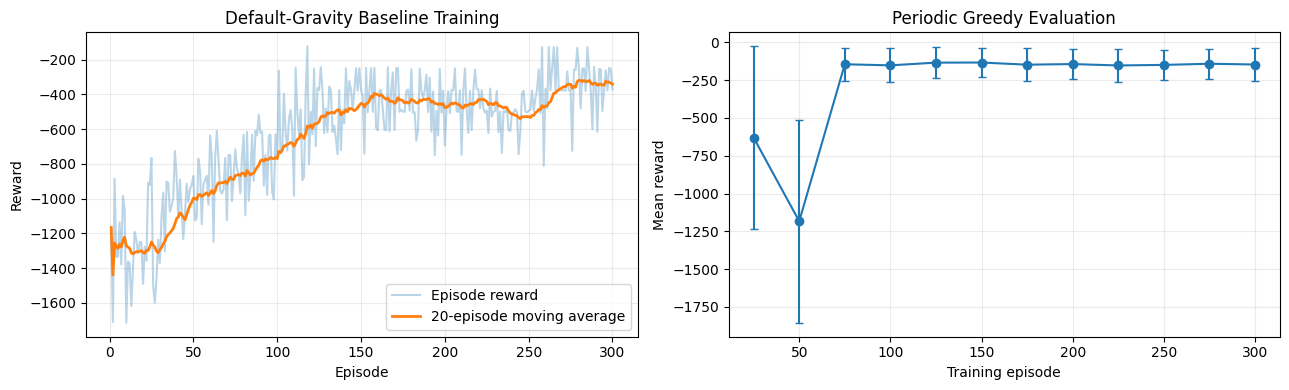

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    baseline_dataframe["episode"],
    baseline_dataframe["episode_reward"],
    alpha=0.30,
    label="Episode reward",
)
axes[0].plot(
    baseline_dataframe["episode"],
    baseline_dataframe["moving_average_reward"],
    linewidth=2,
    label="20-episode moving average",
)
axes[0].set_title("Default-Gravity Baseline Training")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Reward")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].errorbar(
    baseline_history["evaluation_episode"],
    baseline_history["evaluation_mean_reward"],
    yerr=baseline_history["evaluation_reward_std"],
    marker="o",
    capsize=3,
)
axes[1].set_title("Periodic Greedy Evaluation")
axes[1].set_xlabel("Training episode")
axes[1].set_ylabel("Mean reward")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "default_baseline_learning_curves.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()


The moving-average curve describes the exploring training policy, while the periodic greedy-validation curve determines the saved checkpoint. Every checkpoint is evaluated on the same initial-state seeds, so differences along the validation curve reflect changes in the learned policy rather than changes in evaluation difficulty. The separate comparison below reloads the saved weights and uses a different fixed seed range.

## 5.2 Reloaded Baseline Comparison

The best periodically saved weights are loaded into a fresh agent. The comparison uses 20 fixed reset seeds beginning at `20_000`, which are different from the validation seeds used for checkpoint selection. Exploration, replay insertion and network updates remain disabled.

In [82]:
baseline_comparison_env = create_pendulum_env(
    gravity=GRAVITY_SETUPS["setup_1_default"],
    seed=BASELINE_COMPARISON_SEED,
)

baseline_evaluation_agent = DQNAgent(
    state_size=STATE_SIZE,
    action_values=DISCRETE_ACTIONS,
    config=BASELINE_CONFIG,
)

baseline_evaluation_agent.load_weights(
    BASELINE_WEIGHTS_PATH
)

baseline_final_evaluation = evaluate_agent(
    env=baseline_comparison_env,
    agent=baseline_evaluation_agent,
    episodes=BASELINE_EVALUATION_EPISODES,
    max_steps=MAX_STEPS_PER_EPISODE,
    seed=BASELINE_COMPARISON_SEED,
    best_score=None,
    save_path=None,
    verbose=True,
)

best_baseline_position = int(
    np.argmax(
        baseline_history["evaluation_mean_reward"]
    )
)

baseline_summary_dataframe = pd.DataFrame([{
    "training_seed": BASELINE_TRAINING_SEED,
    "action_count": len(DISCRETE_ACTIONS),
    "best_checkpoint_episode": (
        baseline_history["evaluation_episode"][
            best_baseline_position
        ]
    ),
    "best_validation_mean_reward": (
        baseline_history["evaluation_mean_reward"][
            best_baseline_position
        ]
    ),
    "comparison_mean_reward": (
        baseline_final_evaluation["mean_reward"]
    ),
    "comparison_reward_std": (
        baseline_final_evaluation["reward_std"]
    ),
    "comparison_minimum_reward": (
        baseline_final_evaluation["minimum_reward"]
    ),
    "comparison_maximum_reward": (
        baseline_final_evaluation["maximum_reward"]
    ),
    "reached_upright_rate": (
        baseline_final_evaluation["reached_upright_rate"]
    ),
    "balance_success_rate": (
        baseline_final_evaluation["balance_success_rate"]
    ),
    "mean_upright_steps": (
        baseline_final_evaluation["mean_upright_steps"]
    ),
    "mean_longest_balance_streak": (
        baseline_final_evaluation[
            "mean_longest_balance_streak"
        ]
    ),
}])

baseline_evaluation_dataframe = pd.DataFrame(
    baseline_final_evaluation["episode_metrics"]
)

baseline_summary_dataframe.to_csv(
    RESULTS_DIR / "default_baseline_summary.csv",
    index=False,
)

baseline_evaluation_dataframe.to_csv(
    RESULTS_DIR / "default_baseline_evaluation.csv",
    index=False,
)

display(
    baseline_summary_dataframe.round(2)
)

training_env.close()
validation_env.close()
baseline_comparison_env.close()


Mean reward: -144.68
Reward standard deviation: 73.29
Minimum reward: -250.74
Maximum reward: -0.56
Reached upright: 100.0%
Stable-balance success rate: 100.0%
Mean longest stable streak: 167.25 steps


,training_seed,action_count,best_checkpoint_episode,best_validation_mean_reward,comparison_mean_reward,comparison_reward_std,comparison_minimum_reward,comparison_maximum_reward,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,42,9,125,-135.05,-144.68,73.29,-250.74,-0.56,1.0,1.0,171.45,167.25


# 6. Experiment 1: Number of Discrete Actions

The action-count experiment compares `5`, `9`, `11`, `21` and `41` equally spaced actions. Nine actions are included as the baseline control. Every tested count is odd, so each mapping contains `-2.0`, `0.0` and `2.0`.

Too few actions may prevent precise corrections near upright. Too many actions enlarge the output layer and spread exploration across more alternative which may slow value learning. To limit the computational cost, every action count is trained once using the same seed `123`. Validation and comparison episodes are also identical across configurations. This is a controlled single-seed comparison, so the result does not measure variation between independent training runs.


In [83]:
ACTION_COUNTS = [5, 9, 11, 21, 41]
ACTION_TRAINING_SEEDS = [123]

ACTION_TRAINING_EPISODES = 300
ACTION_EVALUATION_EVERY = 25
ACTION_VALIDATION_EPISODES = 20
ACTION_COMPARISON_EPISODES = 20

ACTION_VALIDATION_SEED = 30_000
ACTION_COMPARISON_SEED = 40_000

ACTION_EXPERIMENT_WEIGHTS_DIR = (
    WEIGHTS_DIR / "action_count_experiment"
)
ACTION_EXPERIMENT_RESULTS_DIR = (
    RESULTS_DIR / "action_count_experiment"
)

ACTION_EXPERIMENT_WEIGHTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)
ACTION_EXPERIMENT_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Action counts:", ACTION_COUNTS)
print("Training seed:", ACTION_TRAINING_SEEDS[0])
print("Total training runs:", len(ACTION_COUNTS))


Action counts: [5, 9, 11, 21, 41]
Training seed: 123
Total training runs: 5


## 6.1 Single-Seed Training and Greedy Comparison

For each action count:

1. a fresh environment, replay buffer and DQN are created;
2. the agent trains for 300 episodes using seed `123`;
3. greedy validation on the same 20 reset seeds saves the best checkpoint;
4. a new DQN object reloads that checkpoint; and
5. the reloaded model is compared on 20 different fixed reset seeds.

The comparison seed range is shared across all configurations to support paired episode comparisons. It is used for choosing the action count, so it is not reused as the final unseen balance-assessment range.


In [25]:
action_experiment_records = []
action_training_frames = []
action_validation_frames = []

for action_count in ACTION_COUNTS:
    action_values = np.linspace(
        -2.0,
        2.0,
        action_count,
        dtype=np.float32,
    )

    for training_seed in ACTION_TRAINING_SEEDS:
        print("\n" + "=" * 70)
        print(
            f"ACTION COUNT {action_count} | "
            f"TRAINING SEED {training_seed}"
        )
        print("=" * 70)

        tf.keras.backend.clear_session()
        set_global_seed(training_seed)

        action_training_env = None
        action_validation_env = None
        action_comparison_env = None
        action_agent = None
        action_evaluation_agent = None

        try:
            action_training_env = create_pendulum_env(
                gravity=GRAVITY_SETUPS[
                    "setup_1_default"
                ],
                seed=training_seed,
            )

            action_validation_env = create_pendulum_env(
                gravity=GRAVITY_SETUPS[
                    "setup_1_default"
                ],
                seed=ACTION_VALIDATION_SEED,
            )

            action_comparison_env = create_pendulum_env(
                gravity=GRAVITY_SETUPS[
                    "setup_1_default"
                ],
                seed=ACTION_COMPARISON_SEED,
            )

            action_agent = DQNAgent(
                state_size=STATE_SIZE,
                action_values=action_values,
                config=BASELINE_CONFIG,
            )

            action_weights_path = (
                ACTION_EXPERIMENT_WEIGHTS_DIR
                / (
                    f"actions_{action_count:02d}_"
                    f"seed_{training_seed}.weights.h5"
                )
            )

            (
                action_history,
                action_training_dataframe,
            ) = train_agent(
                env=action_training_env,
                agent=action_agent,
                episodes=ACTION_TRAINING_EPISODES,
                max_steps=MAX_STEPS_PER_EPISODE,
                moving_average_window=20,
                seed=training_seed,
                evaluation_env=action_validation_env,
                evaluation_every=ACTION_EVALUATION_EVERY,
                evaluation_episodes=(
                    ACTION_VALIDATION_EPISODES
                ),
                evaluation_seed=ACTION_VALIDATION_SEED,
                best_weights_path=action_weights_path,
                print_every=25,
                render_every=None,
            )

            action_training_dataframe.insert(
                0,
                "training_seed",
                training_seed,
            )
            action_training_dataframe.insert(
                0,
                "action_count",
                action_count,
            )

            action_training_frames.append(
                action_training_dataframe
            )

            action_training_dataframe.to_csv(
                ACTION_EXPERIMENT_RESULTS_DIR
                / (
                    f"training_actions_{action_count:02d}_"
                    f"seed_{training_seed}.csv"
                ),
                index=False,
            )

            action_validation_dataframe = pd.DataFrame({
                "action_count": action_count,
                "training_seed": training_seed,
                "training_episode": action_history[
                    "evaluation_episode"
                ],
                "validation_mean_reward": action_history[
                    "evaluation_mean_reward"
                ],
                "validation_reward_std": action_history[
                    "evaluation_reward_std"
                ],
            })

            action_validation_frames.append(
                action_validation_dataframe
            )

            best_validation_position = int(
                np.argmax(
                    action_history[
                        "evaluation_mean_reward"
                    ]
                )
            )

            action_evaluation_agent = DQNAgent(
                state_size=STATE_SIZE,
                action_values=action_values,
                config=BASELINE_CONFIG,
            )

            action_evaluation_agent.load_weights(
                action_weights_path
            )

            action_comparison_result = evaluate_agent(
                env=action_comparison_env,
                agent=action_evaluation_agent,
                episodes=ACTION_COMPARISON_EPISODES,
                max_steps=MAX_STEPS_PER_EPISODE,
                seed=ACTION_COMPARISON_SEED,
                best_score=None,
                save_path=None,
                verbose=False,
            )

            action_experiment_records.append({
                "action_count": action_count,
                "training_seed": training_seed,
                "torque_gap": float(
                    action_values[1] - action_values[0]
                ),
                "best_checkpoint_episode": (
                    action_history["evaluation_episode"][
                        best_validation_position
                    ]
                ),
                "best_validation_mean_reward": (
                    action_history[
                        "evaluation_mean_reward"
                    ][best_validation_position]
                ),
                "best_validation_reward_std": (
                    action_history[
                        "evaluation_reward_std"
                    ][best_validation_position]
                ),
                "comparison_mean_reward": (
                    action_comparison_result[
                        "mean_reward"
                    ]
                ),
                "comparison_reward_std": (
                    action_comparison_result[
                        "reward_std"
                    ]
                ),
                "comparison_minimum_reward": (
                    action_comparison_result[
                        "minimum_reward"
                    ]
                ),
                "comparison_maximum_reward": (
                    action_comparison_result[
                        "maximum_reward"
                    ]
                ),
                "reached_upright_rate": (
                    action_comparison_result[
                        "reached_upright_rate"
                    ]
                ),
                "balance_success_rate": (
                    action_comparison_result[
                        "balance_success_rate"
                    ]
                ),
            })

            print(
                f"Comparison mean reward: "
                f"{action_comparison_result['mean_reward']:.2f} "
                f"± "
                f"{action_comparison_result['reward_std']:.2f}"
            )

        finally:
            if action_training_env is not None:
                action_training_env.close()
            if action_validation_env is not None:
                action_validation_env.close()
            if action_comparison_env is not None:
                action_comparison_env.close()

            action_agent = None
            action_evaluation_agent = None
            tf.keras.backend.clear_session()
            gc.collect()

action_experiment_dataframe = pd.DataFrame(
    action_experiment_records
)

action_training_all_dataframe = pd.concat(
    action_training_frames,
    ignore_index=True,
)

action_validation_all_dataframe = pd.concat(
    action_validation_frames,
    ignore_index=True,
)

action_experiment_dataframe.to_csv(
    RESULTS_DIR / "action_count_seed_results.csv",
    index=False,
)

action_training_all_dataframe.to_csv(
    RESULTS_DIR / "action_count_training_all.csv",
    index=False,
)

action_validation_all_dataframe.to_csv(
    RESULTS_DIR / "action_count_validation_all.csv",
    index=False,
)

display(
    action_experiment_dataframe.round(2)
)



ACTION COUNT 5 | TRAINING SEED 123
Episode    1/300 | Reward: -1102.04 | Moving average: -1102.04 | Epsilon: 0.9950 | Loss: not training yet | Replay size: 200
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\action_count_experiment\actions_05_seed_123.weights.h5
Evaluation at episode 25: mean reward = -196.79, std = 141.77
New best weights saved.
Episode   25/300 | Reward: -1177.10 | Moving average: -1138.30 | Epsilon: 0.8822 | Loss: 0.9420 | Replay size: 5000
Evaluation at episode 50: mean reward = -197.77, std = 132.93
Episode   50/300 | Reward:  -870.93 | Moving average: -1043.28 | Epsilon: 0.7783 | Loss: 1.8911 | Replay size: 10000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\action_count_experiment\actions_05_seed_123.weights.h5
Evaluation at episode 75: mean reward = -150.40, std = 88.97
New best weights saved.
Episode   75/300 | Reward:  -612.04 | Moving average:  -800.21 | Epsilon: 0.6866 | Loss: 2.5684 | Replay size: 15000
Evaluation at episode 100: mea

,action_count,training_seed,torque_gap,best_checkpoint_episode,best_validation_mean_reward,best_validation_reward_std,comparison_mean_reward,comparison_reward_std,comparison_minimum_reward,comparison_maximum_reward,reached_upright_rate,balance_success_rate
0,5,123,1.0,275,-146.60,78.04,-176.12,78.48,-317.99,-2.05,1.0,1.0
1,9,123,0.5,125,-149.99,86.76,-174.37,77.88,-306.34,-1.39,1.0,1.0
2,11,123,0.4,250,-147.75,82.45,-175.27,77.75,-307.81,-1.80,1.0,1.0
3,21,123,0.2,150,-150.74,88.61,-173.80,77.22,-311.69,-2.16,1.0,1.0
4,41,123,0.1,100,-151.21,91.06,-176.18,80.93,-313.45,-0.69,1.0,1.0


## 6.3 Results and Selection

Each configuration has one trained model. The episode standard deviation describes variation across the 20 fixed comparison episodes; it does not describe retraining variability. The paired difference subtracts the nine-action reward from another action count on the same trained-seed comparison. A positive value means the tested action count achieved a better mean reward than the nine-action control.


In [26]:
action_summary_dataframe = (
    action_experiment_dataframe
    .copy()
    .sort_values(
        [
            "comparison_mean_reward",
            "comparison_reward_std",
        ],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

nine_action_mean = float(
    action_summary_dataframe.loc[
        action_summary_dataframe["action_count"] == 9,
        "comparison_mean_reward",
    ].iloc[0]
)

action_summary_dataframe[
    "mean_difference_vs_9_actions"
] = (
    action_summary_dataframe["comparison_mean_reward"]
    - nine_action_mean
)

action_summary_dataframe.insert(
    0,
    "rank",
    np.arange(
        1,
        len(action_summary_dataframe) + 1,
    ),
)

selected_action_count = int(
    action_summary_dataframe.iloc[0]["action_count"]
)

paired_reward_table = (
    action_experiment_dataframe
    .set_index("action_count")[
        ["comparison_mean_reward"]
    ]
    .rename(
        columns={
            "comparison_mean_reward": (
                "single_seed_mean_reward"
            )
        }
    )
    .sort_index()
)
paired_reward_table[
    "difference_vs_9_actions"
] = (
    paired_reward_table["single_seed_mean_reward"]
    - nine_action_mean
)

action_summary_dataframe.to_csv(
    RESULTS_DIR / "action_count_summary.csv",
    index=False,
)
paired_reward_table.to_csv(
    RESULTS_DIR
    / "action_count_paired_differences.csv"
)

print(
    "Selected action count:",
    selected_action_count,
)
display(action_summary_dataframe.round(3))
display(paired_reward_table.round(3))


Selected action count: 21


,rank,action_count,training_seed,torque_gap,best_checkpoint_episode,best_validation_mean_reward,best_validation_reward_std,comparison_mean_reward,comparison_reward_std,comparison_minimum_reward,comparison_maximum_reward,reached_upright_rate,balance_success_rate,mean_difference_vs_9_actions
0,1,21,123,0.2,150,-150.743,88.607,-173.800,77.217,-311.689,-2.156,1.0,1.0,0.571
1,2,9,123,0.5,125,-149.992,86.758,-174.371,77.877,-306.339,-1.394,1.0,1.0,0.000
2,3,11,123,0.4,250,-147.749,82.446,-175.269,77.754,-307.814,-1.803,1.0,1.0,-0.898
3,4,5,123,1.0,275,-146.601,78.043,-176.122,78.482,-317.993,-2.053,1.0,1.0,-1.752
4,5,41,123,0.1,100,-151.212,91.055,-176.184,80.928,-313.452,-0.686,1.0,1.0,-1.813


,single_seed_mean_reward,difference_vs_9_actions
action_count,,
5,-176.122,-1.752
9,-174.371,0.000
11,-175.269,-0.898
21,-173.800,0.571
41,-176.184,-1.813


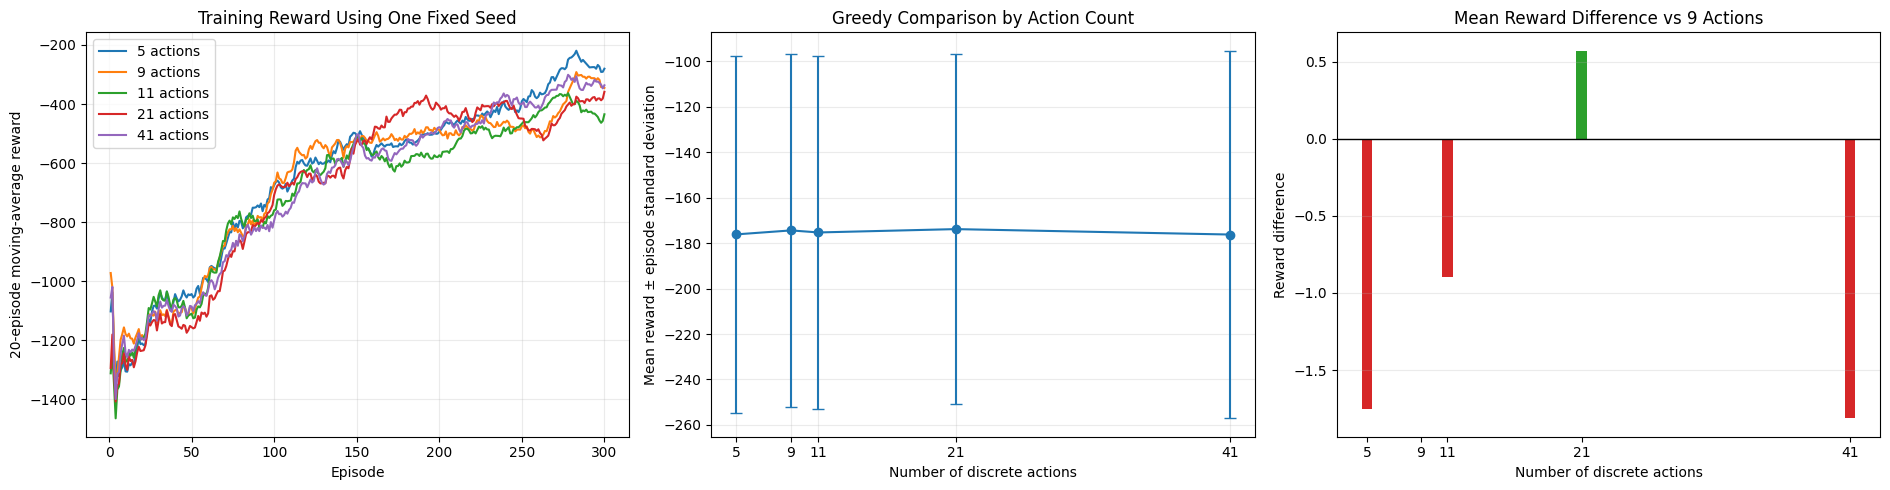

In [27]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(19, 5),
)

# Training curves from the one fixed training seed
for action_count in ACTION_COUNTS:
    action_curve = (
        action_training_all_dataframe[
            action_training_all_dataframe[
                "action_count"
            ] == action_count
        ]
        .sort_values("episode")
    )

    axes[0].plot(
        action_curve["episode"],
        action_curve["moving_average_reward"],
        label=f"{action_count} actions",
    )

axes[0].set_title(
    "Training Reward Using One Fixed Seed"
)
axes[0].set_xlabel("Episode")
axes[0].set_ylabel(
    "20-episode moving-average reward"
)
axes[0].grid(alpha=0.25)
axes[0].legend()

# Mean and episode-level variability
plot_summary = (
    action_summary_dataframe
    .sort_values("action_count")
)

axes[1].errorbar(
    plot_summary["action_count"],
    plot_summary["comparison_mean_reward"],
    yerr=plot_summary["comparison_reward_std"],
    marker="o",
    capsize=4,
)

axes[1].set_title(
    "Greedy Comparison by Action Count"
)
axes[1].set_xlabel(
    "Number of discrete actions"
)
axes[1].set_ylabel(
    "Mean reward ± episode standard deviation"
)
axes[1].set_xticks(ACTION_COUNTS)
axes[1].grid(alpha=0.25)

# Difference against the nine-action control
difference_plot = (
    paired_reward_table.reset_index()
)

axes[2].bar(
    difference_plot["action_count"],
    difference_plot["difference_vs_9_actions"],
    color=[
        (
            "tab:green"
            if value > 0
            else "tab:red"
            if value < 0
            else "tab:blue"
        )
        for value in difference_plot[
            "difference_vs_9_actions"
        ]
    ],
)
axes[2].axhline(
    0.0,
    color="black",
    linewidth=1,
)
axes[2].set_title(
    "Mean Reward Difference vs 9 Actions"
)
axes[2].set_xlabel(
    "Number of discrete actions"
)
axes[2].set_ylabel("Reward difference")
axes[2].set_xticks(ACTION_COUNTS)
axes[2].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "action_count_experiment.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()


Experiment 2 compared action spaces containing 5, 9, 11, 21 and 41 discrete torque values using one fixed training seed. All configurations achieved a 100% upright and balance-success rate during the fixed greedy comparison episodes. The 21-action configuration achieved the highest observed mean reward of −173.800, exceeding the 9-action baseline by 0.571 reward points. However, this difference was small relative to the episode-level reward variability. Furthermore, increasing the action count to 41 reduced performance, indicating that a finer action space does not automatically produce better results. Therefore, 21 actions were selected as the best observed configuration for subsequent experiments, although the single-seed design means this should not be interpreted as proof that 21 actions are universally optimal.

# 7. Experiment 2: Exploration and Epsilon Strategy

Experiment 2 investigates how the epsilon-greedy exploration strategy affects DQN performance. The action count selected in Experiment 1 is fixed, while all other settings—including the network architecture, learning rate, batch size, discount factor, replay-buffer settings, target-network update frequency, and 300-episode training budget—remain unchanged.

The constant strategy begins with limited exploration, while the decaying strategies begin with complete exploration and gradually rely more heavily on the learned policy. Decaying too quickly may cause the agent to exploit inaccurate early Q-values, whereas decaying too slowly may continue introducing unnecessary random actions after a useful policy has been learned.

Each strategy is trained once using seed `123`. Greedy validation is performed every 25 episodes with exploration disabled, and the best checkpoint is saved. The primary selection measure is the mean greedy comparison reward on the same fixed episodes. Training reward alone is not used for selection because it includes exploratory actions.


## 7.1 Experiment Setup

The selected action count is carried forward. Only the epsilon schedule changes.

In [28]:
# Winner selected in Experiment 1
SELECTED_ACTION_COUNT = 21

EPSILON_ACTION_VALUES = np.linspace(
    -2.0,
    2.0,
    SELECTED_ACTION_COUNT,
    dtype=np.float32,
)


# One fixed seed to reduce training time
EPSILON_TRAINING_SEED = 123

EPSILON_TRAINING_EPISODES = 300
EPSILON_EVALUATION_EVERY = 25
EPSILON_VALIDATION_EPISODES = 20
EPSILON_COMPARISON_EPISODES = 20

# Same validation episodes used in Experiment 1
EPSILON_VALIDATION_SEED = ACTION_VALIDATION_SEED

# New comparison episodes for Experiment 2
EPSILON_COMPARISON_SEED = 50_000


EPSILON_STRATEGIES = {
    "constant_0_100": {
        "label": "Constant 0.100",
        "epsilon_start": 0.100,
        "epsilon_decay": 1.000,
        "epsilon_minimum": 0.100,
    },
    "fast_decay_0_990": {
        "label": "Fast decay 0.990",
        "epsilon_start": 1.000,
        "epsilon_decay": 0.990,
        "epsilon_minimum": 0.050,
    },
    "baseline_decay_0_995": {
        "label": "Baseline decay 0.995",
        "epsilon_start": 1.000,
        "epsilon_decay": 0.995,
        "epsilon_minimum": 0.050,
    },
    "slow_decay_0_997": {
        "label": "Slow decay 0.997",
        "epsilon_start": 1.000,
        "epsilon_decay": 0.997,
        "epsilon_minimum": 0.050,
    },
}


EPSILON_CONFIGS = {
    strategy_id: replace(
        BASELINE_CONFIG,
        epsilon_start=settings["epsilon_start"],
        epsilon_decay=settings["epsilon_decay"],
        epsilon_minimum=settings["epsilon_minimum"],
    )
    for strategy_id, settings in EPSILON_STRATEGIES.items()
}


# The 0.995 model is reused from Experiment 1.
# Only these three strategies need new training.
EPSILON_TRAINING_STRATEGY_IDS = [
    "constant_0_100",
    "fast_decay_0_990",
    "slow_decay_0_997",
]


EPSILON_EXPERIMENT_WEIGHTS_DIR = (
    WEIGHTS_DIR / "epsilon_experiment"
)

EPSILON_EXPERIMENT_RESULTS_DIR = (
    RESULTS_DIR / "epsilon_experiment"
)

EPSILON_EXPERIMENT_WEIGHTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

EPSILON_EXPERIMENT_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# Existing Experiment 1 control checkpoint
EPSILON_CONTROL_WEIGHTS_PATH = (
    ACTION_EXPERIMENT_WEIGHTS_DIR
    / (
        f"actions_{SELECTED_ACTION_COUNT:02d}_"
        f"seed_{EPSILON_TRAINING_SEED}.weights.h5"
    )
)

if not EPSILON_CONTROL_WEIGHTS_PATH.exists():
    raise FileNotFoundError(
        "The 9-action seed-123 checkpoint from "
        "Experiment 1 was not found:\n"
        f"{EPSILON_CONTROL_WEIGHTS_PATH.resolve()}"
    )


def get_epsilon_run_paths(strategy_id):
    return {
        "weights": (
            EPSILON_EXPERIMENT_WEIGHTS_DIR
            / (
                f"{strategy_id}_seed_"
                f"{EPSILON_TRAINING_SEED}.weights.h5"
            )
        ),
        "training": (
            EPSILON_EXPERIMENT_RESULTS_DIR
            / (
                f"training_{strategy_id}_seed_"
                f"{EPSILON_TRAINING_SEED}.csv"
            )
        ),
        "validation": (
            EPSILON_EXPERIMENT_RESULTS_DIR
            / (
                f"validation_{strategy_id}_seed_"
                f"{EPSILON_TRAINING_SEED}.csv"
            )
        ),
        "checkpoint": (
            EPSILON_EXPERIMENT_RESULTS_DIR
            / (
                f"checkpoint_{strategy_id}_seed_"
                f"{EPSILON_TRAINING_SEED}.csv"
            )
        ),
    }


epsilon_schedule_records = []

for strategy_id, settings in EPSILON_STRATEGIES.items():
    epsilon_after_training = max(
        settings["epsilon_minimum"],
        settings["epsilon_start"]
        * settings["epsilon_decay"]
        ** EPSILON_TRAINING_EPISODES,
    )

    epsilon_schedule_records.append({
        "strategy_id": strategy_id,
        "strategy": settings["label"],
        "initial_epsilon": settings["epsilon_start"],
        "decay": settings["epsilon_decay"],
        "minimum_epsilon": settings["epsilon_minimum"],
        "epsilon_after_300_episodes": (
            epsilon_after_training
        ),
    })


epsilon_schedule_dataframe = pd.DataFrame(
    epsilon_schedule_records
)

display(
    epsilon_schedule_dataframe.round(4)
)

print(
    "New training runs required:",
    len(EPSILON_TRAINING_STRATEGY_IDS),
)


,strategy_id,strategy,initial_epsilon,decay,minimum_epsilon,epsilon_after_300_episodes
0,constant_0_100,Constant 0.100,0.1,1.000,0.10,0.1000
1,fast_decay_0_990,Fast decay 0.990,1.0,0.990,0.05,0.0500
2,baseline_decay_0_995,Baseline decay 0.995,1.0,0.995,0.05,0.2223
3,slow_decay_0_997,Slow decay 0.997,1.0,0.997,0.05,0.4060


New training runs required: 3


## 7.2 Training

The baseline-decay control is reused from Experiment 1; the remaining strategies are trained with the same seed and validation episodes.

In [34]:
for strategy_id in EPSILON_TRAINING_STRATEGY_IDS:

    settings = EPSILON_STRATEGIES[strategy_id]
    strategy_config = EPSILON_CONFIGS[strategy_id]
    run_paths = get_epsilon_run_paths(strategy_id)

    # Do not repeat a completed run.
    run_is_complete = all(
        path.exists()
        for path in run_paths.values()
    )

    if run_is_complete:
        print(
            f"Skipping {settings['label']}: "
            "saved results already exist."
        )
        continue

    print("\n" + "=" * 70)
    print(
        f"EPSILON STRATEGY: {settings['label']} | "
        f"TRAINING SEED: {EPSILON_TRAINING_SEED}"
    )
    print("=" * 70)

    tf.keras.backend.clear_session()
    set_global_seed(EPSILON_TRAINING_SEED)

    epsilon_training_env = None
    epsilon_validation_env = None
    epsilon_agent = None

    try:
        epsilon_training_env = create_pendulum_env(
            gravity=GRAVITY_SETUPS[
                "setup_1_default"
            ],
            seed=EPSILON_TRAINING_SEED,
        )

        epsilon_validation_env = create_pendulum_env(
            gravity=GRAVITY_SETUPS[
                "setup_1_default"
            ],
            seed=EPSILON_VALIDATION_SEED,
        )

        epsilon_agent = DQNAgent(
            state_size=STATE_SIZE,
            action_values=EPSILON_ACTION_VALUES,
            config=strategy_config,
        )

        (
            epsilon_history,
            epsilon_training_dataframe,
        ) = train_agent(
            env=epsilon_training_env,
            agent=epsilon_agent,
            episodes=EPSILON_TRAINING_EPISODES,
            max_steps=MAX_STEPS_PER_EPISODE,
            moving_average_window=20,
            seed=EPSILON_TRAINING_SEED,
            evaluation_env=epsilon_validation_env,
            evaluation_every=EPSILON_EVALUATION_EVERY,
            evaluation_episodes=(
                EPSILON_VALIDATION_EPISODES
            ),
            evaluation_seed=EPSILON_VALIDATION_SEED,
            best_weights_path=run_paths["weights"],
            print_every=25,
            render_every=None,
        )

        # Save training history
        epsilon_training_dataframe.insert(
            0,
            "training_seed",
            EPSILON_TRAINING_SEED,
        )

        epsilon_training_dataframe.insert(
            0,
            "action_count",
            SELECTED_ACTION_COUNT,
        )

        epsilon_training_dataframe.insert(
            0,
            "strategy",
            settings["label"],
        )

        epsilon_training_dataframe.insert(
            0,
            "strategy_id",
            strategy_id,
        )

        epsilon_training_dataframe.to_csv(
            run_paths["training"],
            index=False,
        )

        # Save periodic greedy validation history
        epsilon_validation_dataframe = pd.DataFrame({
            "strategy_id": strategy_id,
            "strategy": settings["label"],
            "action_count": SELECTED_ACTION_COUNT,
            "training_seed": EPSILON_TRAINING_SEED,
            "training_episode": epsilon_history[
                "evaluation_episode"
            ],
            "validation_mean_reward": epsilon_history[
                "evaluation_mean_reward"
            ],
            "validation_reward_std": epsilon_history[
                "evaluation_reward_std"
            ],
        })

        epsilon_validation_dataframe.to_csv(
            run_paths["validation"],
            index=False,
        )

        best_validation_position = int(
            np.argmax(
                epsilon_history[
                    "evaluation_mean_reward"
                ]
            )
        )

        epsilon_checkpoint_dataframe = pd.DataFrame([{
            "strategy_id": strategy_id,
            "strategy": settings["label"],
            "action_count": SELECTED_ACTION_COUNT,
            "training_seed": EPSILON_TRAINING_SEED,
            "best_checkpoint_episode": (
                epsilon_history[
                    "evaluation_episode"
                ][best_validation_position]
            ),
            "best_validation_mean_reward": (
                epsilon_history[
                    "evaluation_mean_reward"
                ][best_validation_position]
            ),
            "best_validation_reward_std": (
                epsilon_history[
                    "evaluation_reward_std"
                ][best_validation_position]
            ),
            "final_training_epsilon": (
                epsilon_agent.epsilon
            ),
        }])

        epsilon_checkpoint_dataframe.to_csv(
            run_paths["checkpoint"],
            index=False,
        )

        print(
            f"Completed: {settings['label']}"
        )

    finally:
        if epsilon_training_env is not None:
            epsilon_training_env.close()

        if epsilon_validation_env is not None:
            epsilon_validation_env.close()

        epsilon_agent = None

        tf.keras.backend.clear_session()
        gc.collect()



EPSILON STRATEGY: Constant 0.100 | TRAINING SEED: 123
Episode    1/300 | Reward: -1490.94 | Moving average: -1490.94 | Epsilon: 0.1000 | Loss: not training yet | Replay size: 200
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\epsilon_experiment\constant_0_100_seed_123.weights.h5
Evaluation at episode 25: mean reward = -477.45, std = 394.07
New best weights saved.
Episode   25/300 | Reward:  -867.19 | Moving average:  -965.19 | Epsilon: 0.1000 | Loss: 0.8231 | Replay size: 5000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\epsilon_experiment\constant_0_100_seed_123.weights.h5
Evaluation at episode 50: mean reward = -192.09, std = 96.73
New best weights saved.
Episode   50/300 | Reward:  -120.48 | Moving average:  -444.34 | Epsilon: 0.1000 | Loss: 1.5011 | Replay size: 10000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\epsilon_experiment\constant_0_100_seed_123.weights.h5
Evaluation at episode 75: mean reward = -191.85, std = 114.16
New best weights s

## 7.3 Greedy Comparison and Selection

Saved checkpoints are reloaded and evaluated on the same fixed comparison episodes.

In [37]:
# ---------------------------------------------------------
# Load the reused 0.995 control from Experiment 1
# ---------------------------------------------------------

control_training_path = (
    ACTION_EXPERIMENT_RESULTS_DIR
    / (
        f"training_actions_"
        f"{SELECTED_ACTION_COUNT:02d}_"
        f"seed_{EPSILON_TRAINING_SEED}.csv"
    )
)

control_validation_path = (
    RESULTS_DIR
    / "action_count_validation_all.csv"
)

control_summary_path = (
    RESULTS_DIR
    / "action_count_seed_results.csv"
)


for required_path in [
    control_training_path,
    control_validation_path,
    control_summary_path,
]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required Experiment 1 result not found: "
            f"{required_path.resolve()}"
        )


control_training_dataframe = pd.read_csv(
    control_training_path
)

control_training_dataframe.insert(
    0,
    "strategy",
    EPSILON_STRATEGIES[
        "baseline_decay_0_995"
    ]["label"],
)

control_training_dataframe.insert(
    0,
    "strategy_id",
    "baseline_decay_0_995",
)


all_action_validation_dataframe = pd.read_csv(
    control_validation_path
)

control_validation_dataframe = (
    all_action_validation_dataframe[
        (
            all_action_validation_dataframe[
                "action_count"
            ] == SELECTED_ACTION_COUNT
        )
        & (
            all_action_validation_dataframe[
                "training_seed"
            ] == EPSILON_TRAINING_SEED
        )
    ]
    .copy()
)

control_validation_dataframe.insert(
    0,
    "strategy",
    EPSILON_STRATEGIES[
        "baseline_decay_0_995"
    ]["label"],
)

control_validation_dataframe.insert(
    0,
    "strategy_id",
    "baseline_decay_0_995",
)


action_seed_results_dataframe = pd.read_csv(
    control_summary_path
)

control_checkpoint_row = (
    action_seed_results_dataframe[
        (
            action_seed_results_dataframe[
                "action_count"
            ] == SELECTED_ACTION_COUNT
        )
        & (
            action_seed_results_dataframe[
                "training_seed"
            ] == EPSILON_TRAINING_SEED
        )
    ]
    .iloc[0]
)


# ---------------------------------------------------------
# Load the three newly trained strategies
# ---------------------------------------------------------

epsilon_training_frames = [
    control_training_dataframe
]

epsilon_validation_frames = [
    control_validation_dataframe
]

checkpoint_lookup = {
    "baseline_decay_0_995": {
        "best_checkpoint_episode": int(
            control_checkpoint_row[
                "best_checkpoint_episode"
            ]
        ),
        "best_validation_mean_reward": float(
            control_checkpoint_row[
                "best_validation_mean_reward"
            ]
        ),
        "best_validation_reward_std": float(
            control_checkpoint_row[
                "best_validation_reward_std"
            ]
        ),
    }
}


for strategy_id in EPSILON_TRAINING_STRATEGY_IDS:
    run_paths = get_epsilon_run_paths(strategy_id)

    for path_name, path in run_paths.items():
        if not path.exists():
            raise FileNotFoundError(
                f"Incomplete {strategy_id} run. "
                f"Missing {path_name}: {path.resolve()}"
            )

    strategy_training_dataframe = pd.read_csv(
        run_paths["training"]
    )

    strategy_validation_dataframe = pd.read_csv(
        run_paths["validation"]
    )

    strategy_checkpoint_dataframe = pd.read_csv(
        run_paths["checkpoint"]
    )

    epsilon_training_frames.append(
        strategy_training_dataframe
    )

    epsilon_validation_frames.append(
        strategy_validation_dataframe
    )

    checkpoint_row = (
        strategy_checkpoint_dataframe.iloc[0]
    )

    checkpoint_lookup[strategy_id] = {
        "best_checkpoint_episode": int(
            checkpoint_row[
                "best_checkpoint_episode"
            ]
        ),
        "best_validation_mean_reward": float(
            checkpoint_row[
                "best_validation_mean_reward"
            ]
        ),
        "best_validation_reward_std": float(
            checkpoint_row[
                "best_validation_reward_std"
            ]
        ),
    }


epsilon_training_all_dataframe = pd.concat(
    epsilon_training_frames,
    ignore_index=True,
)

epsilon_validation_all_dataframe = pd.concat(
    epsilon_validation_frames,
    ignore_index=True,
)


# ---------------------------------------------------------
# Greedy comparison on the same new episodes
# ---------------------------------------------------------

epsilon_comparison_records = []
epsilon_episode_records = []


for strategy_id, settings in EPSILON_STRATEGIES.items():

    if strategy_id == "baseline_decay_0_995":
        weights_path = EPSILON_CONTROL_WEIGHTS_PATH
    else:
        weights_path = get_epsilon_run_paths(
            strategy_id
        )["weights"]

    tf.keras.backend.clear_session()
    set_global_seed(EPSILON_TRAINING_SEED)

    epsilon_comparison_env = None
    epsilon_evaluation_agent = None

    try:
        epsilon_comparison_env = create_pendulum_env(
            gravity=GRAVITY_SETUPS[
                "setup_1_default"
            ],
            seed=EPSILON_COMPARISON_SEED,
        )

        epsilon_evaluation_agent = DQNAgent(
            state_size=STATE_SIZE,
            action_values=EPSILON_ACTION_VALUES,
            config=EPSILON_CONFIGS[strategy_id],
        )

        epsilon_evaluation_agent.load_weights(
            weights_path
        )

        comparison_result = evaluate_agent(
            env=epsilon_comparison_env,
            agent=epsilon_evaluation_agent,
            episodes=EPSILON_COMPARISON_EPISODES,
            max_steps=MAX_STEPS_PER_EPISODE,
            seed=EPSILON_COMPARISON_SEED,
            best_score=None,
            save_path=None,
            verbose=False,
        )

        checkpoint_information = (
            checkpoint_lookup[strategy_id]
        )

        epsilon_after_training = max(
            settings["epsilon_minimum"],
            settings["epsilon_start"]
            * settings["epsilon_decay"]
            ** EPSILON_TRAINING_EPISODES,
        )

        epsilon_comparison_records.append({
            "strategy_id": strategy_id,
            "strategy": settings["label"],
            "action_count": SELECTED_ACTION_COUNT,
            "training_seed": EPSILON_TRAINING_SEED,
            "initial_epsilon": (
                settings["epsilon_start"]
            ),
            "epsilon_decay": (
                settings["epsilon_decay"]
            ),
            "minimum_epsilon": (
                settings["epsilon_minimum"]
            ),
            "epsilon_after_training": (
                epsilon_after_training
            ),
            "best_checkpoint_episode": (
                checkpoint_information[
                    "best_checkpoint_episode"
                ]
            ),
            "best_validation_mean_reward": (
                checkpoint_information[
                    "best_validation_mean_reward"
                ]
            ),
            "best_validation_reward_std": (
                checkpoint_information[
                    "best_validation_reward_std"
                ]
            ),
            "comparison_mean_reward": (
                comparison_result["mean_reward"]
            ),
            "comparison_reward_std": (
                comparison_result["reward_std"]
            ),
            "comparison_minimum_reward": (
                comparison_result["minimum_reward"]
            ),
            "comparison_maximum_reward": (
                comparison_result["maximum_reward"]
            ),
            "reached_upright_rate": (
                 comparison_result["reached_upright_rate"]
            ),
            "balance_success_rate": (
            comparison_result["balance_success_rate"]
            ),
           "mean_upright_steps": (
            comparison_result["mean_upright_steps"]
           ),
          "mean_longest_balance_streak": (
           comparison_result[
          "mean_longest_balance_streak"
          ]
         ), 
        })

        for episode_number, reward in enumerate(
            comparison_result["evaluation_rewards"],
            start=1,
        ):
            epsilon_episode_records.append({
                "strategy_id": strategy_id,
                "strategy": settings["label"],
                "evaluation_episode": episode_number,
                "evaluation_seed": (
                    EPSILON_COMPARISON_SEED
                    + episode_number
                    - 1
                ),
                "reward": reward,
            })

        print(
            f"{settings['label']}: "
            f"{comparison_result['mean_reward']:.2f} "
            f"± {comparison_result['reward_std']:.2f}"
        )

    finally:
        if epsilon_comparison_env is not None:
            epsilon_comparison_env.close()

        epsilon_evaluation_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


epsilon_results_dataframe = pd.DataFrame(
    epsilon_comparison_records
).sort_values(
    "comparison_mean_reward",
    ascending=False,
).reset_index(drop=True)

epsilon_results_dataframe.insert(
    0,
    "rank",
    np.arange(
        1,
        len(epsilon_results_dataframe) + 1,
    ),
)

epsilon_episode_dataframe = pd.DataFrame(
    epsilon_episode_records
)


selected_epsilon_strategy_id = (
    epsilon_results_dataframe.iloc[0][
        "strategy_id"
    ]
)

SELECTED_EPSILON_CONFIG = EPSILON_CONFIGS[
    selected_epsilon_strategy_id
]

# Save one standardised set of selected-strategy files so
# Experiment 3 can reuse any possible winner.
if selected_epsilon_strategy_id == "baseline_decay_0_995":
    selected_epsilon_weights_path = (
        EPSILON_CONTROL_WEIGHTS_PATH
    )
else:
    selected_epsilon_weights_path = (
        get_epsilon_run_paths(
            selected_epsilon_strategy_id
        )["weights"]
    )

selected_epsilon_training_dataframe = (
    epsilon_training_all_dataframe[
        epsilon_training_all_dataframe[
            "strategy_id"
        ] == selected_epsilon_strategy_id
    ].copy()
)
selected_epsilon_validation_dataframe = (
    epsilon_validation_all_dataframe[
        epsilon_validation_all_dataframe[
            "strategy_id"
        ] == selected_epsilon_strategy_id
    ].copy()
)
selected_epsilon_checkpoint_dataframe = pd.DataFrame([
    {
        "strategy_id": selected_epsilon_strategy_id,
        "strategy": EPSILON_STRATEGIES[
            selected_epsilon_strategy_id
        ]["label"],
        "training_seed": EPSILON_TRAINING_SEED,
        "best_checkpoint_episode": checkpoint_lookup[
            selected_epsilon_strategy_id
        ]["best_checkpoint_episode"],
        "best_validation_mean_reward": checkpoint_lookup[
            selected_epsilon_strategy_id
        ]["best_validation_mean_reward"],
        "best_validation_reward_std": checkpoint_lookup[
            selected_epsilon_strategy_id
        ]["best_validation_reward_std"],
    }
])

SELECTED_EPSILON_RUN_PATHS = {
    "weights": selected_epsilon_weights_path,
    "training": (
        EPSILON_EXPERIMENT_RESULTS_DIR
        / "selected_epsilon_training.csv"
    ),
    "validation": (
        EPSILON_EXPERIMENT_RESULTS_DIR
        / "selected_epsilon_validation.csv"
    ),
    "checkpoint": (
        EPSILON_EXPERIMENT_RESULTS_DIR
        / "selected_epsilon_checkpoint.csv"
    ),
}

selected_epsilon_training_dataframe.to_csv(
    SELECTED_EPSILON_RUN_PATHS["training"],
    index=False,
)
selected_epsilon_validation_dataframe.to_csv(
    SELECTED_EPSILON_RUN_PATHS["validation"],
    index=False,
)
selected_epsilon_checkpoint_dataframe.to_csv(
    SELECTED_EPSILON_RUN_PATHS["checkpoint"],
    index=False,
)


epsilon_results_dataframe.to_csv(
    RESULTS_DIR / "epsilon_strategy_results.csv",
    index=False,
)

epsilon_episode_dataframe.to_csv(
    RESULTS_DIR / "epsilon_strategy_episode_rewards.csv",
    index=False,
)

epsilon_training_all_dataframe.to_csv(
    RESULTS_DIR / "epsilon_strategy_training_all.csv",
    index=False,
)

epsilon_validation_all_dataframe.to_csv(
    RESULTS_DIR / "epsilon_strategy_validation_all.csv",
    index=False,
)


print(
    "\nSelected epsilon strategy:",
    EPSILON_STRATEGIES[
        selected_epsilon_strategy_id
    ]["label"],
)

display(
    epsilon_results_dataframe.round(3)
)


Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\epsilon_experiment\constant_0_100_seed_123.weights.h5
Constant 0.100: -109.03 ± 79.44
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\epsilon_experiment\fast_decay_0_990_seed_123.weights.h5
Fast decay 0.990: -108.10 ± 79.57
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\action_count_experiment\actions_21_seed_123.weights.h5
Baseline decay 0.995: -108.19 ± 78.37
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\epsilon_experiment\slow_decay_0_997_seed_123.weights.h5
Slow decay 0.997: -109.67 ± 80.79

Selected epsilon strategy: Fast decay 0.990


,rank,strategy_id,strategy,action_count,training_seed,initial_epsilon,epsilon_decay,minimum_epsilon,epsilon_after_training,best_checkpoint_episode,best_validation_mean_reward,best_validation_reward_std,comparison_mean_reward,comparison_reward_std,comparison_minimum_reward,comparison_maximum_reward,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,1,fast_decay_0_990,Fast decay 0.990,21,123,1.0,0.990,0.05,0.050,100,-152.035,89.350,-108.099,79.567,-332.006,-0.289,1.0,1.0,176.80,173.20
1,2,baseline_decay_0_995,Baseline decay 0.995,21,123,1.0,0.995,0.05,0.222,150,-150.743,88.607,-108.193,78.365,-329.466,-1.821,1.0,1.0,176.50,170.25
2,3,constant_0_100,Constant 0.100,21,123,0.1,1.000,0.10,0.100,300,-151.817,88.667,-109.031,79.443,-335.106,-0.870,1.0,1.0,173.05,168.10
3,4,slow_decay_0_997,Slow decay 0.997,21,123,1.0,0.997,0.05,0.406,150,-150.585,85.510,-109.669,80.786,-337.127,-1.665,1.0,1.0,176.10,169.55


## 7.4 Visualisation

The plots compare epsilon schedules, training curves, periodic validation and final greedy reward.

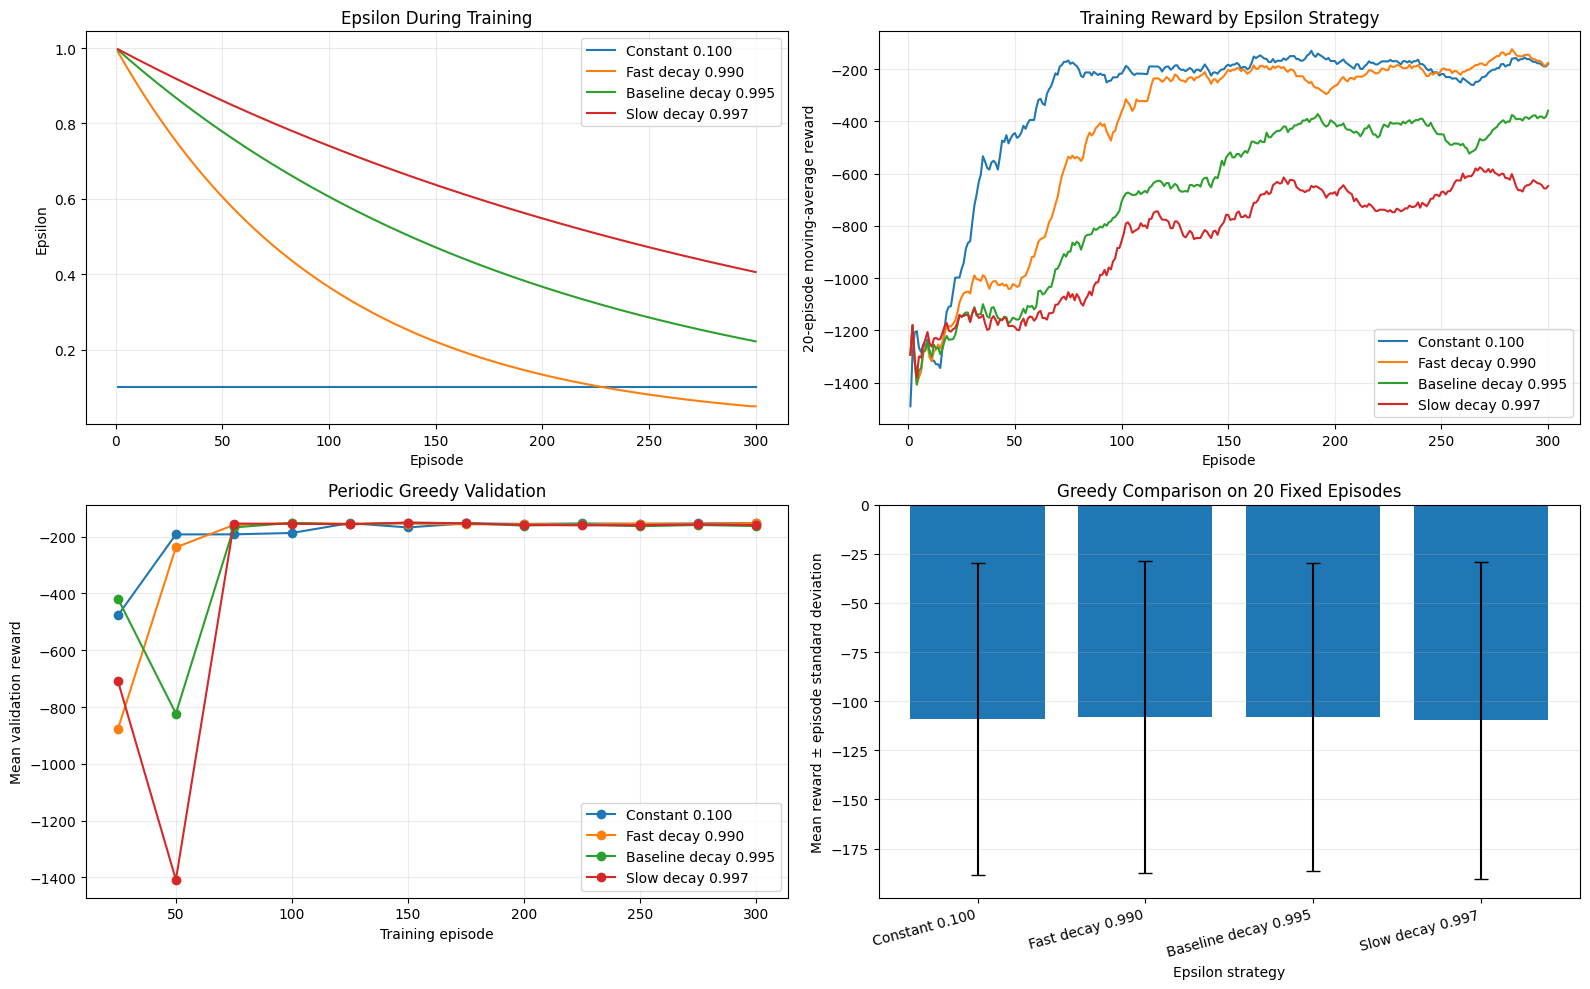

In [36]:
strategy_ids = list(
    EPSILON_STRATEGIES.keys()
)

strategy_labels = [
    EPSILON_STRATEGIES[strategy_id]["label"]
    for strategy_id in strategy_ids
]


fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10),
)


# ---------------------------------------------------------
# Epsilon schedules
# ---------------------------------------------------------

for strategy_id in strategy_ids:
    strategy_training = (
        epsilon_training_all_dataframe[
            epsilon_training_all_dataframe[
                "strategy_id"
            ] == strategy_id
        ]
        .sort_values("episode")
    )

    axes[0, 0].plot(
        strategy_training["episode"],
        strategy_training["epsilon"],
        label=EPSILON_STRATEGIES[
            strategy_id
        ]["label"],
    )

axes[0, 0].set_title(
    "Epsilon During Training"
)
axes[0, 0].set_xlabel("Episode")
axes[0, 0].set_ylabel("Epsilon")
axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend()


# ---------------------------------------------------------
# Exploring training reward
# ---------------------------------------------------------

for strategy_id in strategy_ids:
    strategy_training = (
        epsilon_training_all_dataframe[
            epsilon_training_all_dataframe[
                "strategy_id"
            ] == strategy_id
        ]
        .sort_values("episode")
    )

    axes[0, 1].plot(
        strategy_training["episode"],
        strategy_training[
            "moving_average_reward"
        ],
        label=EPSILON_STRATEGIES[
            strategy_id
        ]["label"],
    )

axes[0, 1].set_title(
    "Training Reward by Epsilon Strategy"
)
axes[0, 1].set_xlabel("Episode")
axes[0, 1].set_ylabel(
    "20-episode moving-average reward"
)
axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend()


# ---------------------------------------------------------
# Periodic greedy validation
# ---------------------------------------------------------

for strategy_id in strategy_ids:
    strategy_validation = (
        epsilon_validation_all_dataframe[
            epsilon_validation_all_dataframe[
                "strategy_id"
            ] == strategy_id
        ]
        .sort_values("training_episode")
    )

    axes[1, 0].plot(
        strategy_validation[
            "training_episode"
        ],
        strategy_validation[
            "validation_mean_reward"
        ],
        marker="o",
        label=EPSILON_STRATEGIES[
            strategy_id
        ]["label"],
    )

axes[1, 0].set_title(
    "Periodic Greedy Validation"
)
axes[1, 0].set_xlabel("Training episode")
axes[1, 0].set_ylabel("Mean validation reward")
axes[1, 0].grid(alpha=0.25)
axes[1, 0].legend()


# ---------------------------------------------------------
# Final greedy comparison
# ---------------------------------------------------------

plot_results = (
    epsilon_results_dataframe
    .set_index("strategy_id")
    .loc[strategy_ids]
    .reset_index()
)

bar_positions = np.arange(
    len(plot_results)
)

axes[1, 1].bar(
    bar_positions,
    plot_results["comparison_mean_reward"],
    yerr=plot_results["comparison_reward_std"],
    capsize=5,
)

axes[1, 1].set_title(
    "Greedy Comparison on 20 Fixed Episodes"
)
axes[1, 1].set_xlabel("Epsilon strategy")
axes[1, 1].set_ylabel(
    "Mean reward ± episode standard deviation"
)
axes[1, 1].set_xticks(bar_positions)
axes[1, 1].set_xticklabels(
    plot_results["strategy"],
    rotation=15,
    ha="right",
)
axes[1, 1].grid(
    axis="y",
    alpha=0.25,
)


plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "epsilon_strategy_experiment.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()


#### Evaluation

The Fast Decay 0.990 strategy achieved the highest fixed greedy comparison mean reward of −108.099, narrowly outperforming Baseline Decay 0.995 (−108.193), Constant 0.100 (−109.031) and Slow Decay 0.997 (−109.669). Since Pendulum rewards closer to zero are better, Fast Decay was ranked first.

The training curves show that reducing epsilon more quickly allowed the agent to exploit its learned policy earlier. In contrast, Slow Decay retained substantial exploration throughout training, finishing with an epsilon of 0.406, and learned more slowly. All strategies eventually reached similar validation performance, however.

The difference between Fast and Baseline Decay was only 0.094 reward points, which is extremely small compared with their episode-level standard deviations of approximately 79. Therefore, Fast Decay should be described as the best observed strategy in this experiment, not as conclusively superior.

All four exploration strategies achieved a 100% reached-upright rate and a 100% balance-success rate across the fixed greedy evaluation episodes. This confirms that the policies did not merely obtain similar rewards—they successfully reached and maintained the upright position in every episode.

Fast Decay 0.990 produced the strongest observed balancing behaviour, averaging 176.80 upright steps out of 200 and the longest mean continuous balance streak of 173.20 steps. Baseline Decay 0.995 followed closely with 176.50 upright steps and a 170.25-step mean longest streak. Constant 0.100 recorded 173.05 upright steps and 168.10 consecutive steps, while Slow Decay 0.997 achieved 176.10 upright steps and a 169.55-step streak.

Combined with its highest mean reward of −108.099, Fast Decay 0.990 is selected because it achieved both the best observed reward and the strongest sustained-balance measurements. Nevertheless, every strategy was successful, and the small reward differences mean Fast Decay should be described as the best observed strategy under this single-seed experiment, rather than conclusively superior.




# 8. Experiment 3: Learning Rate

This experiment compares three learning rates while holding the selected action count, epsilon strategy and all remaining DQN settings fixed.

## 8.1 Experiment Setup

In [38]:


# Selected results from Experiments 1 and 2
SELECTED_ACTION_COUNT = 21
SELECTED_EPSILON_STRATEGY_ID = "fast_decay_0_990"

LEARNING_RATE_ACTION_VALUES = np.linspace(
    -2.0,
    2.0,
    SELECTED_ACTION_COUNT,
    dtype=np.float32,
)

SELECTED_EPSILON_CONFIG = EPSILON_CONFIGS[
    SELECTED_EPSILON_STRATEGY_ID
]


# One fixed seed to keep the experiment computationally feasible
LEARNING_RATE_TRAINING_SEED = 123

LEARNING_RATE_TRAINING_EPISODES = 300
LEARNING_RATE_EVALUATION_EVERY = 25
LEARNING_RATE_VALIDATION_EPISODES = 20
LEARNING_RATE_COMPARISON_EPISODES = 20

# Keep checkpoint-validation episodes fixed
LEARNING_RATE_VALIDATION_SEED = EPSILON_VALIDATION_SEED

# New comparison episodes not used in Experiments 1 or 2
LEARNING_RATE_COMPARISON_SEED = 60_000


LEARNING_RATE_SETTINGS = {
    "learning_rate_0_0003": {
        "label": "Learning rate 0.0003",
        "learning_rate": 0.0003,
    },
    "learning_rate_0_0010": {
        "label": "Learning rate 0.001",
        "learning_rate": 0.001,
    },
    "learning_rate_0_0030": {
        "label": "Learning rate 0.003",
        "learning_rate": 0.003,
    },
}


LEARNING_RATE_CONFIGS = {
    learning_rate_id: replace(
        SELECTED_EPSILON_CONFIG,
        learning_rate=settings["learning_rate"],
    )
    for learning_rate_id, settings
    in LEARNING_RATE_SETTINGS.items()
}


# The selected epsilon model already uses learning rate 0.001.
# Only these two learning rates require new training.
LEARNING_RATE_TRAINING_IDS = [
    "learning_rate_0_0003",
    "learning_rate_0_0030",
]

LEARNING_RATE_CONTROL_ID = "learning_rate_0_0010"


LEARNING_RATE_WEIGHTS_DIR = (
    WEIGHTS_DIR / "learning_rate_experiment"
)

LEARNING_RATE_RESULTS_DIR = (
    RESULTS_DIR / "learning_rate_experiment"
)

LEARNING_RATE_WEIGHTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

LEARNING_RATE_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


def get_learning_rate_run_paths(learning_rate_id):
    return {
        "weights": (
            LEARNING_RATE_WEIGHTS_DIR
            / (
                f"{learning_rate_id}_seed_"
                f"{LEARNING_RATE_TRAINING_SEED}.weights.h5"
            )
        ),
        "training": (
            LEARNING_RATE_RESULTS_DIR
            / (
                f"training_{learning_rate_id}_seed_"
                f"{LEARNING_RATE_TRAINING_SEED}.csv"
            )
        ),
        "validation": (
            LEARNING_RATE_RESULTS_DIR
            / (
                f"validation_{learning_rate_id}_seed_"
                f"{LEARNING_RATE_TRAINING_SEED}.csv"
            )
        ),
        "checkpoint": (
            LEARNING_RATE_RESULTS_DIR
            / (
                f"checkpoint_{learning_rate_id}_seed_"
                f"{LEARNING_RATE_TRAINING_SEED}.csv"
            )
        ),
    }


# Reuse the selected epsilon model as the 0.001 control
LEARNING_RATE_CONTROL_PATHS = (
    SELECTED_EPSILON_RUN_PATHS
)

for path_name, path in LEARNING_RATE_CONTROL_PATHS.items():
    if not path.exists():
        raise FileNotFoundError(
            f"Missing Experiment 2 control {path_name}: "
            f"{path.resolve()}"
        )


learning_rate_setup_dataframe = pd.DataFrame([
    {
        "learning_rate_id": learning_rate_id,
        "learning_rate": settings["learning_rate"],
        "requires_new_training": (
            learning_rate_id in LEARNING_RATE_TRAINING_IDS
        ),
    }
    for learning_rate_id, settings
    in LEARNING_RATE_SETTINGS.items()
])

display(learning_rate_setup_dataframe)

print(
    "New training runs required:",
    len(LEARNING_RATE_TRAINING_IDS),
)


,learning_rate_id,learning_rate,requires_new_training
0,learning_rate_0_0003,0.0003,True
1,learning_rate_0_0010,0.0010,False
2,learning_rate_0_0030,0.0030,True


New training runs required: 2


## 8.2 Training

The selected `0.001` control is reused when available; the alternative learning rates are trained using the same seed.

In [41]:
for learning_rate_id in LEARNING_RATE_TRAINING_IDS:

    settings = LEARNING_RATE_SETTINGS[learning_rate_id]
    run_config = LEARNING_RATE_CONFIGS[learning_rate_id]
    run_paths = get_learning_rate_run_paths(
        learning_rate_id
    )

    # Avoid repeating a completed run
    run_is_complete = all(
        path.exists()
        for path in run_paths.values()
    )

    if run_is_complete:
        print(
            f"Skipping {settings['label']}: "
            "saved results already exist."
        )
        continue

    print("\n" + "=" * 70)
    print(
        f"{settings['label'].upper()} | "
        f"TRAINING SEED: {LEARNING_RATE_TRAINING_SEED}"
    )
    print("=" * 70)

    tf.keras.backend.clear_session()
    set_global_seed(LEARNING_RATE_TRAINING_SEED)

    training_env = None
    validation_env = None
    learning_rate_agent = None

    try:
        training_env = create_pendulum_env(
            gravity=GRAVITY_SETUPS[
                "setup_1_default"
            ],
            seed=LEARNING_RATE_TRAINING_SEED,
        )

        validation_env = create_pendulum_env(
            gravity=GRAVITY_SETUPS[
                "setup_1_default"
            ],
            seed=LEARNING_RATE_VALIDATION_SEED,
        )

        learning_rate_agent = DQNAgent(
            state_size=STATE_SIZE,
            action_values=LEARNING_RATE_ACTION_VALUES,
            config=run_config,
        )

        (
            learning_rate_history,
            learning_rate_training_dataframe,
        ) = train_agent(
            env=training_env,
            agent=learning_rate_agent,
            episodes=LEARNING_RATE_TRAINING_EPISODES,
            max_steps=MAX_STEPS_PER_EPISODE,
            moving_average_window=20,
            seed=LEARNING_RATE_TRAINING_SEED,
            evaluation_env=validation_env,
            evaluation_every=(
                LEARNING_RATE_EVALUATION_EVERY
            ),
            evaluation_episodes=(
                LEARNING_RATE_VALIDATION_EPISODES
            ),
            evaluation_seed=(
                LEARNING_RATE_VALIDATION_SEED
            ),
            best_weights_path=run_paths["weights"],
            print_every=25,
            render_every=None,
        )

        # Save training history
        learning_rate_training_dataframe.insert(
            0,
            "training_seed",
            LEARNING_RATE_TRAINING_SEED,
        )

        learning_rate_training_dataframe.insert(
            0,
            "action_count",
            SELECTED_ACTION_COUNT,
        )

        learning_rate_training_dataframe.insert(
            0,
            "learning_rate",
            settings["learning_rate"],
        )

        learning_rate_training_dataframe.insert(
            0,
            "learning_rate_label",
            settings["label"],
        )

        learning_rate_training_dataframe.insert(
            0,
            "learning_rate_id",
            learning_rate_id,
        )

        learning_rate_training_dataframe.to_csv(
            run_paths["training"],
            index=False,
        )

        # Save periodic greedy validation results
        validation_dataframe = pd.DataFrame({
            "learning_rate_id": learning_rate_id,
            "learning_rate_label": settings["label"],
            "learning_rate": settings["learning_rate"],
            "action_count": SELECTED_ACTION_COUNT,
            "training_seed": LEARNING_RATE_TRAINING_SEED,
            "training_episode": learning_rate_history[
                "evaluation_episode"
            ],
            "validation_mean_reward": (
                learning_rate_history[
                    "evaluation_mean_reward"
                ]
            ),
            "validation_reward_std": (
                learning_rate_history[
                    "evaluation_reward_std"
                ]
            ),
        })

        validation_dataframe.to_csv(
            run_paths["validation"],
            index=False,
        )

        best_position = int(
            np.argmax(
                learning_rate_history[
                    "evaluation_mean_reward"
                ]
            )
        )

        checkpoint_dataframe = pd.DataFrame([{
            "learning_rate_id": learning_rate_id,
            "learning_rate_label": settings["label"],
            "learning_rate": settings["learning_rate"],
            "action_count": SELECTED_ACTION_COUNT,
            "training_seed": LEARNING_RATE_TRAINING_SEED,
            "best_checkpoint_episode": (
                learning_rate_history[
                    "evaluation_episode"
                ][best_position]
            ),
            "best_validation_mean_reward": (
                learning_rate_history[
                    "evaluation_mean_reward"
                ][best_position]
            ),
            "best_validation_reward_std": (
                learning_rate_history[
                    "evaluation_reward_std"
                ][best_position]
            ),
            "final_training_epsilon": (
                learning_rate_agent.epsilon
            ),
        }])

        checkpoint_dataframe.to_csv(
            run_paths["checkpoint"],
            index=False,
        )

        print(f"Completed: {settings['label']}")

    finally:
        if training_env is not None:
            training_env.close()

        if validation_env is not None:
            validation_env.close()

        learning_rate_agent = None

        tf.keras.backend.clear_session()
        gc.collect()



LEARNING RATE 0.0003 | TRAINING SEED: 123
Episode    1/300 | Reward: -1293.58 | Moving average: -1293.58 | Epsilon: 0.9900 | Loss: not training yet | Replay size: 200
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\learning_rate_experiment\learning_rate_0_0003_seed_123.weights.h5
Evaluation at episode 25: mean reward = -1329.25, std = 84.11
New best weights saved.
Episode   25/300 | Reward: -1023.68 | Moving average: -1167.22 | Epsilon: 0.7778 | Loss: 1.7508 | Replay size: 5000
Evaluation at episode 50: mean reward = -1347.04, std = 83.77
Episode   50/300 | Reward: -1152.35 | Moving average: -1159.71 | Epsilon: 0.6050 | Loss: 2.0497 | Replay size: 10000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\learning_rate_experiment\learning_rate_0_0003_seed_123.weights.h5
Evaluation at episode 75: mean reward = -229.07, std = 136.78
New best weights saved.
Episode   75/300 | Reward:  -830.07 | Moving average:  -820.76 | Epsilon: 0.4706 | Loss: 2.2221 | Replay size: 15000


## 8.3 Greedy Comparison and Selection

In [42]:
# ---------------------------------------------------------
# Load the reused 0.001 control from Experiment 2
# ---------------------------------------------------------

control_training_dataframe = pd.read_csv(
    LEARNING_RATE_CONTROL_PATHS["training"]
)

control_validation_dataframe = pd.read_csv(
    LEARNING_RATE_CONTROL_PATHS["validation"]
)

control_checkpoint_dataframe = pd.read_csv(
    LEARNING_RATE_CONTROL_PATHS["checkpoint"]
)


control_training_dataframe[
    "learning_rate_id"
] = LEARNING_RATE_CONTROL_ID

control_training_dataframe[
    "learning_rate_label"
] = LEARNING_RATE_SETTINGS[
    LEARNING_RATE_CONTROL_ID
]["label"]

control_training_dataframe[
    "learning_rate"
] = LEARNING_RATE_SETTINGS[
    LEARNING_RATE_CONTROL_ID
]["learning_rate"]


control_validation_dataframe[
    "learning_rate_id"
] = LEARNING_RATE_CONTROL_ID

control_validation_dataframe[
    "learning_rate_label"
] = LEARNING_RATE_SETTINGS[
    LEARNING_RATE_CONTROL_ID
]["label"]

control_validation_dataframe[
    "learning_rate"
] = LEARNING_RATE_SETTINGS[
    LEARNING_RATE_CONTROL_ID
]["learning_rate"]


control_checkpoint_row = (
    control_checkpoint_dataframe.iloc[0]
)


training_frames = [
    control_training_dataframe
]

validation_frames = [
    control_validation_dataframe
]

checkpoint_lookup = {
    LEARNING_RATE_CONTROL_ID: {
        "best_checkpoint_episode": int(
            control_checkpoint_row[
                "best_checkpoint_episode"
            ]
        ),
        "best_validation_mean_reward": float(
            control_checkpoint_row[
                "best_validation_mean_reward"
            ]
        ),
        "best_validation_reward_std": float(
            control_checkpoint_row[
                "best_validation_reward_std"
            ]
        ),
    }
}


# ---------------------------------------------------------
# Load the two newly trained configurations
# ---------------------------------------------------------

for learning_rate_id in LEARNING_RATE_TRAINING_IDS:

    run_paths = get_learning_rate_run_paths(
        learning_rate_id
    )

    for path_name, path in run_paths.items():
        if not path.exists():
            raise FileNotFoundError(
                f"Incomplete {learning_rate_id} run. "
                f"Missing {path_name}: {path.resolve()}"
            )

    run_training_dataframe = pd.read_csv(
        run_paths["training"]
    )

    run_validation_dataframe = pd.read_csv(
        run_paths["validation"]
    )

    run_checkpoint_dataframe = pd.read_csv(
        run_paths["checkpoint"]
    )

    training_frames.append(
        run_training_dataframe
    )

    validation_frames.append(
        run_validation_dataframe
    )

    checkpoint_row = run_checkpoint_dataframe.iloc[0]

    checkpoint_lookup[learning_rate_id] = {
        "best_checkpoint_episode": int(
            checkpoint_row[
                "best_checkpoint_episode"
            ]
        ),
        "best_validation_mean_reward": float(
            checkpoint_row[
                "best_validation_mean_reward"
            ]
        ),
        "best_validation_reward_std": float(
            checkpoint_row[
                "best_validation_reward_std"
            ]
        ),
    }


learning_rate_training_all_dataframe = pd.concat(
    training_frames,
    ignore_index=True,
)

learning_rate_validation_all_dataframe = pd.concat(
    validation_frames,
    ignore_index=True,
)


# ---------------------------------------------------------
# Greedy comparison using the same 20 new episodes
# ---------------------------------------------------------

comparison_records = []
episode_records = []


for learning_rate_id, settings in (
    LEARNING_RATE_SETTINGS.items()
):

    if learning_rate_id == LEARNING_RATE_CONTROL_ID:
        weights_path = (
            LEARNING_RATE_CONTROL_PATHS["weights"]
        )
    else:
        weights_path = get_learning_rate_run_paths(
            learning_rate_id
        )["weights"]

    tf.keras.backend.clear_session()
    set_global_seed(LEARNING_RATE_TRAINING_SEED)

    comparison_env = None
    evaluation_agent = None

    try:
        comparison_env = create_pendulum_env(
            gravity=GRAVITY_SETUPS[
                "setup_1_default"
            ],
            seed=LEARNING_RATE_COMPARISON_SEED,
        )

        evaluation_agent = DQNAgent(
            state_size=STATE_SIZE,
            action_values=LEARNING_RATE_ACTION_VALUES,
            config=LEARNING_RATE_CONFIGS[
                learning_rate_id
            ],
        )

        evaluation_agent.load_weights(
            weights_path
        )

        comparison_result = evaluate_agent(
            env=comparison_env,
            agent=evaluation_agent,
            episodes=(
                LEARNING_RATE_COMPARISON_EPISODES
            ),
            max_steps=MAX_STEPS_PER_EPISODE,
            seed=LEARNING_RATE_COMPARISON_SEED,
            best_score=None,
            save_path=None,
            verbose=False,
        )

        checkpoint_information = (
            checkpoint_lookup[learning_rate_id]
        )

        comparison_records.append({
            "learning_rate_id": learning_rate_id,
            "learning_rate_label": settings["label"],
            "learning_rate": settings["learning_rate"],
            "action_count": SELECTED_ACTION_COUNT,
            "epsilon_decay": (
            LEARNING_RATE_CONFIGS[
            learning_rate_id
            ].epsilon_decay
            ),
            "training_seed": (
                LEARNING_RATE_TRAINING_SEED
            ),
            "best_checkpoint_episode": (
                checkpoint_information[
                    "best_checkpoint_episode"
                ]
            ),
            "best_validation_mean_reward": (
                checkpoint_information[
                    "best_validation_mean_reward"
                ]
            ),
            "best_validation_reward_std": (
                checkpoint_information[
                    "best_validation_reward_std"
                ]
            ),
            "comparison_mean_reward": (
                comparison_result["mean_reward"]
            ),
            "comparison_reward_std": (
                comparison_result["reward_std"]
            ),
            "comparison_minimum_reward": (
                comparison_result["minimum_reward"]
            ),
            "comparison_maximum_reward": (
                comparison_result["maximum_reward"]
            ),

            "comparison_maximum_reward": (
            comparison_result["maximum_reward"]
            ),
            "reached_upright_rate": (
            comparison_result["reached_upright_rate"]
),
           "balance_success_rate": (
           comparison_result["balance_success_rate"]
),
           "mean_upright_steps": (
           comparison_result["mean_upright_steps"]
),
          "mean_longest_balance_streak": (
          comparison_result[
          "mean_longest_balance_streak"
    ]
),
        })

        for episode_number, reward in enumerate(
            comparison_result["evaluation_rewards"],
            start=1,
        ):
            episode_records.append({
                "learning_rate_id": learning_rate_id,
                "learning_rate_label": settings["label"],
                "evaluation_episode": episode_number,
                "evaluation_seed": (
                    LEARNING_RATE_COMPARISON_SEED
                    + episode_number
                    - 1
                ),
                "reward": reward,
            })

        print(
            f"{settings['label']}: "
            f"{comparison_result['mean_reward']:.2f} "
            f"± {comparison_result['reward_std']:.2f}"
        )

    finally:
        if comparison_env is not None:
            comparison_env.close()

        evaluation_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


learning_rate_results_dataframe = pd.DataFrame(
    comparison_records
).sort_values(
    "comparison_mean_reward",
    ascending=False,
).reset_index(drop=True)

learning_rate_results_dataframe.insert(
    0,
    "rank",
    np.arange(
        1,
        len(learning_rate_results_dataframe) + 1,
    ),
)

learning_rate_episode_dataframe = pd.DataFrame(
    episode_records
)


selected_learning_rate_id = (
    learning_rate_results_dataframe.iloc[0][
        "learning_rate_id"
    ]
)

SELECTED_LEARNING_RATE = float(
    learning_rate_results_dataframe.iloc[0][
        "learning_rate"
    ]
)

SELECTED_LEARNING_RATE_CONFIG = (
    LEARNING_RATE_CONFIGS[
        selected_learning_rate_id
    ]
)

if selected_learning_rate_id == LEARNING_RATE_CONTROL_ID:
    SELECTED_LEARNING_RATE_RUN_PATHS = (
        LEARNING_RATE_CONTROL_PATHS
    )
else:
    SELECTED_LEARNING_RATE_RUN_PATHS = (
        get_learning_rate_run_paths(
            selected_learning_rate_id
        )
    )


learning_rate_results_dataframe.to_csv(
    RESULTS_DIR / "learning_rate_results.csv",
    index=False,
)

learning_rate_episode_dataframe.to_csv(
    RESULTS_DIR
    / "learning_rate_episode_rewards.csv",
    index=False,
)

learning_rate_training_all_dataframe.to_csv(
    RESULTS_DIR
    / "learning_rate_training_all.csv",
    index=False,
)

learning_rate_validation_all_dataframe.to_csv(
    RESULTS_DIR
    / "learning_rate_validation_all.csv",
    index=False,
)


print(
    "\nSelected learning rate:",
    SELECTED_LEARNING_RATE,
)

learning_rate_display_dataframe = (
    learning_rate_results_dataframe.copy()
)

percentage_columns = [
    "reached_upright_rate",
    "balance_success_rate",
]

learning_rate_display_dataframe[
    percentage_columns
] *= 100

display(
    learning_rate_display_dataframe.round(2)
)

Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\learning_rate_experiment\learning_rate_0_0003_seed_123.weights.h5
Learning rate 0.0003: -121.79 ± 81.56
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\epsilon_experiment\fast_decay_0_990_seed_123.weights.h5
Learning rate 0.001: -126.12 ± 85.17
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\learning_rate_experiment\learning_rate_0_0030_seed_123.weights.h5
Learning rate 0.003: -108.24 ± 69.25

Selected learning rate: 0.003


,rank,learning_rate_id,learning_rate_label,learning_rate,action_count,epsilon_decay,training_seed,best_checkpoint_episode,best_validation_mean_reward,best_validation_reward_std,comparison_mean_reward,comparison_reward_std,comparison_minimum_reward,comparison_maximum_reward,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,1,learning_rate_0_0030,Learning rate 0.003,0.0,21,1.0,123,300,-150.02,87.20,-108.24,69.25,-324.45,-0.39,100.0,100.0,175.4,170.75
1,2,learning_rate_0_0003,Learning rate 0.0003,0.0,21,1.0,123,250,-154.14,89.64,-121.79,81.56,-332.35,-2.09,100.0,100.0,173.8,168.10
2,3,learning_rate_0_0010,Learning rate 0.001,0.0,21,1.0,123,100,-152.04,89.35,-126.12,85.17,-330.23,-0.26,100.0,100.0,174.2,170.85


## 8.4 Visualisation

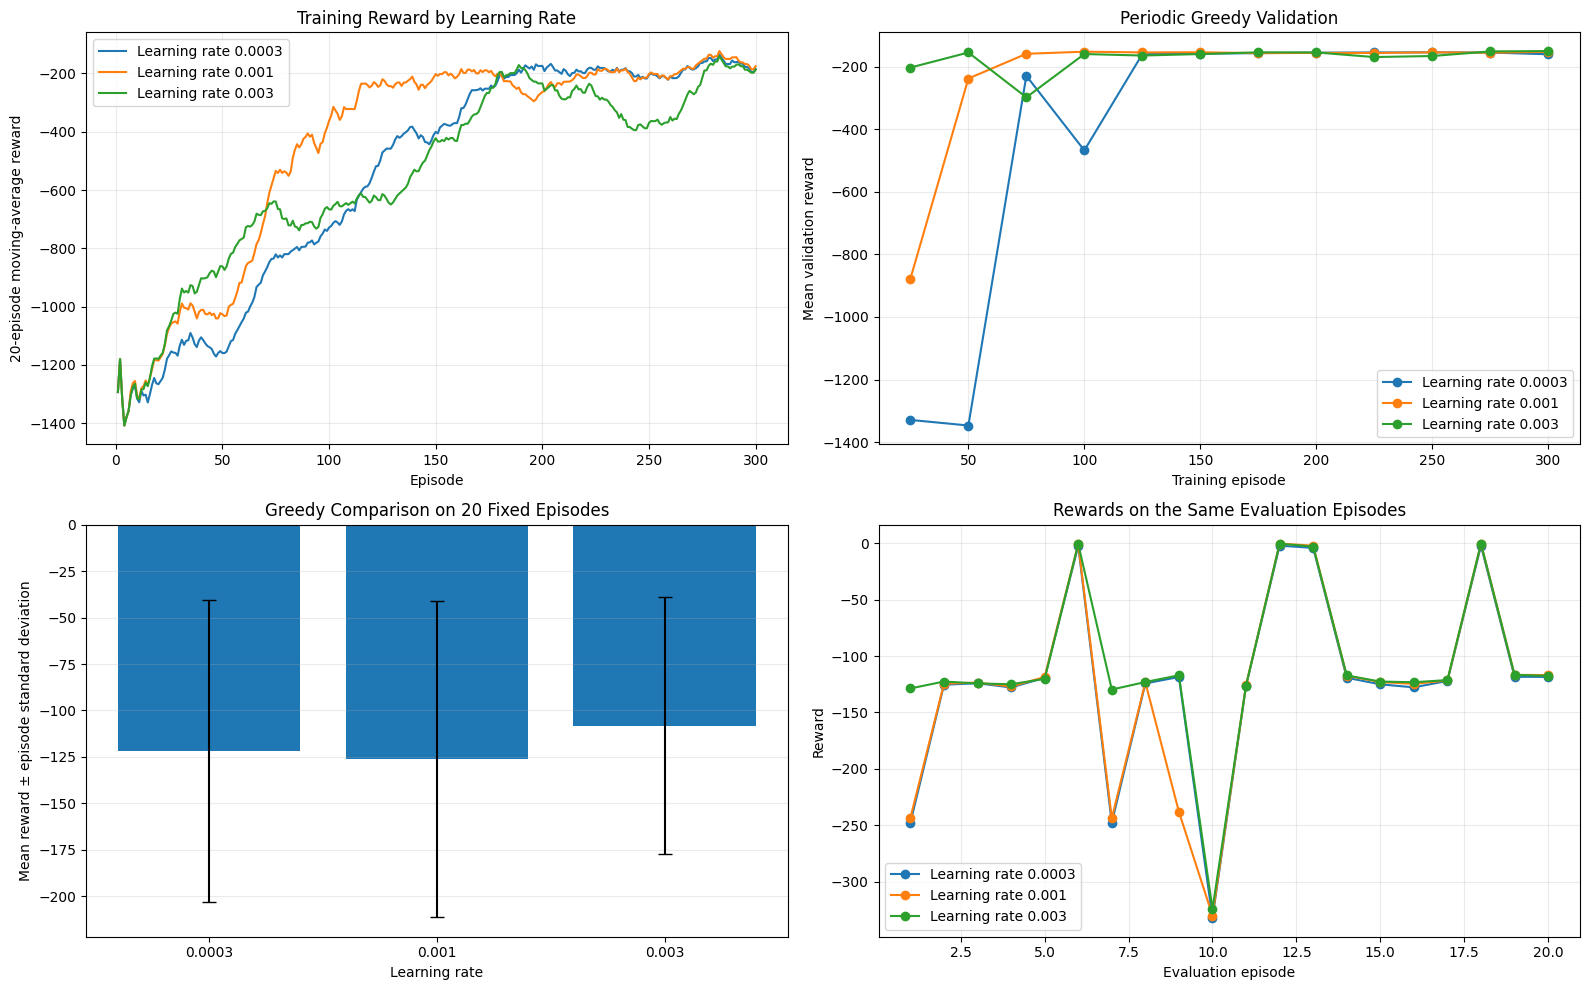

In [43]:
learning_rate_ids = list(
    LEARNING_RATE_SETTINGS.keys()
)


fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10),
)


# ---------------------------------------------------------
# Training reward
# ---------------------------------------------------------

for learning_rate_id in learning_rate_ids:

    run_training = (
        learning_rate_training_all_dataframe[
            learning_rate_training_all_dataframe[
                "learning_rate_id"
            ] == learning_rate_id
        ]
        .sort_values("episode")
    )

    axes[0, 0].plot(
        run_training["episode"],
        run_training["moving_average_reward"],
        label=LEARNING_RATE_SETTINGS[
            learning_rate_id
        ]["label"],
    )

axes[0, 0].set_title(
    "Training Reward by Learning Rate"
)
axes[0, 0].set_xlabel("Episode")
axes[0, 0].set_ylabel(
    "20-episode moving-average reward"
)
axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend()


# ---------------------------------------------------------
# Periodic greedy validation
# ---------------------------------------------------------

for learning_rate_id in learning_rate_ids:

    run_validation = (
        learning_rate_validation_all_dataframe[
            learning_rate_validation_all_dataframe[
                "learning_rate_id"
            ] == learning_rate_id
        ]
        .sort_values("training_episode")
    )

    axes[0, 1].plot(
        run_validation["training_episode"],
        run_validation[
            "validation_mean_reward"
        ],
        marker="o",
        label=LEARNING_RATE_SETTINGS[
            learning_rate_id
        ]["label"],
    )

axes[0, 1].set_title(
    "Periodic Greedy Validation"
)
axes[0, 1].set_xlabel("Training episode")
axes[0, 1].set_ylabel("Mean validation reward")
axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend()


# ---------------------------------------------------------
# Final greedy comparison
# ---------------------------------------------------------

plot_results = (
    learning_rate_results_dataframe
    .set_index("learning_rate_id")
    .loc[learning_rate_ids]
    .reset_index()
)

positions = np.arange(
    len(plot_results)
)

axes[1, 0].bar(
    positions,
    plot_results["comparison_mean_reward"],
    yerr=plot_results["comparison_reward_std"],
    capsize=5,
)

axes[1, 0].set_title(
    "Greedy Comparison on 20 Fixed Episodes"
)
axes[1, 0].set_xlabel("Learning rate")
axes[1, 0].set_ylabel(
    "Mean reward ± episode standard deviation"
)
axes[1, 0].set_xticks(positions)
axes[1, 0].set_xticklabels(
    plot_results["learning_rate"].astype(str)
)
axes[1, 0].grid(
    axis="y",
    alpha=0.25,
)


# ---------------------------------------------------------
# Paired episode rewards
# ---------------------------------------------------------

for learning_rate_id in learning_rate_ids:

    episode_results = (
        learning_rate_episode_dataframe[
            learning_rate_episode_dataframe[
                "learning_rate_id"
            ] == learning_rate_id
        ]
        .sort_values("evaluation_episode")
    )

    axes[1, 1].plot(
        episode_results["evaluation_episode"],
        episode_results["reward"],
        marker="o",
        label=LEARNING_RATE_SETTINGS[
            learning_rate_id
        ]["label"],
    )

axes[1, 1].set_title(
    "Rewards on the Same Evaluation Episodes"
)
axes[1, 1].set_xlabel("Evaluation episode")
axes[1, 1].set_ylabel("Reward")
axes[1, 1].grid(alpha=0.25)
axes[1, 1].legend()


plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "learning_rate_experiment.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()


#### Evaluation


Experiment 3 compared learning rates of 0.0003, 0.001 and 0.003 using the selected Fast Decay 0.990 exploration strategy. All configurations achieved a 100% reached-upright rate and balance-success rate. Learning rate 0.003 achieved the highest fixed greedy comparison mean reward of −108.24, the lowest reward standard deviation of 69.25, and the highest mean upright duration of 175.40 steps. Therefore, 0.003 was selected for subsequent experiments. However, because the configurations were trained using only one seed and the episode-level variability remained considerable, it should be described as the best observed learning rate rather than conclusively optimal.



In [46]:
selected_learning_rate_id = "learning_rate_0_0030"

SELECTED_LEARNING_RATE = float(
    LEARNING_RATE_SETTINGS[
        selected_learning_rate_id
    ]["learning_rate"]
)

# The actual DQNConfig dataclass
SELECTED_LEARNING_RATE_CONFIG = (
    LEARNING_RATE_CONFIGS[
        selected_learning_rate_id
    ]
)

# Saved Experiment 3 files
SELECTED_LEARNING_RATE_RUN_PATHS = (
    get_learning_rate_run_paths(
        selected_learning_rate_id
    )
)

print(
    "Selected learning rate:",
    SELECTED_LEARNING_RATE,
)

print(
    "Configuration type:",
    type(SELECTED_LEARNING_RATE_CONFIG).__name__,
)

assert isinstance(
    SELECTED_LEARNING_RATE_CONFIG,
    DQNConfig,
)

Selected learning rate: 0.003
Configuration type: DQNConfig


# 10. Experiment 4: Network Architecture

The selected DQN algorithm is compared using small, medium and large two-layer networks.

### Experiment Set Up

In [47]:
# ---------------------------------------------------------
# Experiment 4: Network architecture
# ---------------------------------------------------------

# Experiment 4 continues using Standard DQN.
# Only the hidden-layer architecture changes.

NETWORK_ARCHITECTURES = {
    "small_64_64": {
        "label": "Small [64, 64]",
        "hidden_layers": (64, 64),
    },
    "medium_128_128": {
        "label": "Medium [128, 128]",
        "hidden_layers": (128, 128),
    },
    "large_256_256": {
        "label": "Large [256, 256]",
        "hidden_layers": (256, 256),
    },
}


# ---------------------------------------------------------
# Carry forward the selected Experiment 3 settings
# ---------------------------------------------------------

ARCHITECTURE_BASE_CONFIG = (
    SELECTED_LEARNING_RATE_CONFIG
)

ARCHITECTURE_ACTION_VALUES = (
    LEARNING_RATE_ACTION_VALUES.copy()
)

ARCHITECTURE_TRAINING_EPISODES = (
    LEARNING_RATE_TRAINING_EPISODES
)

ARCHITECTURE_TRAINING_SEED = (
    LEARNING_RATE_TRAINING_SEED
)

ARCHITECTURE_VALIDATION_SEED = (
    LEARNING_RATE_VALIDATION_SEED
)

ARCHITECTURE_EVALUATION_EVERY = (
    LEARNING_RATE_EVALUATION_EVERY
)

ARCHITECTURE_VALIDATION_EPISODES = (
    LEARNING_RATE_VALIDATION_EPISODES
)

ARCHITECTURE_COMPARISON_EPISODES = 20

# New fixed comparison episodes not used in Experiments 1–3
ARCHITECTURE_COMPARISON_SEED = 65_000


# ---------------------------------------------------------
# Output directories
# ---------------------------------------------------------

# A new directory name prevents older architecture results
# produced under the previous experiment order from being reused.
ARCHITECTURE_WEIGHTS_DIR = (
    WEIGHTS_DIR
    / "architecture_experiment_standard_dqn"
)

ARCHITECTURE_RESULTS_DIR = (
    RESULTS_DIR
    / "architecture_experiment_standard_dqn"
)

ARCHITECTURE_WEIGHTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

ARCHITECTURE_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ---------------------------------------------------------
# Create one configuration for each architecture
# ---------------------------------------------------------

def create_architecture_config(
    base_config,
    hidden_layers,
):
    """
    Create an independent DQN configuration with a
    different hidden-layer architecture.
    """

    return replace(
        base_config,
        hidden_layers=tuple(hidden_layers),
    )


ARCHITECTURE_CONFIGS = {
    architecture_id: create_architecture_config(
        base_config=ARCHITECTURE_BASE_CONFIG,
        hidden_layers=settings["hidden_layers"],
    )
    for architecture_id, settings
    in NETWORK_ARCHITECTURES.items()
}


# ---------------------------------------------------------
# Identify the reusable Experiment 3 architecture
# ---------------------------------------------------------

EXPERIMENT_3_HIDDEN_LAYERS = tuple(
    ARCHITECTURE_BASE_CONFIG.hidden_layers
)

REUSED_ARCHITECTURE_ID = next(
    (
        architecture_id
        for architecture_id, settings
        in NETWORK_ARCHITECTURES.items()
        if tuple(settings["hidden_layers"])
        == EXPERIMENT_3_HIDDEN_LAYERS
    ),
    None,
)


if REUSED_ARCHITECTURE_ID is not None:
    print(
        "Reusing the selected Standard DQN from "
        "Experiment 3 for:",
        NETWORK_ARCHITECTURES[
            REUSED_ARCHITECTURE_ID
        ]["label"],
    )
else:
    print(
        "The Experiment 3 architecture",
        list(EXPERIMENT_3_HIDDEN_LAYERS),
        "does not match any tested architecture.",
    )

    print(
        "All three architecture models "
        "will require training."
    )


# ---------------------------------------------------------
# Calculate parameter counts
# ---------------------------------------------------------

for architecture_id, settings in (
    NETWORK_ARCHITECTURES.items()
):
    temporary_network = build_q_network(
        state_size=STATE_SIZE,
        action_size=len(
            ARCHITECTURE_ACTION_VALUES
        ),
        hidden_layers=settings["hidden_layers"],
        activation=(
            ARCHITECTURE_BASE_CONFIG.activation
        ),
    )

    settings["parameter_count"] = int(
        temporary_network.count_params()
    )

    del temporary_network


tf.keras.backend.clear_session()
gc.collect()


# ---------------------------------------------------------
# Set paths for each architecture
# ---------------------------------------------------------

ARCHITECTURE_RUN_PATHS = {}

for architecture_id in NETWORK_ARCHITECTURES:

    if architecture_id == REUSED_ARCHITECTURE_ID:
        # Reuse the selected Experiment 3 Standard DQN
        ARCHITECTURE_RUN_PATHS[
            architecture_id
        ] = SELECTED_LEARNING_RATE_RUN_PATHS

    else:
        ARCHITECTURE_RUN_PATHS[
            architecture_id
        ] = {
            "weights": (
                ARCHITECTURE_WEIGHTS_DIR
                / (
                    f"{architecture_id}"
                    ".weights.h5"
                )
            ),
            "training": (
                ARCHITECTURE_RESULTS_DIR
                / (
                    f"{architecture_id}"
                    "_training.csv"
                )
            ),
            "validation": (
                ARCHITECTURE_RESULTS_DIR
                / (
                    f"{architecture_id}"
                    "_validation.csv"
                )
            ),
            "checkpoint": (
                ARCHITECTURE_RESULTS_DIR
                / (
                    f"{architecture_id}"
                    "_checkpoint.csv"
                )
            ),
        }


# ---------------------------------------------------------
# Verify the reused Experiment 3 files
# ---------------------------------------------------------

if REUSED_ARCHITECTURE_ID is not None:
    reused_paths = ARCHITECTURE_RUN_PATHS[
        REUSED_ARCHITECTURE_ID
    ]

    for path_name, path in reused_paths.items():
        if not path.exists():
            raise FileNotFoundError(
                f"Missing reused Experiment 3 "
                f"{path_name}: {path.resolve()}"
            )


# ---------------------------------------------------------
# Display experiment setup
# ---------------------------------------------------------

architecture_setup_dataframe = pd.DataFrame([
    {
        "architecture_id": architecture_id,
        "architecture_label": settings["label"],
        "hidden_layers": str(
            list(settings["hidden_layers"])
        ),
        "parameter_count": (
            settings["parameter_count"]
        ),
        "algorithm": "Standard DQN",
        "action_count": len(
            ARCHITECTURE_ACTION_VALUES
        ),
        "epsilon_decay": (
            ARCHITECTURE_CONFIGS[
                architecture_id
            ].epsilon_decay
        ),
        "learning_rate": (
            ARCHITECTURE_CONFIGS[
                architecture_id
            ].learning_rate
        ),
        "reused_existing_model": (
            architecture_id
            == REUSED_ARCHITECTURE_ID
        ),
        "requires_new_training": (
            architecture_id
            != REUSED_ARCHITECTURE_ID
        ),
    }
    for architecture_id, settings
    in NETWORK_ARCHITECTURES.items()
])


display(architecture_setup_dataframe)

print(
    "\nModels requiring new training:",
    int(
        architecture_setup_dataframe[
            "requires_new_training"
        ].sum()
    ),
)

Reusing the selected Standard DQN from Experiment 3 for: Small [64, 64]


,architecture_id,architecture_label,hidden_layers,parameter_count,algorithm,action_count,epsilon_decay,learning_rate,reused_existing_model,requires_new_training
0,small_64_64,"Small [64, 64]","[64, 64]",5781,Standard DQN,21,0.99,0.003,True,False
1,medium_128_128,"Medium [128, 128]","[128, 128]",19733,Standard DQN,21,0.99,0.003,False,True
2,large_256_256,"Large [256, 256]","[256, 256]",72213,Standard DQN,21,0.99,0.003,False,True



Models requiring new training: 2


### Training

In [49]:
# ---------------------------------------------------------
# Experiment 4: Train network architectures
# ---------------------------------------------------------

assert isinstance(
    ARCHITECTURE_BASE_CONFIG,
    DQNConfig,
), (
    "ARCHITECTURE_BASE_CONFIG must be a DQNConfig. "
    "Rerun the corrected Experiment 3 selection cell."
)


for architecture_id, settings in (
    NETWORK_ARCHITECTURES.items()
):

    run_config = ARCHITECTURE_CONFIGS[
        architecture_id
    ]

    run_paths = ARCHITECTURE_RUN_PATHS[
        architecture_id
    ]

    # Reuse the matching Standard DQN from Experiment 3
    if architecture_id == REUSED_ARCHITECTURE_ID:
        print(
            f"Reusing {settings['label']} from "
            "Experiment 3: no training required."
        )
        continue

    run_is_complete = all(
        path.exists()
        for path in run_paths.values()
    )

    if run_is_complete:
        print(
            f"Skipping {settings['label']}: "
            "saved results already exist."
        )
        continue

    print("\n" + "=" * 70)
    print(
        f"ARCHITECTURE: {settings['label'].upper()} | "
        f"TRAINING SEED: "
        f"{ARCHITECTURE_TRAINING_SEED}"
    )
    print("=" * 70)

    tf.keras.backend.clear_session()

    set_global_seed(
        ARCHITECTURE_TRAINING_SEED
    )

    training_env = None
    validation_env = None
    architecture_agent = None

    try:
        training_env = create_pendulum_env(
            gravity=GRAVITY_SETUPS[
                "setup_1_default"
            ],
            seed=ARCHITECTURE_TRAINING_SEED,
        )

        validation_env = create_pendulum_env(
            gravity=GRAVITY_SETUPS[
                "setup_1_default"
            ],
            seed=ARCHITECTURE_VALIDATION_SEED,
        )

        # Experiment 4 uses Standard DQN only
        architecture_agent = DQNAgent(
            state_size=STATE_SIZE,
            action_values=(
                ARCHITECTURE_ACTION_VALUES
            ),
            config=run_config,
            use_double_dqn=False,
        )

        (
            architecture_history,
            architecture_training_dataframe,
        ) = train_agent(
            env=training_env,
            agent=architecture_agent,
            episodes=(
                ARCHITECTURE_TRAINING_EPISODES
            ),
            max_steps=MAX_STEPS_PER_EPISODE,
            moving_average_window=20,
            seed=ARCHITECTURE_TRAINING_SEED,
            evaluation_env=validation_env,
            evaluation_every=(
                ARCHITECTURE_EVALUATION_EVERY
            ),
            evaluation_episodes=(
                ARCHITECTURE_VALIDATION_EPISODES
            ),
            evaluation_seed=(
                ARCHITECTURE_VALIDATION_SEED
            ),
            best_weights_path=run_paths[
                "weights"
            ],
            print_every=25,
            render_every=None,
        )

        # -------------------------------------------------
        # Save training history
        # -------------------------------------------------

        architecture_training_dataframe[
            "architecture_id"
        ] = architecture_id

        architecture_training_dataframe[
            "architecture_label"
        ] = settings["label"]

        architecture_training_dataframe[
            "hidden_layers"
        ] = str(
            list(settings["hidden_layers"])
        )

        architecture_training_dataframe[
            "parameter_count"
        ] = settings["parameter_count"]

        architecture_training_dataframe[
            "algorithm"
        ] = "Standard DQN"

        architecture_training_dataframe[
            "action_count"
        ] = len(
            ARCHITECTURE_ACTION_VALUES
        )

        architecture_training_dataframe[
            "epsilon_decay"
        ] = run_config.epsilon_decay

        architecture_training_dataframe[
            "learning_rate"
        ] = run_config.learning_rate

        architecture_training_dataframe[
            "training_seed"
        ] = ARCHITECTURE_TRAINING_SEED

        architecture_training_dataframe.to_csv(
            run_paths["training"],
            index=False,
        )

        # -------------------------------------------------
        # Save periodic validation results
        # -------------------------------------------------

        architecture_validation_dataframe = (
            pd.DataFrame({
                "architecture_id": architecture_id,
                "architecture_label": (
                    settings["label"]
                ),
                "hidden_layers": str(
                    list(settings["hidden_layers"])
                ),
                "parameter_count": (
                    settings["parameter_count"]
                ),
                "algorithm": "Standard DQN",
                "action_count": len(
                    ARCHITECTURE_ACTION_VALUES
                ),
                "epsilon_decay": (
                    run_config.epsilon_decay
                ),
                "learning_rate": (
                    run_config.learning_rate
                ),
                "training_seed": (
                    ARCHITECTURE_TRAINING_SEED
                ),
                "training_episode": (
                    architecture_history[
                        "evaluation_episode"
                    ]
                ),
                "validation_mean_reward": (
                    architecture_history[
                        "evaluation_mean_reward"
                    ]
                ),
                "validation_reward_std": (
                    architecture_history[
                        "evaluation_reward_std"
                    ]
                ),
            })
        )

        architecture_validation_dataframe.to_csv(
            run_paths["validation"],
            index=False,
        )

        # -------------------------------------------------
        # Save best-checkpoint information
        # -------------------------------------------------

        best_position = int(
            np.argmax(
                architecture_history[
                    "evaluation_mean_reward"
                ]
            )
        )

        architecture_checkpoint_dataframe = (
            pd.DataFrame([
                {
                    "architecture_id": (
                        architecture_id
                    ),
                    "architecture_label": (
                        settings["label"]
                    ),
                    "hidden_layers": str(
                        list(
                            settings[
                                "hidden_layers"
                            ]
                        )
                    ),
                    "parameter_count": (
                        settings["parameter_count"]
                    ),
                    "algorithm": "Standard DQN",
                    "action_count": len(
                        ARCHITECTURE_ACTION_VALUES
                    ),
                    "epsilon_decay": (
                        run_config.epsilon_decay
                    ),
                    "learning_rate": (
                        run_config.learning_rate
                    ),
                    "training_seed": (
                        ARCHITECTURE_TRAINING_SEED
                    ),
                    "best_checkpoint_episode": (
                        architecture_history[
                            "evaluation_episode"
                        ][best_position]
                    ),
                    "best_validation_mean_reward": (
                        architecture_history[
                            "evaluation_mean_reward"
                        ][best_position]
                    ),
                    "best_validation_reward_std": (
                        architecture_history[
                            "evaluation_reward_std"
                        ][best_position]
                    ),
                    "final_training_epsilon": (
                        architecture_agent.epsilon
                    ),
                }
            ])
        )

        architecture_checkpoint_dataframe.to_csv(
            run_paths["checkpoint"],
            index=False,
        )

        print(
            f"{settings['label']} training completed."
        )

    finally:
        if training_env is not None:
            training_env.close()

        if validation_env is not None:
            validation_env.close()

        architecture_agent = None

        tf.keras.backend.clear_session()
        gc.collect()

Reusing Small [64, 64] from Experiment 3: no training required.

ARCHITECTURE: MEDIUM [128, 128] | TRAINING SEED: 123
Episode    1/300 | Reward: -1293.58 | Moving average: -1293.58 | Epsilon: 0.9900 | Loss: not training yet | Replay size: 200
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\architecture_experiment_standard_dqn\medium_128_128.weights.h5
Evaluation at episode 25: mean reward = -170.47, std = 99.69
New best weights saved.
Episode   25/300 | Reward:  -884.31 | Moving average: -1051.31 | Epsilon: 0.7778 | Loss: 0.6573 | Replay size: 5000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\architecture_experiment_standard_dqn\medium_128_128.weights.h5
Evaluation at episode 50: mean reward = -156.74, std = 95.98
New best weights saved.
Episode   50/300 | Reward:  -806.35 | Moving average:  -853.32 | Epsilon: 0.6050 | Loss: 2.6429 | Replay size: 10000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\architecture_experiment_standard_dqn\medium_128_128.we

### Evaluation

In [50]:
# ---------------------------------------------------------
# Experiment 4: Load saved architecture runs
# ---------------------------------------------------------

architecture_training_frames = []
architecture_validation_frames = []
architecture_checkpoint_lookup = {}


for architecture_id, settings in (
    NETWORK_ARCHITECTURES.items()
):

    run_paths = ARCHITECTURE_RUN_PATHS[
        architecture_id
    ]

    for path_name, path in run_paths.items():
        if not path.exists():
            raise FileNotFoundError(
                f"Missing {settings['label']} "
                f"{path_name}: {path.resolve()}"
            )

    run_training_dataframe = pd.read_csv(
        run_paths["training"]
    )

    run_validation_dataframe = pd.read_csv(
        run_paths["validation"]
    )

    run_checkpoint_dataframe = pd.read_csv(
        run_paths["checkpoint"]
    )

    run_config = ARCHITECTURE_CONFIGS[
        architecture_id
    ]

    # Standardise metadata, including reused Experiment 3 data
    run_training_dataframe[
        "architecture_id"
    ] = architecture_id

    run_training_dataframe[
        "architecture_label"
    ] = settings["label"]

    run_training_dataframe[
        "hidden_layers"
    ] = str(
        list(settings["hidden_layers"])
    )

    run_training_dataframe[
        "parameter_count"
    ] = settings["parameter_count"]

    run_training_dataframe[
        "algorithm"
    ] = "Standard DQN"

    run_training_dataframe[
        "action_count"
    ] = len(
        ARCHITECTURE_ACTION_VALUES
    )

    run_training_dataframe[
        "epsilon_decay"
    ] = run_config.epsilon_decay

    run_training_dataframe[
        "learning_rate"
    ] = run_config.learning_rate


    run_validation_dataframe[
        "architecture_id"
    ] = architecture_id

    run_validation_dataframe[
        "architecture_label"
    ] = settings["label"]

    run_validation_dataframe[
        "hidden_layers"
    ] = str(
        list(settings["hidden_layers"])
    )

    run_validation_dataframe[
        "parameter_count"
    ] = settings["parameter_count"]

    run_validation_dataframe[
        "algorithm"
    ] = "Standard DQN"

    run_validation_dataframe[
        "action_count"
    ] = len(
        ARCHITECTURE_ACTION_VALUES
    )

    run_validation_dataframe[
        "epsilon_decay"
    ] = run_config.epsilon_decay

    run_validation_dataframe[
        "learning_rate"
    ] = run_config.learning_rate


    architecture_training_frames.append(
        run_training_dataframe
    )

    architecture_validation_frames.append(
        run_validation_dataframe
    )

    checkpoint_row = (
        run_checkpoint_dataframe.iloc[0]
    )

    architecture_checkpoint_lookup[
        architecture_id
    ] = {
        "best_checkpoint_episode": int(
            checkpoint_row[
                "best_checkpoint_episode"
            ]
        ),
        "best_validation_mean_reward": float(
            checkpoint_row[
                "best_validation_mean_reward"
            ]
        ),
        "best_validation_reward_std": float(
            checkpoint_row[
                "best_validation_reward_std"
            ]
        ),
    }


architecture_training_all_dataframe = pd.concat(
    architecture_training_frames,
    ignore_index=True,
)

architecture_validation_all_dataframe = pd.concat(
    architecture_validation_frames,
    ignore_index=True,
)


# ---------------------------------------------------------
# Greedy comparison using identical unseen episodes
# ---------------------------------------------------------

architecture_result_records = []
architecture_episode_records = []


for architecture_id, settings in (
    NETWORK_ARCHITECTURES.items()
):

    tf.keras.backend.clear_session()

    set_global_seed(
        ARCHITECTURE_COMPARISON_SEED
    )

    comparison_env = None
    evaluation_agent = None

    try:
        comparison_env = create_pendulum_env(
            gravity=GRAVITY_SETUPS[
                "setup_1_default"
            ],
            seed=ARCHITECTURE_COMPARISON_SEED,
        )

        run_config = ARCHITECTURE_CONFIGS[
            architecture_id
        ]

        evaluation_agent = DQNAgent(
            state_size=STATE_SIZE,
            action_values=(
                ARCHITECTURE_ACTION_VALUES
            ),
            config=run_config,
            use_double_dqn=False,
        )

        evaluation_agent.load_weights(
            ARCHITECTURE_RUN_PATHS[
                architecture_id
            ]["weights"]
        )

        comparison_result = evaluate_agent(
            env=comparison_env,
            agent=evaluation_agent,
            episodes=(
                ARCHITECTURE_COMPARISON_EPISODES
            ),
            max_steps=MAX_STEPS_PER_EPISODE,
            seed=ARCHITECTURE_COMPARISON_SEED,
            best_score=None,
            save_path=None,
            verbose=False,
        )

        checkpoint_information = (
            architecture_checkpoint_lookup[
                architecture_id
            ]
        )

        architecture_result_records.append({
            "architecture_id": architecture_id,
            "architecture_label": (
                settings["label"]
            ),
            "hidden_layers": str(
                list(settings["hidden_layers"])
            ),
            "parameter_count": (
                settings["parameter_count"]
            ),
            "algorithm": "Standard DQN",
            "action_count": len(
                ARCHITECTURE_ACTION_VALUES
            ),
            "epsilon_decay": (
                run_config.epsilon_decay
            ),
            "learning_rate": (
                run_config.learning_rate
            ),
            "training_episodes": (
                ARCHITECTURE_TRAINING_EPISODES
            ),
            "training_seed": (
                ARCHITECTURE_TRAINING_SEED
            ),
            "best_checkpoint_episode": (
                checkpoint_information[
                    "best_checkpoint_episode"
                ]
            ),
            "best_validation_mean_reward": (
                checkpoint_information[
                    "best_validation_mean_reward"
                ]
            ),
            "best_validation_reward_std": (
                checkpoint_information[
                    "best_validation_reward_std"
                ]
            ),
            "comparison_mean_reward": (
                comparison_result["mean_reward"]
            ),
            "comparison_reward_std": (
                comparison_result["reward_std"]
            ),
            "comparison_minimum_reward": (
                comparison_result[
                    "minimum_reward"
                ]
            ),
            "comparison_maximum_reward": (
                comparison_result[
                    "maximum_reward"
                ]
            ),

            # Balance metrics
            "reached_upright_rate": (
                comparison_result[
                    "reached_upright_rate"
                ]
            ),
            "balance_success_rate": (
                comparison_result[
                    "balance_success_rate"
                ]
            ),
            "mean_upright_steps": (
                comparison_result[
                    "mean_upright_steps"
                ]
            ),
            "mean_longest_balance_streak": (
                comparison_result[
                    "mean_longest_balance_streak"
                ]
            ),
        })

        # Save detailed per-episode results
        for episode_metric in (
            comparison_result["episode_metrics"]
        ):
            architecture_episode_records.append({
                "architecture_id": (
                    architecture_id
                ),
                "architecture_label": (
                    settings["label"]
                ),
                **episode_metric,
            })

        print(
            f"{settings['label']}: "
            f"reward = "
            f"{comparison_result['mean_reward']:.2f} "
            f"± {comparison_result['reward_std']:.2f} | "
            f"upright = "
            f"{comparison_result['reached_upright_rate']:.1%} | "
            f"balance success = "
            f"{comparison_result['balance_success_rate']:.1%}"
        )

    finally:
        if comparison_env is not None:
            comparison_env.close()

        evaluation_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


# ---------------------------------------------------------
# Create result tables
# ---------------------------------------------------------

architecture_results_dataframe = pd.DataFrame(
    architecture_result_records
).sort_values(
    "comparison_mean_reward",
    ascending=False,
).reset_index(drop=True)


architecture_results_dataframe.insert(
    0,
    "rank",
    np.arange(
        1,
        len(architecture_results_dataframe) + 1,
    ),
)


architecture_episode_dataframe = pd.DataFrame(
    architecture_episode_records
)


architecture_paired_dataframe = (
    architecture_episode_dataframe
    .pivot(
        index=[
            "evaluation_episode",
            "evaluation_seed",
        ],
        columns="architecture_id",
        values="reward",
    )
    .reset_index()
)


architecture_paired_dataframe[
    "small_minus_medium"
] = (
    architecture_paired_dataframe[
        "small_64_64"
    ]
    - architecture_paired_dataframe[
        "medium_128_128"
    ]
)


architecture_paired_dataframe[
    "large_minus_medium"
] = (
    architecture_paired_dataframe[
        "large_256_256"
    ]
    - architecture_paired_dataframe[
        "medium_128_128"
    ]
)


# ---------------------------------------------------------
# Select the highest-mean-reward architecture
# ---------------------------------------------------------

SELECTED_ARCHITECTURE_ID = (
    architecture_results_dataframe.iloc[0][
        "architecture_id"
    ]
)

SELECTED_ARCHITECTURE_LABEL = (
    NETWORK_ARCHITECTURES[
        SELECTED_ARCHITECTURE_ID
    ]["label"]
)

SELECTED_HIDDEN_LAYERS = tuple(
    NETWORK_ARCHITECTURES[
        SELECTED_ARCHITECTURE_ID
    ]["hidden_layers"]
)

SELECTED_ARCHITECTURE_CONFIG = (
    ARCHITECTURE_CONFIGS[
        SELECTED_ARCHITECTURE_ID
    ]
)

# Experiment 5 will reuse this Standard DQN run
SELECTED_ARCHITECTURE_PATHS = (
    ARCHITECTURE_RUN_PATHS[
        SELECTED_ARCHITECTURE_ID
    ]
)

SELECTED_ARCHITECTURE_WEIGHTS_PATH = (
    SELECTED_ARCHITECTURE_PATHS[
        "weights"
    ]
)


# ---------------------------------------------------------
# Save Experiment 4 results
# ---------------------------------------------------------

architecture_results_dataframe.to_csv(
    ARCHITECTURE_RESULTS_DIR
    / "architecture_comparison_results.csv",
    index=False,
)

architecture_episode_dataframe.to_csv(
    ARCHITECTURE_RESULTS_DIR
    / "architecture_episode_metrics.csv",
    index=False,
)

architecture_paired_dataframe.to_csv(
    ARCHITECTURE_RESULTS_DIR
    / "architecture_paired_differences.csv",
    index=False,
)

architecture_training_all_dataframe.to_csv(
    ARCHITECTURE_RESULTS_DIR
    / "architecture_training_all.csv",
    index=False,
)

architecture_validation_all_dataframe.to_csv(
    ARCHITECTURE_RESULTS_DIR
    / "architecture_validation_all.csv",
    index=False,
)


# ---------------------------------------------------------
# Display results
# ---------------------------------------------------------

architecture_display_dataframe = (
    architecture_results_dataframe.copy()
)

percentage_columns = [
    "reached_upright_rate",
    "balance_success_rate",
]

architecture_display_dataframe[
    percentage_columns
] *= 100


architecture_display_columns = [
    "rank",
    "architecture_label",
    "hidden_layers",
    "parameter_count",
    "comparison_mean_reward",
    "comparison_reward_std",
    "comparison_minimum_reward",
    "comparison_maximum_reward",
    "reached_upright_rate",
    "balance_success_rate",
    "mean_upright_steps",
    "mean_longest_balance_streak",
]


print(
    "\nSelected architecture:",
    SELECTED_ARCHITECTURE_LABEL,
)

print(
    "Selected architecture paths:",
    SELECTED_ARCHITECTURE_PATHS,
)

display(
    architecture_display_dataframe[
        architecture_display_columns
    ].round(2)
)


print("\nPaired episode rewards:")

display(
    architecture_paired_dataframe.round(2)
)

Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\learning_rate_experiment\learning_rate_0_0030_seed_123.weights.h5
Small [64, 64]: reward = -164.56 ± 95.90 | upright = 100.0% | balance success = 100.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\architecture_experiment_standard_dqn\medium_128_128.weights.h5
Medium [128, 128]: reward = -160.89 ± 92.32 | upright = 100.0% | balance success = 100.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\architecture_experiment_standard_dqn\large_256_256.weights.h5
Large [256, 256]: reward = -171.32 ± 103.00 | upright = 75.0% | balance success = 75.0%

Selected architecture: Medium [128, 128]
Selected architecture paths: {'weights': WindowsPath('weights/architecture_experiment_standard_dqn/medium_128_128.weights.h5'), 'training': WindowsPath('results/architecture_experiment_standard_dqn/medium_128_128_training.csv'), 'validation': WindowsPath('results/architecture_experiment_standard_dqn/medium_128_128_val

,rank,architecture_label,hidden_layers,parameter_count,comparison_mean_reward,comparison_reward_std,comparison_minimum_reward,comparison_maximum_reward,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,1,"Medium [128, 128]","[128, 128]",19733,-160.89,92.32,-359.73,-0.67,100.0,100.0,165.65,159.4
1,2,"Small [64, 64]","[64, 64]",5781,-164.56,95.90,-354.88,-0.29,100.0,100.0,166.05,161.6
2,3,"Large [256, 256]","[256, 256]",72213,-171.32,103.00,-376.89,-1.76,75.0,75.0,130.60,128.2



Paired episode rewards:


architecture_id,evaluation_episode,evaluation_seed,large_256_256,medium_128_128,small_64_64,small_minus_medium,large_minus_medium
0,1,65000,-242.14,-223.88,-223.62,0.27,-18.26
1,2,65001,-1.76,-0.67,-0.29,0.38,-1.09
2,3,65002,-260.99,-239.66,-239.23,0.43,-21.34
3,4,65003,-123.69,-125.16,-121.75,3.40,1.47
4,5,65004,-1.83,-0.82,-0.41,0.41,-1.02
5,6,65005,-226.75,-226.99,-233.79,-6.80,0.23
6,7,65006,-118.03,-117.69,-121.90,-4.21,-0.34
7,8,65007,-124.48,-126.10,-122.85,3.26,1.63
8,9,65008,-328.76,-247.58,-248.37,-0.79,-81.19
9,10,65009,-1.78,-0.73,-0.37,0.36,-1.05


### Visualization

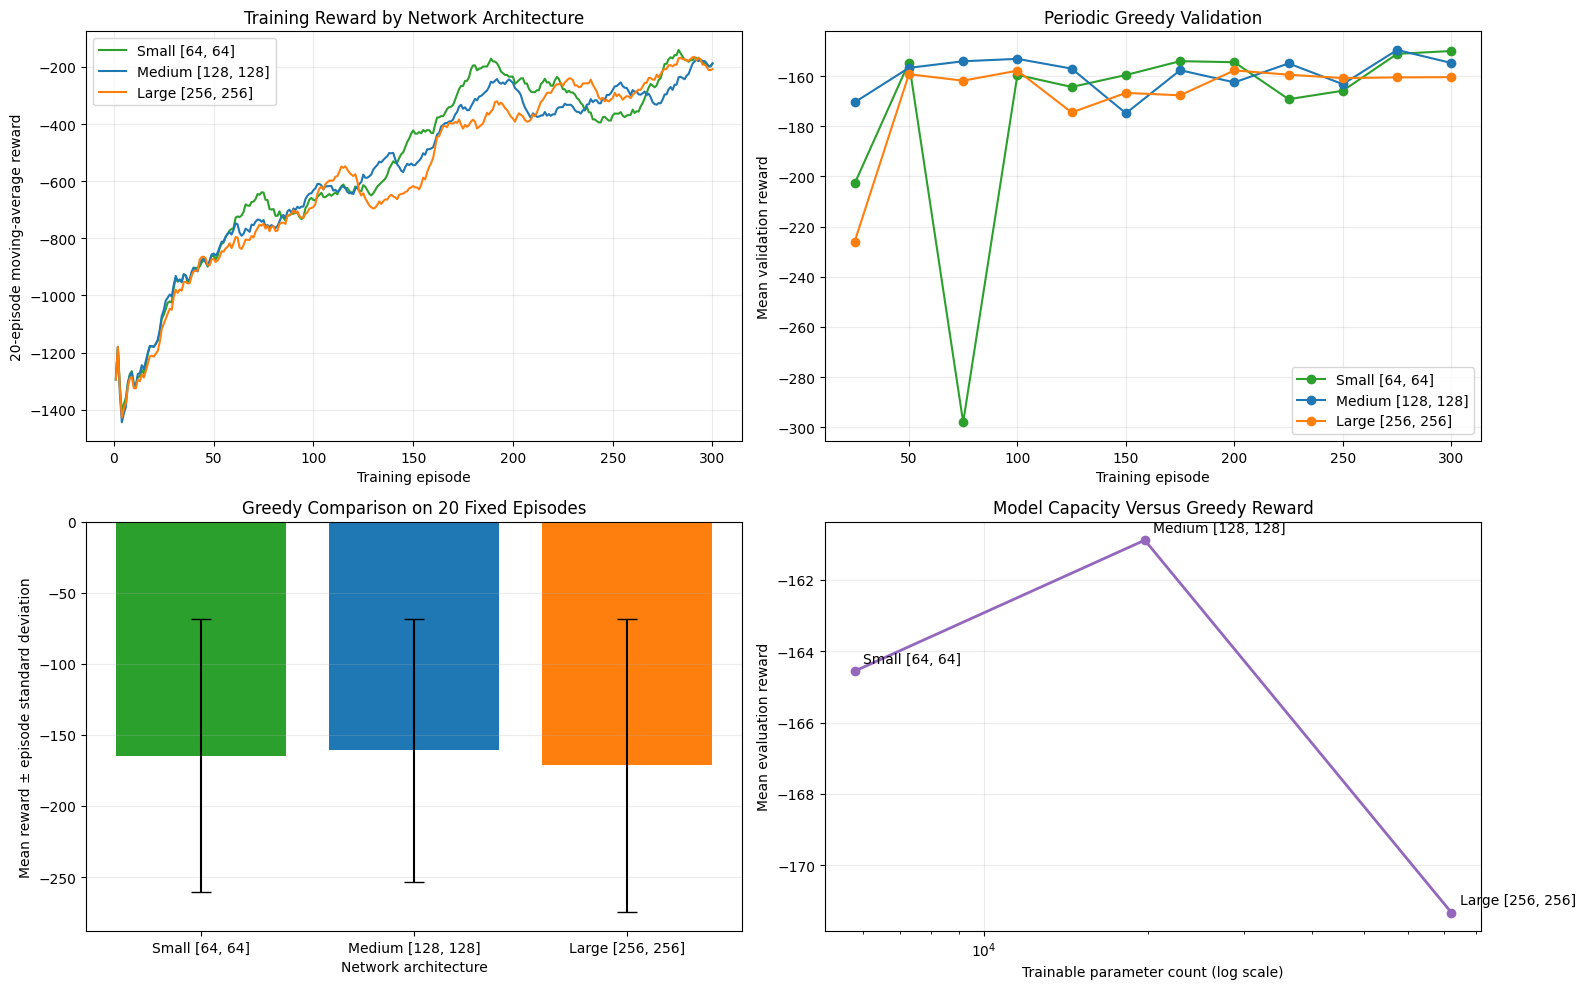

In [51]:
# ---------------------------------------------------------
# Experiment 4: Visualisations
# ---------------------------------------------------------

architecture_ids = list(
    NETWORK_ARCHITECTURES.keys()
)

architecture_colours = {
    "small_64_64": "tab:green",
    "medium_128_128": "tab:blue",
    "large_256_256": "tab:orange",
}


fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10),
)


# ---------------------------------------------------------
# Training reward curves
# ---------------------------------------------------------

for architecture_id in architecture_ids:

    run_training = (
        architecture_training_all_dataframe[
            architecture_training_all_dataframe[
                "architecture_id"
            ] == architecture_id
        ]
        .sort_values("episode")
    )

    axes[0, 0].plot(
        run_training["episode"],
        run_training[
            "moving_average_reward"
        ],
        color=architecture_colours[
            architecture_id
        ],
        label=NETWORK_ARCHITECTURES[
            architecture_id
        ]["label"],
    )


axes[0, 0].set_title(
    "Training Reward by Network Architecture"
)
axes[0, 0].set_xlabel("Training episode")
axes[0, 0].set_ylabel(
    "20-episode moving-average reward"
)
axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend()


# ---------------------------------------------------------
# Periodic greedy validation
# ---------------------------------------------------------

for architecture_id in architecture_ids:

    run_validation = (
        architecture_validation_all_dataframe[
            architecture_validation_all_dataframe[
                "architecture_id"
            ] == architecture_id
        ]
        .sort_values("training_episode")
    )

    axes[0, 1].plot(
        run_validation["training_episode"],
        run_validation[
            "validation_mean_reward"
        ],
        marker="o",
        color=architecture_colours[
            architecture_id
        ],
        label=NETWORK_ARCHITECTURES[
            architecture_id
        ]["label"],
    )


axes[0, 1].set_title(
    "Periodic Greedy Validation"
)
axes[0, 1].set_xlabel("Training episode")
axes[0, 1].set_ylabel("Mean validation reward")
axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend()


# ---------------------------------------------------------
# Fixed greedy comparison
# ---------------------------------------------------------

results_for_plot = (
    architecture_results_dataframe
    .set_index("architecture_id")
    .loc[architecture_ids]
    .reset_index()
)


positions = np.arange(
    len(results_for_plot)
)


axes[1, 0].bar(
    positions,
    results_for_plot[
        "comparison_mean_reward"
    ],
    yerr=results_for_plot[
        "comparison_reward_std"
    ],
    capsize=7,
    color=[
        architecture_colours[
            architecture_id
        ]
        for architecture_id
        in results_for_plot[
            "architecture_id"
        ]
    ],
)


axes[1, 0].set_title(
    f"Greedy Comparison on "
    f"{ARCHITECTURE_COMPARISON_EPISODES} "
    "Fixed Episodes"
)
axes[1, 0].set_xlabel("Network architecture")
axes[1, 0].set_ylabel(
    "Mean reward ± episode standard deviation"
)
axes[1, 0].set_xticks(positions)
axes[1, 0].set_xticklabels(
    results_for_plot[
        "architecture_label"
    ]
)
axes[1, 0].grid(
    axis="y",
    alpha=0.25,
)


# ---------------------------------------------------------
# Model capacity versus performance
# ---------------------------------------------------------

capacity_results = (
    architecture_results_dataframe
    .sort_values("parameter_count")
)


axes[1, 1].plot(
    capacity_results[
        "parameter_count"
    ],
    capacity_results[
        "comparison_mean_reward"
    ],
    marker="o",
    linewidth=2,
    color="tab:purple",
)


for _, row in capacity_results.iterrows():
    axes[1, 1].annotate(
        row["architecture_label"],
        (
            row["parameter_count"],
            row["comparison_mean_reward"],
        ),
        xytext=(6, 6),
        textcoords="offset points",
    )


axes[1, 1].set_xscale("log")
axes[1, 1].set_title(
    "Model Capacity Versus Greedy Reward"
)
axes[1, 1].set_xlabel(
    "Trainable parameter count (log scale)"
)
axes[1, 1].set_ylabel(
    "Mean evaluation reward"
)
axes[1, 1].grid(alpha=0.25)


plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "network_architecture_experiment.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

### Experiment 4 Evaluation: Network Architecture

Experiment 4 investigated whether changing network capacity affected Standard DQN performance. The Small `[64, 64]`, Medium `[128, 128]`, and Large `[256, 256]` architectures contained 5,781, 19,733, and 72,213 trainable parameters respectively. All other settings were controlled, including the 21-action discretisation, epsilon decay of 0.990, learning rate of 0.003, training duration, seeds, and evaluation episodes. Therefore, the main experimental variable was the hidden-layer architecture.

All three models showed substantial learning, with their moving-average rewards improving from approximately −1,400 at the beginning to approximately −200 near the end of training. However, the Small network experienced a major temporary decline during periodic validation, while the Medium network produced comparatively consistent validation results. Increasing the network to `[256, 256]` did not produce a corresponding improvement.

During the 20 fixed greedy evaluation episodes, the Medium architecture achieved the best observed mean reward of **−160.89 ± 92.32**. Since Pendulum rewards are negative, a value closer to zero represents better performance. The Small architecture achieved **−164.56 ± 95.90**, meaning the Medium network improved the mean reward by only **3.67 points**. The Large architecture performed worst at **−171.32 ± 103.00**, which was **10.43 points below** the Medium network and also had the greatest reward variability.

Both the Small and Medium architectures reached the upright region and satisfied the balance-success criterion in **100% of the evaluation episodes**. Their behavioural results were extremely similar: the Small network recorded 166.05 mean upright steps and a 161.60-step mean longest balance streak, compared with 165.65 and 159.40 for the Medium network. Therefore, the Medium network’s advantage came from its slightly better overall reward rather than stronger balance-success measurements. In contrast, the Large network achieved only a **75% upright and balance-success rate**, with 130.60 mean upright steps and a 128.20-step mean longest balance streak.

These findings show that increasing model capacity did not continuously improve performance. The Large model may have been more difficult to optimise within the fixed training duration, while the Medium network provided sufficient capacity without the poorer results of the larger model. Although the Small architecture was more parameter-efficient and remained highly competitive, the **Medium `[128, 128]` architecture is selected for Experiment 5 because it achieved the highest observed mean evaluation reward**.

However, the differences between the Small and Medium mean rewards were minor compared with their episode-level standard deviations. Furthermore, each architecture was trained using only one training seed. The Medium model should therefore be described as the **best observed architecture under the current experimental conditions**, rather than conclusively the optimal architecture.


# 9. Experiment 5: Standard DQN versus Double DQN

Double DQN changes only the next-action target calculation. All other selected settings remain fixed.

## Setup

In [52]:
# ---------------------------------------------------------
# Experiment 5: Standard DQN versus Double DQN
# ---------------------------------------------------------

assert isinstance(
    SELECTED_ARCHITECTURE_CONFIG,
    DQNConfig,
), (
    "SELECTED_ARCHITECTURE_CONFIG must be a "
    "DQNConfig instance. Rerun Experiment 4."
)


# ---------------------------------------------------------
# Selected configuration from Experiment 4
# ---------------------------------------------------------

ALGORITHM_ARCHITECTURE_ID = (
    SELECTED_ARCHITECTURE_ID
)

ALGORITHM_ARCHITECTURE_LABEL = (
    SELECTED_ARCHITECTURE_LABEL
)

ALGORITHM_HIDDEN_LAYERS = tuple(
    SELECTED_HIDDEN_LAYERS
)

ALGORITHM_PARAMETER_COUNT = int(
    NETWORK_ARCHITECTURES[
        ALGORITHM_ARCHITECTURE_ID
    ]["parameter_count"]
)


ALGORITHM_ACTION_VALUES = np.asarray(
    ARCHITECTURE_ACTION_VALUES,
    dtype=np.float32,
).copy()

ALGORITHM_ACTION_COUNT = len(
    ALGORITHM_ACTION_VALUES
)

ALGORITHM_CONFIG = (
    SELECTED_ARCHITECTURE_CONFIG
)


assert tuple(
    ALGORITHM_CONFIG.hidden_layers
) == ALGORITHM_HIDDEN_LAYERS, (
    "The selected architecture and configuration "
    "hidden layers do not match."
)


# ---------------------------------------------------------
# Controlled training and evaluation settings
# ---------------------------------------------------------

ALGORITHM_TRAINING_EPISODES = int(
    ARCHITECTURE_TRAINING_EPISODES
)

ALGORITHM_TRAINING_SEED = int(
    ARCHITECTURE_TRAINING_SEED
)

ALGORITHM_VALIDATION_SEED = int(
    ARCHITECTURE_VALIDATION_SEED
)

ALGORITHM_EVALUATION_EVERY = int(
    ARCHITECTURE_EVALUATION_EVERY
)

ALGORITHM_VALIDATION_EPISODES = int(
    ARCHITECTURE_VALIDATION_EPISODES
)

ALGORITHM_COMPARISON_EPISODES = 20

# New episodes not used in the architecture experiment
ALGORITHM_COMPARISON_SEED = 70_000


# ---------------------------------------------------------
# Output directories
# ---------------------------------------------------------

ALGORITHM_WEIGHTS_DIR = (
    WEIGHTS_DIR / "algorithm_experiment"
)

ALGORITHM_RESULTS_DIR = (
    RESULTS_DIR / "algorithm_experiment"
)

ALGORITHM_WEIGHTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

ALGORITHM_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ---------------------------------------------------------
# Standard DQN: reuse selected Experiment 4 model
# ---------------------------------------------------------

STANDARD_DQN_PATHS = (
    SELECTED_ARCHITECTURE_PATHS
)

for path_name, path in (
    STANDARD_DQN_PATHS.items()
):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing selected Standard DQN "
            f"{path_name}: {path.resolve()}"
        )


# ---------------------------------------------------------
# Double DQN: separate architecture-specific files
# ---------------------------------------------------------

DOUBLE_DQN_RUN_ID = (
    f"double_dqn_"
    f"{ALGORITHM_ARCHITECTURE_ID}"
)

DOUBLE_DQN_PATHS = {
    "weights": (
        ALGORITHM_WEIGHTS_DIR
        / f"{DOUBLE_DQN_RUN_ID}.weights.h5"
    ),
    "training": (
        ALGORITHM_RESULTS_DIR
        / f"{DOUBLE_DQN_RUN_ID}_training.csv"
    ),
    "validation": (
        ALGORITHM_RESULTS_DIR
        / f"{DOUBLE_DQN_RUN_ID}_validation.csv"
    ),
    "checkpoint": (
        ALGORITHM_RESULTS_DIR
        / f"{DOUBLE_DQN_RUN_ID}_checkpoint.csv"
    ),
}


# ---------------------------------------------------------
# Display controlled comparison
# ---------------------------------------------------------

algorithm_setup_dataframe = pd.DataFrame([
    {
        "algorithm_id": "standard_dqn",
        "algorithm_label": "Standard DQN",
        "use_double_dqn": False,
        "architecture": (
            ALGORITHM_ARCHITECTURE_LABEL
        ),
        "hidden_layers": str(
            list(ALGORITHM_HIDDEN_LAYERS)
        ),
        "parameter_count": (
            ALGORITHM_PARAMETER_COUNT
        ),
        "action_count": (
            ALGORITHM_ACTION_COUNT
        ),
        "epsilon_decay": (
            ALGORITHM_CONFIG.epsilon_decay
        ),
        "learning_rate": (
            ALGORITHM_CONFIG.learning_rate
        ),
        "training_episodes": (
            ALGORITHM_TRAINING_EPISODES
        ),
        "training_seed": (
            ALGORITHM_TRAINING_SEED
        ),
        "reused_existing_model": True,
        "requires_new_training": False,
    },
    {
        "algorithm_id": "double_dqn",
        "algorithm_label": "Double DQN",
        "use_double_dqn": True,
        "architecture": (
            ALGORITHM_ARCHITECTURE_LABEL
        ),
        "hidden_layers": str(
            list(ALGORITHM_HIDDEN_LAYERS)
        ),
        "parameter_count": (
            ALGORITHM_PARAMETER_COUNT
        ),
        "action_count": (
            ALGORITHM_ACTION_COUNT
        ),
        "epsilon_decay": (
            ALGORITHM_CONFIG.epsilon_decay
        ),
        "learning_rate": (
            ALGORITHM_CONFIG.learning_rate
        ),
        "training_episodes": (
            ALGORITHM_TRAINING_EPISODES
        ),
        "training_seed": (
            ALGORITHM_TRAINING_SEED
        ),
        "reused_existing_model": False,
        "requires_new_training": True,
    },
])


display(algorithm_setup_dataframe)

print(
    "\nExperiment 5 changes only the "
    "DQN target-calculation method."
)

print(
    "Selected architecture:",
    ALGORITHM_ARCHITECTURE_LABEL,
)

print(
    "Action count:",
    ALGORITHM_ACTION_COUNT,
)

print(
    "Epsilon decay:",
    ALGORITHM_CONFIG.epsilon_decay,
)

print(
    "Learning rate:",
    ALGORITHM_CONFIG.learning_rate,
)

,algorithm_id,algorithm_label,use_double_dqn,architecture,hidden_layers,parameter_count,action_count,epsilon_decay,learning_rate,training_episodes,training_seed,reused_existing_model,requires_new_training
0,standard_dqn,Standard DQN,False,"Medium [128, 128]","[128, 128]",19733,21,0.99,0.003,300,123,True,False
1,double_dqn,Double DQN,True,"Medium [128, 128]","[128, 128]",19733,21,0.99,0.003,300,123,False,True



Experiment 5 changes only the DQN target-calculation method.
Selected architecture: Medium [128, 128]
Action count: 21
Epsilon decay: 0.99
Learning rate: 0.003


## Training

In [53]:
# ---------------------------------------------------------
# Experiment 5: Train Double DQN
# ---------------------------------------------------------

double_dqn_run_is_complete = all(
    path.exists()
    for path in DOUBLE_DQN_PATHS.values()
)


if double_dqn_run_is_complete:
    print(
        "Skipping Double DQN: "
        "saved results already exist."
    )

else:
    print("=" * 70)

    print(
        "DOUBLE DQN | "
        f"{ALGORITHM_ARCHITECTURE_LABEL} | "
        f"TRAINING SEED: "
        f"{ALGORITHM_TRAINING_SEED}"
    )

    print("=" * 70)

    tf.keras.backend.clear_session()

    set_global_seed(
        ALGORITHM_TRAINING_SEED
    )

    training_env = None
    validation_env = None
    double_dqn_agent = None

    try:
        training_env = create_pendulum_env(
            gravity=GRAVITY_SETUPS[
                "setup_1_default"
            ],
            seed=ALGORITHM_TRAINING_SEED,
        )

        validation_env = create_pendulum_env(
            gravity=GRAVITY_SETUPS[
                "setup_1_default"
            ],
            seed=ALGORITHM_VALIDATION_SEED,
        )

        double_dqn_agent = DQNAgent(
            state_size=STATE_SIZE,
            action_values=(
                ALGORITHM_ACTION_VALUES
            ),
            config=ALGORITHM_CONFIG,
            use_double_dqn=True,
        )

        (
            double_dqn_history,
            double_dqn_training_dataframe,
        ) = train_agent(
            env=training_env,
            agent=double_dqn_agent,
            episodes=(
                ALGORITHM_TRAINING_EPISODES
            ),
            max_steps=MAX_STEPS_PER_EPISODE,
            moving_average_window=20,
            seed=ALGORITHM_TRAINING_SEED,
            evaluation_env=validation_env,
            evaluation_every=(
                ALGORITHM_EVALUATION_EVERY
            ),
            evaluation_episodes=(
                ALGORITHM_VALIDATION_EPISODES
            ),
            evaluation_seed=(
                ALGORITHM_VALIDATION_SEED
            ),
            best_weights_path=(
                DOUBLE_DQN_PATHS["weights"]
            ),
            print_every=25,
            render_every=None,
        )

        # -------------------------------------------------
        # Save training history
        # -------------------------------------------------

        double_dqn_training_dataframe[
            "algorithm_id"
        ] = "double_dqn"

        double_dqn_training_dataframe[
            "algorithm_label"
        ] = "Double DQN"

        double_dqn_training_dataframe[
            "architecture_id"
        ] = ALGORITHM_ARCHITECTURE_ID

        double_dqn_training_dataframe[
            "architecture_label"
        ] = ALGORITHM_ARCHITECTURE_LABEL

        double_dqn_training_dataframe[
            "hidden_layers"
        ] = str(
            list(ALGORITHM_HIDDEN_LAYERS)
        )

        double_dqn_training_dataframe[
            "parameter_count"
        ] = ALGORITHM_PARAMETER_COUNT

        double_dqn_training_dataframe[
            "action_count"
        ] = ALGORITHM_ACTION_COUNT

        double_dqn_training_dataframe[
            "epsilon_decay"
        ] = ALGORITHM_CONFIG.epsilon_decay

        double_dqn_training_dataframe[
            "learning_rate"
        ] = ALGORITHM_CONFIG.learning_rate

        double_dqn_training_dataframe[
            "training_seed"
        ] = ALGORITHM_TRAINING_SEED

        double_dqn_training_dataframe.to_csv(
            DOUBLE_DQN_PATHS["training"],
            index=False,
        )


        # -------------------------------------------------
        # Save periodic greedy validation
        # -------------------------------------------------

        double_dqn_validation_dataframe = (
            pd.DataFrame({
                "algorithm_id": "double_dqn",
                "algorithm_label": "Double DQN",
                "architecture_id": (
                    ALGORITHM_ARCHITECTURE_ID
                ),
                "architecture_label": (
                    ALGORITHM_ARCHITECTURE_LABEL
                ),
                "hidden_layers": str(
                    list(ALGORITHM_HIDDEN_LAYERS)
                ),
                "parameter_count": (
                    ALGORITHM_PARAMETER_COUNT
                ),
                "action_count": (
                    ALGORITHM_ACTION_COUNT
                ),
                "epsilon_decay": (
                    ALGORITHM_CONFIG.epsilon_decay
                ),
                "learning_rate": (
                    ALGORITHM_CONFIG.learning_rate
                ),
                "training_seed": (
                    ALGORITHM_TRAINING_SEED
                ),
                "training_episode": (
                    double_dqn_history[
                        "evaluation_episode"
                    ]
                ),
                "validation_mean_reward": (
                    double_dqn_history[
                        "evaluation_mean_reward"
                    ]
                ),
                "validation_reward_std": (
                    double_dqn_history[
                        "evaluation_reward_std"
                    ]
                ),
            })
        )

        double_dqn_validation_dataframe.to_csv(
            DOUBLE_DQN_PATHS["validation"],
            index=False,
        )


        # -------------------------------------------------
        # Save best-checkpoint information
        # -------------------------------------------------

        if len(
            double_dqn_history[
                "evaluation_mean_reward"
            ]
        ) == 0:
            raise RuntimeError(
                "No validation results were produced."
            )

        best_position = int(
            np.argmax(
                double_dqn_history[
                    "evaluation_mean_reward"
                ]
            )
        )

        double_dqn_checkpoint_dataframe = (
            pd.DataFrame([
                {
                    "algorithm_id": (
                        "double_dqn"
                    ),
                    "algorithm_label": (
                        "Double DQN"
                    ),
                    "architecture_id": (
                        ALGORITHM_ARCHITECTURE_ID
                    ),
                    "architecture_label": (
                        ALGORITHM_ARCHITECTURE_LABEL
                    ),
                    "hidden_layers": str(
                        list(
                            ALGORITHM_HIDDEN_LAYERS
                        )
                    ),
                    "parameter_count": (
                        ALGORITHM_PARAMETER_COUNT
                    ),
                    "action_count": (
                        ALGORITHM_ACTION_COUNT
                    ),
                    "epsilon_decay": (
                        ALGORITHM_CONFIG.epsilon_decay
                    ),
                    "learning_rate": (
                        ALGORITHM_CONFIG.learning_rate
                    ),
                    "training_seed": (
                        ALGORITHM_TRAINING_SEED
                    ),
                    "best_checkpoint_episode": (
                        double_dqn_history[
                            "evaluation_episode"
                        ][best_position]
                    ),
                    "best_validation_mean_reward": (
                        double_dqn_history[
                            "evaluation_mean_reward"
                        ][best_position]
                    ),
                    "best_validation_reward_std": (
                        double_dqn_history[
                            "evaluation_reward_std"
                        ][best_position]
                    ),
                    "final_training_epsilon": (
                        double_dqn_agent.epsilon
                    ),
                }
            ])
        )

        double_dqn_checkpoint_dataframe.to_csv(
            DOUBLE_DQN_PATHS["checkpoint"],
            index=False,
        )

        print(
            "Double DQN training completed."
        )

    finally:
        if training_env is not None:
            training_env.close()

        if validation_env is not None:
            validation_env.close()

        double_dqn_agent = None

        tf.keras.backend.clear_session()
        gc.collect()

DOUBLE DQN | Medium [128, 128] | TRAINING SEED: 123
Episode    1/300 | Reward: -1293.58 | Moving average: -1293.58 | Epsilon: 0.9900 | Loss: not training yet | Replay size: 200
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\algorithm_experiment\double_dqn_medium_128_128.weights.h5
Evaluation at episode 25: mean reward = -162.72, std = 102.05
New best weights saved.
Episode   25/300 | Reward:  -858.33 | Moving average: -1083.33 | Epsilon: 0.7778 | Loss: 1.3421 | Replay size: 5000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\algorithm_experiment\double_dqn_medium_128_128.weights.h5
Evaluation at episode 50: mean reward = -158.09, std = 99.73
New best weights saved.
Episode   50/300 | Reward:  -851.83 | Moving average:  -849.83 | Epsilon: 0.6050 | Loss: 3.0247 | Replay size: 10000
Evaluation at episode 75: mean reward = -161.87, std = 93.32
Episode   75/300 | Reward:  -855.84 | Moving average:  -694.93 | Epsilon: 0.4706 | Loss: 2.8218 | Replay size: 15000
Evaluatio

## Evaluation

In [54]:
# ---------------------------------------------------------
# Experiment 5: Load saved results
# ---------------------------------------------------------

for algorithm_label, run_paths in [
    ("Standard DQN", STANDARD_DQN_PATHS),
    ("Double DQN", DOUBLE_DQN_PATHS),
]:
    for path_name, path in run_paths.items():
        if not path.exists():
            raise FileNotFoundError(
                f"Missing {algorithm_label} "
                f"{path_name}: {path.resolve()}"
            )


standard_training_dataframe = pd.read_csv(
    STANDARD_DQN_PATHS["training"]
)

standard_validation_dataframe = pd.read_csv(
    STANDARD_DQN_PATHS["validation"]
)

standard_checkpoint_dataframe = pd.read_csv(
    STANDARD_DQN_PATHS["checkpoint"]
)


double_training_dataframe = pd.read_csv(
    DOUBLE_DQN_PATHS["training"]
)

double_validation_dataframe = pd.read_csv(
    DOUBLE_DQN_PATHS["validation"]
)

double_checkpoint_dataframe = pd.read_csv(
    DOUBLE_DQN_PATHS["checkpoint"]
)


# ---------------------------------------------------------
# Standardise reused Standard DQN metadata
# ---------------------------------------------------------

standard_training_dataframe[
    "algorithm_id"
] = "standard_dqn"

standard_training_dataframe[
    "algorithm_label"
] = "Standard DQN"

standard_training_dataframe[
    "architecture_id"
] = ALGORITHM_ARCHITECTURE_ID

standard_training_dataframe[
    "architecture_label"
] = ALGORITHM_ARCHITECTURE_LABEL

standard_training_dataframe[
    "hidden_layers"
] = str(
    list(ALGORITHM_HIDDEN_LAYERS)
)

standard_training_dataframe[
    "parameter_count"
] = ALGORITHM_PARAMETER_COUNT

standard_training_dataframe[
    "action_count"
] = ALGORITHM_ACTION_COUNT

standard_training_dataframe[
    "epsilon_decay"
] = ALGORITHM_CONFIG.epsilon_decay

standard_training_dataframe[
    "learning_rate"
] = ALGORITHM_CONFIG.learning_rate


standard_validation_dataframe[
    "algorithm_id"
] = "standard_dqn"

standard_validation_dataframe[
    "algorithm_label"
] = "Standard DQN"

standard_validation_dataframe[
    "architecture_id"
] = ALGORITHM_ARCHITECTURE_ID

standard_validation_dataframe[
    "architecture_label"
] = ALGORITHM_ARCHITECTURE_LABEL

standard_validation_dataframe[
    "hidden_layers"
] = str(
    list(ALGORITHM_HIDDEN_LAYERS)
)

standard_validation_dataframe[
    "parameter_count"
] = ALGORITHM_PARAMETER_COUNT

standard_validation_dataframe[
    "action_count"
] = ALGORITHM_ACTION_COUNT

standard_validation_dataframe[
    "epsilon_decay"
] = ALGORITHM_CONFIG.epsilon_decay

standard_validation_dataframe[
    "learning_rate"
] = ALGORITHM_CONFIG.learning_rate


algorithm_training_all_dataframe = pd.concat(
    [
        standard_training_dataframe,
        double_training_dataframe,
    ],
    ignore_index=True,
)

algorithm_validation_all_dataframe = pd.concat(
    [
        standard_validation_dataframe,
        double_validation_dataframe,
    ],
    ignore_index=True,
)


# ---------------------------------------------------------
# Load checkpoint information
# ---------------------------------------------------------

standard_checkpoint_row = (
    standard_checkpoint_dataframe.iloc[0]
)

double_checkpoint_row = (
    double_checkpoint_dataframe.iloc[0]
)


algorithm_checkpoint_lookup = {
    "standard_dqn": {
        "best_checkpoint_episode": int(
            standard_checkpoint_row[
                "best_checkpoint_episode"
            ]
        ),
        "best_validation_mean_reward": float(
            standard_checkpoint_row[
                "best_validation_mean_reward"
            ]
        ),
        "best_validation_reward_std": float(
            standard_checkpoint_row[
                "best_validation_reward_std"
            ]
        ),
    },
    "double_dqn": {
        "best_checkpoint_episode": int(
            double_checkpoint_row[
                "best_checkpoint_episode"
            ]
        ),
        "best_validation_mean_reward": float(
            double_checkpoint_row[
                "best_validation_mean_reward"
            ]
        ),
        "best_validation_reward_std": float(
            double_checkpoint_row[
                "best_validation_reward_std"
            ]
        ),
    },
}


ALGORITHM_SETTINGS = {
    "standard_dqn": {
        "label": "Standard DQN",
        "use_double_dqn": False,
        "paths": STANDARD_DQN_PATHS,
    },
    "double_dqn": {
        "label": "Double DQN",
        "use_double_dqn": True,
        "paths": DOUBLE_DQN_PATHS,
    },
}


# ---------------------------------------------------------
# Greedy comparison on identical unseen episodes
# ---------------------------------------------------------

algorithm_result_records = []
algorithm_episode_records = []


for algorithm_id, settings in (
    ALGORITHM_SETTINGS.items()
):
    tf.keras.backend.clear_session()

    set_global_seed(
        ALGORITHM_COMPARISON_SEED
    )

    comparison_env = None
    evaluation_agent = None

    try:
        comparison_env = create_pendulum_env(
            gravity=GRAVITY_SETUPS[
                "setup_1_default"
            ],
            seed=ALGORITHM_COMPARISON_SEED,
        )

        evaluation_agent = DQNAgent(
            state_size=STATE_SIZE,
            action_values=(
                ALGORITHM_ACTION_VALUES
            ),
            config=ALGORITHM_CONFIG,
            use_double_dqn=settings[
                "use_double_dqn"
            ],
        )

        evaluation_agent.load_weights(
            settings["paths"]["weights"]
        )

        comparison_result = evaluate_agent(
            env=comparison_env,
            agent=evaluation_agent,
            episodes=(
                ALGORITHM_COMPARISON_EPISODES
            ),
            max_steps=MAX_STEPS_PER_EPISODE,
            seed=ALGORITHM_COMPARISON_SEED,
            best_score=None,
            save_path=None,
            verbose=False,
        )

        checkpoint_information = (
            algorithm_checkpoint_lookup[
                algorithm_id
            ]
        )

        algorithm_result_records.append({
            "algorithm_id": algorithm_id,
            "algorithm_label": (
                settings["label"]
            ),
            "architecture_id": (
                ALGORITHM_ARCHITECTURE_ID
            ),
            "architecture_label": (
                ALGORITHM_ARCHITECTURE_LABEL
            ),
            "hidden_layers": str(
                list(ALGORITHM_HIDDEN_LAYERS)
            ),
            "parameter_count": (
                ALGORITHM_PARAMETER_COUNT
            ),
            "action_count": (
                ALGORITHM_ACTION_COUNT
            ),
            "epsilon_decay": (
                ALGORITHM_CONFIG.epsilon_decay
            ),
            "learning_rate": (
                ALGORITHM_CONFIG.learning_rate
            ),
            "training_episodes": (
                ALGORITHM_TRAINING_EPISODES
            ),
            "training_seed": (
                ALGORITHM_TRAINING_SEED
            ),
            "best_checkpoint_episode": (
                checkpoint_information[
                    "best_checkpoint_episode"
                ]
            ),
            "best_validation_mean_reward": (
                checkpoint_information[
                    "best_validation_mean_reward"
                ]
            ),
            "best_validation_reward_std": (
                checkpoint_information[
                    "best_validation_reward_std"
                ]
            ),
            "comparison_mean_reward": (
                comparison_result["mean_reward"]
            ),
            "comparison_reward_std": (
                comparison_result["reward_std"]
            ),
            "comparison_minimum_reward": (
                comparison_result[
                    "minimum_reward"
                ]
            ),
            "comparison_maximum_reward": (
                comparison_result[
                    "maximum_reward"
                ]
            ),
            "reached_upright_rate": (
                comparison_result[
                    "reached_upright_rate"
                ]
            ),
            "balance_success_rate": (
                comparison_result[
                    "balance_success_rate"
                ]
            ),
            "mean_upright_steps": (
                comparison_result[
                    "mean_upright_steps"
                ]
            ),
            "mean_longest_balance_streak": (
                comparison_result[
                    "mean_longest_balance_streak"
                ]
            ),
        })

        # Detailed paired episode information
        for episode_metric in (
            comparison_result["episode_metrics"]
        ):
            algorithm_episode_records.append({
                "algorithm_id": algorithm_id,
                "algorithm_label": (
                    settings["label"]
                ),
                **episode_metric,
            })

        print(
            f"{settings['label']}: "
            f"reward = "
            f"{comparison_result['mean_reward']:.2f} "
            f"± {comparison_result['reward_std']:.2f} | "
            f"upright = "
            f"{comparison_result['reached_upright_rate']:.1%} | "
            f"balance success = "
            f"{comparison_result['balance_success_rate']:.1%}"
        )

    finally:
        if comparison_env is not None:
            comparison_env.close()

        evaluation_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


# ---------------------------------------------------------
# Create comparison tables
# ---------------------------------------------------------

algorithm_results_dataframe = pd.DataFrame(
    algorithm_result_records
).sort_values(
    "comparison_mean_reward",
    ascending=False,
).reset_index(drop=True)


algorithm_results_dataframe.insert(
    0,
    "rank",
    np.arange(
        1,
        len(algorithm_results_dataframe) + 1,
    ),
)


algorithm_episode_dataframe = pd.DataFrame(
    algorithm_episode_records
)


algorithm_paired_dataframe = (
    algorithm_episode_dataframe
    .pivot(
        index=[
            "evaluation_episode",
            "evaluation_seed",
        ],
        columns="algorithm_id",
        values="reward",
    )
    .reset_index()
)


algorithm_paired_dataframe[
    "double_minus_standard"
] = (
    algorithm_paired_dataframe[
        "double_dqn"
    ]
    - algorithm_paired_dataframe[
        "standard_dqn"
    ]
)


# ---------------------------------------------------------
# Select the best observed algorithm
# ---------------------------------------------------------

SELECTED_ALGORITHM_ID = (
    algorithm_results_dataframe.iloc[0][
        "algorithm_id"
    ]
)

SELECTED_ALGORITHM_LABEL = (
    ALGORITHM_SETTINGS[
        SELECTED_ALGORITHM_ID
    ]["label"]
)

SELECTED_USE_DOUBLE_DQN = bool(
    ALGORITHM_SETTINGS[
        SELECTED_ALGORITHM_ID
    ]["use_double_dqn"]
)

SELECTED_ALGORITHM_PATHS = (
    ALGORITHM_SETTINGS[
        SELECTED_ALGORITHM_ID
    ]["paths"]
)

SELECTED_ALGORITHM_WEIGHTS_PATH = (
    SELECTED_ALGORITHM_PATHS[
        "weights"
    ]
)

SELECTED_ALGORITHM_CONFIG = (
    ALGORITHM_CONFIG
)


# ---------------------------------------------------------
# Save Experiment 5 results
# ---------------------------------------------------------

algorithm_results_dataframe.to_csv(
    ALGORITHM_RESULTS_DIR
    / "algorithm_comparison_results.csv",
    index=False,
)

algorithm_episode_dataframe.to_csv(
    ALGORITHM_RESULTS_DIR
    / "algorithm_episode_metrics.csv",
    index=False,
)

algorithm_paired_dataframe.to_csv(
    ALGORITHM_RESULTS_DIR
    / "algorithm_paired_differences.csv",
    index=False,
)

algorithm_training_all_dataframe.to_csv(
    ALGORITHM_RESULTS_DIR
    / "algorithm_training_all.csv",
    index=False,
)

algorithm_validation_all_dataframe.to_csv(
    ALGORITHM_RESULTS_DIR
    / "algorithm_validation_all.csv",
    index=False,
)


# ---------------------------------------------------------
# Display comparison results
# ---------------------------------------------------------

algorithm_display_dataframe = (
    algorithm_results_dataframe.copy()
)

percentage_columns = [
    "reached_upright_rate",
    "balance_success_rate",
]

algorithm_display_dataframe[
    percentage_columns
] *= 100


algorithm_display_columns = [
    "rank",
    "algorithm_label",
    "architecture_label",
    "hidden_layers",
    "parameter_count",
    "comparison_mean_reward",
    "comparison_reward_std",
    "comparison_minimum_reward",
    "comparison_maximum_reward",
    "reached_upright_rate",
    "balance_success_rate",
    "mean_upright_steps",
    "mean_longest_balance_streak",
]


print(
    "\nSelected algorithm:",
    SELECTED_ALGORITHM_LABEL,
)

print(
    "Selected algorithm paths:",
    SELECTED_ALGORITHM_PATHS,
)

display(
    algorithm_display_dataframe[
        algorithm_display_columns
    ].round(2)
)


print("\nPaired episode results:")

display(
    algorithm_paired_dataframe.round(2)
)

Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\architecture_experiment_standard_dqn\medium_128_128.weights.h5
Standard DQN: reward = -160.89 ± 92.32 | upright = 100.0% | balance success = 100.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\algorithm_experiment\double_dqn_medium_128_128.weights.h5
Double DQN: reward = -166.10 ± 93.59 | upright = 100.0% | balance success = 0.0%

Selected algorithm: Standard DQN
Selected algorithm paths: {'weights': WindowsPath('weights/architecture_experiment_standard_dqn/medium_128_128.weights.h5'), 'training': WindowsPath('results/architecture_experiment_standard_dqn/medium_128_128_training.csv'), 'validation': WindowsPath('results/architecture_experiment_standard_dqn/medium_128_128_validation.csv'), 'checkpoint': WindowsPath('results/architecture_experiment_standard_dqn/medium_128_128_checkpoint.csv')}


,rank,algorithm_label,architecture_label,hidden_layers,parameter_count,comparison_mean_reward,comparison_reward_std,comparison_minimum_reward,comparison_maximum_reward,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,1,Standard DQN,"Medium [128, 128]","[128, 128]",19733,-160.89,92.32,-359.73,-0.67,100.0,100.0,165.65,159.4
1,2,Double DQN,"Medium [128, 128]","[128, 128]",19733,-166.10,93.59,-340.93,-2.74,100.0,0.0,168.40,15.8



Paired episode results:


algorithm_id,evaluation_episode,evaluation_seed,double_dqn,standard_dqn,double_minus_standard
0,1,65000,-244.51,-223.88,-20.63
1,2,65001,-2.75,-0.67,-2.08
2,3,65002,-256.23,-239.66,-16.58
3,4,65003,-126.64,-125.16,-1.49
4,5,65004,-2.82,-0.82,-2.00
5,6,65005,-252.25,-226.99,-25.26
6,7,65006,-121.03,-117.69,-3.34
7,8,65007,-127.67,-126.10,-1.57
8,9,65008,-243.94,-247.58,3.64
9,10,65009,-2.74,-0.73,-2.01


## Visualization

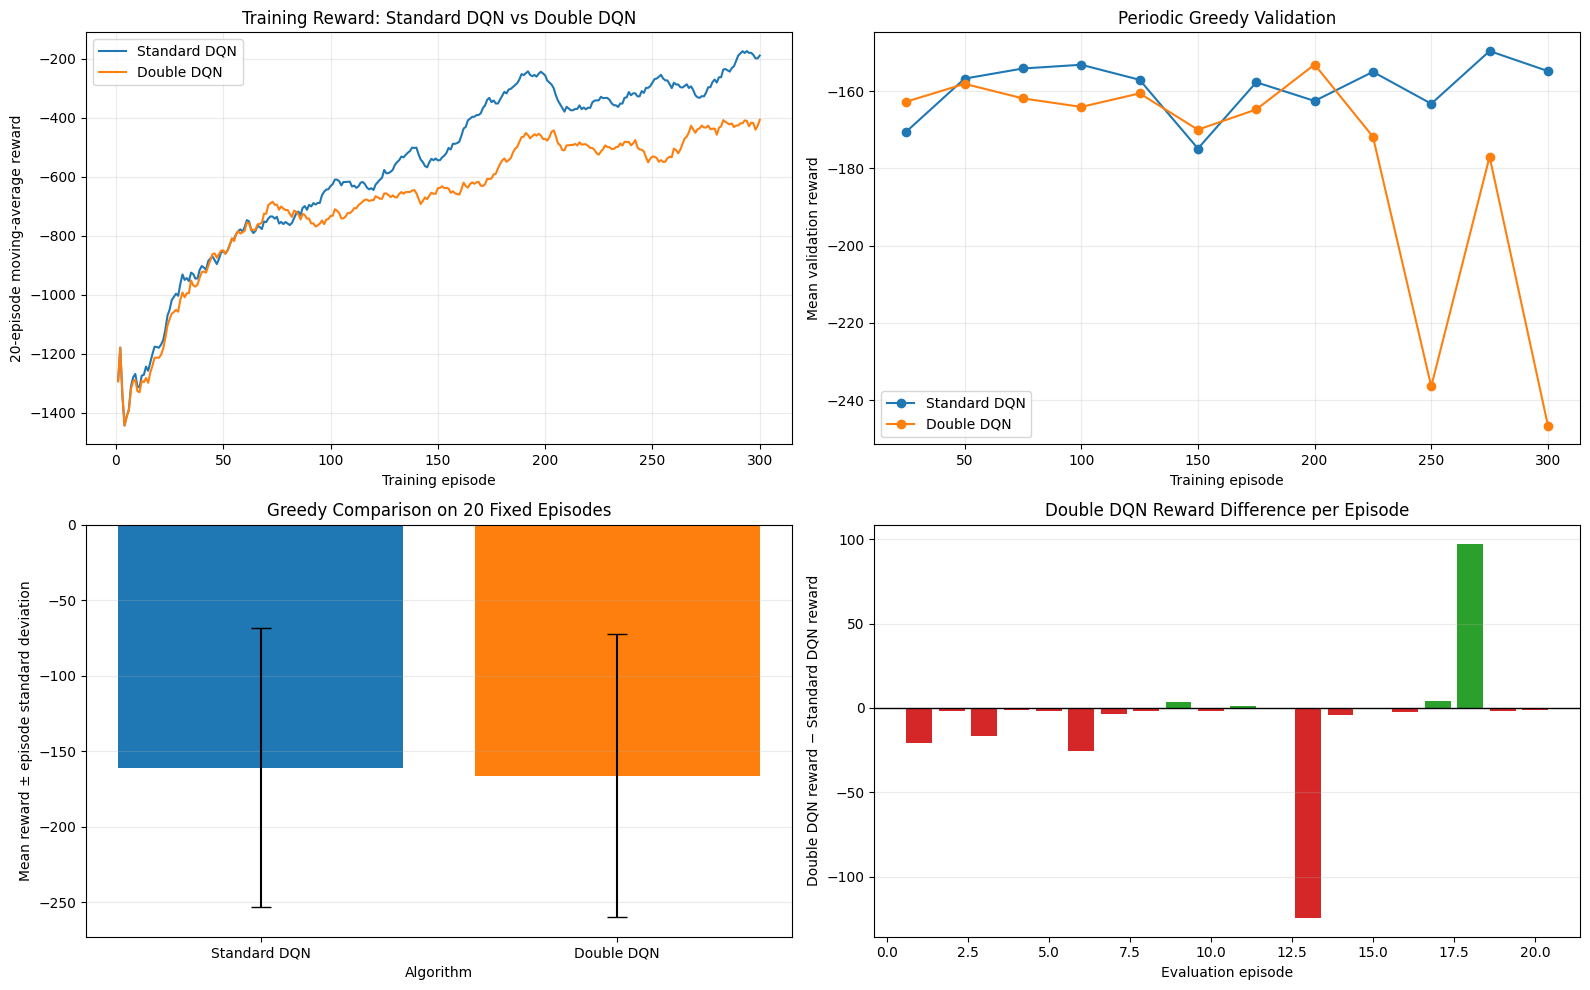

In [55]:
# ---------------------------------------------------------
# Experiment 5: Visualisations
# ---------------------------------------------------------

algorithm_ids = [
    "standard_dqn",
    "double_dqn",
]

algorithm_colours = {
    "standard_dqn": "tab:blue",
    "double_dqn": "tab:orange",
}


fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10),
)


# ---------------------------------------------------------
# Training reward curves
# ---------------------------------------------------------

for algorithm_id in algorithm_ids:
    run_training = (
        algorithm_training_all_dataframe[
            algorithm_training_all_dataframe[
                "algorithm_id"
            ] == algorithm_id
        ]
        .sort_values("episode")
    )

    axes[0, 0].plot(
        run_training["episode"],
        run_training[
            "moving_average_reward"
        ],
        color=algorithm_colours[
            algorithm_id
        ],
        label=ALGORITHM_SETTINGS[
            algorithm_id
        ]["label"],
    )


axes[0, 0].set_title(
    "Training Reward: Standard DQN vs Double DQN"
)

axes[0, 0].set_xlabel(
    "Training episode"
)

axes[0, 0].set_ylabel(
    "20-episode moving-average reward"
)

axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend()


# ---------------------------------------------------------
# Periodic greedy validation
# ---------------------------------------------------------

for algorithm_id in algorithm_ids:
    run_validation = (
        algorithm_validation_all_dataframe[
            algorithm_validation_all_dataframe[
                "algorithm_id"
            ] == algorithm_id
        ]
        .sort_values("training_episode")
    )

    axes[0, 1].plot(
        run_validation["training_episode"],
        run_validation[
            "validation_mean_reward"
        ],
        marker="o",
        color=algorithm_colours[
            algorithm_id
        ],
        label=ALGORITHM_SETTINGS[
            algorithm_id
        ]["label"],
    )


axes[0, 1].set_title(
    "Periodic Greedy Validation"
)

axes[0, 1].set_xlabel(
    "Training episode"
)

axes[0, 1].set_ylabel(
    "Mean validation reward"
)

axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend()


# ---------------------------------------------------------
# Fixed greedy comparison
# ---------------------------------------------------------

results_for_plot = (
    algorithm_results_dataframe
    .set_index("algorithm_id")
    .loc[algorithm_ids]
    .reset_index()
)

positions = np.arange(
    len(results_for_plot)
)


axes[1, 0].bar(
    positions,
    results_for_plot[
        "comparison_mean_reward"
    ],
    yerr=results_for_plot[
        "comparison_reward_std"
    ],
    capsize=7,
    color=[
        algorithm_colours[
            algorithm_id
        ]
        for algorithm_id in (
            results_for_plot[
                "algorithm_id"
            ]
        )
    ],
)


axes[1, 0].set_title(
    f"Greedy Comparison on "
    f"{ALGORITHM_COMPARISON_EPISODES} "
    "Fixed Episodes"
)

axes[1, 0].set_xlabel("Algorithm")

axes[1, 0].set_ylabel(
    "Mean reward ± episode standard deviation"
)

axes[1, 0].set_xticks(positions)

axes[1, 0].set_xticklabels(
    results_for_plot[
        "algorithm_label"
    ]
)

axes[1, 0].grid(
    axis="y",
    alpha=0.25,
)


# ---------------------------------------------------------
# Paired reward difference
# ---------------------------------------------------------

paired_differences = (
    algorithm_paired_dataframe[
        "double_minus_standard"
    ]
)


axes[1, 1].bar(
    algorithm_paired_dataframe[
        "evaluation_episode"
    ],
    paired_differences,
    color=[
        (
            "tab:green"
            if value > 0
            else (
                "tab:red"
                if value < 0
                else "tab:gray"
            )
        )
        for value in paired_differences
    ],
)


axes[1, 1].axhline(
    0,
    color="black",
    linewidth=1,
)


axes[1, 1].set_title(
    "Double DQN Reward Difference per Episode"
)

axes[1, 1].set_xlabel(
    "Evaluation episode"
)

axes[1, 1].set_ylabel(
    "Double DQN reward − Standard DQN reward"
)

axes[1, 1].grid(
    axis="y",
    alpha=0.25,
)


plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "standard_dqn_vs_double_dqn_experiment.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()






### Experiment 5 Evaluation: Standard DQN vs Double DQN

Experiment 5 compared Standard DQN and Double DQN using the same Medium `[128, 128]` architecture with 19,733 trainable parameters. The action discretisation, hyperparameters, training duration, seeds and evaluation episodes were controlled, meaning the main difference was how the target Q-values were calculated.

The training curves show that both algorithms learned substantially during the early episodes. However, Standard DQN continued improving and finished with a moving-average reward near −200, whereas Double DQN plateaued at approximately −400. Standard DQN’s periodic validation rewards also remained relatively stable, generally between −150 and −175. In contrast, Double DQN became unstable during later validation, falling to approximately −237 at episode 250 and −247 at episode 300.

Across the 20 fixed greedy evaluation episodes, Standard DQN achieved the better mean reward:

* **Standard DQN:** −160.89 ± 92.32
* **Double DQN:** −166.10 ± 93.59

Because Pendulum rewards are negative, values closer to zero indicate better performance. Standard DQN therefore outperformed Double DQN by **5.21 mean reward points** and also had slightly lower variability. However, this difference is small relative to the standard deviations, so the mean reward alone does not demonstrate a strong or conclusive advantage.

Both algorithms reached the upright region in **100% of evaluation episodes**, and Double DQN recorded slightly more upright steps on average: **168.40**, compared with **165.65** for Standard DQN. Nevertheless, their ability to maintain balance was substantially different. Standard DQN achieved a **100% balance-success rate** and maintained an average longest balance streak of **159.40 steps**. Double DQN achieved a **0% balance-success rate**, with an average longest streak of only **15.80 steps**. This suggests that Double DQN frequently moved the pendulum into the upright region but could not keep it continuously balanced, whereas Standard DQN learned a much more stable control policy.

The paired evaluation graph further shows considerable episode-level variation. Double DQN strongly outperformed Standard DQN in a small number of episodes, but it also experienced a major negative difference of approximately 125 reward points in another episode. For example, in the first episode, Standard DQN scored −223.88 while Double DQN scored −244.51. This indicates that Double DQN’s performance was less consistently reliable across the fixed starting conditions.

Double DQN is designed to reduce Q-value overestimation by using the online network to select the next action and the target network to evaluate it. However, reducing overestimation does not guarantee better control performance. Under the current hyperparameters and limited 300-episode training duration, Double DQN may have learned more slowly or required separate tuning.

Therefore, **Standard DQN is selected as the better observed algorithm**. It achieved a higher mean reward, more stable learning and, most importantly, substantially better continuous balancing behaviour. Since each algorithm was trained using only one training seed, the result should still be confirmed through multiple independent training runs before concluding that Standard DQN is generally superior.


# Final Selected Default-Gravity Model

## Best Observed Model and Hyperparameters

The final default-gravity model was selected from the completed controlled experiments. Most configurations were trained using one fixed training seed to keep the computational workload manageable. Therefore, this model is described as the best observed configuration under the experiment conditions rather than a model proven to perform best across every possible training seed.

### Experiment-selected settings

| Component | Selected setting |
|---|---|
| Algorithm | Standard DQN |
| Hidden architecture | `[128, 128]` |
| Hidden activation | ReLU |
| Number of discrete actions | 21 |
| Torque range | `-2.0` to `2.0` |
| Epsilon decay | `0.990` per episode |
| Learning rate | `0.003` |
| Training episodes | 300 |
| Maximum steps per episode | 200 |

### Fixed DQN framework settings

| Component | Setting |
|---|---|
| Discount factor | `0.99` |
| Replay capacity | 50,000 transitions |
| Minimum replay size | 1,000 transitions |
| Batch size | 64 |
| Initial epsilon | `1.0` |
| Minimum epsilon | `0.05` |
| Target-network update frequency | Every 250 training updates |
| Gradient clipping norm | `10.0` |
| Optimiser | Adam |
| Loss function | Huber loss |

Standard DQN was selected because it achieved stronger observed comparison performance than Double DQN under default gravity. The `[128, 128]` network achieved the strongest result in the architecture experiment.

The 21-action discretisation, epsilon decay of `0.990` and learning rate of `0.003` were selected from their respective controlled experiments.

The selected saved checkpoint is restored for final evaluation without retraining. The final evaluation episodes are not used to change the model, choose a new checkpoint or update the network weights.

In [52]:
# ============================================================
# RESTORE SELECTED STANDARD-GRAVITY MODEL
# SOURCE: MEDIUM [128, 128] ARCHITECTURE EXPERIMENT
# NO RETRAINING
# ============================================================

# ------------------------------------------------------------
# Locate the previously selected saved weights
# ------------------------------------------------------------

STANDARD_MODEL_DIRECTORY = Path.cwd()

STANDARD_BEST_WEIGHTS_PATH = (
    STANDARD_MODEL_DIRECTORY
    / "medium_128_128.weights.h5"
)


if not STANDARD_BEST_WEIGHTS_PATH.is_file():
    available_weights = sorted(
        STANDARD_MODEL_DIRECTORY.glob(
            "*.weights.h5"
        )
    )

    raise FileNotFoundError(
        "The selected standard-gravity weights file was not found.\n\n"
        "Expected:\n"
        f"{STANDARD_BEST_WEIGHTS_PATH.resolve()}\n\n"
        "Weights files found beside the notebook:\n"
        + (
            "\n".join(
                f"- {path.name}"
                for path in available_weights
            )
            if available_weights
            else "- No .weights.h5 files found"
        )
    )


# ------------------------------------------------------------
# Exact selected standard-gravity configuration
# ------------------------------------------------------------

STANDARD_GRAVITY_VALUE = 10.0
STANDARD_STATE_SIZE = 3

# The original controlled experiment used seed 123.
best_standard_training_seed = 123

STANDARD_ACTION_VALUES = np.linspace(
    -2.0,
    2.0,
    21,
    dtype=np.float32,
)


standard_selected_config = DQNConfig(
    hidden_layers=(128, 128),
    activation="relu",

    learning_rate=0.003,
    gamma=0.99,

    batch_size=64,
    replay_capacity=50_000,
    minimum_replay_size=1_000,

    epsilon_start=1.0,
    epsilon_minimum=0.05,
    epsilon_decay=0.990,

    target_update_frequency=250,
    gradient_clip_norm=10.0,
)


# ------------------------------------------------------------
# Rebuild the exact model architecture
# ------------------------------------------------------------

tf.keras.backend.clear_session()

set_global_seed(
    best_standard_training_seed
)


best_standard_agent = DQNAgent(
    state_size=STANDARD_STATE_SIZE,
    action_values=STANDARD_ACTION_VALUES,
    config=standard_selected_config,

    # The selected standard-gravity algorithm is Standard DQN.
    use_double_dqn=False,
)


# ------------------------------------------------------------
# Verify the architecture before loading
# ------------------------------------------------------------

standard_parameter_count = int(
    best_standard_agent
    .online_network
    .count_params()
)


EXPECTED_STANDARD_PARAMETER_COUNT = 19_733

if (
    standard_parameter_count
    != EXPECTED_STANDARD_PARAMETER_COUNT
):
    raise ValueError(
        "The reconstructed architecture does not match the "
        "selected Medium [128, 128] Standard DQN.\n"
        f"Expected parameters: "
        f"{EXPECTED_STANDARD_PARAMETER_COUNT}\n"
        f"Found parameters: {standard_parameter_count}"
    )


# ------------------------------------------------------------
# Restore the already-trained weights
# ------------------------------------------------------------

best_standard_agent.load_weights(
    STANDARD_BEST_WEIGHTS_PATH
)


# Disable exploration for final evaluation.
best_standard_agent.epsilon = 0.0


print("Selected default-gravity model restored successfully.")
print("Weights:", STANDARD_BEST_WEIGHTS_PATH.name)
print(
    "Configuration: Standard DQN, "
    "[128, 128], 21 actions, epsilon = 0"
)
print("Parameter count:", standard_parameter_count)

Selected standard-gravity model restored successfully.
No retraining was performed.
Ten-seed results were not used for model selection.

Source experiment: Network architecture experiment
Gravity: 10.0
Algorithm: Standard DQN
Architecture: [128, 128]
Parameter count: 19733
Training seed: 123
Discrete actions: 21
Torque range: (-2.0, 2.0)
Evaluation epsilon: 0.0
Loaded weights: C:\Users\ASUS\Deep Learning CA2\medium_128_128.weights.h5


# Final Best-Agent Restoration and Playback Evaluation

The final evaluation restores the previously saved checkpoints selected during the controlled experiments. No model is retrained during this stage.

For each completed gravity condition, the agent is rebuilt using the same architecture and hyperparameter
s used during training. The saved weights are then loaded from disk and evaluated greedily with exploration disabled.

The final evaluation does not perform replay-buffer updates, gradient updates, checkpoint selection or model saving. Its purpose is only to measure and demonstrate the behaviour of the already selected agents.

In [21]:
# ============================================================
# FINAL STANDARD-GRAVITY EVALUATION
# RESTORED MEDIUM [128, 128] STANDARD DQN
# 10 NEW GREEDY EPISODES — NO RETRAINING
# ============================================================


# ------------------------------------------------------------
# Evaluation configuration
# ------------------------------------------------------------

STANDARD_FINAL_EVALUATION_EPISODES = 10
STANDARD_FINAL_EVALUATION_SEED = 4_100_001
STANDARD_FINAL_MAX_STEPS = 200


if STANDARD_FINAL_EVALUATION_EPISODES < 10:
    raise ValueError(
        "The final evaluation must use at least 10 episodes."
    )

# ------------------------------------------------------------
# Disable exploration
# ------------------------------------------------------------

best_standard_agent.epsilon = 0.0


# ------------------------------------------------------------
# Create the standard-gravity environment
# ------------------------------------------------------------

standard_final_evaluation_env = create_pendulum_env(
    gravity=STANDARD_GRAVITY_VALUE,
    seed=STANDARD_FINAL_EVALUATION_SEED,
)


actual_standard_gravity = float(
    standard_final_evaluation_env.unwrapped.g
)


if not np.isclose(
    actual_standard_gravity,
    10.0,
):
    standard_final_evaluation_env.close()

    raise ValueError(
        "The final evaluation environment is not using "
        f"standard gravity. Found g = {actual_standard_gravity}."
    )


# ------------------------------------------------------------
# Evaluate the fixed restored model
# ------------------------------------------------------------

try:
    standard_final_result = evaluate_agent(
        env=standard_final_evaluation_env,
        agent=best_standard_agent,

        episodes=STANDARD_FINAL_EVALUATION_EPISODES,
        max_steps=STANDARD_FINAL_MAX_STEPS,
        seed=STANDARD_FINAL_EVALUATION_SEED,

        # No checkpoint selection or saving occurs here.
        best_score=None,
        save_path=None,

        verbose=True,
    )

finally:
    standard_final_evaluation_env.close()


# ------------------------------------------------------------
# Overall quantitative summary
# ------------------------------------------------------------

standard_final_summary = pd.DataFrame([
    {
        "gravity_condition": "Standard gravity",
        "gravity": actual_standard_gravity,

        "source_experiment": (
            "Network architecture experiment"
        ),

        "source_weights": (
            "medium_128_128.weights.h5"
        ),

        "architecture_selection_basis": (
           "Highest mean return on the fixed "
           "architecture comparison episodes"
        ),

          "checkpoint_selection_basis": (
          "Best periodic-validation checkpoint "
         "within the selected architecture"
       ),
        "algorithm": "Standard DQN",
        "architecture": "[128, 128]",

        "restored_training_seed": (
            best_standard_training_seed
        ),

        "evaluation_episodes": (
            STANDARD_FINAL_EVALUATION_EPISODES
        ),

        "first_evaluation_seed": (
            STANDARD_FINAL_EVALUATION_SEED
        ),

        "last_evaluation_seed": (
            STANDARD_FINAL_EVALUATION_SEED
            + STANDARD_FINAL_EVALUATION_EPISODES
            - 1
        ),

        "mean_reward": float(
            standard_final_result[
                "mean_reward"
            ]
        ),

        "reward_std": float(
            standard_final_result[
                "reward_std"
            ]
        ),

        "minimum_reward": float(
            standard_final_result[
                "minimum_reward"
            ]
        ),

        "maximum_reward": float(
            standard_final_result[
                "maximum_reward"
            ]
        ),

        "reached_upright_rate": float(
            standard_final_result[
                "reached_upright_rate"
            ]
        ),

        "balance_success_rate": float(
            standard_final_result[
                "balance_success_rate"
            ]
        ),

        "mean_upright_steps": float(
            standard_final_result[
                "mean_upright_steps"
            ]
        ),

        "mean_longest_balance_streak": float(
            standard_final_result[
                "mean_longest_balance_streak"
            ]
        ),
    }
])


# ------------------------------------------------------------
# Episode-level results
# ------------------------------------------------------------

standard_final_episode_results = pd.DataFrame(
    standard_final_result[
        "episode_metrics"
    ]
)


standard_final_episode_results.insert(
    0,
    "gravity_condition",
    "Standard gravity",
)

standard_final_episode_results.insert(
    1,
    "gravity",
    actual_standard_gravity,
)

standard_final_episode_results.insert(
    2,
    "restored_training_seed",
    best_standard_training_seed,
)


# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------

if (
    len(standard_final_episode_results)
    != STANDARD_FINAL_EVALUATION_EPISODES
):
    raise RuntimeError(
        "The number of episode results does not match "
        "the requested evaluation episode count."
    )


if not np.isfinite(
    standard_final_episode_results[
        "reward"
    ].to_numpy(dtype=np.float64)
).all():
    raise FloatingPointError(
        "The evaluation produced a non-finite reward."
    )


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print(
    "\nFinal standard-gravity restored-agent evaluation"
)

print(
    "-------------------------------------------------"
)

print(
    "Source weights: medium_128_128.weights.h5"
)

print(
    "Source experiment: Network architecture experiment"
)

print(
    "Restored training seed:",
    best_standard_training_seed,
)

print(
    "Evaluation episodes:",
    STANDARD_FINAL_EVALUATION_EPISODES,
)

print(
    "Gravity:",
    actual_standard_gravity,
)


display(
    standard_final_summary.round(3)
)

display(
    standard_final_episode_results.round(3)
)


Evaluation results
------------------
Episodes: 10
Mean reward: -118.57
Reward standard deviation: 71.77
Minimum reward: -229.35
Maximum reward: -0.77
Reached upright: 100.0%
Stable-balance success rate: 100.0%
Mean longest stable streak: 166.60 steps

Final standard-gravity restored-agent evaluation
-------------------------------------------------
Source weights: medium_128_128.weights.h5
Source experiment: Network architecture experiment
Restored training seed: 123
Evaluation episodes: 10
Gravity: 10.0
Training performed: No
Weights updated: No
Exploration used: No
Model selected using these results: No
Files saved by this cell: No


,gravity_condition,gravity,source_experiment,source_weights,selection_basis,algorithm,architecture,restored_training_seed,evaluation_episodes,first_evaluation_seed,last_evaluation_seed,mean_reward,reward_std,minimum_reward,maximum_reward,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,Standard gravity,10.0,Network architecture experiment,medium_128_128.weights.h5,Best validation checkpoint,Standard DQN,"[128, 128]",123,10,4100001,4100010,-118.571,71.773,-229.352,-0.771,1.0,1.0,173.7,166.6


,gravity_condition,gravity,restored_training_seed,evaluation_episode,evaluation_seed,reward,steps_completed,reached_upright,upright_steps,first_upright_step,longest_balance_streak,balance_success
0,Standard gravity,10.0,123,1,4100001,-119.405,200,True,172,29,168,True
1,Standard gravity,10.0,123,2,4100002,-0.771,200,True,200,1,199,True
2,Standard gravity,10.0,123,3,4100003,-2.462,200,True,192,9,187,True
3,Standard gravity,10.0,123,4,4100004,-123.424,200,True,174,24,159,True
4,Standard gravity,10.0,123,5,4100005,-124.448,200,True,175,26,158,True
5,Standard gravity,10.0,123,6,4100006,-227.229,200,True,156,45,151,True
6,Standard gravity,10.0,123,7,4100007,-229.352,200,True,157,44,153,True
7,Standard gravity,10.0,123,8,4100008,-117.639,200,True,168,33,159,True
8,Standard gravity,10.0,123,9,4100009,-122.683,200,True,171,30,165,True
9,Standard gravity,10.0,123,10,4100010,-118.298,200,True,172,29,167,True


Standard-gravity final evaluation
---------------------------------
Episodes: 10
Mean reward: -118.571
Reward standard deviation: 71.773
Minimum reward: -229.352
Maximum reward: -0.771
Mean upright steps: 173.7
Mean first upright step: 27.0
Mean longest balance streak: 166.6


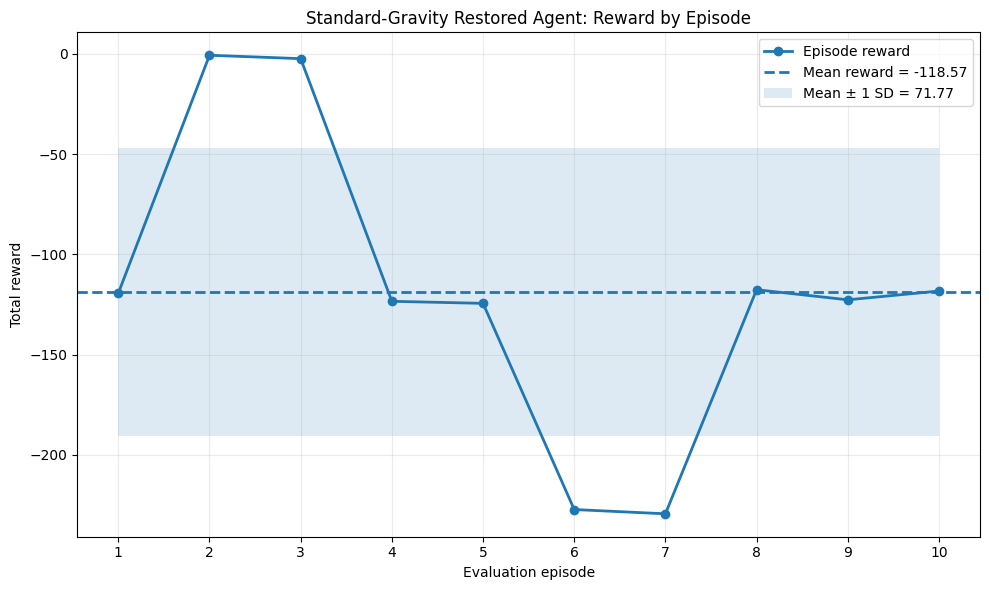

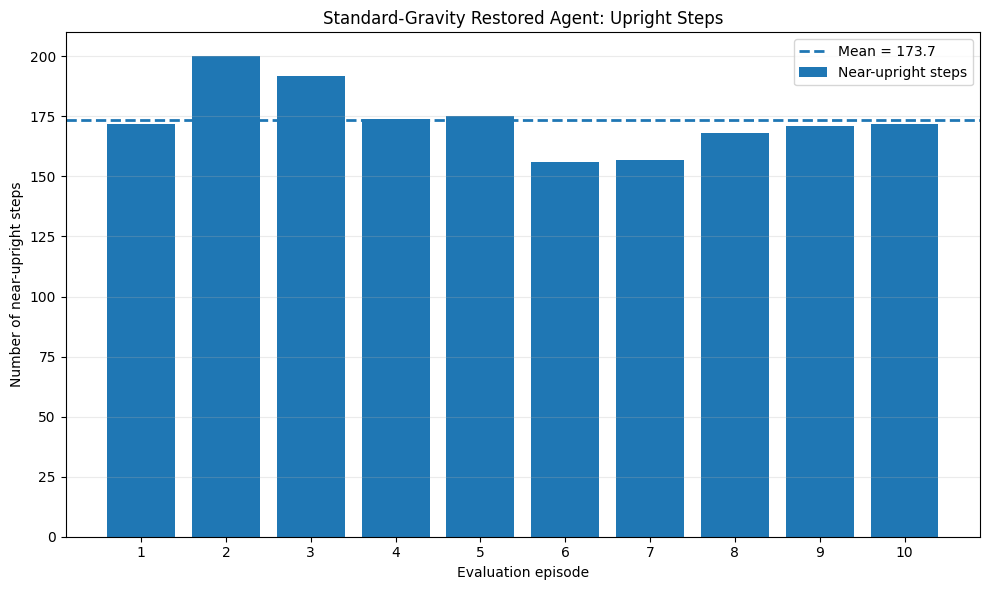

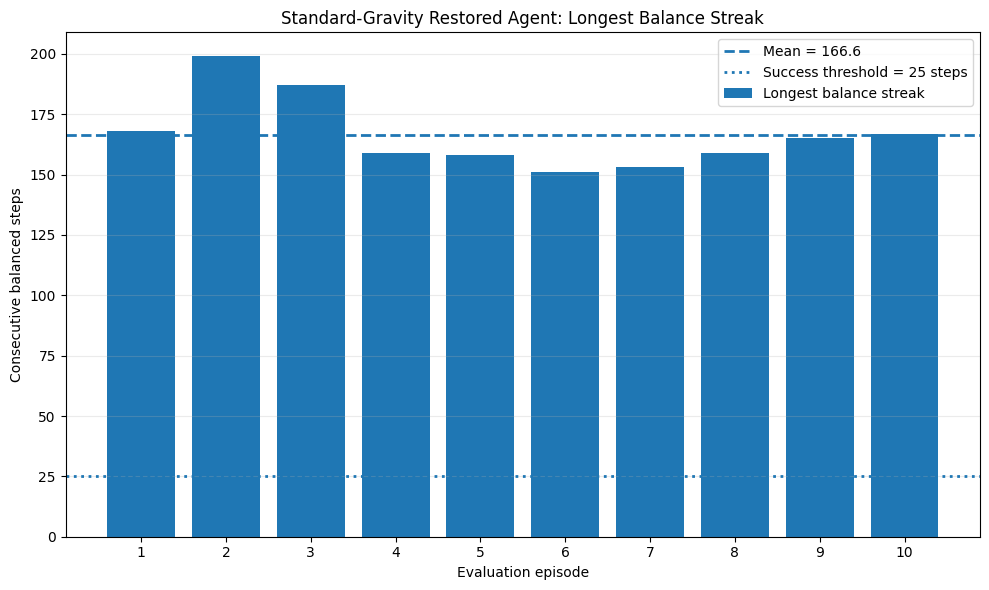

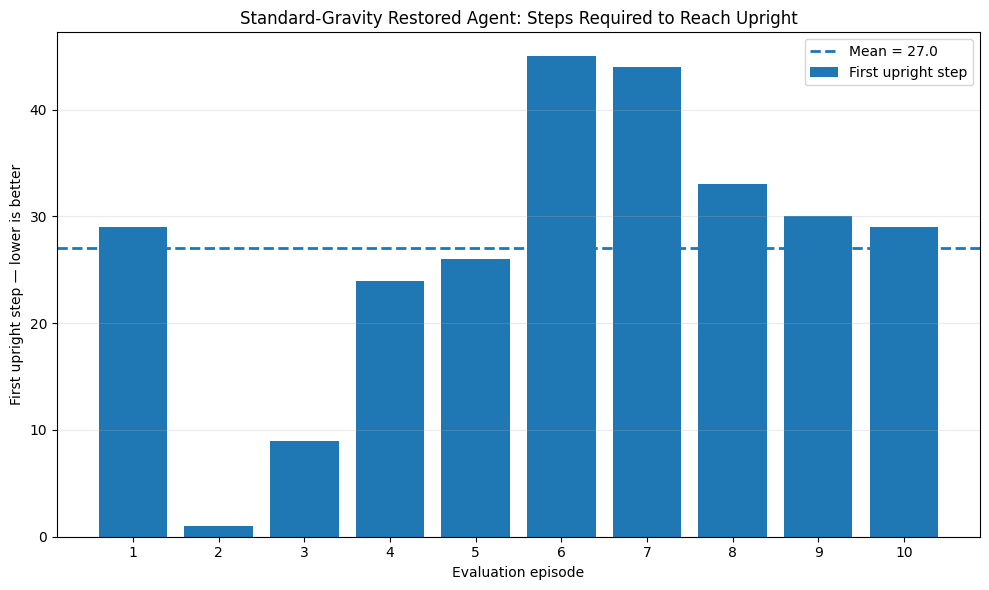

In [22]:
# ============================================================
# STANDARD-GRAVITY FINAL EVALUATION VISUALISATIONS
# PLOTS ONLY — NOTHING IS SAVED
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


if "standard_final_episode_results" not in globals():
    raise NameError(
        "standard_final_episode_results is not defined. "
        "Run the 10-episode standard-gravity evaluation first."
    )


standard_plot_results = (
    standard_final_episode_results
    .copy()
    .reset_index(drop=True)
)


required_columns = [
    "evaluation_episode",
    "reward",
    "upright_steps",
    "first_upright_step",
    "longest_balance_streak",
]

missing_columns = [
    column
    for column in required_columns
    if column not in standard_plot_results.columns
]

if missing_columns:
    raise KeyError(
        "The evaluation table is missing:\n"
        + "\n".join(
            f"- {column}"
            for column in missing_columns
        )
    )


episodes = standard_plot_results[
    "evaluation_episode"
]

rewards = standard_plot_results[
    "reward"
]

upright_steps = standard_plot_results[
    "upright_steps"
]

first_upright_steps = standard_plot_results[
    "first_upright_step"
]

balance_streaks = standard_plot_results[
    "longest_balance_streak"
]


mean_reward = float(rewards.mean())
reward_std = float(rewards.std(ddof=0))

mean_upright_steps = float(
    upright_steps.mean()
)

mean_first_upright_step = float(
    first_upright_steps.mean()
)

mean_balance_streak = float(
    balance_streaks.mean()
)


print("Standard-gravity final evaluation")
print("---------------------------------")
print("Episodes:", len(standard_plot_results))
print(f"Mean reward: {mean_reward:.3f}")
print(f"Reward standard deviation: {reward_std:.3f}")
print(f"Minimum reward: {rewards.min():.3f}")
print(f"Maximum reward: {rewards.max():.3f}")
print(f"Mean upright steps: {mean_upright_steps:.1f}")
print(
    "Mean first upright step:",
    f"{mean_first_upright_step:.1f}",
)
print(
    "Mean longest balance streak:",
    f"{mean_balance_streak:.1f}",
)


# ------------------------------------------------------------
# 1. Reward by evaluation episode
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    episodes,
    rewards,
    marker="o",
    linewidth=2,
    label="Episode reward",
)

plt.axhline(
    mean_reward,
    linestyle="--",
    linewidth=2,
    label=f"Mean reward = {mean_reward:.2f}",
)

plt.fill_between(
    episodes,
    mean_reward - reward_std,
    mean_reward + reward_std,
    alpha=0.15,
    label=f"Mean ± 1 SD = {reward_std:.2f}",
)

plt.title(
    "Standard-Gravity Restored Agent: Reward by Episode"
)

plt.xlabel("Evaluation episode")
plt.ylabel("Total reward")

plt.xticks(episodes)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. Upright steps by episode
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    episodes,
    upright_steps,
    label="Near-upright steps",
)

plt.axhline(
    mean_upright_steps,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_upright_steps:.1f}",
)

plt.title(
    "Standard-Gravity Restored Agent: Upright Steps"
)

plt.xlabel("Evaluation episode")
plt.ylabel("Number of near-upright steps")

plt.xticks(episodes)
plt.ylim(bottom=0)
plt.grid(axis="y", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Longest continuous balance streak
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    episodes,
    balance_streaks,
    label="Longest balance streak",
)

plt.axhline(
    mean_balance_streak,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_balance_streak:.1f}",
)

plt.axhline(
    BALANCE_REQUIRED_STREAK,
    linestyle=":",
    linewidth=2,
    label=(
        "Success threshold = "
        f"{BALANCE_REQUIRED_STREAK} steps"
    ),
)

plt.title(
    "Standard-Gravity Restored Agent: "
    "Longest Balance Streak"
)

plt.xlabel("Evaluation episode")
plt.ylabel("Consecutive balanced steps")

plt.xticks(episodes)
plt.ylim(bottom=0)
plt.grid(axis="y", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Steps required to first reach upright
# Lower is better
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.bar(
    episodes,
    first_upright_steps,
    label="First upright step",
)

plt.axhline(
    mean_first_upright_step,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_first_upright_step:.1f}",
)

plt.title(
    "Standard-Gravity Restored Agent: "
    "Steps Required to Reach Upright"
)

plt.xlabel("Evaluation episode")
plt.ylabel("First upright step — lower is better")

plt.xticks(episodes)
plt.ylim(bottom=0)
plt.grid(axis="y", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

In [53]:
import time


STANDARD_VIDEO_EPISODES = 10
STANDARD_VIDEO_MAX_STEPS = 200
STANDARD_VIDEO_FRAME_DELAY = 1 / 30

STANDARD_VIDEO_SEEDS = [
    5_100_001,
    5_100_002,
    5_100_003,
    5_100_004,
    5_100_005,
    5_100_006,
    5_100_007,
    5_100_008,
    5_100_009,
    5_100_010,
]


best_standard_agent.epsilon = 0.0

standard_video_env = create_pendulum_env(
    gravity=STANDARD_GRAVITY_VALUE,
    seed=STANDARD_VIDEO_SEEDS[0],
)


try:
    time.sleep(3)

    for episode_seed in STANDARD_VIDEO_SEEDS:
        standard_video_env.seed(episode_seed)
        standard_video_env.action_space.seed(episode_seed)

        state = standard_video_env.reset()
        standard_video_env.render()

        for _ in range(STANDARD_VIDEO_MAX_STEPS):
            action_index = best_standard_agent.select_action(
                state,
                training=False,
            )

            torque = best_standard_agent.action_index_to_torque(
                action_index
            )

            state, _, done, _ = standard_video_env.step(
                torque
            )

            standard_video_env.render()
            time.sleep(STANDARD_VIDEO_FRAME_DELAY)

            if done:
                break

        time.sleep(1)

    time.sleep(2)

finally:
    standard_video_env.close()

## Final Evaluation of the Restored Standard-Gravity Agent

The final standard-gravity evaluation used the previously saved medium_128_128.weights.h5 checkpoint from the network-architecture experiment.

The [128, 128] architecture was selected because it achieved the strongest mean return on the fixed architecture-comparison episodes. Within that architecture's training run, the restored file was the checkpoint that achieved the best periodic-validation mean return.

The restored agent used Standard DQN, 21 discretised torque actions and the default Pendulum gravity of g=10. The original controlled training seed was 123.

The weights were restored after training had finished and exploration was disabled by setting epsilon to zero. No retraining, replay-buffer updates, gradient updates, weight updates or further checkpoint selection occurred during this evaluation.

Quantitative Evaluation Results

The fixed agent was evaluated over ten new greedy episodes. Each episode contained 200 environment steps and used a different evaluation seed.

* Evaluation episodes: 10
* Mean reward: -118.571
* Reward standard deviation: 71.773
* Minimum reward: -229.352
* Maximum reward: -0.771
* Reached-upright rate: 100%
* Balance-success rate: 100%
* Mean upright steps: 173.7 out of 200
* Mean first upright step: 27.0
* Mean longest balance streak: 166.6 steps

In the Pendulum environment, rewards are negative, with values closer to zero representing better control. The agent achieved a mean reward of -118.571. However, the standard deviation of 71.773 indicates noticeable variation between episodes.

Episodes 2 and 3 achieved rewards of -0.771 and -2.462, respectively. These were the strongest episodes. The pendulum reached the upright region at step 1 in Episode 2 and step 9 in Episode 3, after which the agent maintained control for almost the entire episode.

Episodes 6 and 7 produced the lowest rewards of -227.229 and -229.352. In these episodes, the pendulum first reached upright at steps 45 and 44. Consequently, more negative reward was accumulated during the longer initial swing-up period.

The remaining episodes achieved rewards between approximately -117 and -124. Their first upright steps generally occurred between steps 24 and 33, showing a moderate but consistent swing-up time.

Upright and Balance Performance

The agent reached the upright region in all ten episodes, producing a 100% reached-upright rate. It remained near upright for an average of 173.7 out of 200 steps, equivalent to approximately 86.9% of each episode.

The mean longest continuous balance streak was 166.6 steps. Every episode exceeded the required balance-success threshold of 25 consecutive steps, resulting in a 100% balance-success rate.

Even the two lowest-reward episodes still achieved longest balance streaks of 151 and 153 steps. Their weak reward values therefore did not represent failed control. Instead, the lower rewards were mainly caused by a slower initial swing-up before stable balancing began.

These behavioural measurements provide important context for interpreting the reward plot. Although total reward varied substantially across initial states, the agent was consistently able to reach upright and maintain balance once the target position had been reached.

Ten-Episode Visual Playback

The restored agent was also demonstrated over ten separately seeded rendered episodes using new playback episode-reset seeds. Exploration remained disabled, and no learning or weight updates occurred during playback.

The playback was used as visual evidence to confirm that the restored agent could repeatedly swing the pendulum towards the upright position and maintain control from different starting states.

The rendered episodes supported the separate quantitative evaluation. The agent generally maintained stable balance after reaching the target position, although the time required to complete the initial swing-up varied between starting states.

Final Standard-Gravity Assessment

The restored Medium [128, 128] Standard DQN agent demonstrated reliable standard-gravity control. It reached upright and passed the balance-success criterion in every quantitative and rendered episode.

Its main strength was the ability to maintain long continuous balance periods after reaching the target position. Its main limitation was inconsistent swing-up speed. Favourable initial states were solved almost immediately, whereas more difficult initial states required approximately 44 to 47 steps to reach upright and therefore produced substantially lower rewards.

Overall, the agent can be considered a successful standard-gravity controller. The 100% reached-upright and balance-success rates demonstrate consistent task completion, while the high reward standard deviation shows that swing-up efficiency could still be improved.

Because the selected configuration was trained using one controlled training seed, the results identify the best observed configuration under the current experimental conditions. Sensitivity to different training initialisations remains a limitation of this evaluation.


# Anti-gravity

The anti-gravity experiments follow this sequence:

1. number of discrete torque actions;
2. epsilon-decay strategy;
3. learning rate;
4. Standard DQN versus Double DQN;
5. neural-network architecture; and
6. final checkpoint restoration and evaluation.

Each controlled comparison changes one main factor while keeping the previously selected settings fixed. Most configurations are trained using one controlled training seed. Fixed validation and comparison seeds are reused within each experiment to provide consistent starting conditions.

Because the configurations are not retrained across multiple independent training seeds, the selected model is described as the best observed anti-gravity configuration under the experiment conditions.

In [62]:
# ---------------------------------------------------------
# Anti-gravity shared experiment setup
# ---------------------------------------------------------

ANTI_GRAVITY_VALUE = -10.0

assert np.isclose(
    GRAVITY_SETUPS["setup_3_anti_gravity"],
    ANTI_GRAVITY_VALUE,
), (
    "The anti-gravity setup must use g = -10.0."
)


# Separate folders prevent normal-gravity outputs from
# being overwritten.
ANTI_RESULTS_DIR = (
    RESULTS_DIR / "anti_gravity"
)

ANTI_WEIGHTS_DIR = (
    WEIGHTS_DIR / "anti_gravity"
)

ANTI_FIGURES_DIR = (
    FIGURES_DIR / "anti_gravity"
)

ANTI_ACTION_RESULTS_DIR = (
    ANTI_RESULTS_DIR / "action_count_experiment"
)

ANTI_ACTION_WEIGHTS_DIR = (
    ANTI_WEIGHTS_DIR / "action_count_experiment"
)


for directory in [
    ANTI_RESULTS_DIR,
    ANTI_WEIGHTS_DIR,
    ANTI_FIGURES_DIR,
    ANTI_ACTION_RESULTS_DIR,
    ANTI_ACTION_WEIGHTS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ---------------------------------------------------------
# Controlled seed and evaluation settings
# ---------------------------------------------------------

ANTI_ACTION_TRAINING_SEED = 123

ANTI_ACTION_VALIDATION_SEED = 30_000
ANTI_ACTION_COMPARISON_SEED = 40_000

ANTI_ACTION_TRAINING_EPISODES = 300
ANTI_ACTION_MAX_STEPS = 200

ANTI_ACTION_EVALUATION_EVERY = 25
ANTI_ACTION_VALIDATION_EPISODES = 20
ANTI_ACTION_COMPARISON_EPISODES = 20


# ---------------------------------------------------------
# Verify the environment
# ---------------------------------------------------------

anti_check_env = create_pendulum_env(
    gravity=ANTI_GRAVITY_VALUE,
    seed=ANTI_ACTION_TRAINING_SEED,
)

ANTI_STATE_SIZE = int(
    anti_check_env.observation_space.shape[0]
)

anti_initial_state = anti_check_env.reset()

assert ANTI_STATE_SIZE == 3
assert np.isclose(
    float(anti_check_env.unwrapped.g),
    -10.0,
)

print("Environment: Pendulum-v0")
print(
    "Confirmed gravity:",
    float(anti_check_env.unwrapped.g),
)
print(
    "Observation size:",
    ANTI_STATE_SIZE,
)
print(
    "Initial state:",
    anti_initial_state,
)
print(
    "Action limits:",
    anti_check_env.action_space.low,
    "to",
    anti_check_env.action_space.high,
)

anti_check_env.close()

Environment: Pendulum-v0
Confirmed gravity: -10.0
Observation size: 3
Initial state: [ 0.26159258  0.96517839 -0.26024719]
Action limits: [-2.] to [2.]


In [63]:
# ---------------------------------------------------------
# Anti-gravity Experiment 1: Number of actions
# ---------------------------------------------------------

ANTI_ACTION_COUNTS = [
    5,
    9,
    11,
    21,
    41,
]


# Same controlled starting configuration used in the
# normal-gravity action-count experiment.
ANTI_ACTION_BASE_CONFIG = DQNConfig(
    hidden_layers=(64, 64),
    activation="relu",

    learning_rate=0.001,
    gamma=0.99,

    batch_size=64,
    replay_capacity=50_000,
    minimum_replay_size=1_000,

    epsilon_start=1.0,
    epsilon_minimum=0.05,
    epsilon_decay=0.995,

    target_update_frequency=250,
    gradient_clip_norm=10.0,
)


# ---------------------------------------------------------
# Verify every action mapping
# ---------------------------------------------------------

anti_action_mapping_records = []

for action_count in ANTI_ACTION_COUNTS:
    action_values = np.linspace(
        -2.0,
        2.0,
        action_count,
        dtype=np.float32,
    )

    assert np.isclose(
        action_values[0],
        -2.0,
    )

    assert np.isclose(
        action_values[-1],
        2.0,
    )

    assert np.any(
        np.isclose(
            action_values,
            0.0,
        )
    )

    anti_action_mapping_records.append({
        "gravity": ANTI_GRAVITY_VALUE,
        "action_count": action_count,

        "torque_gap": float(
            action_values[1]
            - action_values[0]
        ),

        "minimum_torque": float(
            action_values[0]
        ),

        "contains_zero": bool(
            np.any(
                np.isclose(
                    action_values,
                    0.0,
                )
            )
        ),

        "maximum_torque": float(
            action_values[-1]
        ),

        "output_neurons": action_count,
    })


anti_action_mapping_dataframe = pd.DataFrame(
    anti_action_mapping_records
)

print(
    "Anti-gravity action-count experiment"
)

print(
    "Training seed:",
    ANTI_ACTION_TRAINING_SEED,
)

print(
    "Total new training runs:",
    len(ANTI_ACTION_COUNTS),
)

display(
    anti_action_mapping_dataframe.round(3)
)

Anti-gravity action-count experiment
Training seed: 123
Total new training runs: 5


,gravity,action_count,torque_gap,minimum_torque,contains_zero,maximum_torque,output_neurons
0,-10.0,5,1.0,-2.0,True,2.0,5
1,-10.0,9,0.5,-2.0,True,2.0,9
2,-10.0,11,0.4,-2.0,True,2.0,11
3,-10.0,21,0.2,-2.0,True,2.0,21
4,-10.0,41,0.1,-2.0,True,2.0,41


In [64]:
# ---------------------------------------------------------
# Separate paths for each anti-gravity action count
# ---------------------------------------------------------

def get_anti_action_run_paths(
    action_count,
):
    run_name = (
        f"actions_{int(action_count):02d}_"
        f"seed_{ANTI_ACTION_TRAINING_SEED}"
    )

    return {
        "weights": (
            ANTI_ACTION_WEIGHTS_DIR
            / f"{run_name}.weights.h5"
        ),

        "training": (
            ANTI_ACTION_RESULTS_DIR
            / f"{run_name}_training.csv"
        ),

        "validation": (
            ANTI_ACTION_RESULTS_DIR
            / f"{run_name}_validation.csv"
        ),

        "checkpoint": (
            ANTI_ACTION_RESULTS_DIR
            / f"{run_name}_checkpoint.csv"
        ),

        "comparison": (
            ANTI_ACTION_RESULTS_DIR
            / f"{run_name}_comparison.csv"
        ),
    }


ANTI_ACTION_RUN_PATHS = {
    action_count: get_anti_action_run_paths(
        action_count
    )
    for action_count in ANTI_ACTION_COUNTS
}


anti_action_path_records = []

for action_count in ANTI_ACTION_COUNTS:
    run_paths = ANTI_ACTION_RUN_PATHS[
        action_count
    ]

    anti_action_path_records.append({
        "action_count": action_count,
        "weights_file": (
            run_paths["weights"].name
        ),
        "training_file": (
            run_paths["training"].name
        ),
        "validation_file": (
            run_paths["validation"].name
        ),
        "checkpoint_file": (
            run_paths["checkpoint"].name
        ),
    })


anti_action_paths_dataframe = pd.DataFrame(
    anti_action_path_records
)

display(anti_action_paths_dataframe)

,action_count,weights_file,training_file,validation_file,checkpoint_file
0,5,actions_05_seed_123.weights.h5,actions_05_seed_123_training.csv,actions_05_seed_123_validation.csv,actions_05_seed_123_checkpoint.csv
1,9,actions_09_seed_123.weights.h5,actions_09_seed_123_training.csv,actions_09_seed_123_validation.csv,actions_09_seed_123_checkpoint.csv
2,11,actions_11_seed_123.weights.h5,actions_11_seed_123_training.csv,actions_11_seed_123_validation.csv,actions_11_seed_123_checkpoint.csv
3,21,actions_21_seed_123.weights.h5,actions_21_seed_123_training.csv,actions_21_seed_123_validation.csv,actions_21_seed_123_checkpoint.csv
4,41,actions_41_seed_123.weights.h5,actions_41_seed_123_training.csv,actions_41_seed_123_validation.csv,actions_41_seed_123_checkpoint.csv


In [65]:
# ---------------------------------------------------------
# Train five fresh Standard DQN models under anti-gravity
# ---------------------------------------------------------

for run_number, action_count in enumerate(
    ANTI_ACTION_COUNTS,
    start=1,
):
    run_paths = ANTI_ACTION_RUN_PATHS[
        action_count
    ]

    required_training_paths = [
        run_paths["weights"],
        run_paths["training"],
        run_paths["validation"],
        run_paths["checkpoint"],
    ]

    run_is_complete = all(
        path.exists()
        for path in required_training_paths
    )

    if run_is_complete:
        print(
            f"Run {run_number}/5 | "
            f"{action_count} actions: "
            "saved training results already exist."
        )
        continue

    print("\n" + "=" * 70)

    print(
        f"ANTI-GRAVITY RUN {run_number}/5 | "
        f"{action_count} ACTIONS"
    )

    print("=" * 70)

    tf.keras.backend.clear_session()

    set_global_seed(
        ANTI_ACTION_TRAINING_SEED
    )

    anti_training_env = None
    anti_validation_env = None
    anti_action_agent = None

    try:
        action_values = np.linspace(
            -2.0,
            2.0,
            action_count,
            dtype=np.float32,
        )

        anti_training_env = (
            create_pendulum_env(
                gravity=ANTI_GRAVITY_VALUE,
                seed=ANTI_ACTION_TRAINING_SEED,
            )
        )

        anti_validation_env = (
            create_pendulum_env(
                gravity=ANTI_GRAVITY_VALUE,
                seed=ANTI_ACTION_VALIDATION_SEED,
            )
        )

        anti_action_agent = DQNAgent(
            state_size=ANTI_STATE_SIZE,
            action_values=action_values,
            config=ANTI_ACTION_BASE_CONFIG,

            # Standard DQN is fixed during
            # the action-count experiment.
            use_double_dqn=False,
        )

        (
            anti_action_history,
            anti_action_training_dataframe,
        ) = train_agent(
            env=anti_training_env,
            agent=anti_action_agent,

            episodes=(
                ANTI_ACTION_TRAINING_EPISODES
            ),

            max_steps=(
                ANTI_ACTION_MAX_STEPS
            ),

            moving_average_window=20,
            seed=ANTI_ACTION_TRAINING_SEED,

            evaluation_env=(
                anti_validation_env
            ),

            evaluation_every=(
                ANTI_ACTION_EVALUATION_EVERY
            ),

            evaluation_episodes=(
                ANTI_ACTION_VALIDATION_EPISODES
            ),

            evaluation_seed=(
                ANTI_ACTION_VALIDATION_SEED
            ),

            best_weights_path=(
                run_paths["weights"]
            ),

            print_every=25,
            render_every=None,
        )

        # ---------------------------------------------
        # Save complete training history
        # ---------------------------------------------

        anti_action_training_dataframe.insert(
            0,
            "training_seed",
            ANTI_ACTION_TRAINING_SEED,
        )

        anti_action_training_dataframe.insert(
            0,
            "action_count",
            action_count,
        )

        anti_action_training_dataframe.insert(
            0,
            "gravity",
            ANTI_GRAVITY_VALUE,
        )

        anti_action_training_dataframe.to_csv(
            run_paths["training"],
            index=False,
        )

        # ---------------------------------------------
        # Save periodic greedy-validation history
        # ---------------------------------------------

        anti_action_validation_dataframe = (
            pd.DataFrame({
                "gravity": (
                    ANTI_GRAVITY_VALUE
                ),

                "action_count": (
                    action_count
                ),

                "training_seed": (
                    ANTI_ACTION_TRAINING_SEED
                ),

                "training_episode": (
                    anti_action_history[
                        "evaluation_episode"
                    ]
                ),

                "validation_mean_reward": (
                    anti_action_history[
                        "evaluation_mean_reward"
                    ]
                ),

                "validation_reward_std": (
                    anti_action_history[
                        "evaluation_reward_std"
                    ]
                ),
            })
        )

        anti_action_validation_dataframe.to_csv(
            run_paths["validation"],
            index=False,
        )

        # ---------------------------------------------
        # Record the checkpoint chosen by validation
        # ---------------------------------------------

        if len(
            anti_action_history[
                "evaluation_mean_reward"
            ]
        ) == 0:
            raise RuntimeError(
                "No validation results were produced."
            )

        best_position = int(
            np.argmax(
                anti_action_history[
                    "evaluation_mean_reward"
                ]
            )
        )

        anti_checkpoint_dataframe = pd.DataFrame([
            {
                "gravity": ANTI_GRAVITY_VALUE,
                "action_count": action_count,

                "training_seed": (
                    ANTI_ACTION_TRAINING_SEED
                ),

                "algorithm": "Standard DQN",
                "architecture": "[64, 64]",

                "parameter_count": int(
                    anti_action_agent
                    .online_network
                    .count_params()
                ),

                "best_checkpoint_episode": (
                    anti_action_history[
                        "evaluation_episode"
                    ][best_position]
                ),

                "best_validation_mean_reward": (
                    anti_action_history[
                        "evaluation_mean_reward"
                    ][best_position]
                ),

                "best_validation_reward_std": (
                    anti_action_history[
                        "evaluation_reward_std"
                    ][best_position]
                ),

                "final_training_epsilon": (
                    anti_action_agent.epsilon
                ),
            }
        ])

        anti_checkpoint_dataframe.to_csv(
            run_paths["checkpoint"],
            index=False,
        )

        print(
            f"{action_count} actions completed. "
            f"Best checkpoint: episode "
            f"{anti_action_history['evaluation_episode'][best_position]}"
        )

    finally:
        if anti_training_env is not None:
            anti_training_env.close()

        if anti_validation_env is not None:
            anti_validation_env.close()

        anti_action_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


ANTI-GRAVITY RUN 1/5 | 5 ACTIONS
Episode    1/300 | Reward:  -371.65 | Moving average:  -371.65 | Epsilon: 0.9950 | Loss: not training yet | Replay size: 200
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\action_count_experiment\actions_05_seed_123.weights.h5
Evaluation at episode 25: mean reward = -47.93, std = 51.97
New best weights saved.
Episode   25/300 | Reward:  -459.35 | Moving average:  -440.25 | Epsilon: 0.8822 | Loss: 0.3515 | Replay size: 5000
Evaluation at episode 50: mean reward = -48.35, std = 47.94
Episode   50/300 | Reward:  -203.82 | Moving average:  -313.50 | Epsilon: 0.7783 | Loss: 0.3299 | Replay size: 10000
Evaluation at episode 75: mean reward = -55.85, std = 49.36
Episode   75/300 | Reward:  -122.89 | Moving average:  -136.25 | Epsilon: 0.6866 | Loss: 0.2289 | Replay size: 15000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\action_count_experiment\actions_05_seed_123.weights.h5
Evaluation at episode 100: mean rew

In [66]:
# ---------------------------------------------------------
# Evaluate every saved checkpoint on the same 20 episodes
# ---------------------------------------------------------

anti_action_result_records = []
anti_action_episode_frames = []

anti_action_training_frames = []
anti_action_validation_frames = []


for run_number, action_count in enumerate(
    ANTI_ACTION_COUNTS,
    start=1,
):
    print(
        f"Evaluating {run_number}/5 | "
        f"{action_count} actions"
    )

    run_paths = ANTI_ACTION_RUN_PATHS[
        action_count
    ]

    required_paths = [
        run_paths["weights"],
        run_paths["training"],
        run_paths["validation"],
        run_paths["checkpoint"],
    ]

    for required_path in required_paths:
        if not required_path.exists():
            raise FileNotFoundError(
                f"Missing result for "
                f"{action_count} actions: "
                f"{required_path.resolve()}"
            )

    training_dataframe = pd.read_csv(
        run_paths["training"]
    )

    validation_dataframe = pd.read_csv(
        run_paths["validation"]
    )

    checkpoint_dataframe = pd.read_csv(
        run_paths["checkpoint"]
    )

    anti_action_training_frames.append(
        training_dataframe
    )

    anti_action_validation_frames.append(
        validation_dataframe
    )

    checkpoint_row = (
        checkpoint_dataframe.iloc[0]
    )

    tf.keras.backend.clear_session()

    set_global_seed(
        ANTI_ACTION_TRAINING_SEED
    )

    anti_comparison_env = None
    anti_evaluation_agent = None

    try:
        action_values = np.linspace(
            -2.0,
            2.0,
            action_count,
            dtype=np.float32,
        )

        anti_comparison_env = (
            create_pendulum_env(
                gravity=ANTI_GRAVITY_VALUE,
                seed=ANTI_ACTION_COMPARISON_SEED,
            )
        )

        anti_evaluation_agent = DQNAgent(
            state_size=ANTI_STATE_SIZE,
            action_values=action_values,
            config=ANTI_ACTION_BASE_CONFIG,
            use_double_dqn=False,
        )

        anti_evaluation_agent.load_weights(
            run_paths["weights"]
        )

        comparison_result = evaluate_agent(
            env=anti_comparison_env,
            agent=anti_evaluation_agent,

            episodes=(
                ANTI_ACTION_COMPARISON_EPISODES
            ),

            max_steps=(
                ANTI_ACTION_MAX_STEPS
            ),

            seed=(
                ANTI_ACTION_COMPARISON_SEED
            ),

            best_score=None,
            save_path=None,
            verbose=False,
        )

        anti_action_result_records.append({
            "gravity": ANTI_GRAVITY_VALUE,
            "action_count": action_count,

            "training_seed": (
                ANTI_ACTION_TRAINING_SEED
            ),

            "algorithm": "Standard DQN",
            "architecture": "[64, 64]",

            "parameter_count": int(
                anti_evaluation_agent
                .online_network
                .count_params()
            ),

            "torque_gap": float(
                action_values[1]
                - action_values[0]
            ),

            "best_checkpoint_episode": int(
                checkpoint_row[
                    "best_checkpoint_episode"
                ]
            ),

            "best_validation_mean_reward": float(
                checkpoint_row[
                    "best_validation_mean_reward"
                ]
            ),

            "best_validation_reward_std": float(
                checkpoint_row[
                    "best_validation_reward_std"
                ]
            ),

            "comparison_mean_reward": (
                comparison_result["mean_reward"]
            ),

            "comparison_reward_std": (
                comparison_result["reward_std"]
            ),

            "comparison_minimum_reward": (
                comparison_result[
                    "minimum_reward"
                ]
            ),

            "comparison_maximum_reward": (
                comparison_result[
                    "maximum_reward"
                ]
            ),

            "reached_upright_rate": (
                comparison_result[
                    "reached_upright_rate"
                ]
            ),

            "balance_success_rate": (
                comparison_result[
                    "balance_success_rate"
                ]
            ),

            "mean_upright_steps": (
                comparison_result[
                    "mean_upright_steps"
                ]
            ),

            "mean_longest_balance_streak": (
                comparison_result[
                    "mean_longest_balance_streak"
                ]
            ),
        })

        episode_dataframe = pd.DataFrame(
            comparison_result[
                "episode_metrics"
            ]
        )

        episode_dataframe.insert(
            0,
            "training_seed",
            ANTI_ACTION_TRAINING_SEED,
        )

        episode_dataframe.insert(
            0,
            "action_count",
            action_count,
        )

        episode_dataframe.insert(
            0,
            "gravity",
            ANTI_GRAVITY_VALUE,
        )

        episode_dataframe.to_csv(
            run_paths["comparison"],
            index=False,
        )

        anti_action_episode_frames.append(
            episode_dataframe
        )

        print(
            f"Reward: "
            f"{comparison_result['mean_reward']:.2f} "
            f"± "
            f"{comparison_result['reward_std']:.2f} | "
            f"Upright: "
            f"{comparison_result['reached_upright_rate']:.1%} | "
            f"Balance: "
            f"{comparison_result['balance_success_rate']:.1%}"
        )

    finally:
        if anti_comparison_env is not None:
            anti_comparison_env.close()

        anti_evaluation_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


# ---------------------------------------------------------
# Combine and rank the results
# ---------------------------------------------------------

anti_action_results_dataframe = pd.DataFrame(
    anti_action_result_records
)

anti_action_training_all_dataframe = pd.concat(
    anti_action_training_frames,
    ignore_index=True,
)

anti_action_validation_all_dataframe = pd.concat(
    anti_action_validation_frames,
    ignore_index=True,
)

anti_action_episode_all_dataframe = pd.concat(
    anti_action_episode_frames,
    ignore_index=True,
)


anti_action_summary_dataframe = (
    anti_action_results_dataframe
    .sort_values(
        [
            "comparison_mean_reward",
            "comparison_reward_std",
        ],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)


nine_action_mean = float(
    anti_action_summary_dataframe.loc[
        anti_action_summary_dataframe[
            "action_count"
        ] == 9,
        "comparison_mean_reward",
    ].iloc[0]
)


anti_action_summary_dataframe[
    "mean_difference_vs_9_actions"
] = (
    anti_action_summary_dataframe[
        "comparison_mean_reward"
    ]
    - nine_action_mean
)


anti_action_summary_dataframe.insert(
    0,
    "rank",
    np.arange(
        1,
        len(
            anti_action_summary_dataframe
        ) + 1,
    ),
)


ANTI_SELECTED_ACTION_COUNT = int(
    anti_action_summary_dataframe.iloc[0][
        "action_count"
    ]
)

ANTI_SELECTED_ACTION_VALUES = np.linspace(
    -2.0,
    2.0,
    ANTI_SELECTED_ACTION_COUNT,
    dtype=np.float32,
)


# ---------------------------------------------------------
# Save combined results
# ---------------------------------------------------------

anti_action_summary_dataframe.to_csv(
    ANTI_ACTION_RESULTS_DIR
    / "anti_action_count_summary.csv",
    index=False,
)

anti_action_training_all_dataframe.to_csv(
    ANTI_ACTION_RESULTS_DIR
    / "anti_action_count_training_all.csv",
    index=False,
)

anti_action_validation_all_dataframe.to_csv(
    ANTI_ACTION_RESULTS_DIR
    / "anti_action_count_validation_all.csv",
    index=False,
)

anti_action_episode_all_dataframe.to_csv(
    ANTI_ACTION_RESULTS_DIR
    / "anti_action_count_episode_metrics.csv",
    index=False,
)


# Percentages only for display
anti_action_display_dataframe = (
    anti_action_summary_dataframe.copy()
)

anti_action_display_dataframe[
    "reached_upright_rate"
] *= 100

anti_action_display_dataframe[
    "balance_success_rate"
] *= 100


print(
    "\nSelected anti-gravity action count:",
    ANTI_SELECTED_ACTION_COUNT,
)

display(
    anti_action_display_dataframe[
        [
            "rank",
            "action_count",
            "parameter_count",
            "best_checkpoint_episode",
            "best_validation_mean_reward",
            "comparison_mean_reward",
            "comparison_reward_std",
            "mean_difference_vs_9_actions",
            "reached_upright_rate",
            "balance_success_rate",
            "mean_upright_steps",
            "mean_longest_balance_streak",
        ]
    ].round(3)
)

Evaluating 1/5 | 5 actions
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\action_count_experiment\actions_05_seed_123.weights.h5
Reward: -53.55 ± 38.41 | Upright: 100.0% | Balance: 100.0%
Evaluating 2/5 | 9 actions
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\action_count_experiment\actions_09_seed_123.weights.h5
Reward: -54.22 ± 38.70 | Upright: 100.0% | Balance: 100.0%
Evaluating 3/5 | 11 actions
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\action_count_experiment\actions_11_seed_123.weights.h5
Reward: -54.11 ± 38.99 | Upright: 100.0% | Balance: 100.0%
Evaluating 4/5 | 21 actions
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\action_count_experiment\actions_21_seed_123.weights.h5
Reward: -53.89 ± 38.66 | Upright: 100.0% | Balance: 100.0%
Evaluating 5/5 | 41 actions
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\action_count_experiment\actions_41_s

,rank,action_count,parameter_count,best_checkpoint_episode,best_validation_mean_reward,comparison_mean_reward,comparison_reward_std,mean_difference_vs_9_actions,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,1,5,4741,250,-44.372,-53.552,38.412,0.672,100.0,100.0,176.20,165.45
1,2,21,5781,225,-44.726,-53.889,38.656,0.335,100.0,100.0,176.80,168.65
2,3,11,5131,300,-44.785,-54.105,38.992,0.119,100.0,100.0,177.00,168.40
3,4,9,5001,200,-44.941,-54.224,38.702,0.000,100.0,100.0,174.65,163.00
4,5,41,7081,300,-46.930,-56.019,39.275,-1.795,100.0,80.0,174.60,131.45


In [67]:
# ---------------------------------------------------------
# Prepare anti-gravity action-count plotting data
# ---------------------------------------------------------

required_plot_columns = {
    "training": {
        "action_count",
        "episode",
        "moving_average_reward",
    },
    "validation": {
        "action_count",
        "training_episode",
        "validation_mean_reward",
    },
    "results": {
        "action_count",
        "comparison_mean_reward",
        "comparison_reward_std",
        "reached_upright_rate",
        "balance_success_rate",
        "mean_upright_steps",
        "mean_longest_balance_streak",
    },
    "episodes": {
        "action_count",
        "reward",
    },
}


plot_dataframes = {
    "training": (
        anti_action_training_all_dataframe
    ),
    "validation": (
        anti_action_validation_all_dataframe
    ),
    "results": (
        anti_action_results_dataframe
    ),
    "episodes": (
        anti_action_episode_all_dataframe
    ),
}


for dataframe_name, required_columns in (
    required_plot_columns.items()
):
    missing_columns = (
        required_columns
        - set(
            plot_dataframes[
                dataframe_name
            ].columns
        )
    )

    if missing_columns:
        raise KeyError(
            f"{dataframe_name} dataframe is missing: "
            f"{sorted(missing_columns)}"
        )


anti_action_training_plot = (
    anti_action_training_all_dataframe
    .sort_values(
        [
            "action_count",
            "episode",
        ]
    )
    .reset_index(drop=True)
)


anti_action_validation_plot = (
    anti_action_validation_all_dataframe
    .sort_values(
        [
            "action_count",
            "training_episode",
        ]
    )
    .reset_index(drop=True)
)


anti_action_results_plot = (
    anti_action_results_dataframe
    .sort_values("action_count")
    .reset_index(drop=True)
)


anti_action_episode_plot = (
    anti_action_episode_all_dataframe
    .sort_values(
        [
            "action_count",
            "evaluation_episode",
        ]
    )
    .reset_index(drop=True)
)


ANTI_ACTION_PLOT_COUNTS = (
    anti_action_results_plot[
        "action_count"
    ]
    .astype(int)
    .to_numpy()
)


anti_action_colour_values = plt.cm.viridis(
    np.linspace(
        0.08,
        0.92,
        len(ANTI_ACTION_PLOT_COUNTS),
    )
)


ANTI_ACTION_COLOURS = {
    int(action_count): colour
    for action_count, colour in zip(
        ANTI_ACTION_PLOT_COUNTS,
        anti_action_colour_values,
    )
}


print(
    "Plotting action counts:",
    ANTI_ACTION_PLOT_COUNTS.tolist(),
)

print(
    "Selected action count:",
    ANTI_SELECTED_ACTION_COUNT,
)

Plotting action counts: [5, 9, 11, 21, 41]
Selected action count: 5


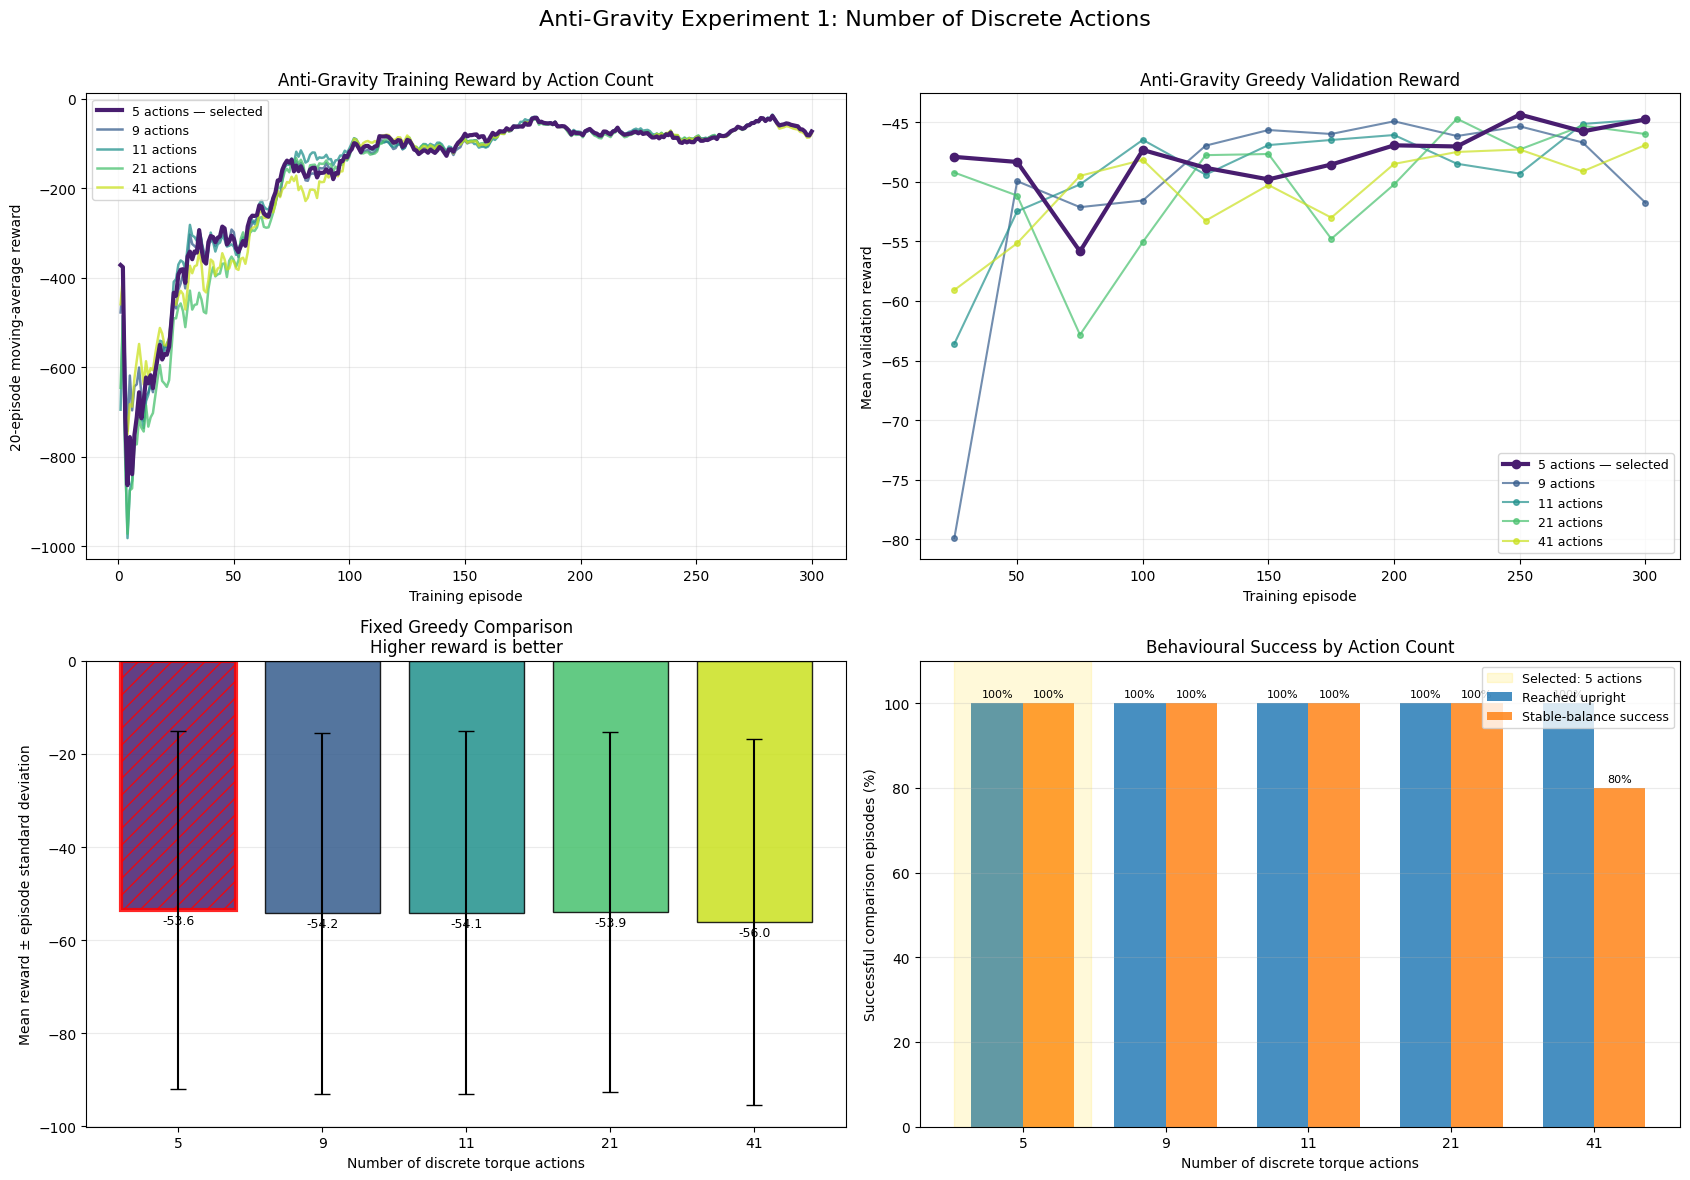

Figure saved to: figures\anti_gravity\anti_action_count_experiment.png


In [68]:
# ---------------------------------------------------------
# Main anti-gravity action-count visualisation
# ---------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 12),
)


# ---------------------------------------------------------
# Plot 1: Training learning curves
# ---------------------------------------------------------

for action_count in ANTI_ACTION_PLOT_COUNTS:
    run_training = (
        anti_action_training_plot[
            anti_action_training_plot[
                "action_count"
            ] == action_count
        ]
    )

    is_selected = (
        action_count
        == ANTI_SELECTED_ACTION_COUNT
    )

    axes[0, 0].plot(
        run_training["episode"],
        run_training[
            "moving_average_reward"
        ],
        color=ANTI_ACTION_COLOURS[
            int(action_count)
        ],
        linewidth=(
            3.0 if is_selected else 1.8
        ),
        alpha=(
            1.0 if is_selected else 0.75
        ),
        label=(
            f"{action_count} actions"
            + (
                " — selected"
                if is_selected
                else ""
            )
        ),
        zorder=(
            5 if is_selected else 2
        ),
    )


axes[0, 0].set_title(
    "Anti-Gravity Training Reward by Action Count"
)

axes[0, 0].set_xlabel(
    "Training episode"
)

axes[0, 0].set_ylabel(
    "20-episode moving-average reward"
)

axes[0, 0].grid(
    alpha=0.25
)

axes[0, 0].legend(
    fontsize=9,
)


# ---------------------------------------------------------
# Plot 2: Periodic greedy validation
# ---------------------------------------------------------

for action_count in ANTI_ACTION_PLOT_COUNTS:
    run_validation = (
        anti_action_validation_plot[
            anti_action_validation_plot[
                "action_count"
            ] == action_count
        ]
    )

    is_selected = (
        action_count
        == ANTI_SELECTED_ACTION_COUNT
    )

    axes[0, 1].plot(
        run_validation[
            "training_episode"
        ],
        run_validation[
            "validation_mean_reward"
        ],
        color=ANTI_ACTION_COLOURS[
            int(action_count)
        ],
        marker="o",
        markersize=(
            6 if is_selected else 4
        ),
        linewidth=(
            3.0 if is_selected else 1.5
        ),
        alpha=(
            1.0 if is_selected else 0.70
        ),
        label=(
            f"{action_count} actions"
            + (
                " — selected"
                if is_selected
                else ""
            )
        ),
        zorder=(
            5 if is_selected else 2
        ),
    )


axes[0, 1].set_title(
    "Anti-Gravity Greedy Validation Reward"
)

axes[0, 1].set_xlabel(
    "Training episode"
)

axes[0, 1].set_ylabel(
    "Mean validation reward"
)

axes[0, 1].grid(
    alpha=0.25
)

axes[0, 1].legend(
    fontsize=9,
)


# ---------------------------------------------------------
# Plot 3: Fixed greedy comparison
# ---------------------------------------------------------

action_positions = np.arange(
    len(ANTI_ACTION_PLOT_COUNTS)
)


comparison_bars = axes[1, 0].bar(
    action_positions,
    anti_action_results_plot[
        "comparison_mean_reward"
    ],
    color=[
        ANTI_ACTION_COLOURS[
            int(action_count)
        ]
        for action_count
        in ANTI_ACTION_PLOT_COUNTS
    ],
    alpha=0.85,
    edgecolor="black",
    linewidth=1.0,
    zorder=2,
)


axes[1, 0].errorbar(
    action_positions,
    anti_action_results_plot[
        "comparison_mean_reward"
    ],
    yerr=anti_action_results_plot[
        "comparison_reward_std"
    ],
    fmt="none",
    ecolor="black",
    elinewidth=1.5,
    capsize=6,
    zorder=4,
)


selected_position = int(
    np.where(
        ANTI_ACTION_PLOT_COUNTS
        == ANTI_SELECTED_ACTION_COUNT
    )[0][0]
)


comparison_bars[
    selected_position
].set_edgecolor("red")

comparison_bars[
    selected_position
].set_linewidth(3.0)

comparison_bars[
    selected_position
].set_hatch("//")


axes[1, 0].bar_label(
    comparison_bars,
    fmt="%.1f",
    padding=3,
    fontsize=9,
)


axes[1, 0].set_title(
    "Fixed Greedy Comparison\n"
    "Higher reward is better"
)

axes[1, 0].set_xlabel(
    "Number of discrete torque actions"
)

axes[1, 0].set_ylabel(
    "Mean reward ± episode standard deviation"
)

axes[1, 0].set_xticks(
    action_positions
)

axes[1, 0].set_xticklabels(
    ANTI_ACTION_PLOT_COUNTS
)

axes[1, 0].grid(
    axis="y",
    alpha=0.25,
    zorder=0,
)


# ---------------------------------------------------------
# Plot 4: Behavioural success rates
# ---------------------------------------------------------

bar_width = 0.36


upright_bars = axes[1, 1].bar(
    action_positions - bar_width / 2,
    (
        anti_action_results_plot[
            "reached_upright_rate"
        ]
        * 100
    ),
    width=bar_width,
    color="tab:blue",
    alpha=0.82,
    label="Reached upright",
)


balance_bars = axes[1, 1].bar(
    action_positions + bar_width / 2,
    (
        anti_action_results_plot[
            "balance_success_rate"
        ]
        * 100
    ),
    width=bar_width,
    color="tab:orange",
    alpha=0.82,
    label="Stable-balance success",
)


axes[1, 1].axvspan(
    selected_position - 0.48,
    selected_position + 0.48,
    color="gold",
    alpha=0.15,
    label=(
        f"Selected: "
        f"{ANTI_SELECTED_ACTION_COUNT} actions"
    ),
)


axes[1, 1].bar_label(
    upright_bars,
    fmt="%.0f%%",
    padding=3,
    fontsize=8,
)

axes[1, 1].bar_label(
    balance_bars,
    fmt="%.0f%%",
    padding=3,
    fontsize=8,
)


axes[1, 1].set_title(
    "Behavioural Success by Action Count"
)

axes[1, 1].set_xlabel(
    "Number of discrete torque actions"
)

axes[1, 1].set_ylabel(
    "Successful comparison episodes (%)"
)

axes[1, 1].set_xticks(
    action_positions
)

axes[1, 1].set_xticklabels(
    ANTI_ACTION_PLOT_COUNTS
)

axes[1, 1].set_ylim(
    0,
    110,
)

axes[1, 1].grid(
    axis="y",
    alpha=0.25,
)

axes[1, 1].legend(
    fontsize=9,
)


plt.suptitle(
    "Anti-Gravity Experiment 1: "
    "Number of Discrete Actions",
    fontsize=16,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)


anti_action_main_figure_path = (
    ANTI_FIGURES_DIR
    / "anti_action_count_experiment.png"
)


plt.savefig(
    anti_action_main_figure_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()


print(
    "Figure saved to:",
    anti_action_main_figure_path,
)

## Anti-Gravity Experiment 1 Evaluation: Number of Discrete Actions

This experiment compared Standard DQN models using **5, 9, 11, 21 and 41 discrete torque actions** under anti-gravity (`g = -10.0`). All models used the same `[64, 64]` architecture, hyperparameters, training seed, validation episodes and fixed greedy comparison episodes. Therefore, only the number of discrete actions and the corresponding output-layer size changed.

### Selected configuration

The model using **5 discrete actions** achieved the best results:

- best validation mean reward: **−44.372** at episode **250**;
- fixed comparison reward: **−53.552 ± 38.412**;
- reached-upright rate: **100%**;
- stable-balance success rate: **100%**;
- mean upright duration: **176.20 steps**;
- mean longest balance streak: **165.45 steps**; and
- trainable parameters: **4,741**.

Since Pendulum rewards are negative, values closer to zero indicate better performance. The 5-action model achieved the highest validation reward and the highest fixed-comparison mean reward. It therefore ranks first and is carried forward to the following anti-gravity experiments.

### Comparison with the other action counts

The differences among the 5-, 9-, 11- and 21-action models were small. Their fixed-comparison mean rewards ranged from **−53.552 to −54.224**, and all four models achieved 100% upright and stable-balance success rates.

The 21-action model produced a slightly longer mean balance streak of **168.65 steps**, while the 11-action model produced the highest mean upright duration of **177.00 steps**. However, neither model improved the overall comparison reward. The 5-action model was also more computationally efficient, using approximately **18% fewer parameters than the 21-action model**.

Increasing the action count to 41 did not improve control. It produced the lowest comparison reward of **−56.019**, the lowest validation reward of **−46.930**, and its balance-success rate decreased to **80%**. Its mean longest balance streak also decreased substantially to **131.45 steps**, despite having the largest network with 7,081 parameters.

The differences in mean reward are much smaller than the approximately 38–39 reward-point episode standard deviations. Therefore, this experiment should not claim that five actions are statistically superior. Instead, five actions are selected because they achieved the best observed validation and comparison means while providing the simplest and smallest action-output layer.

### Conclusion

The results indicate that fine torque discretisation is unnecessary for this anti-gravity environment. The five available torques `[-2, -1, 0, 1, 2]` provide sufficient control for reaching and balancing near the target position.

Therefore, **5 discrete actions are selected** for the remaining anti-gravity experiments. The next experiment keeps this action space fixed and investigates the effect of the epsilon-decay rate.

In [69]:
# ---------------------------------------------------------
# Anti-Gravity Experiment 2: Epsilon-decay rate
# ---------------------------------------------------------

ANTI_EPSILON_RESULTS_DIR = (
    ANTI_RESULTS_DIR / "epsilon_decay_experiment"
)

ANTI_EPSILON_WEIGHTS_DIR = (
    ANTI_WEIGHTS_DIR / "epsilon_decay_experiment"
)

for directory in [
    ANTI_EPSILON_RESULTS_DIR,
    ANTI_EPSILON_WEIGHTS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# Only this value changes between candidates.
ANTI_EPSILON_DECAYS = [
    0.999,
    0.995,
    0.990,
    0.985,
    0.980,
]


ANTI_EPSILON_TRAINING_SEED = (
    ANTI_ACTION_TRAINING_SEED
)

ANTI_EPSILON_VALIDATION_SEED = (
    ANTI_ACTION_VALIDATION_SEED
)

ANTI_EPSILON_COMPARISON_SEED = (
    ANTI_ACTION_COMPARISON_SEED
)

ANTI_EPSILON_TRAINING_EPISODES = 300
ANTI_EPSILON_MAX_STEPS = 200

ANTI_EPSILON_EVALUATION_EVERY = 25
ANTI_EPSILON_VALIDATION_EPISODES = 20
ANTI_EPSILON_COMPARISON_EPISODES = 20


def make_anti_epsilon_config(
    epsilon_decay,
):
    """Create a fresh config for one controlled run."""

    return DQNConfig(
        hidden_layers=(64, 64),
        activation="relu",

        learning_rate=0.001,
        gamma=0.99,

        batch_size=64,
        replay_capacity=50_000,
        minimum_replay_size=1_000,

        epsilon_start=1.0,
        epsilon_minimum=0.05,
        epsilon_decay=float(epsilon_decay),

        target_update_frequency=250,
        gradient_clip_norm=10.0,
    )


# ---------------------------------------------------------
# Preview each exploration schedule
# ---------------------------------------------------------

anti_epsilon_schedule_records = []

for epsilon_decay in ANTI_EPSILON_DECAYS:
    estimated_minimum_episode = int(
        np.ceil(
            np.log(0.05 / 1.0)
            / np.log(epsilon_decay)
        )
    )

    epsilon_after_training = max(
        0.05,
        1.0 * epsilon_decay
        ** ANTI_EPSILON_TRAINING_EPISODES,
    )

    anti_epsilon_schedule_records.append({
        "epsilon_decay": epsilon_decay,
        "epsilon_after_300_episodes": (
            epsilon_after_training
        ),
        "estimated_episode_reaching_0.05": (
            estimated_minimum_episode
        ),
        "reaches_minimum_during_training": (
            estimated_minimum_episode
            <= ANTI_EPSILON_TRAINING_EPISODES
        ),
    })


anti_epsilon_schedule_dataframe = pd.DataFrame(
    anti_epsilon_schedule_records
)

print("Selected action count:", ANTI_SELECTED_ACTION_COUNT)
print("Fixed architecture: [64, 64]")
print("Total new training runs:", len(ANTI_EPSILON_DECAYS))

display(
    anti_epsilon_schedule_dataframe.round(4)
)

Selected action count: 5
Fixed architecture: [64, 64]
Total new training runs: 5


,epsilon_decay,epsilon_after_300_episodes,estimated_episode_reaching_0.05,reaches_minimum_during_training
0,0.999,0.7407,2995,False
1,0.995,0.2223,598,False
2,0.990,0.0500,299,True
3,0.985,0.0500,199,True
4,0.980,0.0500,149,True


In [70]:
# ---------------------------------------------------------
# Separate paths for every epsilon-decay run
# ---------------------------------------------------------

def get_anti_epsilon_run_paths(
    epsilon_decay,
):
    decay_text = (
        f"{float(epsilon_decay):.3f}"
        .replace(".", "p")
    )

    run_name = (
        f"epsilon_{decay_text}_"
        f"seed_{ANTI_EPSILON_TRAINING_SEED}"
    )

    return {
        "weights": (
            ANTI_EPSILON_WEIGHTS_DIR
            / f"{run_name}.weights.h5"
        ),

        "training": (
            ANTI_EPSILON_RESULTS_DIR
            / f"{run_name}_training.csv"
        ),

        "validation": (
            ANTI_EPSILON_RESULTS_DIR
            / f"{run_name}_validation.csv"
        ),

        "checkpoint": (
            ANTI_EPSILON_RESULTS_DIR
            / f"{run_name}_checkpoint.csv"
        ),

        "comparison": (
            ANTI_EPSILON_RESULTS_DIR
            / f"{run_name}_comparison.csv"
        ),
    }


ANTI_EPSILON_RUN_PATHS = {
    epsilon_decay: get_anti_epsilon_run_paths(
        epsilon_decay
    )
    for epsilon_decay in ANTI_EPSILON_DECAYS
}


anti_epsilon_path_records = []

for epsilon_decay in ANTI_EPSILON_DECAYS:
    run_paths = ANTI_EPSILON_RUN_PATHS[
        epsilon_decay
    ]

    anti_epsilon_path_records.append({
        "epsilon_decay": epsilon_decay,
        "weights_file": run_paths["weights"].name,
        "training_file": run_paths["training"].name,
        "validation_file": run_paths["validation"].name,
        "checkpoint_file": run_paths["checkpoint"].name,
        "comparison_file": run_paths["comparison"].name,
    })


anti_epsilon_paths_dataframe = pd.DataFrame(
    anti_epsilon_path_records
)

display(anti_epsilon_paths_dataframe)

,epsilon_decay,weights_file,training_file,validation_file,checkpoint_file,comparison_file
0,0.999,epsilon_0p999_seed_123.weights.h5,epsilon_0p999_seed_123_training.csv,epsilon_0p999_seed_123_validation.csv,epsilon_0p999_seed_123_checkpoint.csv,epsilon_0p999_seed_123_comparison.csv
1,0.995,epsilon_0p995_seed_123.weights.h5,epsilon_0p995_seed_123_training.csv,epsilon_0p995_seed_123_validation.csv,epsilon_0p995_seed_123_checkpoint.csv,epsilon_0p995_seed_123_comparison.csv
2,0.990,epsilon_0p990_seed_123.weights.h5,epsilon_0p990_seed_123_training.csv,epsilon_0p990_seed_123_validation.csv,epsilon_0p990_seed_123_checkpoint.csv,epsilon_0p990_seed_123_comparison.csv
3,0.985,epsilon_0p985_seed_123.weights.h5,epsilon_0p985_seed_123_training.csv,epsilon_0p985_seed_123_validation.csv,epsilon_0p985_seed_123_checkpoint.csv,epsilon_0p985_seed_123_comparison.csv
4,0.980,epsilon_0p980_seed_123.weights.h5,epsilon_0p980_seed_123_training.csv,epsilon_0p980_seed_123_validation.csv,epsilon_0p980_seed_123_checkpoint.csv,epsilon_0p980_seed_123_comparison.csv


In [71]:
# ---------------------------------------------------------
# Train fresh Standard DQN models for every decay rate
# ---------------------------------------------------------

for run_number, epsilon_decay in enumerate(
    ANTI_EPSILON_DECAYS,
    start=1,
):
    run_paths = ANTI_EPSILON_RUN_PATHS[
        epsilon_decay
    ]

    required_training_paths = [
        run_paths["weights"],
        run_paths["training"],
        run_paths["validation"],
        run_paths["checkpoint"],
    ]

    run_is_complete = all(
        path.exists()
        for path in required_training_paths
    )

    if run_is_complete:
        print(
            f"Run {run_number}/5 | "
            f"decay {epsilon_decay:.3f}: "
            "saved results already exist."
        )
        continue

    print("\n" + "=" * 70)
    print(
        f"ANTI-GRAVITY RUN {run_number}/5 | "
        f"EPSILON DECAY {epsilon_decay:.3f}"
    )
    print("=" * 70)

    tf.keras.backend.clear_session()
    set_global_seed(
        ANTI_EPSILON_TRAINING_SEED
    )

    anti_training_env = None
    anti_validation_env = None
    anti_epsilon_agent = None

    try:
        current_config = make_anti_epsilon_config(
            epsilon_decay
        )

        anti_training_env = create_pendulum_env(
            gravity=ANTI_GRAVITY_VALUE,
            seed=ANTI_EPSILON_TRAINING_SEED,
        )

        anti_validation_env = create_pendulum_env(
            gravity=ANTI_GRAVITY_VALUE,
            seed=ANTI_EPSILON_VALIDATION_SEED,
        )

        anti_epsilon_agent = DQNAgent(
            state_size=ANTI_STATE_SIZE,
            action_values=(
                ANTI_SELECTED_ACTION_VALUES
            ),
            config=current_config,
            use_double_dqn=False,
        )

        (
            anti_epsilon_history,
            anti_epsilon_training_dataframe,
        ) = train_agent(
            env=anti_training_env,
            agent=anti_epsilon_agent,

            episodes=(
                ANTI_EPSILON_TRAINING_EPISODES
            ),

            max_steps=(
                ANTI_EPSILON_MAX_STEPS
            ),

            moving_average_window=20,
            seed=ANTI_EPSILON_TRAINING_SEED,

            evaluation_env=anti_validation_env,

            evaluation_every=(
                ANTI_EPSILON_EVALUATION_EVERY
            ),

            evaluation_episodes=(
                ANTI_EPSILON_VALIDATION_EPISODES
            ),

            evaluation_seed=(
                ANTI_EPSILON_VALIDATION_SEED
            ),

            best_weights_path=run_paths["weights"],

            print_every=25,
            render_every=None,
        )

        # ---------------------------------------------
        # Save complete training history
        # ---------------------------------------------

        anti_epsilon_training_dataframe.insert(
            0,
            "training_seed",
            ANTI_EPSILON_TRAINING_SEED,
        )

        anti_epsilon_training_dataframe.insert(
            0,
            "action_count",
            ANTI_SELECTED_ACTION_COUNT,
        )

        anti_epsilon_training_dataframe.insert(
            0,
            "epsilon_decay",
            epsilon_decay,
        )

        anti_epsilon_training_dataframe.insert(
            0,
            "gravity",
            ANTI_GRAVITY_VALUE,
        )

        anti_epsilon_training_dataframe.to_csv(
            run_paths["training"],
            index=False,
        )

        # ---------------------------------------------
        # Save periodic validation results
        # ---------------------------------------------

        anti_epsilon_validation_dataframe = (
            pd.DataFrame({
                "gravity": ANTI_GRAVITY_VALUE,

                "epsilon_decay": epsilon_decay,

                "action_count": (
                    ANTI_SELECTED_ACTION_COUNT
                ),

                "training_seed": (
                    ANTI_EPSILON_TRAINING_SEED
                ),

                "training_episode": (
                    anti_epsilon_history[
                        "evaluation_episode"
                    ]
                ),

                "validation_mean_reward": (
                    anti_epsilon_history[
                        "evaluation_mean_reward"
                    ]
                ),

                "validation_reward_std": (
                    anti_epsilon_history[
                        "evaluation_reward_std"
                    ]
                ),
            })
        )

        anti_epsilon_validation_dataframe.to_csv(
            run_paths["validation"],
            index=False,
        )

        # ---------------------------------------------
        # Record checkpoint selected by validation
        # ---------------------------------------------

        validation_means = anti_epsilon_history[
            "evaluation_mean_reward"
        ]

        if len(validation_means) == 0:
            raise RuntimeError(
                "No validation results were produced."
            )

        best_position = int(
            np.argmax(validation_means)
        )

        anti_epsilon_checkpoint_dataframe = (
            pd.DataFrame([
                {
                    "gravity": ANTI_GRAVITY_VALUE,
                    "epsilon_decay": epsilon_decay,

                    "action_count": (
                        ANTI_SELECTED_ACTION_COUNT
                    ),

                    "training_seed": (
                        ANTI_EPSILON_TRAINING_SEED
                    ),

                    "algorithm": "Standard DQN",
                    "architecture": "[64, 64]",

                    "parameter_count": int(
                        anti_epsilon_agent
                        .online_network
                        .count_params()
                    ),

                    "best_checkpoint_episode": int(
                        anti_epsilon_history[
                            "evaluation_episode"
                        ][best_position]
                    ),

                    "best_validation_mean_reward": float(
                        validation_means[
                            best_position
                        ]
                    ),

                    "best_validation_reward_std": float(
                        anti_epsilon_history[
                            "evaluation_reward_std"
                        ][best_position]
                    ),

                    "final_training_epsilon": float(
                        anti_epsilon_agent.epsilon
                    ),
                }
            ])
        )

        anti_epsilon_checkpoint_dataframe.to_csv(
            run_paths["checkpoint"],
            index=False,
        )

        print(
            f"Decay {epsilon_decay:.3f} completed | "
            f"best checkpoint: episode "
            f"{anti_epsilon_history['evaluation_episode'][best_position]} | "
            f"validation reward: "
            f"{validation_means[best_position]:.3f}"
        )

    finally:
        if anti_training_env is not None:
            anti_training_env.close()

        if anti_validation_env is not None:
            anti_validation_env.close()

        anti_epsilon_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


ANTI-GRAVITY RUN 1/5 | EPSILON DECAY 0.999
Episode    1/300 | Reward:  -371.65 | Moving average:  -371.65 | Epsilon: 0.9990 | Loss: not training yet | Replay size: 200
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\epsilon_decay_experiment\epsilon_0p999_seed_123.weights.h5
Evaluation at episode 25: mean reward = -57.55, std = 49.02
New best weights saved.
Episode   25/300 | Reward: -1083.98 | Moving average:  -551.44 | Epsilon: 0.9753 | Loss: 0.3885 | Replay size: 5000
Evaluation at episode 50: mean reward = -64.09, std = 44.67
Episode   50/300 | Reward:  -578.96 | Moving average:  -686.55 | Epsilon: 0.9512 | Loss: 0.4794 | Replay size: 10000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\epsilon_decay_experiment\epsilon_0p999_seed_123.weights.h5
Evaluation at episode 75: mean reward = -51.98, std = 45.53
New best weights saved.
Episode   75/300 | Reward:  -969.17 | Moving average:  -462.56 | Epsilon: 0.9277 | Loss: 0.3738 | Replay size:

In [72]:
# ---------------------------------------------------------
# Evaluate every saved checkpoint on identical episodes
# ---------------------------------------------------------

anti_epsilon_result_records = []
anti_epsilon_episode_frames = []
anti_epsilon_training_frames = []
anti_epsilon_validation_frames = []


for run_number, epsilon_decay in enumerate(
    ANTI_EPSILON_DECAYS,
    start=1,
):
    print(
        f"Evaluating {run_number}/5 | "
        f"decay {epsilon_decay:.3f}"
    )

    run_paths = ANTI_EPSILON_RUN_PATHS[
        epsilon_decay
    ]

    required_paths = [
        run_paths["weights"],
        run_paths["training"],
        run_paths["validation"],
        run_paths["checkpoint"],
    ]

    for required_path in required_paths:
        if not required_path.exists():
            raise FileNotFoundError(
                f"Missing result for decay "
                f"{epsilon_decay:.3f}: "
                f"{required_path.resolve()}"
            )

    training_dataframe = pd.read_csv(
        run_paths["training"]
    )

    validation_dataframe = pd.read_csv(
        run_paths["validation"]
    )

    checkpoint_dataframe = pd.read_csv(
        run_paths["checkpoint"]
    )

    anti_epsilon_training_frames.append(
        training_dataframe
    )

    anti_epsilon_validation_frames.append(
        validation_dataframe
    )

    checkpoint_row = checkpoint_dataframe.iloc[0]

    tf.keras.backend.clear_session()
    set_global_seed(
        ANTI_EPSILON_TRAINING_SEED
    )

    comparison_env = None
    evaluation_agent = None

    try:
        current_config = make_anti_epsilon_config(
            epsilon_decay
        )

        comparison_env = create_pendulum_env(
            gravity=ANTI_GRAVITY_VALUE,
            seed=ANTI_EPSILON_COMPARISON_SEED,
        )

        evaluation_agent = DQNAgent(
            state_size=ANTI_STATE_SIZE,
            action_values=(
                ANTI_SELECTED_ACTION_VALUES
            ),
            config=current_config,
            use_double_dqn=False,
        )

        evaluation_agent.load_weights(
            run_paths["weights"]
        )

        comparison_result = evaluate_agent(
            env=comparison_env,
            agent=evaluation_agent,

            episodes=(
                ANTI_EPSILON_COMPARISON_EPISODES
            ),

            max_steps=(
                ANTI_EPSILON_MAX_STEPS
            ),

            seed=(
                ANTI_EPSILON_COMPARISON_SEED
            ),

            best_score=None,
            save_path=None,
            verbose=False,
        )

        anti_epsilon_result_records.append({
            "gravity": ANTI_GRAVITY_VALUE,
            "epsilon_decay": epsilon_decay,

            "action_count": (
                ANTI_SELECTED_ACTION_COUNT
            ),

            "training_seed": (
                ANTI_EPSILON_TRAINING_SEED
            ),

            "algorithm": "Standard DQN",
            "architecture": "[64, 64]",

            "parameter_count": int(
                evaluation_agent
                .online_network
                .count_params()
            ),

            "best_checkpoint_episode": int(
                checkpoint_row[
                    "best_checkpoint_episode"
                ]
            ),

            "best_validation_mean_reward": float(
                checkpoint_row[
                    "best_validation_mean_reward"
                ]
            ),

            "best_validation_reward_std": float(
                checkpoint_row[
                    "best_validation_reward_std"
                ]
            ),

            "final_training_epsilon": float(
                checkpoint_row[
                    "final_training_epsilon"
                ]
            ),

            "comparison_mean_reward": (
                comparison_result["mean_reward"]
            ),

            "comparison_reward_std": (
                comparison_result["reward_std"]
            ),

            "comparison_minimum_reward": (
                comparison_result[
                    "minimum_reward"
                ]
            ),

            "comparison_maximum_reward": (
                comparison_result[
                    "maximum_reward"
                ]
            ),

            "reached_upright_rate": (
                comparison_result[
                    "reached_upright_rate"
                ]
            ),

            "balance_success_rate": (
                comparison_result[
                    "balance_success_rate"
                ]
            ),

            "mean_upright_steps": (
                comparison_result[
                    "mean_upright_steps"
                ]
            ),

            "mean_longest_balance_streak": (
                comparison_result[
                    "mean_longest_balance_streak"
                ]
            ),
        })

        episode_dataframe = pd.DataFrame(
            comparison_result["episode_metrics"]
        )

        episode_dataframe.insert(
            0,
            "training_seed",
            ANTI_EPSILON_TRAINING_SEED,
        )

        episode_dataframe.insert(
            0,
            "action_count",
            ANTI_SELECTED_ACTION_COUNT,
        )

        episode_dataframe.insert(
            0,
            "epsilon_decay",
            epsilon_decay,
        )

        episode_dataframe.insert(
            0,
            "gravity",
            ANTI_GRAVITY_VALUE,
        )

        episode_dataframe.to_csv(
            run_paths["comparison"],
            index=False,
        )

        anti_epsilon_episode_frames.append(
            episode_dataframe
        )

        print(
            f"Reward: "
            f"{comparison_result['mean_reward']:.2f} "
            f"± {comparison_result['reward_std']:.2f} | "
            f"Upright: "
            f"{comparison_result['reached_upright_rate']:.1%} | "
            f"Balance: "
            f"{comparison_result['balance_success_rate']:.1%}"
        )

    finally:
        if comparison_env is not None:
            comparison_env.close()

        evaluation_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


# ---------------------------------------------------------
# Combine and rank results
# ---------------------------------------------------------

anti_epsilon_results_dataframe = pd.DataFrame(
    anti_epsilon_result_records
)

anti_epsilon_training_all_dataframe = pd.concat(
    anti_epsilon_training_frames,
    ignore_index=True,
)

anti_epsilon_validation_all_dataframe = pd.concat(
    anti_epsilon_validation_frames,
    ignore_index=True,
)

anti_epsilon_episode_all_dataframe = pd.concat(
    anti_epsilon_episode_frames,
    ignore_index=True,
)


anti_epsilon_summary_dataframe = (
    anti_epsilon_results_dataframe
    .sort_values(
        [
            "comparison_mean_reward",
            "comparison_reward_std",
        ],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)


baseline_mean = float(
    anti_epsilon_summary_dataframe.loc[
        np.isclose(
            anti_epsilon_summary_dataframe[
                "epsilon_decay"
            ],
            0.995,
        ),
        "comparison_mean_reward",
    ].iloc[0]
)


anti_epsilon_summary_dataframe[
    "mean_difference_vs_0.995"
] = (
    anti_epsilon_summary_dataframe[
        "comparison_mean_reward"
    ]
    - baseline_mean
)


anti_epsilon_summary_dataframe.insert(
    0,
    "rank",
    np.arange(
        1,
        len(anti_epsilon_summary_dataframe) + 1,
    ),
)


ANTI_SELECTED_EPSILON_DECAY = float(
    anti_epsilon_summary_dataframe.iloc[0][
        "epsilon_decay"
    ]
)


# ---------------------------------------------------------
# Save combined outputs
# ---------------------------------------------------------

anti_epsilon_summary_dataframe.to_csv(
    ANTI_EPSILON_RESULTS_DIR
    / "anti_epsilon_decay_summary.csv",
    index=False,
)

anti_epsilon_training_all_dataframe.to_csv(
    ANTI_EPSILON_RESULTS_DIR
    / "anti_epsilon_training_all.csv",
    index=False,
)

anti_epsilon_validation_all_dataframe.to_csv(
    ANTI_EPSILON_RESULTS_DIR
    / "anti_epsilon_validation_all.csv",
    index=False,
)

anti_epsilon_episode_all_dataframe.to_csv(
    ANTI_EPSILON_RESULTS_DIR
    / "anti_epsilon_episode_metrics.csv",
    index=False,
)


anti_epsilon_display_dataframe = (
    anti_epsilon_summary_dataframe.copy()
)

anti_epsilon_display_dataframe[
    "reached_upright_rate"
] *= 100

anti_epsilon_display_dataframe[
    "balance_success_rate"
] *= 100


print(
    "\nSelected anti-gravity epsilon decay:",
    f"{ANTI_SELECTED_EPSILON_DECAY:.3f}",
)

display(
    anti_epsilon_display_dataframe[
        [
            "rank",
            "epsilon_decay",
            "final_training_epsilon",
            "best_checkpoint_episode",
            "best_validation_mean_reward",
            "comparison_mean_reward",
            "comparison_reward_std",
            "mean_difference_vs_0.995",
            "reached_upright_rate",
            "balance_success_rate",
            "mean_upright_steps",
            "mean_longest_balance_streak",
        ]
    ].round(3)
)

Evaluating 1/5 | decay 0.999
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\epsilon_decay_experiment\epsilon_0p999_seed_123.weights.h5
Reward: -54.62 ± 38.82 | Upright: 100.0% | Balance: 95.0%
Evaluating 2/5 | decay 0.995
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\epsilon_decay_experiment\epsilon_0p995_seed_123.weights.h5
Reward: -53.55 ± 38.41 | Upright: 100.0% | Balance: 100.0%
Evaluating 3/5 | decay 0.990
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\epsilon_decay_experiment\epsilon_0p990_seed_123.weights.h5
Reward: -55.33 ± 39.21 | Upright: 100.0% | Balance: 100.0%
Evaluating 4/5 | decay 0.985
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\epsilon_decay_experiment\epsilon_0p985_seed_123.weights.h5
Reward: -53.94 ± 38.60 | Upright: 100.0% | Balance: 100.0%
Evaluating 5/5 | decay 0.980
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\epsilon_decay_

,rank,epsilon_decay,final_training_epsilon,best_checkpoint_episode,best_validation_mean_reward,comparison_mean_reward,comparison_reward_std,mean_difference_vs_0.995,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,1,0.995,0.222,250,-44.372,-53.552,38.412,0.000,100.0,100.0,176.20,165.45
1,2,0.985,0.050,175,-44.566,-53.942,38.599,-0.390,100.0,100.0,176.15,165.25
2,3,0.980,0.050,225,-46.568,-54.214,38.660,-0.661,100.0,100.0,177.20,168.20
3,4,0.999,0.741,250,-45.113,-54.618,38.815,-1.066,100.0,95.0,171.80,155.25
4,5,0.990,0.050,300,-45.780,-55.325,39.213,-1.773,100.0,100.0,175.75,166.45


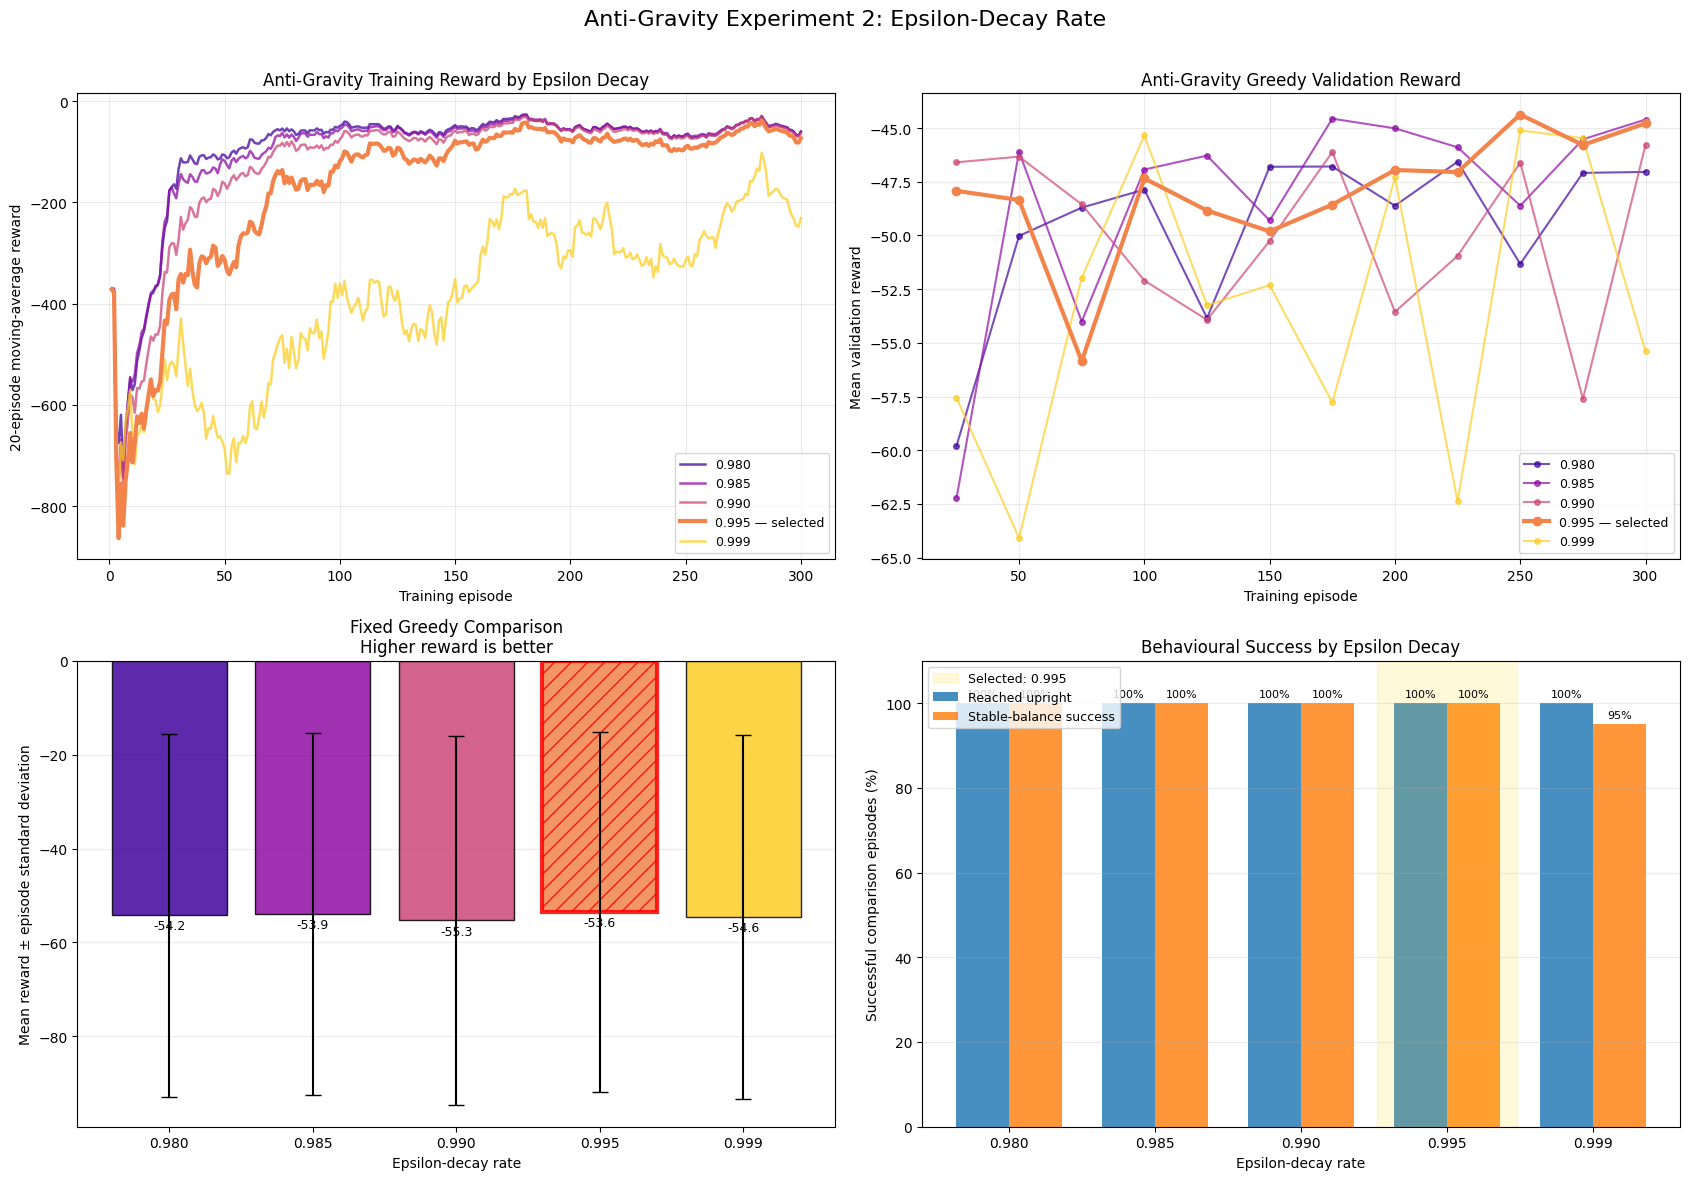

Figure saved to: figures\anti_gravity\anti_epsilon_decay_experiment.png


In [73]:
# ---------------------------------------------------------
# Anti-gravity epsilon-decay visualisation
# ---------------------------------------------------------

anti_epsilon_plot_values = np.array(
    sorted(ANTI_EPSILON_DECAYS),
    dtype=float,
)

epsilon_colours = {
    float(decay): colour
    for decay, colour in zip(
        anti_epsilon_plot_values,
        plt.cm.plasma(
            np.linspace(
                0.10,
                0.90,
                len(anti_epsilon_plot_values),
            )
        ),
    )
}


fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 12),
)


# ---------------------------------------------------------
# Plot 1: Training curves
# ---------------------------------------------------------

for epsilon_decay in anti_epsilon_plot_values:
    run_training = (
        anti_epsilon_training_all_dataframe.loc[
            np.isclose(
                anti_epsilon_training_all_dataframe[
                    "epsilon_decay"
                ],
                epsilon_decay,
            )
        ]
        .sort_values("episode")
    )

    is_selected = np.isclose(
        epsilon_decay,
        ANTI_SELECTED_EPSILON_DECAY,
    )

    axes[0, 0].plot(
        run_training["episode"],
        run_training["moving_average_reward"],

        color=epsilon_colours[
            float(epsilon_decay)
        ],

        linewidth=(
            3.0 if is_selected else 1.8
        ),

        alpha=(
            1.0 if is_selected else 0.75
        ),

        label=(
            f"{epsilon_decay:.3f}"
            + (
                " — selected"
                if is_selected
                else ""
            )
        ),

        zorder=(
            5 if is_selected else 2
        ),
    )


axes[0, 0].set_title(
    "Anti-Gravity Training Reward by Epsilon Decay"
)

axes[0, 0].set_xlabel("Training episode")

axes[0, 0].set_ylabel(
    "20-episode moving-average reward"
)

axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend(fontsize=9)


# ---------------------------------------------------------
# Plot 2: Periodic greedy validation
# ---------------------------------------------------------

for epsilon_decay in anti_epsilon_plot_values:
    run_validation = (
        anti_epsilon_validation_all_dataframe.loc[
            np.isclose(
                anti_epsilon_validation_all_dataframe[
                    "epsilon_decay"
                ],
                epsilon_decay,
            )
        ]
        .sort_values("training_episode")
    )

    is_selected = np.isclose(
        epsilon_decay,
        ANTI_SELECTED_EPSILON_DECAY,
    )

    axes[0, 1].plot(
        run_validation["training_episode"],
        run_validation["validation_mean_reward"],

        color=epsilon_colours[
            float(epsilon_decay)
        ],

        marker="o",

        markersize=(
            6 if is_selected else 4
        ),

        linewidth=(
            3.0 if is_selected else 1.5
        ),

        alpha=(
            1.0 if is_selected else 0.70
        ),

        label=(
            f"{epsilon_decay:.3f}"
            + (
                " — selected"
                if is_selected
                else ""
            )
        ),

        zorder=(
            5 if is_selected else 2
        ),
    )


axes[0, 1].set_title(
    "Anti-Gravity Greedy Validation Reward"
)

axes[0, 1].set_xlabel("Training episode")
axes[0, 1].set_ylabel("Mean validation reward")
axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend(fontsize=9)


# ---------------------------------------------------------
# Prepare ranked-independent plotting order
# ---------------------------------------------------------

results_plot = (
    anti_epsilon_results_dataframe
    .sort_values("epsilon_decay")
    .reset_index(drop=True)
)

plot_decays = (
    results_plot["epsilon_decay"]
    .astype(float)
    .to_numpy()
)

positions = np.arange(
    len(plot_decays)
)

selected_position = int(
    np.where(
        np.isclose(
            plot_decays,
            ANTI_SELECTED_EPSILON_DECAY,
        )
    )[0][0]
)


# ---------------------------------------------------------
# Plot 3: Fixed greedy comparison
# ---------------------------------------------------------

comparison_bars = axes[1, 0].bar(
    positions,

    results_plot[
        "comparison_mean_reward"
    ],

    color=[
        epsilon_colours[float(decay)]
        for decay in plot_decays
    ],

    alpha=0.85,
    edgecolor="black",
    linewidth=1.0,
    zorder=2,
)


axes[1, 0].errorbar(
    positions,

    results_plot[
        "comparison_mean_reward"
    ],

    yerr=results_plot[
        "comparison_reward_std"
    ],

    fmt="none",
    ecolor="black",
    elinewidth=1.5,
    capsize=6,
    zorder=4,
)


comparison_bars[
    selected_position
].set_edgecolor("red")

comparison_bars[
    selected_position
].set_linewidth(3.0)

comparison_bars[
    selected_position
].set_hatch("//")


axes[1, 0].bar_label(
    comparison_bars,
    fmt="%.1f",
    padding=3,
    fontsize=9,
)


axes[1, 0].set_title(
    "Fixed Greedy Comparison\n"
    "Higher reward is better"
)

axes[1, 0].set_xlabel(
    "Epsilon-decay rate"
)

axes[1, 0].set_ylabel(
    "Mean reward ± episode standard deviation"
)

axes[1, 0].set_xticks(positions)

axes[1, 0].set_xticklabels(
    [
        f"{decay:.3f}"
        for decay in plot_decays
    ]
)

axes[1, 0].grid(
    axis="y",
    alpha=0.25,
    zorder=0,
)


# ---------------------------------------------------------
# Plot 4: Behavioural success
# ---------------------------------------------------------

bar_width = 0.36

upright_bars = axes[1, 1].bar(
    positions - bar_width / 2,

    results_plot[
        "reached_upright_rate"
    ] * 100,

    width=bar_width,
    color="tab:blue",
    alpha=0.82,
    label="Reached upright",
)

balance_bars = axes[1, 1].bar(
    positions + bar_width / 2,

    results_plot[
        "balance_success_rate"
    ] * 100,

    width=bar_width,
    color="tab:orange",
    alpha=0.82,
    label="Stable-balance success",
)


axes[1, 1].axvspan(
    selected_position - 0.48,
    selected_position + 0.48,
    color="gold",
    alpha=0.15,
    label=(
        f"Selected: "
        f"{ANTI_SELECTED_EPSILON_DECAY:.3f}"
    ),
)


axes[1, 1].bar_label(
    upright_bars,
    fmt="%.0f%%",
    padding=3,
    fontsize=8,
)

axes[1, 1].bar_label(
    balance_bars,
    fmt="%.0f%%",
    padding=3,
    fontsize=8,
)


axes[1, 1].set_title(
    "Behavioural Success by Epsilon Decay"
)

axes[1, 1].set_xlabel("Epsilon-decay rate")

axes[1, 1].set_ylabel(
    "Successful comparison episodes (%)"
)

axes[1, 1].set_xticks(positions)

axes[1, 1].set_xticklabels(
    [
        f"{decay:.3f}"
        for decay in plot_decays
    ]
)

axes[1, 1].set_ylim(0, 110)

axes[1, 1].grid(
    axis="y",
    alpha=0.25,
)

axes[1, 1].legend(fontsize=9)


plt.suptitle(
    "Anti-Gravity Experiment 2: "
    "Epsilon-Decay Rate",
    fontsize=16,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)


anti_epsilon_figure_path = (
    ANTI_FIGURES_DIR
    / "anti_epsilon_decay_experiment.png"
)

plt.savefig(
    anti_epsilon_figure_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure saved to:",
    anti_epsilon_figure_path,
)

## Anti-Gravity Experiment 2 Evaluation: Epsilon-Decay Rate

This experiment investigated epsilon-decay rates of **0.999, 0.995, 0.990, 0.985 and 0.980** while keeping the action space, network architecture, learning rate, training seed and evaluation episodes fixed. Since Pendulum rewards are negative, rewards closer to zero indicate better performance.

### Selected configuration

The epsilon-decay rate of **0.995** achieved the best overall results:

- best validation mean reward: **−44.372** at episode **250**;
- fixed comparison reward: **−53.552 ± 38.412**;
- reached-upright rate: **100%**;
- stable-balance success rate: **100%**;
- mean upright duration: **176.20 steps**; and
- mean longest balance streak: **165.45 steps**.

It achieved the highest validation reward and fixed-comparison mean reward. Therefore, **`epsilon_decay = 0.995` is selected** for Experiment 3.

### Comparison with other decay rates

The decay rate of **0.985** ranked second with a comparison reward of **−53.942 ± 38.599**, only **0.390 reward points** below 0.995. The 0.980 model also performed strongly, achieving the longest mean balance streak of **168.20 steps**, but its comparison reward was slightly lower at **−54.214 ± 38.660**.

The fastest tested schedules, 0.990 and 0.980, reached the minimum epsilon of 0.05 during training. Although both learned successful balancing behaviour, reducing exploration more quickly did not improve their comparison rewards.

The slowest schedule, **0.999**, retained an epsilon of approximately **0.741** after training. It achieved the shortest mean upright duration of **171.80 steps**, the shortest balance streak of **155.25 steps**, and was the only configuration whose balance-success rate decreased to **95%**. This suggests that it retained excessive exploration for the available 300-episode training budget.

### Limitations

All mean-reward differences were smaller than **1.8 points**, while episode reward standard deviations were approximately **38–39 points**. Therefore, the experiment does not prove that 0.995 is statistically superior. It is selected because it produced the best observed validation and comparison rewards while maintaining perfect behavioural success.

### Conclusion

A moderate epsilon decay produced the strongest balance between exploration and exploitation. Decaying too slowly retained excessive random exploration, while faster decay schedules did not improve the final reward.

Therefore, **`epsilon_decay = 0.995` is carried forward**, together with the selected five-action space and `[64, 64]` network architecture. Experiment 3 investigates the effect of the Adam learning rate.

In [79]:
# ---------------------------------------------------------
# Anti-Gravity Experiment 3: Learning Rate
# ---------------------------------------------------------

# Use a new directory so no Experiment 2 files
# or previously reused files can be loaded.
ANTI_LEARNING_RESULTS_DIR = (
    ANTI_RESULTS_DIR
    / "learning_rate_experiment_early_stopping"
)

ANTI_LEARNING_WEIGHTS_DIR = (
    ANTI_WEIGHTS_DIR
    / "learning_rate_experiment_early_stopping"
)

for directory in [
    ANTI_LEARNING_RESULTS_DIR,
    ANTI_LEARNING_WEIGHTS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# Only the learning rate changes.
ANTI_LEARNING_RATES = [
    0.0003,
    0.0010,
    0.0030,
]

ANTI_LEARNING_CONTROL_RATE = 0.0010


# Same seeds for every candidate.
ANTI_LEARNING_TRAINING_SEED = (
    ANTI_EPSILON_TRAINING_SEED
)

ANTI_LEARNING_VALIDATION_SEED = (
    ANTI_EPSILON_VALIDATION_SEED
)

ANTI_LEARNING_COMPARISON_SEED = (
    ANTI_EPSILON_COMPARISON_SEED + 10_000
)


# Same training and early-stopping rules.
ANTI_LEARNING_MAX_EPISODES = 300
ANTI_LEARNING_MAX_STEPS = 200

ANTI_LEARNING_EVALUATION_EVERY = 25
ANTI_LEARNING_VALIDATION_EPISODES = 20
ANTI_LEARNING_COMPARISON_EPISODES = 20

ANTI_LEARNING_MINIMUM_EPISODES = 200
ANTI_LEARNING_EARLY_STOPPING_PATIENCE = 4
ANTI_LEARNING_EARLY_STOPPING_MIN_DELTA = 0.0


def make_anti_learning_config(
    learning_rate,
):
    """Create a fresh config with one learning rate."""

    return DQNConfig(
        hidden_layers=(64, 64),
        activation="relu",

        learning_rate=float(learning_rate),
        gamma=0.99,

        batch_size=64,
        replay_capacity=50_000,
        minimum_replay_size=1_000,

        epsilon_start=1.0,
        epsilon_minimum=0.05,
        epsilon_decay=(
            ANTI_SELECTED_EPSILON_DECAY
        ),

        target_update_frequency=250,
        gradient_clip_norm=10.0,
    )


def get_anti_learning_run_paths(
    learning_rate,
):
    rate_text = (
        f"{float(learning_rate):.4f}"
        .replace(".", "p")
    )

    run_name = (
        f"fresh_learning_rate_{rate_text}_"
        f"seed_{ANTI_LEARNING_TRAINING_SEED}"
    )

    return {
        "weights": (
            ANTI_LEARNING_WEIGHTS_DIR
            / f"{run_name}.weights.h5"
        ),

        "training": (
            ANTI_LEARNING_RESULTS_DIR
            / f"{run_name}_training.csv"
        ),

        "validation": (
            ANTI_LEARNING_RESULTS_DIR
            / f"{run_name}_validation.csv"
        ),

        "checkpoint": (
            ANTI_LEARNING_RESULTS_DIR
            / f"{run_name}_checkpoint.csv"
        ),

        "comparison": (
            ANTI_LEARNING_RESULTS_DIR
            / f"{run_name}_comparison.csv"
        ),
    }


ANTI_LEARNING_RUN_PATHS = {
    learning_rate: get_anti_learning_run_paths(
        learning_rate
    )
    for learning_rate in ANTI_LEARNING_RATES
}


print(
    "Fixed action count:",
    ANTI_SELECTED_ACTION_COUNT,
)

print(
    "Fixed epsilon decay:",
    ANTI_SELECTED_EPSILON_DECAY,
)

print(
    "Learning rates:",
    ANTI_LEARNING_RATES,
)

print(
    "All three models will be trained from scratch."
)

print(
    "Early stopping: minimum",
    ANTI_LEARNING_MINIMUM_EPISODES,
    "episodes; patience",
    ANTI_LEARNING_EARLY_STOPPING_PATIENCE,
    "validation checks.",
)

Fixed action count: 5
Fixed epsilon decay: 0.995
Learning rates: [0.0003, 0.001, 0.003]
All three models will be trained from scratch.
Early stopping: minimum 200 episodes; patience 4 validation checks.


In [80]:
# ---------------------------------------------------------
# Train fresh Standard DQN models
# ---------------------------------------------------------

for run_number, learning_rate in enumerate(
    ANTI_LEARNING_RATES,
    start=1,
):
    run_paths = ANTI_LEARNING_RUN_PATHS[
        learning_rate
    ]

    required_training_paths = [
        run_paths["weights"],
        run_paths["training"],
        run_paths["validation"],
        run_paths["checkpoint"],
    ]

    run_is_complete = all(
        path.exists()
        for path in required_training_paths
    )

    if run_is_complete:
        print(
            f"Run {run_number}/3 | "
            f"learning rate {learning_rate:g}: "
            "fresh saved results already exist."
        )
        continue

    print("\n" + "=" * 70)

    print(
        f"ANTI-GRAVITY RUN {run_number}/3 | "
        f"LEARNING RATE {learning_rate:g}"
    )

    print("=" * 70)
    print("Initialising a completely fresh model.")


    tf.keras.backend.clear_session()

    set_global_seed(
        ANTI_LEARNING_TRAINING_SEED
    )


    training_env = None
    validation_env = None
    learning_agent = None


    try:
        current_config = make_anti_learning_config(
            learning_rate
        )


        training_env = create_pendulum_env(
            gravity=ANTI_GRAVITY_VALUE,
            seed=ANTI_LEARNING_TRAINING_SEED,
        )


        validation_env = create_pendulum_env(
            gravity=ANTI_GRAVITY_VALUE,
            seed=ANTI_LEARNING_VALIDATION_SEED,
        )


        learning_agent = DQNAgent(
            state_size=ANTI_STATE_SIZE,

            action_values=(
                ANTI_SELECTED_ACTION_VALUES
            ),

            config=current_config,
            use_double_dqn=False,
        )


        (
            learning_history,
            learning_training_dataframe,
        ) = train_agent(
            env=training_env,
            agent=learning_agent,

            episodes=(
                ANTI_LEARNING_MAX_EPISODES
            ),

            max_steps=(
                ANTI_LEARNING_MAX_STEPS
            ),

            moving_average_window=20,
            seed=ANTI_LEARNING_TRAINING_SEED,

            evaluation_env=validation_env,

            evaluation_every=(
                ANTI_LEARNING_EVALUATION_EVERY
            ),

            evaluation_episodes=(
                ANTI_LEARNING_VALIDATION_EPISODES
            ),

            evaluation_seed=(
                ANTI_LEARNING_VALIDATION_SEED
            ),

            best_weights_path=(
                run_paths["weights"]
            ),

            print_every=25,
            render_every=None,

            early_stopping_minimum_episodes=(
                ANTI_LEARNING_MINIMUM_EPISODES
            ),

            early_stopping_patience=(
                ANTI_LEARNING_EARLY_STOPPING_PATIENCE
            ),

            early_stopping_min_delta=(
                ANTI_LEARNING_EARLY_STOPPING_MIN_DELTA
            ),
        )


        # -------------------------------------------------
        # Save training history
        # -------------------------------------------------

        learning_training_dataframe.insert(
            0,
            "training_seed",
            ANTI_LEARNING_TRAINING_SEED,
        )

        learning_training_dataframe.insert(
            0,
            "epsilon_decay",
            ANTI_SELECTED_EPSILON_DECAY,
        )

        learning_training_dataframe.insert(
            0,
            "action_count",
            ANTI_SELECTED_ACTION_COUNT,
        )

        learning_training_dataframe.insert(
            0,
            "learning_rate",
            learning_rate,
        )

        learning_training_dataframe.insert(
            0,
            "gravity",
            ANTI_GRAVITY_VALUE,
        )


        learning_training_dataframe.to_csv(
            run_paths["training"],
            index=False,
        )


        # -------------------------------------------------
        # Save validation history
        # -------------------------------------------------

        learning_validation_dataframe = pd.DataFrame({
            "gravity": ANTI_GRAVITY_VALUE,

            "learning_rate": learning_rate,

            "action_count": (
                ANTI_SELECTED_ACTION_COUNT
            ),

            "epsilon_decay": (
                ANTI_SELECTED_EPSILON_DECAY
            ),

            "training_seed": (
                ANTI_LEARNING_TRAINING_SEED
            ),

            "training_episode": (
                learning_history[
                    "evaluation_episode"
                ]
            ),

            "validation_mean_reward": (
                learning_history[
                    "evaluation_mean_reward"
                ]
            ),

            "validation_reward_std": (
                learning_history[
                    "evaluation_reward_std"
                ]
            ),

            "validation_improved": (
                learning_history[
                    "evaluation_improved"
                ]
            ),

            "validations_without_improvement": (
                learning_history[
                    "validations_without_improvement"
                ]
            ),
        })


        learning_validation_dataframe.to_csv(
            run_paths["validation"],
            index=False,
        )


        # -------------------------------------------------
        # Identify the best validation checkpoint
        # -------------------------------------------------

        validation_means = np.asarray(
            learning_history[
                "evaluation_mean_reward"
            ],
            dtype=float,
        )


        if len(validation_means) == 0:
            raise RuntimeError(
                "No validation results were produced."
            )


        best_position = int(
            np.argmax(validation_means)
        )


        learning_checkpoint_dataframe = pd.DataFrame([
            {
                "gravity": ANTI_GRAVITY_VALUE,

                "learning_rate": learning_rate,

                "action_count": (
                    ANTI_SELECTED_ACTION_COUNT
                ),

                "epsilon_decay": (
                    ANTI_SELECTED_EPSILON_DECAY
                ),

                "training_seed": (
                    ANTI_LEARNING_TRAINING_SEED
                ),

                "algorithm": "Standard DQN",
                "architecture": "[64, 64]",

                "parameter_count": int(
                    learning_agent
                    .online_network
                    .count_params()
                ),

                "trained_episodes": int(
                    learning_history[
                        "stop_episode"
                    ]
                ),

                "stopped_early": bool(
                    learning_history[
                        "stopped_early"
                    ]
                ),

                "early_stopping_minimum_episodes": (
                    ANTI_LEARNING_MINIMUM_EPISODES
                ),

                "early_stopping_patience": (
                    ANTI_LEARNING_EARLY_STOPPING_PATIENCE
                ),

                "best_checkpoint_episode": int(
                    learning_history[
                        "evaluation_episode"
                    ][best_position]
                ),

                "best_validation_mean_reward": float(
                    validation_means[
                        best_position
                    ]
                ),

                "best_validation_reward_std": float(
                    learning_history[
                        "evaluation_reward_std"
                    ][best_position]
                ),

                "final_training_epsilon": float(
                    learning_agent.epsilon
                ),
            }
        ])


        learning_checkpoint_dataframe.to_csv(
            run_paths["checkpoint"],
            index=False,
        )


        print(
            f"Learning rate {learning_rate:g} completed | "
            f"trained episodes: "
            f"{learning_history['stop_episode']} | "
            f"stopped early: "
            f"{learning_history['stopped_early']} | "
            f"best checkpoint: episode "
            f"{learning_history['evaluation_episode'][best_position]} | "
            f"best validation reward: "
            f"{validation_means[best_position]:.3f}"
        )


    finally:
        if training_env is not None:
            training_env.close()

        if validation_env is not None:
            validation_env.close()

        learning_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


ANTI-GRAVITY RUN 1/3 | LEARNING RATE 0.0003
Initialising a completely fresh model.
Episode    1/300 | Reward:  -371.65 | Moving average:  -371.65 | Epsilon: 0.9950 | Loss: not training yet | Replay size: 200
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\learning_rate_experiment_early_stopping\fresh_learning_rate_0p0003_seed_123.weights.h5
Evaluation at episode 25: mean reward = -106.84, std = 46.58, wait = 0/4
New best weights saved.
Episode   25/300 | Reward:  -463.86 | Moving average:  -451.32 | Epsilon: 0.8822 | Loss: 0.5397 | Replay size: 5000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\learning_rate_experiment_early_stopping\fresh_learning_rate_0p0003_seed_123.weights.h5
Evaluation at episode 50: mean reward = -56.39, std = 49.56, wait = 0/4
New best weights saved.
Episode   50/300 | Reward:  -205.31 | Moving average:  -346.21 | Epsilon: 0.7783 | Loss: 0.4965 | Replay size: 10000
Weights saved to: C:\Users\ASUS\Deep Learning CA2

In [81]:
# ---------------------------------------------------------
# Evaluate every fresh learning-rate checkpoint
# ---------------------------------------------------------

anti_learning_result_records = []

anti_learning_training_frames = []
anti_learning_validation_frames = []
anti_learning_episode_frames = []


for run_number, learning_rate in enumerate(
    ANTI_LEARNING_RATES,
    start=1,
):
    print(
        f"Evaluating {run_number}/3 | "
        f"learning rate {learning_rate:g}"
    )


    run_paths = ANTI_LEARNING_RUN_PATHS[
        learning_rate
    ]


    required_paths = [
        run_paths["weights"],
        run_paths["training"],
        run_paths["validation"],
        run_paths["checkpoint"],
    ]


    for required_path in required_paths:
        if not required_path.exists():
            raise FileNotFoundError(
                f"Missing Experiment 3 file: "
                f"{required_path.resolve()}"
            )


    training_dataframe = pd.read_csv(
        run_paths["training"]
    )

    validation_dataframe = pd.read_csv(
        run_paths["validation"]
    )

    checkpoint_dataframe = pd.read_csv(
        run_paths["checkpoint"]
    )


    anti_learning_training_frames.append(
        training_dataframe
    )

    anti_learning_validation_frames.append(
        validation_dataframe
    )


    checkpoint_row = (
        checkpoint_dataframe.iloc[0]
    )


    tf.keras.backend.clear_session()

    set_global_seed(
        ANTI_LEARNING_TRAINING_SEED
    )


    comparison_env = None
    evaluation_agent = None


    try:
        current_config = (
            make_anti_learning_config(
                learning_rate
            )
        )


        comparison_env = create_pendulum_env(
            gravity=ANTI_GRAVITY_VALUE,
            seed=ANTI_LEARNING_COMPARISON_SEED,
        )


        evaluation_agent = DQNAgent(
            state_size=ANTI_STATE_SIZE,

            action_values=(
                ANTI_SELECTED_ACTION_VALUES
            ),

            config=current_config,
            use_double_dqn=False,
        )


        # Load the best checkpoint selected
        # during validation.
        evaluation_agent.load_weights(
            run_paths["weights"]
        )


        comparison_result = evaluate_agent(
            env=comparison_env,
            agent=evaluation_agent,

            episodes=(
                ANTI_LEARNING_COMPARISON_EPISODES
            ),

            max_steps=(
                ANTI_LEARNING_MAX_STEPS
            ),

            seed=(
                ANTI_LEARNING_COMPARISON_SEED
            ),

            best_score=None,
            save_path=None,
            verbose=False,
        )


        stopped_early_value = (
            str(
                checkpoint_row[
                    "stopped_early"
                ]
            )
            .strip()
            .lower()
            == "true"
        )


        anti_learning_result_records.append({
            "gravity": (
                ANTI_GRAVITY_VALUE
            ),

            "learning_rate": (
                learning_rate
            ),

            "action_count": (
                ANTI_SELECTED_ACTION_COUNT
            ),

            "epsilon_decay": (
                ANTI_SELECTED_EPSILON_DECAY
            ),

            "training_seed": (
                ANTI_LEARNING_TRAINING_SEED
            ),

            "algorithm": "Standard DQN",
            "architecture": "[64, 64]",

            "parameter_count": int(
                evaluation_agent
                .online_network
                .count_params()
            ),

            "trained_episodes": int(
                checkpoint_row[
                    "trained_episodes"
                ]
            ),

            "stopped_early": (
                stopped_early_value
            ),

            "best_checkpoint_episode": int(
                checkpoint_row[
                    "best_checkpoint_episode"
                ]
            ),

            "best_validation_mean_reward": float(
                checkpoint_row[
                    "best_validation_mean_reward"
                ]
            ),

            "best_validation_reward_std": float(
                checkpoint_row[
                    "best_validation_reward_std"
                ]
            ),

            "final_training_epsilon": float(
                checkpoint_row[
                    "final_training_epsilon"
                ]
            ),

            "comparison_mean_reward": (
                comparison_result[
                    "mean_reward"
                ]
            ),

            "comparison_reward_std": (
                comparison_result[
                    "reward_std"
                ]
            ),

            "comparison_minimum_reward": (
                comparison_result[
                    "minimum_reward"
                ]
            ),

            "comparison_maximum_reward": (
                comparison_result[
                    "maximum_reward"
                ]
            ),

            "reached_upright_rate": (
                comparison_result[
                    "reached_upright_rate"
                ]
            ),

            "balance_success_rate": (
                comparison_result[
                    "balance_success_rate"
                ]
            ),

            "mean_upright_steps": (
                comparison_result[
                    "mean_upright_steps"
                ]
            ),

            "mean_longest_balance_streak": (
                comparison_result[
                    "mean_longest_balance_streak"
                ]
            ),
        })


        # -------------------------------------------------
        # Save episode-level comparison metrics
        # -------------------------------------------------

        episode_dataframe = pd.DataFrame(
            comparison_result[
                "episode_metrics"
            ]
        )


        episode_dataframe.insert(
            0,
            "training_seed",
            ANTI_LEARNING_TRAINING_SEED,
        )

        episode_dataframe.insert(
            0,
            "epsilon_decay",
            ANTI_SELECTED_EPSILON_DECAY,
        )

        episode_dataframe.insert(
            0,
            "action_count",
            ANTI_SELECTED_ACTION_COUNT,
        )

        episode_dataframe.insert(
            0,
            "learning_rate",
            learning_rate,
        )

        episode_dataframe.insert(
            0,
            "gravity",
            ANTI_GRAVITY_VALUE,
        )


        episode_dataframe.to_csv(
            run_paths["comparison"],
            index=False,
        )


        anti_learning_episode_frames.append(
            episode_dataframe
        )


        print(
            f"Reward: "
            f"{comparison_result['mean_reward']:.2f} "
            f"± "
            f"{comparison_result['reward_std']:.2f} | "
            f"Upright: "
            f"{comparison_result['reached_upright_rate']:.1%} | "
            f"Balance: "
            f"{comparison_result['balance_success_rate']:.1%}"
        )


    finally:
        if comparison_env is not None:
            comparison_env.close()


        evaluation_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


# ---------------------------------------------------------
# Combine results
# ---------------------------------------------------------

anti_learning_results_dataframe = pd.DataFrame(
    anti_learning_result_records
)


anti_learning_training_all_dataframe = pd.concat(
    anti_learning_training_frames,
    ignore_index=True,
)


anti_learning_validation_all_dataframe = pd.concat(
    anti_learning_validation_frames,
    ignore_index=True,
)


anti_learning_episode_all_dataframe = pd.concat(
    anti_learning_episode_frames,
    ignore_index=True,
)


# ---------------------------------------------------------
# Rank candidates
# Higher reward is better because rewards are negative.
# Lower standard deviation breaks an exact reward tie.
# ---------------------------------------------------------

anti_learning_summary_dataframe = (
    anti_learning_results_dataframe
    .sort_values(
        [
            "comparison_mean_reward",
            "comparison_reward_std",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)


control_mean = float(
    anti_learning_summary_dataframe.loc[
        np.isclose(
            anti_learning_summary_dataframe[
                "learning_rate"
            ],
            ANTI_LEARNING_CONTROL_RATE,
        ),
        "comparison_mean_reward",
    ].iloc[0]
)


anti_learning_summary_dataframe[
    "mean_difference_vs_0.001"
] = (
    anti_learning_summary_dataframe[
        "comparison_mean_reward"
    ]
    - control_mean
)


anti_learning_summary_dataframe.insert(
    0,
    "rank",
    np.arange(
        1,
        len(
            anti_learning_summary_dataframe
        ) + 1,
    ),
)


ANTI_SELECTED_LEARNING_RATE = float(
    anti_learning_summary_dataframe.iloc[0][
        "learning_rate"
    ]
)


# ---------------------------------------------------------
# Save combined results
# ---------------------------------------------------------

anti_learning_summary_dataframe.to_csv(
    ANTI_LEARNING_RESULTS_DIR
    / "anti_learning_rate_summary.csv",
    index=False,
)


anti_learning_training_all_dataframe.to_csv(
    ANTI_LEARNING_RESULTS_DIR
    / "anti_learning_training_all.csv",
    index=False,
)


anti_learning_validation_all_dataframe.to_csv(
    ANTI_LEARNING_RESULTS_DIR
    / "anti_learning_validation_all.csv",
    index=False,
)


anti_learning_episode_all_dataframe.to_csv(
    ANTI_LEARNING_RESULTS_DIR
    / "anti_learning_episode_metrics.csv",
    index=False,
)


# ---------------------------------------------------------
# Display ranked results
# ---------------------------------------------------------

anti_learning_display_dataframe = (
    anti_learning_summary_dataframe.copy()
)


anti_learning_display_dataframe[
    "reached_upright_rate"
] *= 100


anti_learning_display_dataframe[
    "balance_success_rate"
] *= 100


print(
    "\nSelected anti-gravity learning rate:",
    f"{ANTI_SELECTED_LEARNING_RATE:g}",
)


display(
    anti_learning_display_dataframe[
        [
            "rank",
            "learning_rate",
            "trained_episodes",
            "stopped_early",
            "best_checkpoint_episode",
            "best_validation_mean_reward",
            "comparison_mean_reward",
            "comparison_reward_std",
            "mean_difference_vs_0.001",
            "reached_upright_rate",
            "balance_success_rate",
            "mean_upright_steps",
            "mean_longest_balance_streak",
        ]
    ].round(3)
)

Evaluating 1/3 | learning rate 0.0003
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\learning_rate_experiment_early_stopping\fresh_learning_rate_0p0003_seed_123.weights.h5
Reward: -22.08 ± 33.50 | Upright: 100.0% | Balance: 100.0%
Evaluating 2/3 | learning rate 0.001
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\learning_rate_experiment_early_stopping\fresh_learning_rate_0p0010_seed_123.weights.h5
Reward: -20.31 ± 33.37 | Upright: 100.0% | Balance: 100.0%
Evaluating 3/3 | learning rate 0.003
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\learning_rate_experiment_early_stopping\fresh_learning_rate_0p0030_seed_123.weights.h5
Reward: -20.90 ± 34.39 | Upright: 100.0% | Balance: 100.0%

Selected anti-gravity learning rate: 0.001


,rank,learning_rate,trained_episodes,stopped_early,best_checkpoint_episode,best_validation_mean_reward,comparison_mean_reward,comparison_reward_std,mean_difference_vs_0.001,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,1,0.001,300,False,250,-44.372,-20.310,33.370,0.000,100.0,100.0,186.45,178.40
1,2,0.003,300,False,300,-44.820,-20.897,34.386,-0.587,100.0,100.0,185.85,177.60
2,3,0.000,225,True,125,-46.237,-22.076,33.497,-1.766,100.0,100.0,187.45,176.85


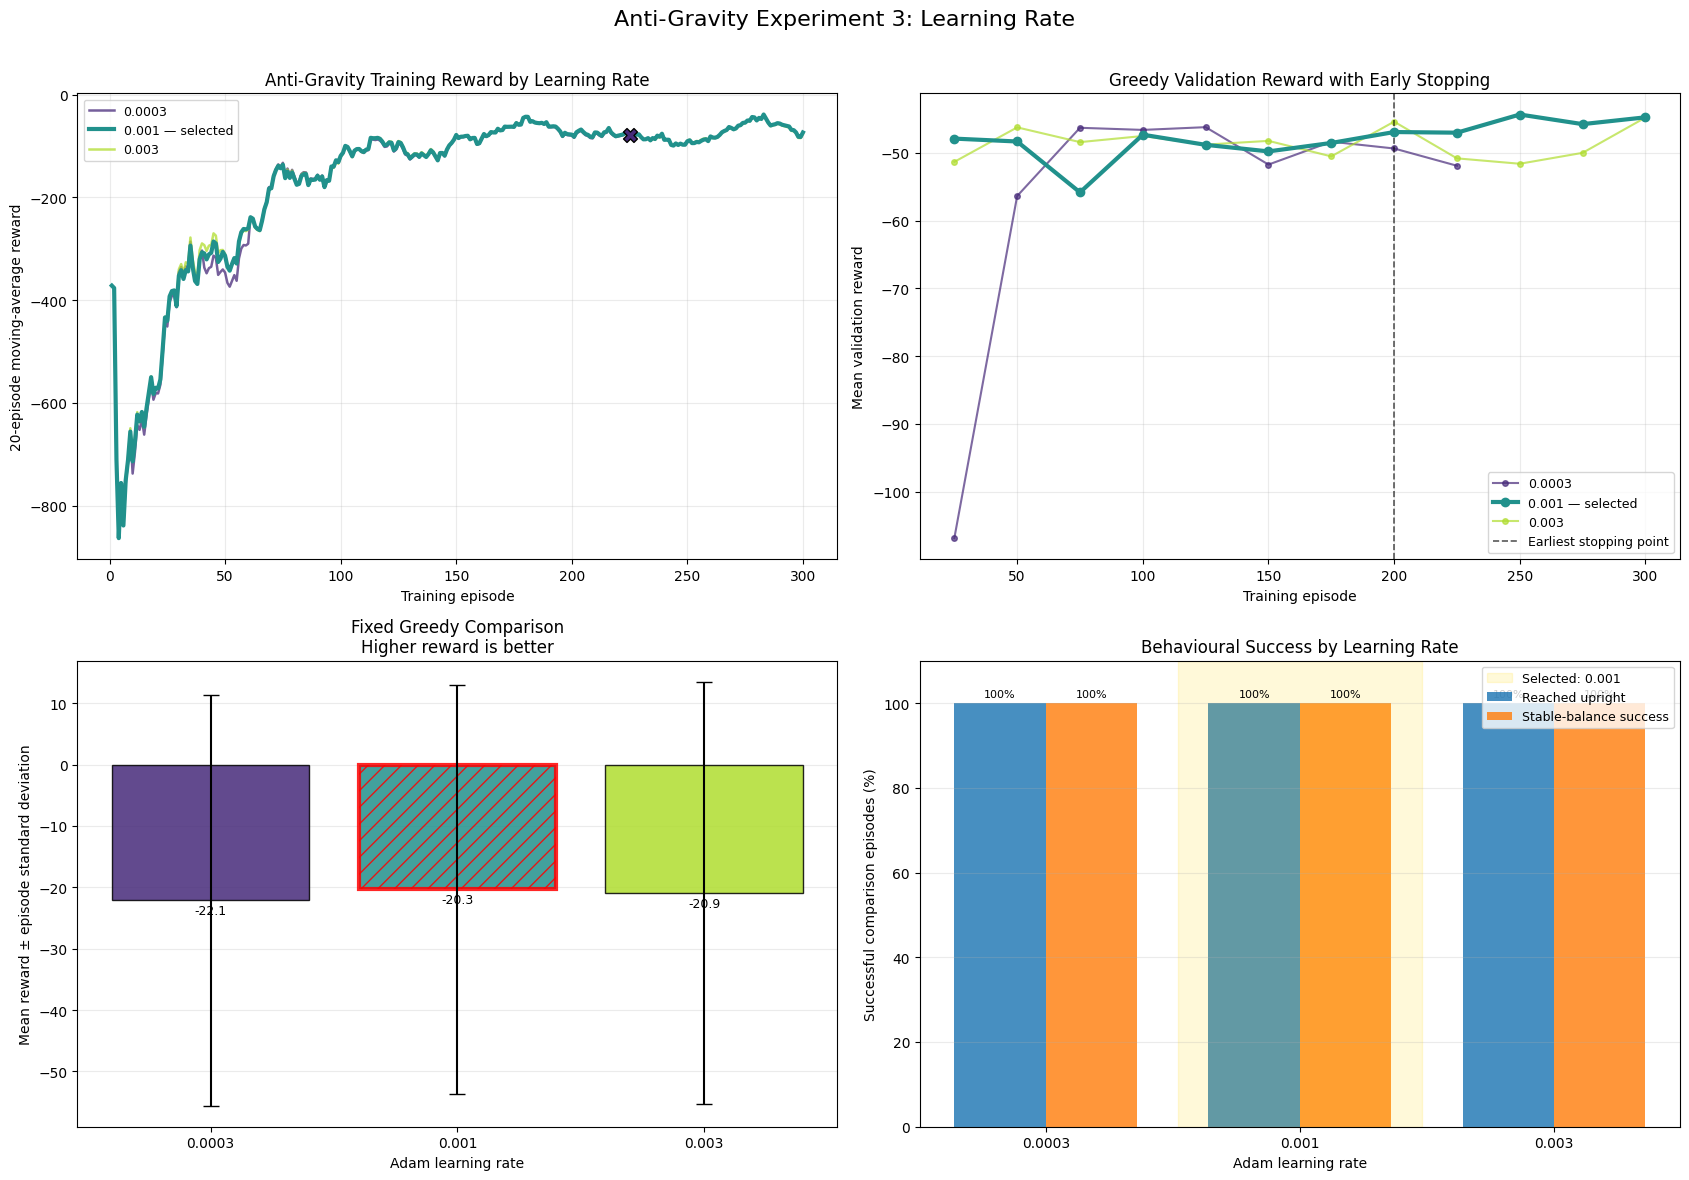

Figure saved to: figures\anti_gravity\anti_learning_rate_experiment.png


In [82]:
# ---------------------------------------------------------
# Anti-Gravity Experiment 3 visualisation
# ---------------------------------------------------------

learning_plot_rates = np.array(
    sorted(ANTI_LEARNING_RATES),
    dtype=float,
)


learning_colours = {
    float(rate): colour

    for rate, colour in zip(
        learning_plot_rates,

        plt.cm.viridis(
            np.linspace(
                0.12,
                0.88,
                len(learning_plot_rates),
            )
        ),
    )
}


fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 12),
)


# ---------------------------------------------------------
# Plot 1: Training curves
# ---------------------------------------------------------

for learning_rate in learning_plot_rates:
    run_training = (
        anti_learning_training_all_dataframe.loc[
            np.isclose(
                anti_learning_training_all_dataframe[
                    "learning_rate"
                ],
                learning_rate,
            )
        ]
        .sort_values("episode")
    )


    is_selected = np.isclose(
        learning_rate,
        ANTI_SELECTED_LEARNING_RATE,
    )


    axes[0, 0].plot(
        run_training["episode"],

        run_training[
            "moving_average_reward"
        ],

        color=learning_colours[
            float(learning_rate)
        ],

        linewidth=(
            3.0 if is_selected else 1.8
        ),

        alpha=(
            1.0 if is_selected else 0.75
        ),

        label=(
            f"{learning_rate:g}"
            + (
                " — selected"
                if is_selected
                else ""
            )
        ),

        zorder=(
            5 if is_selected else 2
        ),
    )


    result_row = (
        anti_learning_results_dataframe.loc[
            np.isclose(
                anti_learning_results_dataframe[
                    "learning_rate"
                ],
                learning_rate,
            )
        ].iloc[0]
    )


    # Mark where an early-stopped run ended.
    if bool(
        result_row["stopped_early"]
    ):
        axes[0, 0].scatter(
            run_training[
                "episode"
            ].iloc[-1],

            run_training[
                "moving_average_reward"
            ].iloc[-1],

            marker="X",
            s=100,

            color=learning_colours[
                float(learning_rate)
            ],

            edgecolor="black",
            zorder=7,
        )


axes[0, 0].set_title(
    "Anti-Gravity Training Reward "
    "by Learning Rate"
)

axes[0, 0].set_xlabel(
    "Training episode"
)

axes[0, 0].set_ylabel(
    "20-episode moving-average reward"
)

axes[0, 0].grid(
    alpha=0.25
)

axes[0, 0].legend(
    fontsize=9
)


# ---------------------------------------------------------
# Plot 2: Greedy validation curves
# ---------------------------------------------------------

for learning_rate in learning_plot_rates:
    run_validation = (
        anti_learning_validation_all_dataframe.loc[
            np.isclose(
                anti_learning_validation_all_dataframe[
                    "learning_rate"
                ],
                learning_rate,
            )
        ]
        .sort_values("training_episode")
    )


    is_selected = np.isclose(
        learning_rate,
        ANTI_SELECTED_LEARNING_RATE,
    )


    axes[0, 1].plot(
        run_validation[
            "training_episode"
        ],

        run_validation[
            "validation_mean_reward"
        ],

        color=learning_colours[
            float(learning_rate)
        ],

        marker="o",

        markersize=(
            6 if is_selected else 4
        ),

        linewidth=(
            3.0 if is_selected else 1.5
        ),

        alpha=(
            1.0 if is_selected else 0.70
        ),

        label=(
            f"{learning_rate:g}"
            + (
                " — selected"
                if is_selected
                else ""
            )
        ),

        zorder=(
            5 if is_selected else 2
        ),
    )


axes[0, 1].axvline(
    ANTI_LEARNING_MINIMUM_EPISODES,

    color="black",
    linestyle="--",
    linewidth=1.2,
    alpha=0.65,

    label="Earliest stopping point",
)


axes[0, 1].set_title(
    "Greedy Validation Reward "
    "with Early Stopping"
)

axes[0, 1].set_xlabel(
    "Training episode"
)

axes[0, 1].set_ylabel(
    "Mean validation reward"
)

axes[0, 1].grid(
    alpha=0.25
)

axes[0, 1].legend(
    fontsize=9
)


# ---------------------------------------------------------
# Prepare common bar-chart order
# ---------------------------------------------------------

results_plot = (
    anti_learning_results_dataframe
    .sort_values("learning_rate")
    .reset_index(drop=True)
)


plot_rates = (
    results_plot[
        "learning_rate"
    ]
    .astype(float)
    .to_numpy()
)


positions = np.arange(
    len(plot_rates)
)


selected_position = int(
    np.where(
        np.isclose(
            plot_rates,
            ANTI_SELECTED_LEARNING_RATE,
        )
    )[0][0]
)


# ---------------------------------------------------------
# Plot 3: Fixed greedy comparison
# ---------------------------------------------------------

comparison_bars = axes[1, 0].bar(
    positions,

    results_plot[
        "comparison_mean_reward"
    ],

    color=[
        learning_colours[
            float(rate)
        ]
        for rate in plot_rates
    ],

    alpha=0.85,
    edgecolor="black",
    linewidth=1.0,
    zorder=2,
)


axes[1, 0].errorbar(
    positions,

    results_plot[
        "comparison_mean_reward"
    ],

    yerr=results_plot[
        "comparison_reward_std"
    ],

    fmt="none",
    ecolor="black",
    elinewidth=1.5,
    capsize=6,
    zorder=4,
)


comparison_bars[
    selected_position
].set_edgecolor(
    "red"
)


comparison_bars[
    selected_position
].set_linewidth(
    3.0
)


comparison_bars[
    selected_position
].set_hatch(
    "//"
)


axes[1, 0].bar_label(
    comparison_bars,
    fmt="%.1f",
    padding=3,
    fontsize=9,
)


axes[1, 0].set_title(
    "Fixed Greedy Comparison\n"
    "Higher reward is better"
)

axes[1, 0].set_xlabel(
    "Adam learning rate"
)

axes[1, 0].set_ylabel(
    "Mean reward ± episode standard deviation"
)

axes[1, 0].set_xticks(
    positions
)

axes[1, 0].set_xticklabels(
    [
        f"{rate:g}"
        for rate in plot_rates
    ]
)

axes[1, 0].grid(
    axis="y",
    alpha=0.25,
    zorder=0,
)


# ---------------------------------------------------------
# Plot 4: Behavioural success
# ---------------------------------------------------------

bar_width = 0.36


upright_bars = axes[1, 1].bar(
    positions - bar_width / 2,

    results_plot[
        "reached_upright_rate"
    ] * 100,

    width=bar_width,
    color="tab:blue",
    alpha=0.82,

    label="Reached upright",
)


balance_bars = axes[1, 1].bar(
    positions + bar_width / 2,

    results_plot[
        "balance_success_rate"
    ] * 100,

    width=bar_width,
    color="tab:orange",
    alpha=0.82,

    label="Stable-balance success",
)


axes[1, 1].axvspan(
    selected_position - 0.48,
    selected_position + 0.48,

    color="gold",
    alpha=0.15,

    label=(
        f"Selected: "
        f"{ANTI_SELECTED_LEARNING_RATE:g}"
    ),
)


axes[1, 1].bar_label(
    upright_bars,
    fmt="%.0f%%",
    padding=3,
    fontsize=8,
)


axes[1, 1].bar_label(
    balance_bars,
    fmt="%.0f%%",
    padding=3,
    fontsize=8,
)


axes[1, 1].set_title(
    "Behavioural Success "
    "by Learning Rate"
)

axes[1, 1].set_xlabel(
    "Adam learning rate"
)

axes[1, 1].set_ylabel(
    "Successful comparison episodes (%)"
)

axes[1, 1].set_xticks(
    positions
)

axes[1, 1].set_xticklabels(
    [
        f"{rate:g}"
        for rate in plot_rates
    ]
)

axes[1, 1].set_ylim(
    0,
    110,
)

axes[1, 1].grid(
    axis="y",
    alpha=0.25,
)

axes[1, 1].legend(
    fontsize=9
)


# ---------------------------------------------------------
# Save figure
# ---------------------------------------------------------

plt.suptitle(
    "Anti-Gravity Experiment 3: "
    "Learning Rate",
    fontsize=16,
)


plt.tight_layout(
    rect=[0, 0, 1, 0.97]
)


anti_learning_figure_path = (
    ANTI_FIGURES_DIR
    / "anti_learning_rate_experiment.png"
)


plt.savefig(
    anti_learning_figure_path,
    dpi=150,
    bbox_inches="tight",
)


plt.show()


print(
    "Figure saved to:",
    anti_learning_figure_path,
)

## Anti-Gravity Experiment 3 Evaluation: Learning Rate

This experiment compared Adam learning rates of **0.0003, 0.001 and 0.003**. The five-action discretisation, `[64, 64]` network architecture, epsilon decay of `0.995`, training seed, validation episodes and early-stopping conditions were kept constant. Since Pendulum rewards are negative, values closer to zero indicate better performance.

### Results

| Learning rate | Trained episodes | Best checkpoint | Best validation reward | Comparison reward |
|---:|---:|---:|---:|---:|
| **0.001** | 300 | 250 | **−44.372** | **−20.310 ± 33.370** |
| 0.003 | 300 | 300 | −44.820 | −20.897 ± 34.386 |
| 0.0003 | 225 | 125 | −46.237 | −22.076 ± 33.497 |

The learning rate of **0.001 ranked first**. It produced the highest validation reward and the highest fixed-comparison reward. It exceeded 0.003 by **0.587 reward points** and 0.0003 by **1.766 reward points**.

All three configurations reached the upright position and achieved stable balancing in **100% of the comparison episodes**. Therefore, the behavioural success metrics could not distinguish them. The reward metric provided a more detailed comparison because it also penalises deviations from the upright position, angular velocity and excessive torque.

The learning rate of 0.0003 recorded the highest mean upright duration at 187.45 steps, but its comparison reward was the lowest. This suggests that remaining near the broad upright threshold does not necessarily produce the most controlled or reward-efficient behaviour. It also stopped early at episode 225 after its validation performance failed to improve sufficiently.

### Training and validation behaviour

All three models showed substantial learning, with their moving-average rewards improving from very poor initial values toward successful balancing performance. The 0.0003 model had particularly weak validation performance at the beginning before recovering. The 0.001 and 0.003 models trained for the full 300 episodes, while 0.0003 was stopped early.

The 0.001 model produced the strongest overall combination of validation reward, comparison reward and perfect behavioural success. However, the reward differences were small compared with the episode standard deviations of approximately 33–34 points.

### Limitation

Only one training seed and 20 fixed comparison episodes were used. Therefore, this experiment does not prove that 0.001 is statistically superior across all training runs. It represents the best observed configuration under the controlled experimental conditions.

### Conclusion

A moderate learning rate of **0.001** provided the best observed performance. The smaller rate learned more slowly, while increasing the rate to 0.003 did not improve the final reward.

Therefore, **`learning_rate = 0.001` is selected for Experiment 4**, which compares Standard DQN with Double DQN.

In [83]:
# ---------------------------------------------------------
# Anti-Gravity Experiment 4:
# Standard DQN versus Double DQN
# ---------------------------------------------------------

ANTI_ALGORITHM_SETTINGS = {
    "standard_dqn": {
        "label": "Standard DQN",
        "use_double_dqn": False,
    },
    "double_dqn": {
        "label": "Double DQN",
        "use_double_dqn": True,
    },
}


# Use a completely new directory so both algorithms
# are trained freshly for this experiment.
ANTI_ALGORITHM_RESULTS_DIR = (
    ANTI_RESULTS_DIR
    / "algorithm_experiment_early_stopping_fresh"
)

ANTI_ALGORITHM_WEIGHTS_DIR = (
    ANTI_WEIGHTS_DIR
    / "algorithm_experiment_early_stopping_fresh"
)

for directory in [
    ANTI_ALGORITHM_RESULTS_DIR,
    ANTI_ALGORITHM_WEIGHTS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# Identical experimental settings for both algorithms.
ANTI_ALGORITHM_TRAINING_SEED = (
    ANTI_LEARNING_TRAINING_SEED
)

ANTI_ALGORITHM_VALIDATION_SEED = (
    ANTI_LEARNING_VALIDATION_SEED
)

# Use unseen episodes for the final comparison.
ANTI_ALGORITHM_COMPARISON_SEED = (
    ANTI_LEARNING_COMPARISON_SEED + 10_000
)

ANTI_ALGORITHM_MAX_EPISODES = (
    ANTI_LEARNING_MAX_EPISODES
)

ANTI_ALGORITHM_MAX_STEPS = (
    ANTI_LEARNING_MAX_STEPS
)

ANTI_ALGORITHM_EVALUATION_EVERY = (
    ANTI_LEARNING_EVALUATION_EVERY
)

ANTI_ALGORITHM_VALIDATION_EPISODES = (
    ANTI_LEARNING_VALIDATION_EPISODES
)

ANTI_ALGORITHM_COMPARISON_EPISODES = 20

ANTI_ALGORITHM_MINIMUM_EPISODES = (
    ANTI_LEARNING_MINIMUM_EPISODES
)

ANTI_ALGORITHM_EARLY_STOPPING_PATIENCE = (
    ANTI_LEARNING_EARLY_STOPPING_PATIENCE
)

ANTI_ALGORITHM_EARLY_STOPPING_MIN_DELTA = (
    ANTI_LEARNING_EARLY_STOPPING_MIN_DELTA
)


def get_anti_algorithm_paths(algorithm_id):
    run_name = (
        f"fresh_{algorithm_id}_"
        f"seed_{ANTI_ALGORITHM_TRAINING_SEED}"
    )

    return {
        "weights": (
            ANTI_ALGORITHM_WEIGHTS_DIR
            / f"{run_name}.weights.h5"
        ),
        "training": (
            ANTI_ALGORITHM_RESULTS_DIR
            / f"{run_name}_training.csv"
        ),
        "validation": (
            ANTI_ALGORITHM_RESULTS_DIR
            / f"{run_name}_validation.csv"
        ),
        "checkpoint": (
            ANTI_ALGORITHM_RESULTS_DIR
            / f"{run_name}_checkpoint.csv"
        ),
        "comparison": (
            ANTI_ALGORITHM_RESULTS_DIR
            / f"{run_name}_comparison.csv"
        ),
    }


ANTI_ALGORITHM_RUN_PATHS = {
    algorithm_id: get_anti_algorithm_paths(
        algorithm_id
    )
    for algorithm_id in ANTI_ALGORITHM_SETTINGS
}


algorithm_setup_dataframe = pd.DataFrame([
    {
        "algorithm": settings["label"],
        "use_double_dqn": settings[
            "use_double_dqn"
        ],
        "action_count": (
            ANTI_SELECTED_ACTION_COUNT
        ),
        "epsilon_decay": (
            ANTI_SELECTED_EPSILON_DECAY
        ),
        "learning_rate": (
            ANTI_SELECTED_LEARNING_RATE
        ),
        "architecture": "[64, 64]",
        "fresh_training": True,
    }
    for settings in ANTI_ALGORITHM_SETTINGS.values()
])

display(algorithm_setup_dataframe)

print(
    "Both algorithms will be trained freshly "
    "with identical experimental settings."
)

,algorithm,use_double_dqn,action_count,epsilon_decay,learning_rate,architecture,fresh_training
0,Standard DQN,False,5,0.995,0.001,"[64, 64]",True
1,Double DQN,True,5,0.995,0.001,"[64, 64]",True


Both algorithms will be trained freshly with identical experimental settings.


In [84]:
# ---------------------------------------------------------
# Train fresh Standard DQN and Double DQN models
# ---------------------------------------------------------

for run_number, (
    algorithm_id,
    settings,
) in enumerate(
    ANTI_ALGORITHM_SETTINGS.items(),
    start=1,
):
    run_paths = ANTI_ALGORITHM_RUN_PATHS[
        algorithm_id
    ]

    required_training_paths = [
        run_paths["weights"],
        run_paths["training"],
        run_paths["validation"],
        run_paths["checkpoint"],
    ]

    run_is_complete = all(
        path.exists()
        for path in required_training_paths
    )

    if run_is_complete:
        print(
            f"{settings['label']}: "
            "saved fresh results already exist."
        )
        continue


    print("\n" + "=" * 70)
    print(
        f"RUN {run_number}/2 | "
        f"{settings['label'].upper()}"
    )
    print("=" * 70)
    print("Initialising a completely fresh model.")


    tf.keras.backend.clear_session()

    set_global_seed(
        ANTI_ALGORITHM_TRAINING_SEED
    )


    training_env = None
    validation_env = None
    algorithm_agent = None


    try:
        current_config = make_anti_learning_config(
            ANTI_SELECTED_LEARNING_RATE
        )


        training_env = create_pendulum_env(
            gravity=ANTI_GRAVITY_VALUE,
            seed=ANTI_ALGORITHM_TRAINING_SEED,
        )


        validation_env = create_pendulum_env(
            gravity=ANTI_GRAVITY_VALUE,
            seed=ANTI_ALGORITHM_VALIDATION_SEED,
        )


        algorithm_agent = DQNAgent(
            state_size=ANTI_STATE_SIZE,

            action_values=(
                ANTI_SELECTED_ACTION_VALUES
            ),

            config=current_config,

            use_double_dqn=settings[
                "use_double_dqn"
            ],
        )


        (
            algorithm_history,
            algorithm_training_dataframe,
        ) = train_agent(
            env=training_env,
            agent=algorithm_agent,

            episodes=(
                ANTI_ALGORITHM_MAX_EPISODES
            ),

            max_steps=(
                ANTI_ALGORITHM_MAX_STEPS
            ),

            moving_average_window=20,
            seed=ANTI_ALGORITHM_TRAINING_SEED,

            evaluation_env=validation_env,

            evaluation_every=(
                ANTI_ALGORITHM_EVALUATION_EVERY
            ),

            evaluation_episodes=(
                ANTI_ALGORITHM_VALIDATION_EPISODES
            ),

            evaluation_seed=(
                ANTI_ALGORITHM_VALIDATION_SEED
            ),

            best_weights_path=(
                run_paths["weights"]
            ),

            print_every=25,
            render_every=None,

            early_stopping_minimum_episodes=(
                ANTI_ALGORITHM_MINIMUM_EPISODES
            ),

            early_stopping_patience=(
                ANTI_ALGORITHM_EARLY_STOPPING_PATIENCE
            ),

            early_stopping_min_delta=(
                ANTI_ALGORITHM_EARLY_STOPPING_MIN_DELTA
            ),
        )


        # ---------------------------------------------
        # Save training history
        # ---------------------------------------------

        algorithm_training_dataframe.insert(
            0,
            "training_seed",
            ANTI_ALGORITHM_TRAINING_SEED,
        )

        algorithm_training_dataframe.insert(
            0,
            "learning_rate",
            ANTI_SELECTED_LEARNING_RATE,
        )

        algorithm_training_dataframe.insert(
            0,
            "epsilon_decay",
            ANTI_SELECTED_EPSILON_DECAY,
        )

        algorithm_training_dataframe.insert(
            0,
            "action_count",
            ANTI_SELECTED_ACTION_COUNT,
        )

        algorithm_training_dataframe.insert(
            0,
            "algorithm_label",
            settings["label"],
        )

        algorithm_training_dataframe.insert(
            0,
            "algorithm_id",
            algorithm_id,
        )


        algorithm_training_dataframe.to_csv(
            run_paths["training"],
            index=False,
        )


        # ---------------------------------------------
        # Save validation history
        # ---------------------------------------------

        algorithm_validation_dataframe = pd.DataFrame({
            "algorithm_id": algorithm_id,
            "algorithm_label": settings["label"],

            "training_seed": (
                ANTI_ALGORITHM_TRAINING_SEED
            ),

            "training_episode": algorithm_history[
                "evaluation_episode"
            ],

            "validation_mean_reward": algorithm_history[
                "evaluation_mean_reward"
            ],

            "validation_reward_std": algorithm_history[
                "evaluation_reward_std"
            ],

            "validation_improved": algorithm_history[
                "evaluation_improved"
            ],

            "validations_without_improvement": (
                algorithm_history[
                    "validations_without_improvement"
                ]
            ),
        })


        algorithm_validation_dataframe.to_csv(
            run_paths["validation"],
            index=False,
        )


        # ---------------------------------------------
        # Save best-checkpoint information
        # ---------------------------------------------

        validation_means = np.asarray(
            algorithm_history[
                "evaluation_mean_reward"
            ],
            dtype=float,
        )

        if len(validation_means) == 0:
            raise RuntimeError(
                "No validation results were produced."
            )


        best_position = int(
            np.argmax(validation_means)
        )


        algorithm_checkpoint_dataframe = pd.DataFrame([
            {
                "algorithm_id": algorithm_id,

                "algorithm_label": (
                    settings["label"]
                ),

                "use_double_dqn": settings[
                    "use_double_dqn"
                ],

                "training_seed": (
                    ANTI_ALGORITHM_TRAINING_SEED
                ),

                "trained_episodes": int(
                    algorithm_history[
                        "stop_episode"
                    ]
                ),

                "stopped_early": bool(
                    algorithm_history[
                        "stopped_early"
                    ]
                ),

                "best_checkpoint_episode": int(
                    algorithm_history[
                        "evaluation_episode"
                    ][best_position]
                ),

                "best_validation_mean_reward": float(
                    validation_means[
                        best_position
                    ]
                ),

                "best_validation_reward_std": float(
                    algorithm_history[
                        "evaluation_reward_std"
                    ][best_position]
                ),

                "final_training_epsilon": float(
                    algorithm_agent.epsilon
                ),

                "parameter_count": int(
                    algorithm_agent
                    .online_network
                    .count_params()
                ),
            }
        ])


        algorithm_checkpoint_dataframe.to_csv(
            run_paths["checkpoint"],
            index=False,
        )


        print(
            f"{settings['label']} completed | "
            f"trained episodes: "
            f"{algorithm_history['stop_episode']} | "
            f"stopped early: "
            f"{algorithm_history['stopped_early']} | "
            f"best checkpoint: episode "
            f"{algorithm_history['evaluation_episode'][best_position]} | "
            f"best validation reward: "
            f"{validation_means[best_position]:.3f}"
        )


    finally:
        if training_env is not None:
            training_env.close()

        if validation_env is not None:
            validation_env.close()

        algorithm_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


RUN 1/2 | STANDARD DQN
Initialising a completely fresh model.
Episode    1/300 | Reward:  -371.65 | Moving average:  -371.65 | Epsilon: 0.9950 | Loss: not training yet | Replay size: 200
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\algorithm_experiment_early_stopping_fresh\fresh_standard_dqn_seed_123.weights.h5
Evaluation at episode 25: mean reward = -47.93, std = 51.97, wait = 0/4
New best weights saved.
Episode   25/300 | Reward:  -459.35 | Moving average:  -440.25 | Epsilon: 0.8822 | Loss: 0.3515 | Replay size: 5000
Evaluation at episode 50: mean reward = -48.35, std = 47.94, wait = 1/4
Episode   50/300 | Reward:  -203.82 | Moving average:  -313.50 | Epsilon: 0.7783 | Loss: 0.3299 | Replay size: 10000
Evaluation at episode 75: mean reward = -55.85, std = 49.36, wait = 2/4
Episode   75/300 | Reward:  -122.89 | Moving average:  -136.25 | Epsilon: 0.6866 | Loss: 0.2289 | Replay size: 15000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity

In [85]:
# ---------------------------------------------------------
# Evaluate both algorithms on identical unseen episodes
# ---------------------------------------------------------

anti_algorithm_result_records = []
anti_algorithm_episode_frames = []

anti_algorithm_training_frames = []
anti_algorithm_validation_frames = []


for algorithm_id, settings in (
    ANTI_ALGORITHM_SETTINGS.items()
):
    run_paths = ANTI_ALGORITHM_RUN_PATHS[
        algorithm_id
    ]


    for required_name in [
        "weights",
        "training",
        "validation",
        "checkpoint",
    ]:
        required_path = run_paths[
            required_name
        ]

        if not required_path.exists():
            raise FileNotFoundError(
                f"Missing {settings['label']} file: "
                f"{required_path.resolve()}"
            )


    training_dataframe = pd.read_csv(
        run_paths["training"]
    )

    validation_dataframe = pd.read_csv(
        run_paths["validation"]
    )

    checkpoint_dataframe = pd.read_csv(
        run_paths["checkpoint"]
    )


    anti_algorithm_training_frames.append(
        training_dataframe
    )

    anti_algorithm_validation_frames.append(
        validation_dataframe
    )


    checkpoint_row = checkpoint_dataframe.iloc[0]


    tf.keras.backend.clear_session()

    set_global_seed(
        ANTI_ALGORITHM_TRAINING_SEED
    )


    comparison_env = None
    evaluation_agent = None


    try:
        current_config = make_anti_learning_config(
            ANTI_SELECTED_LEARNING_RATE
        )


        comparison_env = create_pendulum_env(
            gravity=ANTI_GRAVITY_VALUE,
            seed=ANTI_ALGORITHM_COMPARISON_SEED,
        )


        evaluation_agent = DQNAgent(
            state_size=ANTI_STATE_SIZE,

            action_values=(
                ANTI_SELECTED_ACTION_VALUES
            ),

            config=current_config,

            use_double_dqn=settings[
                "use_double_dqn"
            ],
        )


        evaluation_agent.load_weights(
            run_paths["weights"]
        )


        comparison_result = evaluate_agent(
            env=comparison_env,
            agent=evaluation_agent,

            episodes=(
                ANTI_ALGORITHM_COMPARISON_EPISODES
            ),

            max_steps=(
                ANTI_ALGORITHM_MAX_STEPS
            ),

            seed=(
                ANTI_ALGORITHM_COMPARISON_SEED
            ),

            best_score=None,
            save_path=None,
            verbose=False,
        )


        stopped_early_value = (
            str(
                checkpoint_row[
                    "stopped_early"
                ]
            )
            .strip()
            .lower()
            == "true"
        )


        anti_algorithm_result_records.append({
            "algorithm_id": algorithm_id,
            "algorithm_label": settings["label"],

            "use_double_dqn": settings[
                "use_double_dqn"
            ],

            "action_count": (
                ANTI_SELECTED_ACTION_COUNT
            ),

            "epsilon_decay": (
                ANTI_SELECTED_EPSILON_DECAY
            ),

            "learning_rate": (
                ANTI_SELECTED_LEARNING_RATE
            ),

            "architecture": "[64, 64]",

            "training_seed": (
                ANTI_ALGORITHM_TRAINING_SEED
            ),

            "trained_episodes": int(
                checkpoint_row[
                    "trained_episodes"
                ]
            ),

            "stopped_early": (
                stopped_early_value
            ),

            "best_checkpoint_episode": int(
                checkpoint_row[
                    "best_checkpoint_episode"
                ]
            ),

            "best_validation_mean_reward": float(
                checkpoint_row[
                    "best_validation_mean_reward"
                ]
            ),

            "comparison_mean_reward": (
                comparison_result[
                    "mean_reward"
                ]
            ),

            "comparison_reward_std": (
                comparison_result[
                    "reward_std"
                ]
            ),

            "comparison_minimum_reward": (
                comparison_result[
                    "minimum_reward"
                ]
            ),

            "comparison_maximum_reward": (
                comparison_result[
                    "maximum_reward"
                ]
            ),

            "reached_upright_rate": (
                comparison_result[
                    "reached_upright_rate"
                ]
            ),

            "balance_success_rate": (
                comparison_result[
                    "balance_success_rate"
                ]
            ),

            "mean_upright_steps": (
                comparison_result[
                    "mean_upright_steps"
                ]
            ),

            "mean_longest_balance_streak": (
                comparison_result[
                    "mean_longest_balance_streak"
                ]
            ),
        })


        episode_dataframe = pd.DataFrame(
            comparison_result[
                "episode_metrics"
            ]
        )


        episode_dataframe.insert(
            0,
            "algorithm_label",
            settings["label"],
        )

        episode_dataframe.insert(
            0,
            "algorithm_id",
            algorithm_id,
        )


        episode_dataframe.to_csv(
            run_paths["comparison"],
            index=False,
        )


        anti_algorithm_episode_frames.append(
            episode_dataframe
        )


        print(
            f"{settings['label']}: "
            f"{comparison_result['mean_reward']:.2f} "
            f"± "
            f"{comparison_result['reward_std']:.2f} | "
            f"Upright: "
            f"{comparison_result['reached_upright_rate']:.1%} | "
            f"Balance: "
            f"{comparison_result['balance_success_rate']:.1%}"
        )


    finally:
        if comparison_env is not None:
            comparison_env.close()

        evaluation_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


# ---------------------------------------------------------
# Combine and rank results
# ---------------------------------------------------------

anti_algorithm_results_dataframe = pd.DataFrame(
    anti_algorithm_result_records
)


anti_algorithm_summary_dataframe = (
    anti_algorithm_results_dataframe
    .sort_values(
        [
            "comparison_mean_reward",
            "comparison_reward_std",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)


anti_algorithm_summary_dataframe.insert(
    0,
    "rank",
    np.arange(
        1,
        len(anti_algorithm_summary_dataframe) + 1,
    ),
)


anti_algorithm_training_all_dataframe = pd.concat(
    anti_algorithm_training_frames,
    ignore_index=True,
)


anti_algorithm_validation_all_dataframe = pd.concat(
    anti_algorithm_validation_frames,
    ignore_index=True,
)


anti_algorithm_episode_dataframe = pd.concat(
    anti_algorithm_episode_frames,
    ignore_index=True,
)


# Pair the rewards from identical evaluation episodes.
anti_algorithm_paired_dataframe = (
    anti_algorithm_episode_dataframe
    .pivot(
        index=[
            "evaluation_episode",
            "evaluation_seed",
        ],
        columns="algorithm_id",
        values="reward",
    )
    .reset_index()
)


anti_algorithm_paired_dataframe[
    "double_minus_standard"
] = (
    anti_algorithm_paired_dataframe[
        "double_dqn"
    ]
    - anti_algorithm_paired_dataframe[
        "standard_dqn"
    ]
)


ANTI_SELECTED_ALGORITHM_ID = str(
    anti_algorithm_summary_dataframe.iloc[0][
        "algorithm_id"
    ]
)


ANTI_SELECTED_USE_DOUBLE_DQN = bool(
    ANTI_ALGORITHM_SETTINGS[
        ANTI_SELECTED_ALGORITHM_ID
    ]["use_double_dqn"]
)


ANTI_SELECTED_ALGORITHM_PATHS = (
    ANTI_ALGORITHM_RUN_PATHS[
        ANTI_SELECTED_ALGORITHM_ID
    ]
)


# ---------------------------------------------------------
# Save combined outputs
# ---------------------------------------------------------

anti_algorithm_summary_dataframe.to_csv(
    ANTI_ALGORITHM_RESULTS_DIR
    / "anti_algorithm_summary.csv",
    index=False,
)


anti_algorithm_training_all_dataframe.to_csv(
    ANTI_ALGORITHM_RESULTS_DIR
    / "anti_algorithm_training_all.csv",
    index=False,
)


anti_algorithm_validation_all_dataframe.to_csv(
    ANTI_ALGORITHM_RESULTS_DIR
    / "anti_algorithm_validation_all.csv",
    index=False,
)


anti_algorithm_episode_dataframe.to_csv(
    ANTI_ALGORITHM_RESULTS_DIR
    / "anti_algorithm_episode_metrics.csv",
    index=False,
)


anti_algorithm_paired_dataframe.to_csv(
    ANTI_ALGORITHM_RESULTS_DIR
    / "anti_algorithm_paired_differences.csv",
    index=False,
)


# Display percentages rather than proportions.
anti_algorithm_display_dataframe = (
    anti_algorithm_summary_dataframe.copy()
)

anti_algorithm_display_dataframe[
    "reached_upright_rate"
] *= 100

anti_algorithm_display_dataframe[
    "balance_success_rate"
] *= 100


print(
    "\nSelected anti-gravity algorithm:",
    ANTI_ALGORITHM_SETTINGS[
        ANTI_SELECTED_ALGORITHM_ID
    ]["label"],
)


display(
    anti_algorithm_display_dataframe[
        [
            "rank",
            "algorithm_label",
            "trained_episodes",
            "stopped_early",
            "best_checkpoint_episode",
            "best_validation_mean_reward",
            "comparison_mean_reward",
            "comparison_reward_std",
            "reached_upright_rate",
            "balance_success_rate",
            "mean_upright_steps",
            "mean_longest_balance_streak",
        ]
    ].round(3)
)


print("\nPaired episode differences:")

display(
    anti_algorithm_paired_dataframe.round(3)
)

Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\algorithm_experiment_early_stopping_fresh\fresh_standard_dqn_seed_123.weights.h5
Standard DQN: -25.18 ± 33.91 | Upright: 100.0% | Balance: 100.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\algorithm_experiment_early_stopping_fresh\fresh_double_dqn_seed_123.weights.h5
Double DQN: -25.91 ± 34.30 | Upright: 100.0% | Balance: 100.0%

Selected anti-gravity algorithm: Standard DQN


,rank,algorithm_label,trained_episodes,stopped_early,best_checkpoint_episode,best_validation_mean_reward,comparison_mean_reward,comparison_reward_std,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,1,Standard DQN,300,False,250,-44.372,-25.183,33.913,100.0,100.0,185.55,178.8
1,2,Double DQN,200,True,100,-44.913,-25.908,34.302,100.0,100.0,186.10,172.3



Paired episode differences:


algorithm_id,evaluation_episode,evaluation_seed,double_dqn,standard_dqn,double_minus_standard
0,1,60000,-59.399,-58.714,-0.685
1,2,60001,-4.165,-3.027,-1.138
2,3,60002,-3.734,-3.666,-0.068
3,4,60003,-5.005,-4.007,-0.998
4,5,60004,-26.081,-25.203,-0.879
5,6,60005,-1.114,-0.421,-0.693
6,7,60006,-60.338,-59.834,-0.503
7,8,60007,-6.715,-5.469,-1.246
8,9,60008,-63.740,-62.543,-1.198
9,10,60009,-143.285,-140.452,-2.833


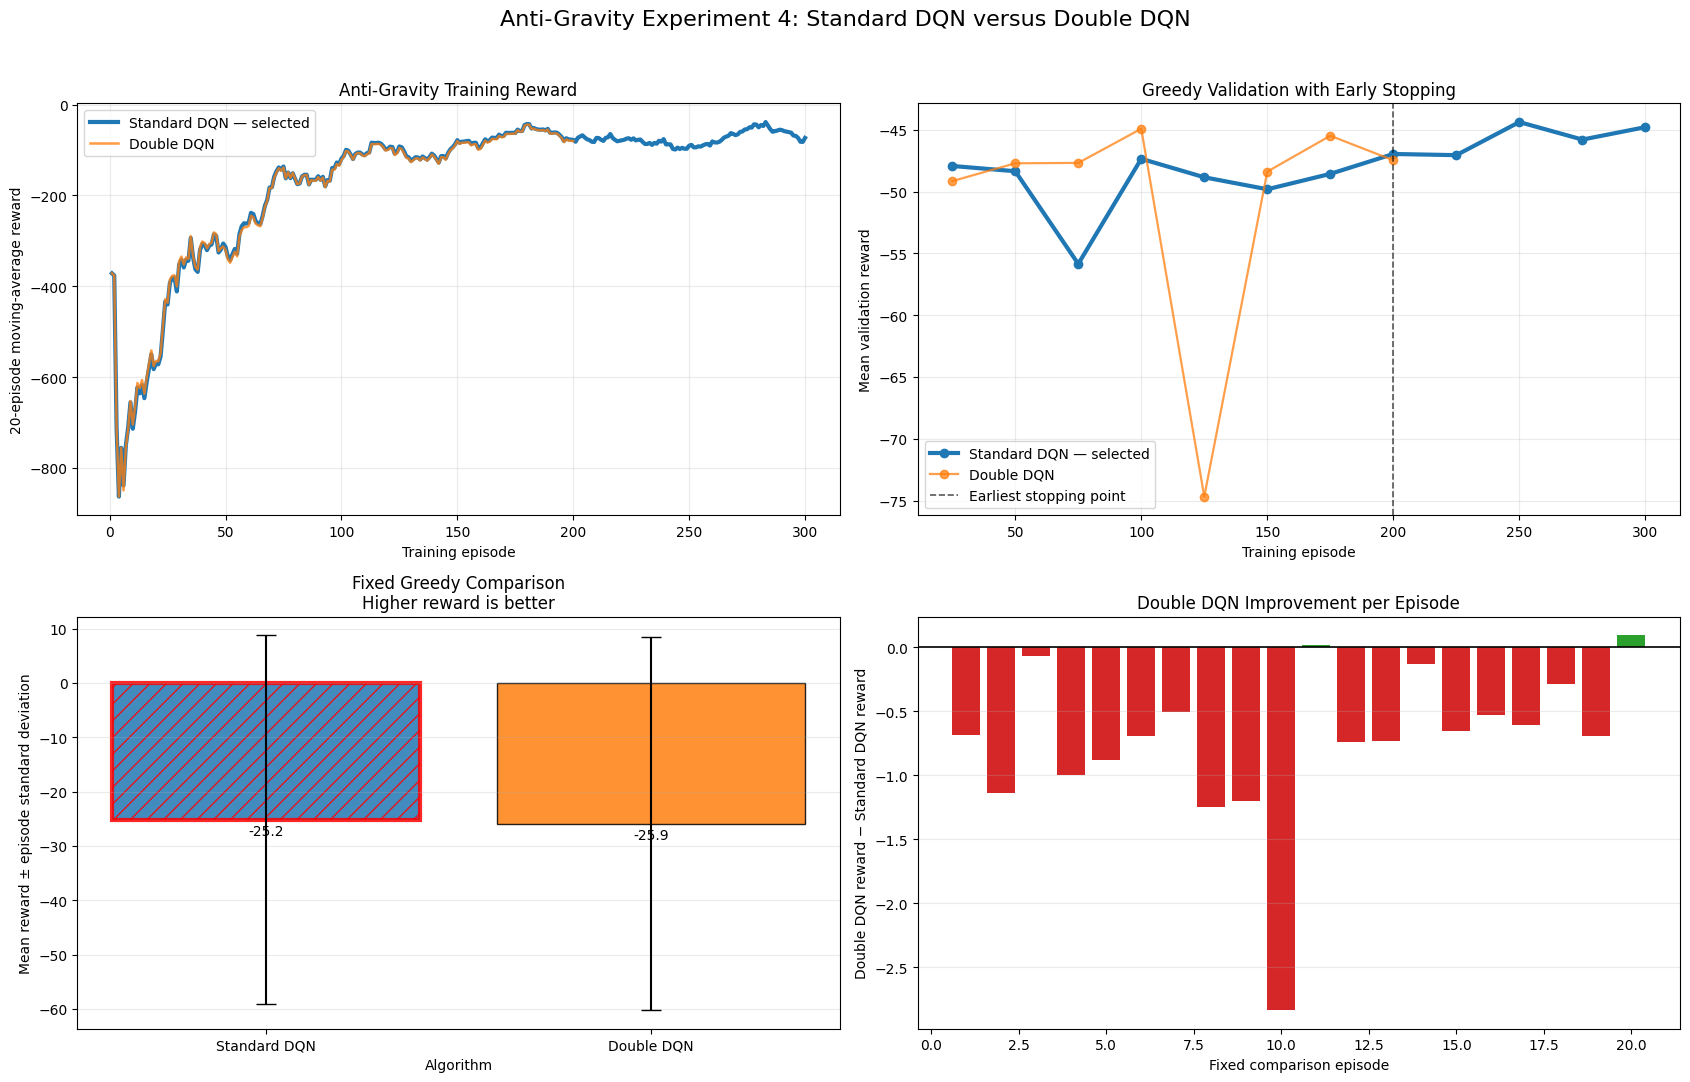

Figure saved to: figures\anti_gravity\anti_dqn_vs_double_dqn.png


In [86]:
# ---------------------------------------------------------
# Experiment 4 visualisation
# ---------------------------------------------------------

algorithm_ids = [
    "standard_dqn",
    "double_dqn",
]

algorithm_colours = {
    "standard_dqn": "tab:blue",
    "double_dqn": "tab:orange",
}


fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 11),
)


# ---------------------------------------------------------
# Plot 1: Training reward
# ---------------------------------------------------------

for algorithm_id in algorithm_ids:
    run_training = (
        anti_algorithm_training_all_dataframe.loc[
            anti_algorithm_training_all_dataframe[
                "algorithm_id"
            ] == algorithm_id
        ]
        .sort_values("episode")
    )

    is_selected = (
        algorithm_id
        == ANTI_SELECTED_ALGORITHM_ID
    )

    axes[0, 0].plot(
        run_training["episode"],

        run_training[
            "moving_average_reward"
        ],

        color=algorithm_colours[
            algorithm_id
        ],

        linewidth=(
            3.0 if is_selected else 1.8
        ),

        alpha=(
            1.0 if is_selected else 0.78
        ),

        label=(
            ANTI_ALGORITHM_SETTINGS[
                algorithm_id
            ]["label"]
            + (
                " — selected"
                if is_selected
                else ""
            )
        ),
    )


axes[0, 0].set_title(
    "Anti-Gravity Training Reward"
)

axes[0, 0].set_xlabel(
    "Training episode"
)

axes[0, 0].set_ylabel(
    "20-episode moving-average reward"
)

axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend()


# ---------------------------------------------------------
# Plot 2: Periodic greedy validation
# ---------------------------------------------------------

for algorithm_id in algorithm_ids:
    run_validation = (
        anti_algorithm_validation_all_dataframe.loc[
            anti_algorithm_validation_all_dataframe[
                "algorithm_id"
            ] == algorithm_id
        ]
        .sort_values("training_episode")
    )

    is_selected = (
        algorithm_id
        == ANTI_SELECTED_ALGORITHM_ID
    )

    axes[0, 1].plot(
        run_validation[
            "training_episode"
        ],

        run_validation[
            "validation_mean_reward"
        ],

        marker="o",

        color=algorithm_colours[
            algorithm_id
        ],

        linewidth=(
            3.0 if is_selected else 1.6
        ),

        alpha=(
            1.0 if is_selected else 0.75
        ),

        label=(
            ANTI_ALGORITHM_SETTINGS[
                algorithm_id
            ]["label"]
            + (
                " — selected"
                if is_selected
                else ""
            )
        ),
    )


axes[0, 1].axvline(
    ANTI_ALGORITHM_MINIMUM_EPISODES,
    color="black",
    linestyle="--",
    linewidth=1.2,
    alpha=0.65,
    label="Earliest stopping point",
)


axes[0, 1].set_title(
    "Greedy Validation with Early Stopping"
)

axes[0, 1].set_xlabel(
    "Training episode"
)

axes[0, 1].set_ylabel(
    "Mean validation reward"
)

axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend()


# ---------------------------------------------------------
# Plot 3: Fixed greedy comparison
# ---------------------------------------------------------

results_for_plot = (
    anti_algorithm_results_dataframe
    .set_index("algorithm_id")
    .loc[algorithm_ids]
    .reset_index()
)


positions = np.arange(
    len(results_for_plot)
)


comparison_bars = axes[1, 0].bar(
    positions,

    results_for_plot[
        "comparison_mean_reward"
    ],

    color=[
        algorithm_colours[
            algorithm_id
        ]
        for algorithm_id in algorithm_ids
    ],

    edgecolor="black",
    linewidth=1.0,
    alpha=0.85,
)


axes[1, 0].errorbar(
    positions,

    results_for_plot[
        "comparison_mean_reward"
    ],

    yerr=results_for_plot[
        "comparison_reward_std"
    ],

    fmt="none",
    ecolor="black",
    capsize=7,
    linewidth=1.5,
)


selected_position = algorithm_ids.index(
    ANTI_SELECTED_ALGORITHM_ID
)


comparison_bars[
    selected_position
].set_edgecolor("red")

comparison_bars[
    selected_position
].set_linewidth(3.0)

comparison_bars[
    selected_position
].set_hatch("//")


axes[1, 0].bar_label(
    comparison_bars,
    fmt="%.1f",
    padding=3,
)


axes[1, 0].set_title(
    "Fixed Greedy Comparison\n"
    "Higher reward is better"
)

axes[1, 0].set_xlabel(
    "Algorithm"
)

axes[1, 0].set_ylabel(
    "Mean reward ± episode standard deviation"
)

axes[1, 0].set_xticks(
    positions
)

axes[1, 0].set_xticklabels(
    results_for_plot[
        "algorithm_label"
    ]
)

axes[1, 0].grid(
    axis="y",
    alpha=0.25,
)


# ---------------------------------------------------------
# Plot 4: Paired episode differences
# ---------------------------------------------------------

paired_differences = (
    anti_algorithm_paired_dataframe[
        "double_minus_standard"
    ]
)


axes[1, 1].bar(
    anti_algorithm_paired_dataframe[
        "evaluation_episode"
    ],

    paired_differences,

    color=[
        (
            "tab:green"
            if difference > 0
            else "tab:red"
        )
        for difference in paired_differences
    ],
)


axes[1, 1].axhline(
    0,
    color="black",
    linewidth=1.2,
)


axes[1, 1].set_title(
    "Double DQN Improvement per Episode"
)

axes[1, 1].set_xlabel(
    "Fixed comparison episode"
)

axes[1, 1].set_ylabel(
    "Double DQN reward − Standard DQN reward"
)

axes[1, 1].grid(
    axis="y",
    alpha=0.25,
)


plt.suptitle(
    "Anti-Gravity Experiment 4: "
    "Standard DQN versus Double DQN",
    fontsize=16,
)


plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)


anti_algorithm_figure_path = (
    ANTI_FIGURES_DIR
    / "anti_dqn_vs_double_dqn.png"
)


plt.savefig(
    anti_algorithm_figure_path,
    dpi=150,
    bbox_inches="tight",
)


plt.show()


print(
    "Figure saved to:",
    anti_algorithm_figure_path,
)

## Anti-Gravity Experiment 4 Evaluation: Standard DQN versus Double DQN

This experiment compared **Standard DQN** with **Double DQN** under anti-gravity while keeping the five-action discretisation, `[64, 64]` architecture, learning rate of `0.001`, epsilon decay of `0.995`, replay settings, training seed and evaluation episodes constant. Both models were trained from scratch with validation-based early stopping.

| Algorithm        | Episodes trained | Best checkpoint | Best validation reward | Fixed comparison reward |
| ---------------- | ---------------: | --------------: | ---------------------: | ----------------------: |
| **Standard DQN** |              300 |             250 |            **−44.372** |    **−25.183 ± 33.913** |
| Double DQN       |              200 |             100 |                −44.913 |        −25.908 ± 34.302 |

Since Pendulum rewards are negative, values closer to zero indicate better performance. Standard DQN achieved a validation advantage of **0.541 reward points** and a fixed-comparison advantage of approximately **0.725 points**.

The paired evaluation provides additional evidence supporting Standard DQN. Double DQN produced a higher reward in only **2 of the 20 paired episodes**, while Standard DQN performed better in the remaining **18 episodes**. Most differences were small, although episode 10 showed a larger disadvantage for Double DQN.

Both algorithms reached the upright position and achieved the balance-success condition in **100% of evaluation episodes**. These behavioural metrics therefore became saturated and could not distinguish the models. Double DQN recorded a slightly higher mean upright duration of 186.10 steps compared with 185.55 steps, but Standard DQN achieved a longer mean maximum balance streak of 178.8 steps compared with 172.3 steps.

Double DQN stopped early at episode 200 because its validation reward did not improve sufficiently after its best checkpoint at episode 100. Standard DQN continued to episode 300 and obtained its best checkpoint at episode 250. The training curves were initially very similar, but Double DQN did not produce a final improvement over the simpler target calculation.

Double DQN is designed to reduce Q-value overestimation by separating next-action selection from next-action evaluation. However, under this anti-gravity configuration, overestimation may not have been a major limiting factor. The low-dimensional state space and five discrete actions may also have reduced the potential benefit of Double DQN.

The reward advantage was small compared with the raw episode-level standard deviations of approximately 34 points. Therefore, the experiment does not prove that Standard DQN is universally superior. Nevertheless, its higher validation reward, higher comparison reward and better result in 18 of 20 paired episodes make it the strongest observed algorithm.

Therefore, **Standard DQN is selected for Experiment 5**, which investigates whether changing the neural-network capacity improves anti-gravity performance.


In [87]:
# ---------------------------------------------------------
# Anti-Gravity Experiment 5:
# Neural-network architecture
# ---------------------------------------------------------

ANTI_ARCHITECTURE_SETTINGS = {
    "small_32x32": {
        "label": "[32, 32]",
        "hidden_layers": [32, 32],
    },
    "control_64x64": {
        "label": "[64, 64]",
        "hidden_layers": [64, 64],
    },
    "large_128x128": {
        "label": "[128, 128]",
        "hidden_layers": [128, 128],
    },
}

ANTI_ARCHITECTURE_CONTROL_ID = "control_64x64"


# Use new directories to guarantee fresh training.
ANTI_ARCHITECTURE_RESULTS_DIR = (
    ANTI_RESULTS_DIR
    / "architecture_experiment_early_stopping_fresh"
)

ANTI_ARCHITECTURE_WEIGHTS_DIR = (
    ANTI_WEIGHTS_DIR
    / "architecture_experiment_early_stopping_fresh"
)

for directory in [
    ANTI_ARCHITECTURE_RESULTS_DIR,
    ANTI_ARCHITECTURE_WEIGHTS_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)


# Keep every non-architecture setting constant.
ANTI_ARCHITECTURE_TRAINING_SEED = (
    ANTI_ALGORITHM_TRAINING_SEED
)

ANTI_ARCHITECTURE_VALIDATION_SEED = (
    ANTI_ALGORITHM_VALIDATION_SEED
)

# Use episodes not used by Experiment 4.
ANTI_ARCHITECTURE_COMPARISON_SEED = (
    ANTI_ALGORITHM_COMPARISON_SEED + 10_000
)

ANTI_ARCHITECTURE_MAX_EPISODES = (
    ANTI_ALGORITHM_MAX_EPISODES
)

ANTI_ARCHITECTURE_MAX_STEPS = (
    ANTI_ALGORITHM_MAX_STEPS
)

ANTI_ARCHITECTURE_EVALUATION_EVERY = (
    ANTI_ALGORITHM_EVALUATION_EVERY
)

ANTI_ARCHITECTURE_VALIDATION_EPISODES = (
    ANTI_ALGORITHM_VALIDATION_EPISODES
)

ANTI_ARCHITECTURE_COMPARISON_EPISODES = 20

ANTI_ARCHITECTURE_MINIMUM_EPISODES = (
    ANTI_ALGORITHM_MINIMUM_EPISODES
)

ANTI_ARCHITECTURE_EARLY_STOPPING_PATIENCE = (
    ANTI_ALGORITHM_EARLY_STOPPING_PATIENCE
)

ANTI_ARCHITECTURE_EARLY_STOPPING_MIN_DELTA = (
    ANTI_ALGORITHM_EARLY_STOPPING_MIN_DELTA
)


def make_anti_architecture_config(hidden_layers):
    """Create a fresh config with the requested architecture."""

    config = make_anti_learning_config(
        ANTI_SELECTED_LEARNING_RATE
    )

    config.hidden_layers = list(hidden_layers)

    return config


def get_anti_architecture_paths(architecture_id):
    run_name = (
        f"fresh_{architecture_id}_"
        f"seed_{ANTI_ARCHITECTURE_TRAINING_SEED}"
    )

    return {
        "weights": (
            ANTI_ARCHITECTURE_WEIGHTS_DIR
            / f"{run_name}.weights.h5"
        ),
        "training": (
            ANTI_ARCHITECTURE_RESULTS_DIR
            / f"{run_name}_training.csv"
        ),
        "validation": (
            ANTI_ARCHITECTURE_RESULTS_DIR
            / f"{run_name}_validation.csv"
        ),
        "checkpoint": (
            ANTI_ARCHITECTURE_RESULTS_DIR
            / f"{run_name}_checkpoint.csv"
        ),
        "comparison": (
            ANTI_ARCHITECTURE_RESULTS_DIR
            / f"{run_name}_comparison.csv"
        ),
    }


ANTI_ARCHITECTURE_RUN_PATHS = {
    architecture_id: get_anti_architecture_paths(
        architecture_id
    )
    for architecture_id in ANTI_ARCHITECTURE_SETTINGS
}


architecture_setup_dataframe = pd.DataFrame([
    {
        "architecture_id": architecture_id,
        "hidden_layers": str(settings["hidden_layers"]),
        "algorithm": "Standard DQN",
        "action_count": ANTI_SELECTED_ACTION_COUNT,
        "epsilon_decay": ANTI_SELECTED_EPSILON_DECAY,
        "learning_rate": ANTI_SELECTED_LEARNING_RATE,
        "fresh_training": True,
    }
    for architecture_id, settings
    in ANTI_ARCHITECTURE_SETTINGS.items()
])

display(architecture_setup_dataframe)

,architecture_id,hidden_layers,algorithm,action_count,epsilon_decay,learning_rate,fresh_training
0,small_32x32,"[32, 32]",Standard DQN,5,0.995,0.001,True
1,control_64x64,"[64, 64]",Standard DQN,5,0.995,0.001,True
2,large_128x128,"[128, 128]",Standard DQN,5,0.995,0.001,True


In [88]:
# ---------------------------------------------------------
# Train every architecture from scratch
# ---------------------------------------------------------

for run_number, (
    architecture_id,
    settings,
) in enumerate(
    ANTI_ARCHITECTURE_SETTINGS.items(),
    start=1,
):
    run_paths = ANTI_ARCHITECTURE_RUN_PATHS[
        architecture_id
    ]

    required_paths = [
        run_paths["weights"],
        run_paths["training"],
        run_paths["validation"],
        run_paths["checkpoint"],
    ]

    if all(path.exists() for path in required_paths):
        print(
            f"{settings['label']}: "
            "complete fresh results already exist."
        )
        continue

    print("\n" + "=" * 70)
    print(
        f"RUN {run_number}/"
        f"{len(ANTI_ARCHITECTURE_SETTINGS)} | "
        f"ARCHITECTURE {settings['label']}"
    )
    print("=" * 70)

    tf.keras.backend.clear_session()
    set_global_seed(ANTI_ARCHITECTURE_TRAINING_SEED)

    training_env = None
    validation_env = None
    architecture_agent = None

    try:
        current_config = make_anti_architecture_config(
            settings["hidden_layers"]
        )

        training_env = create_pendulum_env(
            gravity=ANTI_GRAVITY_VALUE,
            seed=ANTI_ARCHITECTURE_TRAINING_SEED,
        )

        validation_env = create_pendulum_env(
            gravity=ANTI_GRAVITY_VALUE,
            seed=ANTI_ARCHITECTURE_VALIDATION_SEED,
        )

        architecture_agent = DQNAgent(
            state_size=ANTI_STATE_SIZE,
            action_values=ANTI_SELECTED_ACTION_VALUES,
            config=current_config,
            use_double_dqn=False,
        )

        (
            architecture_history,
            architecture_training_dataframe,
        ) = train_agent(
            env=training_env,
            agent=architecture_agent,
            episodes=ANTI_ARCHITECTURE_MAX_EPISODES,
            max_steps=ANTI_ARCHITECTURE_MAX_STEPS,
            moving_average_window=20,
            seed=ANTI_ARCHITECTURE_TRAINING_SEED,

            evaluation_env=validation_env,
            evaluation_every=(
                ANTI_ARCHITECTURE_EVALUATION_EVERY
            ),
            evaluation_episodes=(
                ANTI_ARCHITECTURE_VALIDATION_EPISODES
            ),
            evaluation_seed=(
                ANTI_ARCHITECTURE_VALIDATION_SEED
            ),
            best_weights_path=run_paths["weights"],

            print_every=25,
            render_every=None,

            early_stopping_minimum_episodes=(
                ANTI_ARCHITECTURE_MINIMUM_EPISODES
            ),
            early_stopping_patience=(
                ANTI_ARCHITECTURE_EARLY_STOPPING_PATIENCE
            ),
            early_stopping_min_delta=(
                ANTI_ARCHITECTURE_EARLY_STOPPING_MIN_DELTA
            ),
        )

        # Save training history.
        architecture_training_dataframe.insert(
            0, "training_seed",
            ANTI_ARCHITECTURE_TRAINING_SEED,
        )
        architecture_training_dataframe.insert(
            0, "hidden_layers",
            str(settings["hidden_layers"]),
        )
        architecture_training_dataframe.insert(
            0, "architecture_label",
            settings["label"],
        )
        architecture_training_dataframe.insert(
            0, "architecture_id",
            architecture_id,
        )

        architecture_training_dataframe.to_csv(
            run_paths["training"],
            index=False,
        )

        # Save validation history.
        architecture_validation_dataframe = pd.DataFrame({
            "architecture_id": architecture_id,
            "architecture_label": settings["label"],
            "hidden_layers": str(settings["hidden_layers"]),
            "training_seed": (
                ANTI_ARCHITECTURE_TRAINING_SEED
            ),
            "training_episode": architecture_history[
                "evaluation_episode"
            ],
            "validation_mean_reward": architecture_history[
                "evaluation_mean_reward"
            ],
            "validation_reward_std": architecture_history[
                "evaluation_reward_std"
            ],
            "validation_improved": architecture_history[
                "evaluation_improved"
            ],
            "validations_without_improvement": (
                architecture_history[
                    "validations_without_improvement"
                ]
            ),
        })

        architecture_validation_dataframe.to_csv(
            run_paths["validation"],
            index=False,
        )

        validation_means = np.asarray(
            architecture_history[
                "evaluation_mean_reward"
            ],
            dtype=float,
        )

        if len(validation_means) == 0:
            raise RuntimeError(
                "No validation results were produced."
            )

        best_position = int(
            np.argmax(validation_means)
        )

        architecture_checkpoint_dataframe = pd.DataFrame([
            {
                "architecture_id": architecture_id,
                "architecture_label": settings["label"],
                "hidden_layers": str(
                    settings["hidden_layers"]
                ),
                "training_seed": (
                    ANTI_ARCHITECTURE_TRAINING_SEED
                ),
                "trained_episodes": int(
                    architecture_history["stop_episode"]
                ),
                "stopped_early": bool(
                    architecture_history["stopped_early"]
                ),
                "best_checkpoint_episode": int(
                    architecture_history[
                        "evaluation_episode"
                    ][best_position]
                ),
                "best_validation_mean_reward": float(
                    validation_means[best_position]
                ),
                "best_validation_reward_std": float(
                    architecture_history[
                        "evaluation_reward_std"
                    ][best_position]
                ),
                "final_training_epsilon": float(
                    architecture_agent.epsilon
                ),
                "parameter_count": int(
                    architecture_agent
                    .online_network
                    .count_params()
                ),
            }
        ])

        architecture_checkpoint_dataframe.to_csv(
            run_paths["checkpoint"],
            index=False,
        )

        print(
            f"{settings['label']} completed | "
            f"episodes: "
            f"{architecture_history['stop_episode']} | "
            f"stopped early: "
            f"{architecture_history['stopped_early']} | "
            f"best checkpoint: "
            f"{architecture_history['evaluation_episode'][best_position]} | "
            f"best validation reward: "
            f"{validation_means[best_position]:.3f}"
        )

    finally:
        if training_env is not None:
            training_env.close()

        if validation_env is not None:
            validation_env.close()

        architecture_agent = None
        tf.keras.backend.clear_session()
        gc.collect()


RUN 1/3 | ARCHITECTURE [32, 32]
Episode    1/300 | Reward:  -371.65 | Moving average:  -371.65 | Epsilon: 0.9950 | Loss: not training yet | Replay size: 200
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\architecture_experiment_early_stopping_fresh\fresh_small_32x32_seed_123.weights.h5
Evaluation at episode 25: mean reward = -66.41, std = 54.57, wait = 0/4
New best weights saved.
Episode   25/300 | Reward:  -460.68 | Moving average:  -461.10 | Epsilon: 0.8822 | Loss: 0.5218 | Replay size: 5000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\architecture_experiment_early_stopping_fresh\fresh_small_32x32_seed_123.weights.h5
Evaluation at episode 50: mean reward = -60.79, std = 48.05, wait = 0/4
New best weights saved.
Episode   50/300 | Reward:  -202.60 | Moving average:  -338.97 | Epsilon: 0.7783 | Loss: 0.5026 | Replay size: 10000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\architecture_experiment_early_stopping

In [89]:
# ---------------------------------------------------------
# Evaluate saved best checkpoints on identical episodes
# ---------------------------------------------------------

anti_architecture_result_records = []
anti_architecture_training_frames = []
anti_architecture_validation_frames = []
anti_architecture_episode_frames = []


for architecture_id, settings in (
    ANTI_ARCHITECTURE_SETTINGS.items()
):
    run_paths = ANTI_ARCHITECTURE_RUN_PATHS[
        architecture_id
    ]

    for required_name in [
        "weights",
        "training",
        "validation",
        "checkpoint",
    ]:
        required_path = run_paths[required_name]

        if not required_path.exists():
            raise FileNotFoundError(
                f"Missing {settings['label']} file: "
                f"{required_path.resolve()}"
            )

    training_dataframe = pd.read_csv(
        run_paths["training"]
    )

    validation_dataframe = pd.read_csv(
        run_paths["validation"]
    )

    checkpoint_dataframe = pd.read_csv(
        run_paths["checkpoint"]
    )

    anti_architecture_training_frames.append(
        training_dataframe
    )

    anti_architecture_validation_frames.append(
        validation_dataframe
    )

    checkpoint_row = checkpoint_dataframe.iloc[0]

    tf.keras.backend.clear_session()
    set_global_seed(ANTI_ARCHITECTURE_TRAINING_SEED)

    comparison_env = None
    evaluation_agent = None

    try:
        current_config = make_anti_architecture_config(
            settings["hidden_layers"]
        )

        comparison_env = create_pendulum_env(
            gravity=ANTI_GRAVITY_VALUE,
            seed=ANTI_ARCHITECTURE_COMPARISON_SEED,
        )

        evaluation_agent = DQNAgent(
            state_size=ANTI_STATE_SIZE,
            action_values=ANTI_SELECTED_ACTION_VALUES,
            config=current_config,
            use_double_dqn=False,
        )

        evaluation_agent.load_weights(
            run_paths["weights"]
        )

        comparison_result = evaluate_agent(
            env=comparison_env,
            agent=evaluation_agent,
            episodes=ANTI_ARCHITECTURE_COMPARISON_EPISODES,
            max_steps=ANTI_ARCHITECTURE_MAX_STEPS,
            seed=ANTI_ARCHITECTURE_COMPARISON_SEED,
            best_score=None,
            save_path=None,
            verbose=False,
        )

        stopped_early_value = (
            str(checkpoint_row["stopped_early"])
            .strip()
            .lower()
            == "true"
        )

        anti_architecture_result_records.append({
            "architecture_id": architecture_id,
            "architecture_label": settings["label"],
            "hidden_layers": str(
                settings["hidden_layers"]
            ),
            "algorithm": "Standard DQN",
            "action_count": ANTI_SELECTED_ACTION_COUNT,
            "epsilon_decay": (
                ANTI_SELECTED_EPSILON_DECAY
            ),
            "learning_rate": (
                ANTI_SELECTED_LEARNING_RATE
            ),
            "training_seed": (
                ANTI_ARCHITECTURE_TRAINING_SEED
            ),
            "parameter_count": int(
                checkpoint_row["parameter_count"]
            ),
            "trained_episodes": int(
                checkpoint_row["trained_episodes"]
            ),
            "stopped_early": stopped_early_value,
            "best_checkpoint_episode": int(
                checkpoint_row[
                    "best_checkpoint_episode"
                ]
            ),
            "best_validation_mean_reward": float(
                checkpoint_row[
                    "best_validation_mean_reward"
                ]
            ),
            "best_validation_reward_std": float(
                checkpoint_row[
                    "best_validation_reward_std"
                ]
            ),
            "comparison_mean_reward": (
                comparison_result["mean_reward"]
            ),
            "comparison_reward_std": (
                comparison_result["reward_std"]
            ),
            "comparison_minimum_reward": (
                comparison_result["minimum_reward"]
            ),
            "comparison_maximum_reward": (
                comparison_result["maximum_reward"]
            ),
            "reached_upright_rate": (
                comparison_result["reached_upright_rate"]
            ),
            "balance_success_rate": (
                comparison_result["balance_success_rate"]
            ),
            "mean_upright_steps": (
                comparison_result["mean_upright_steps"]
            ),
            "mean_longest_balance_streak": (
                comparison_result[
                    "mean_longest_balance_streak"
                ]
            ),
        })

        episode_dataframe = pd.DataFrame(
            comparison_result["episode_metrics"]
        )

        episode_dataframe.insert(
            0, "architecture_label",
            settings["label"],
        )

        episode_dataframe.insert(
            0, "architecture_id",
            architecture_id,
        )

        episode_dataframe.to_csv(
            run_paths["comparison"],
            index=False,
        )

        anti_architecture_episode_frames.append(
            episode_dataframe
        )

        print(
            f"{settings['label']}: "
            f"{comparison_result['mean_reward']:.2f} "
            f"± {comparison_result['reward_std']:.2f} | "
            f"Upright: "
            f"{comparison_result['reached_upright_rate']:.1%} | "
            f"Balance: "
            f"{comparison_result['balance_success_rate']:.1%}"
        )

    finally:
        if comparison_env is not None:
            comparison_env.close()

        evaluation_agent = None
        tf.keras.backend.clear_session()
        gc.collect()


# Combine outputs.
anti_architecture_results_dataframe = pd.DataFrame(
    anti_architecture_result_records
)

anti_architecture_training_all_dataframe = pd.concat(
    anti_architecture_training_frames,
    ignore_index=True,
)

anti_architecture_validation_all_dataframe = pd.concat(
    anti_architecture_validation_frames,
    ignore_index=True,
)

anti_architecture_episode_dataframe = pd.concat(
    anti_architecture_episode_frames,
    ignore_index=True,
)


# ---------------------------------------------------------
# Rank using validation only.
# Lower validation standard deviation and fewer parameters
# break exact mean-reward ties.
# ---------------------------------------------------------

anti_architecture_summary_dataframe = (
    anti_architecture_results_dataframe
    .sort_values(
        [
            "best_validation_mean_reward",
            "best_validation_reward_std",
            "parameter_count",
        ],
        ascending=[False, True, True],
    )
    .reset_index(drop=True)
)

anti_architecture_summary_dataframe.insert(
    0,
    "rank",
    np.arange(
        1,
        len(anti_architecture_summary_dataframe) + 1,
    ),
)


control_mean = float(
    anti_architecture_results_dataframe.loc[
        anti_architecture_results_dataframe[
            "architecture_id"
        ] == ANTI_ARCHITECTURE_CONTROL_ID,
        "comparison_mean_reward",
    ].iloc[0]
)

anti_architecture_summary_dataframe[
    "comparison_difference_vs_64x64"
] = (
    anti_architecture_summary_dataframe[
        "comparison_mean_reward"
    ]
    - control_mean
)


ANTI_SELECTED_ARCHITECTURE_ID = str(
    anti_architecture_summary_dataframe.iloc[0][
        "architecture_id"
    ]
)

ANTI_SELECTED_HIDDEN_LAYERS = list(
    ANTI_ARCHITECTURE_SETTINGS[
        ANTI_SELECTED_ARCHITECTURE_ID
    ]["hidden_layers"]
)

ANTI_SELECTED_ARCHITECTURE_PATHS = (
    ANTI_ARCHITECTURE_RUN_PATHS[
        ANTI_SELECTED_ARCHITECTURE_ID
    ]
)


# Save combined results.
anti_architecture_summary_dataframe.to_csv(
    ANTI_ARCHITECTURE_RESULTS_DIR
    / "anti_architecture_summary.csv",
    index=False,
)

anti_architecture_training_all_dataframe.to_csv(
    ANTI_ARCHITECTURE_RESULTS_DIR
    / "anti_architecture_training_all.csv",
    index=False,
)

anti_architecture_validation_all_dataframe.to_csv(
    ANTI_ARCHITECTURE_RESULTS_DIR
    / "anti_architecture_validation_all.csv",
    index=False,
)

anti_architecture_episode_dataframe.to_csv(
    ANTI_ARCHITECTURE_RESULTS_DIR
    / "anti_architecture_episode_metrics.csv",
    index=False,
)


anti_architecture_display_dataframe = (
    anti_architecture_summary_dataframe.copy()
)

anti_architecture_display_dataframe[
    "reached_upright_rate"
] *= 100

anti_architecture_display_dataframe[
    "balance_success_rate"
] *= 100


print(
    "\nSelected anti-gravity architecture:",
    ANTI_ARCHITECTURE_SETTINGS[
        ANTI_SELECTED_ARCHITECTURE_ID
    ]["label"],
)

print(
    "Selection criterion: validation performance only."
)

display(
    anti_architecture_display_dataframe[
        [
            "rank",
            "architecture_label",
            "parameter_count",
            "trained_episodes",
            "stopped_early",
            "best_checkpoint_episode",
            "best_validation_mean_reward",
            "best_validation_reward_std",
            "comparison_mean_reward",
            "comparison_reward_std",
            "comparison_difference_vs_64x64",
            "reached_upright_rate",
            "balance_success_rate",
            "mean_upright_steps",
            "mean_longest_balance_streak",
        ]
    ].round(3)
)

Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\architecture_experiment_early_stopping_fresh\fresh_small_32x32_seed_123.weights.h5
[32, 32]: -26.17 ± 38.20 | Upright: 100.0% | Balance: 100.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\architecture_experiment_early_stopping_fresh\fresh_control_64x64_seed_123.weights.h5
[64, 64]: -25.85 ± 37.63 | Upright: 100.0% | Balance: 100.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\anti_gravity\architecture_experiment_early_stopping_fresh\fresh_large_128x128_seed_123.weights.h5
[128, 128]: -26.09 ± 37.67 | Upright: 100.0% | Balance: 100.0%

Selected anti-gravity architecture: [64, 64]
Selection criterion: validation performance only.


,rank,architecture_label,parameter_count,trained_episodes,stopped_early,best_checkpoint_episode,best_validation_mean_reward,best_validation_reward_std,comparison_mean_reward,comparison_reward_std,comparison_difference_vs_64x64,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,1,"[64, 64]",4741,300,False,250,-44.372,46.085,-25.849,37.634,0.000,100.0,100.0,184.3,176.25
1,2,"[128, 128]",17669,200,True,100,-44.627,46.106,-26.086,37.673,-0.238,100.0,100.0,184.8,178.55
2,3,"[32, 32]",1349,300,False,300,-44.878,46.790,-26.167,38.201,-0.318,100.0,100.0,184.4,177.85


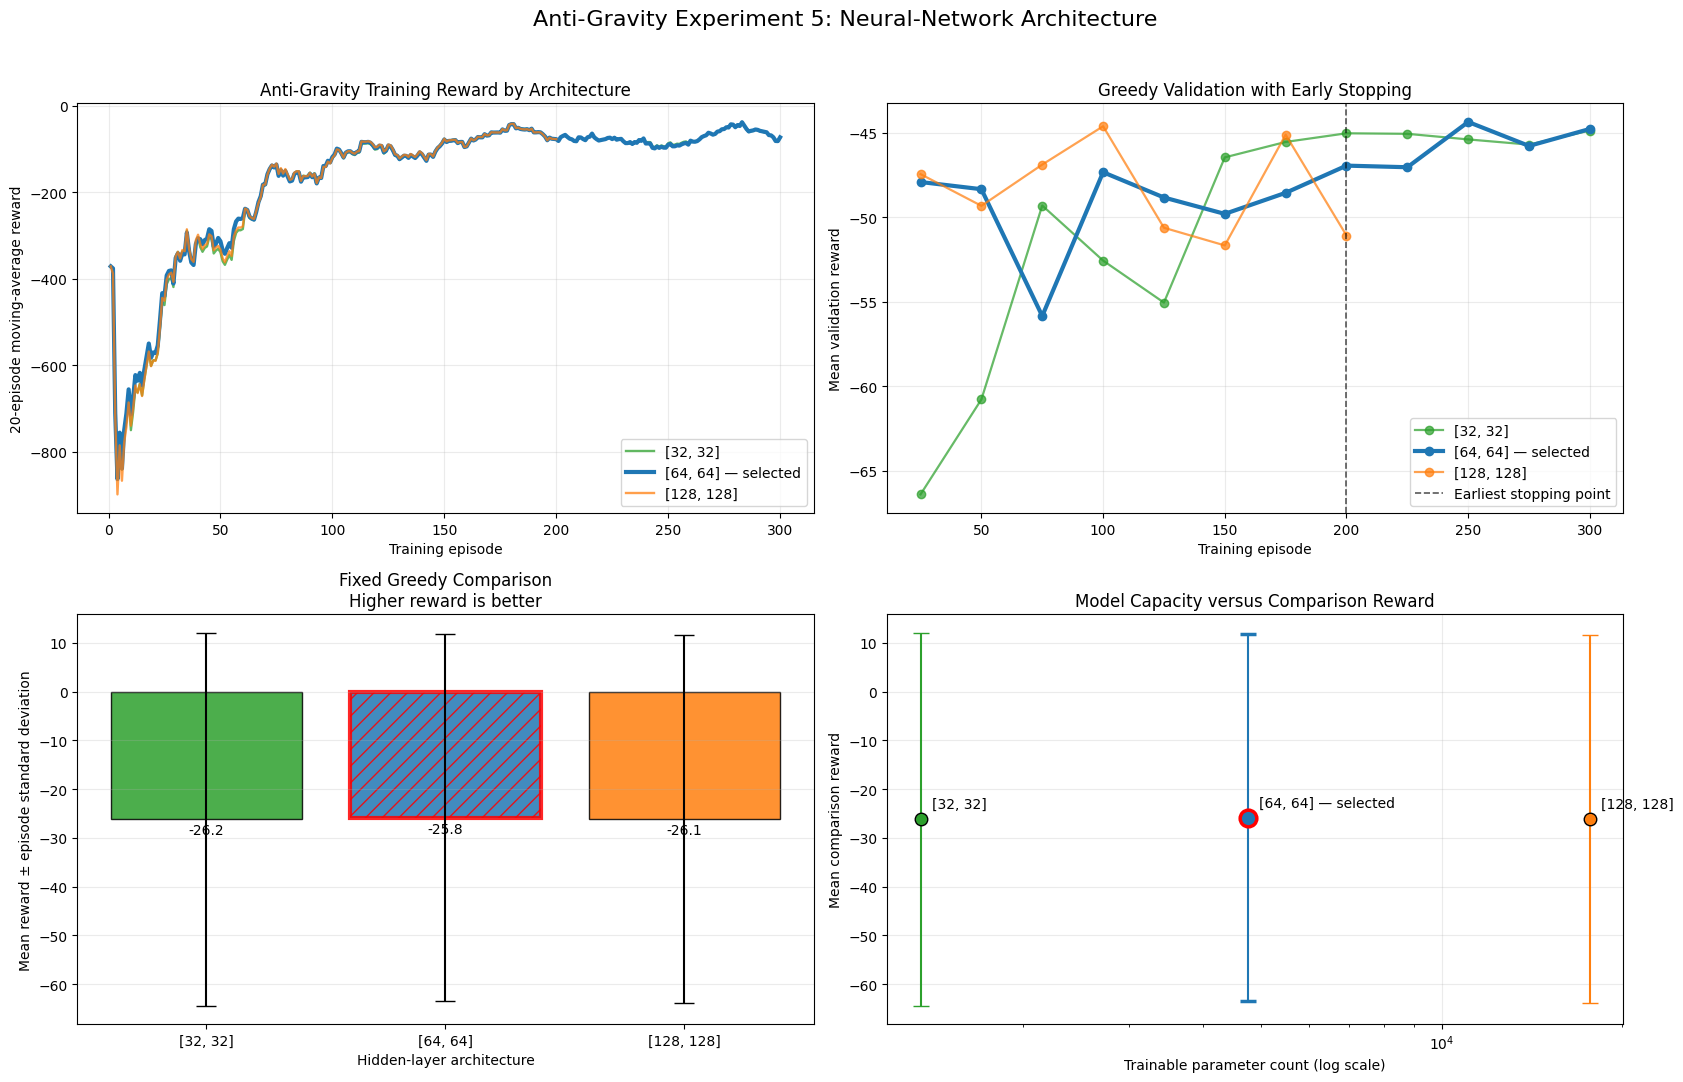

Figure saved to: figures\anti_gravity\anti_architecture_experiment.png


In [90]:
# ---------------------------------------------------------
# Experiment 5 visualisation
# ---------------------------------------------------------

architecture_ids = list(
    ANTI_ARCHITECTURE_SETTINGS.keys()
)

architecture_colours = {
    "small_32x32": "tab:green",
    "control_64x64": "tab:blue",
    "large_128x128": "tab:orange",
}

fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 11),
)


# Plot 1: Training reward.
for architecture_id in architecture_ids:
    run_training = (
        anti_architecture_training_all_dataframe.loc[
            anti_architecture_training_all_dataframe[
                "architecture_id"
            ] == architecture_id
        ]
        .sort_values("episode")
    )

    is_selected = (
        architecture_id
        == ANTI_SELECTED_ARCHITECTURE_ID
    )

    axes[0, 0].plot(
        run_training["episode"],
        run_training["moving_average_reward"],
        color=architecture_colours[architecture_id],
        linewidth=3.0 if is_selected else 1.7,
        alpha=1.0 if is_selected else 0.75,
        label=(
            ANTI_ARCHITECTURE_SETTINGS[
                architecture_id
            ]["label"]
            + (" — selected" if is_selected else "")
        ),
    )

axes[0, 0].set_title(
    "Anti-Gravity Training Reward by Architecture"
)
axes[0, 0].set_xlabel("Training episode")
axes[0, 0].set_ylabel(
    "20-episode moving-average reward"
)
axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend()


# Plot 2: Validation reward.
for architecture_id in architecture_ids:
    run_validation = (
        anti_architecture_validation_all_dataframe.loc[
            anti_architecture_validation_all_dataframe[
                "architecture_id"
            ] == architecture_id
        ]
        .sort_values("training_episode")
    )

    is_selected = (
        architecture_id
        == ANTI_SELECTED_ARCHITECTURE_ID
    )

    axes[0, 1].plot(
        run_validation["training_episode"],
        run_validation["validation_mean_reward"],
        marker="o",
        color=architecture_colours[architecture_id],
        linewidth=3.0 if is_selected else 1.6,
        alpha=1.0 if is_selected else 0.72,
        label=(
            ANTI_ARCHITECTURE_SETTINGS[
                architecture_id
            ]["label"]
            + (" — selected" if is_selected else "")
        ),
    )

axes[0, 1].axvline(
    ANTI_ARCHITECTURE_MINIMUM_EPISODES,
    color="black",
    linestyle="--",
    linewidth=1.2,
    alpha=0.65,
    label="Earliest stopping point",
)

axes[0, 1].set_title(
    "Greedy Validation with Early Stopping"
)
axes[0, 1].set_xlabel("Training episode")
axes[0, 1].set_ylabel("Mean validation reward")
axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend()


# Prepare consistent plotting order.
results_for_plot = (
    anti_architecture_results_dataframe
    .set_index("architecture_id")
    .loc[architecture_ids]
    .reset_index()
)

positions = np.arange(
    len(results_for_plot)
)

selected_position = architecture_ids.index(
    ANTI_SELECTED_ARCHITECTURE_ID
)


# Plot 3: Fixed comparison reward.
comparison_bars = axes[1, 0].bar(
    positions,
    results_for_plot["comparison_mean_reward"],
    color=[
        architecture_colours[architecture_id]
        for architecture_id in architecture_ids
    ],
    edgecolor="black",
    linewidth=1.0,
    alpha=0.85,
)

axes[1, 0].errorbar(
    positions,
    results_for_plot["comparison_mean_reward"],
    yerr=results_for_plot["comparison_reward_std"],
    fmt="none",
    ecolor="black",
    capsize=7,
    linewidth=1.5,
)

comparison_bars[
    selected_position
].set_edgecolor("red")

comparison_bars[
    selected_position
].set_linewidth(3.0)

comparison_bars[
    selected_position
].set_hatch("//")

axes[1, 0].bar_label(
    comparison_bars,
    fmt="%.1f",
    padding=3,
)

axes[1, 0].set_title(
    "Fixed Greedy Comparison\n"
    "Higher reward is better"
)
axes[1, 0].set_xlabel("Hidden-layer architecture")
axes[1, 0].set_ylabel(
    "Mean reward ± episode standard deviation"
)
axes[1, 0].set_xticks(positions)
axes[1, 0].set_xticklabels(
    results_for_plot["architecture_label"]
)
axes[1, 0].grid(axis="y", alpha=0.25)


# Plot 4: Capacity-performance trade-off.
for _, row in results_for_plot.iterrows():
    architecture_id = row["architecture_id"]
    is_selected = (
        architecture_id
        == ANTI_SELECTED_ARCHITECTURE_ID
    )

    axes[1, 1].errorbar(
        row["parameter_count"],
        row["comparison_mean_reward"],
        yerr=row["comparison_reward_std"],
        fmt="o",
        markersize=12 if is_selected else 9,
        color=architecture_colours[architecture_id],
        markeredgecolor=(
            "red" if is_selected else "black"
        ),
        markeredgewidth=(
            2.5 if is_selected else 1.0
        ),
        capsize=6,
    )

    axes[1, 1].annotate(
        row["architecture_label"]
        + (" — selected" if is_selected else ""),
        (
            row["parameter_count"],
            row["comparison_mean_reward"],
        ),
        xytext=(8, 8),
        textcoords="offset points",
    )

axes[1, 1].set_xscale("log")
axes[1, 1].set_title(
    "Model Capacity versus Comparison Reward"
)
axes[1, 1].set_xlabel(
    "Trainable parameter count (log scale)"
)
axes[1, 1].set_ylabel(
    "Mean comparison reward"
)
axes[1, 1].grid(alpha=0.25)


plt.suptitle(
    "Anti-Gravity Experiment 5: "
    "Neural-Network Architecture",
    fontsize=16,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

anti_architecture_figure_path = (
    ANTI_FIGURES_DIR
    / "anti_architecture_experiment.png"
)

plt.savefig(
    anti_architecture_figure_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure saved to:",
    anti_architecture_figure_path,
)

## Anti-Gravity Experiment 5 Evaluation: Neural-Network Architecture

This experiment compared Standard DQN networks with hidden-layer architectures of **`[32, 32]`**, **`[64, 64]`**, and **`[128, 128]`**. The action discretisation, learning rate, epsilon decay, replay settings, training seed, validation procedure and early-stopping conditions were kept constant. Each architecture was trained from scratch.

| Architecture   | Parameters | Episodes trained | Best checkpoint | Best validation reward | Fixed comparison reward |
| -------------- | ---------: | ---------------: | --------------: | ---------------------: | ----------------------: |
| `[32, 32]`     |      1,349 |              300 |             300 |       −44.878 ± 46.790 |        −26.167 ± 38.201 |
| **`[64, 64]`** |  **4,741** |          **300** |         **250** |   **−44.372 ± 46.085** |    **−25.849 ± 37.634** |
| `[128, 128]`   |     17,669 |              200 |             100 |       −44.627 ± 46.106 |        −26.086 ± 37.673 |

Because Pendulum rewards are negative, values closer to zero represent better performance. The `[64, 64]` architecture achieved the highest validation reward. Its validation advantage was **0.506 points over `[32, 32]`** and **0.255 points over `[128, 128]`**.

Although the fixed comparison set was not used for architecture selection, it produced the same ranking. The `[64, 64]` model exceeded `[32, 32]` by **0.318 reward points** and `[128, 128]` by approximately **0.238 points**.

All architectures reached the upright position and satisfied the balance-success condition in **100% of the evaluation episodes**. These behavioural metrics were therefore saturated and could not distinguish the models. The `[128, 128]` model recorded slightly more upright steps and a longer balance streak, but its overall reward remained lower. This indicates that reward captured additional factors such as angle error, angular velocity and torque usage.

The `[128, 128]` network contained approximately **3.7 times as many parameters** as `[64, 64]`, but the additional capacity did not improve validation or comparison reward. It also stopped early at episode 200 after producing its best checkpoint at episode 100. The larger network may therefore have been unnecessarily complex for this low-dimensional task.

The `[32, 32]` network required the least computation, but it produced the weakest validation and comparison results. Its best checkpoint occurred at the final episode, suggesting it may not have fully converged within the fixed 300-episode budget.

The reward differences were very small compared with episode-level standard deviations of approximately 38 points. Furthermore, architecture selection used only one training seed. Consequently, this experiment identifies the strongest observed architecture but does not yet demonstrate that it performs consistently across different initialisations and replay-buffer samples.

Therefore, the `[64, 64]` network is selected as the final anti-gravity architecture.
The architecture comparison used one controlled training seed. Therefore, the result identifies the strongest observed architecture under the experiment conditions, but it does not measure sensitivity across different training initialisations.
The selected saved checkpoint is restored for the final anti-gravity evaluation without retraining.

## Final Selected Anti-Gravity Model Configuration

The following configuration produced the strongest observed validation performance during the controlled anti-gravity experiments.

| Component                         | Selected value                            |
| --------------------------------- | ----------------------------------------- |
| Environment                       | Pendulum-v0 under anti-gravity            |
| Algorithm                         | Standard DQN                              |
| Hidden-layer architecture         | `[64, 64]`                                |
| Trainable parameters              | 4,741                                     |
| Action-space discretisation       | 5 discrete torque actions                 |
| Learning rate                     | `0.001`                                   |
| Epsilon decay                     | `0.995`                                   |
| Maximum training episodes         | 300                                       |
| Checkpoint selection              | Highest greedy validation mean reward     |
| Early stopping                    | Validation-based early stopping           |
| Evaluation policy                 | Greedy policy with exploration disabled   |
| Architecture-selection checkpoint | Episode 250 for the original seed-123 run |

Only the hyperparameters investigated in the controlled experiments are described as selected hyperparameters. Other settings, including the discount factor, batch size, replay-buffer capacity, target-network update settings and activation function, remain unchanged from the common DQN configuration.


In [54]:
# ============================================================
# RESTORE SELECTED ANTI-GRAVITY MODEL
# SOURCE: FRESH CONTROL [64, 64] ARCHITECTURE EXPERIMENT
# NO RETRAINING
# ============================================================


# ------------------------------------------------------------
# Locate the saved weights beside the notebook
# ------------------------------------------------------------

ANTI_BEST_WEIGHTS_PATH = (
    Path.cwd()
    / "fresh_control_64x64_seed_123.weights.h5"
)


if not ANTI_BEST_WEIGHTS_PATH.is_file():
    available_weights = sorted(
        Path.cwd().glob("*.weights.h5")
    )

    raise FileNotFoundError(
        "The selected anti-gravity weights were not found.\n\n"
        f"Expected:\n{ANTI_BEST_WEIGHTS_PATH.resolve()}\n\n"
        "Weights beside the notebook:\n"
        + (
            "\n".join(
                f"- {path.name}"
                for path in available_weights
            )
            if available_weights
            else "- No .weights.h5 files found"
        )
    )


# ------------------------------------------------------------
# Exact selected model configuration
# ------------------------------------------------------------

ANTI_GRAVITY_VALUE = -10.0
ANTI_STATE_SIZE = 3

best_anti_training_seed = 123
best_anti_checkpoint_episode = 250
best_anti_validation_mean_reward = -44.372

ANTI_ACTION_VALUES = np.asarray(
    [-2.0, -1.0, 0.0, 1.0, 2.0],
    dtype=np.float32,
)


anti_selected_config = DQNConfig(
    hidden_layers=(64, 64),
    activation="relu",

    learning_rate=0.001,
    gamma=0.99,

    batch_size=64,
    replay_capacity=50_000,
    minimum_replay_size=1_000,

    epsilon_start=1.0,
    epsilon_minimum=0.05,
    epsilon_decay=0.995,

    target_update_frequency=250,
    gradient_clip_norm=10.0,
)


# ------------------------------------------------------------
# Rebuild and restore the network
# ------------------------------------------------------------

tf.keras.backend.clear_session()

set_global_seed(
    best_anti_training_seed
)


best_anti_agent = DQNAgent(
    state_size=ANTI_STATE_SIZE,
    action_values=ANTI_ACTION_VALUES,
    config=anti_selected_config,

    # Selected anti-gravity algorithm.
    use_double_dqn=False,
)


anti_parameter_count = int(
    best_anti_agent
    .online_network
    .count_params()
)


EXPECTED_ANTI_PARAMETER_COUNT = 4_741

if anti_parameter_count != EXPECTED_ANTI_PARAMETER_COUNT:
    raise ValueError(
        "The reconstructed model does not match the selected "
        "anti-gravity architecture.\n"
        f"Expected parameters: {EXPECTED_ANTI_PARAMETER_COUNT}\n"
        f"Found parameters: {anti_parameter_count}"
    )


best_anti_agent.load_weights(
    str(ANTI_BEST_WEIGHTS_PATH)
)


# Greedy evaluation only.
best_anti_agent.epsilon = 0.0


# ------------------------------------------------------------
# Final checks
# ------------------------------------------------------------

print("Selected anti-gravity model restored successfully.")
print("Weights:", ANTI_BEST_WEIGHTS_PATH.name)
print(
    "Configuration: Standard DQN, "
    "[64, 64], 5 actions, epsilon = 0"
)
print("Parameter count:", anti_parameter_count)

Selected anti-gravity model restored successfully.
No retraining was performed.
Ten-seed results were not used.

Source weights: fresh_control_64x64_seed_123.weights.h5
Source experiment: Architecture experiment
Gravity: -10.0
Algorithm: Standard DQN
Architecture: [64, 64]
Parameter count: 4741
Training seed: 123
Selected checkpoint episode: 250
Best validation mean reward: -44.372
Action values: [-2. -1.  0.  1.  2.]
Evaluation epsilon: 0.0


In [27]:
# ============================================================
# FINAL ANTI-GRAVITY EVALUATION
# RESTORED FRESH CONTROL [64, 64] STANDARD DQN
# 10 NEW GREEDY EPISODES — NO RETRAINING
# ============================================================


ANTI_FINAL_EVALUATION_EPISODES = 10
ANTI_FINAL_EVALUATION_SEED = 4_500_001
ANTI_FINAL_MAX_STEPS = 200


if ANTI_FINAL_EVALUATION_EPISODES < 10:
    raise ValueError(
        "The final evaluation must use at least 10 episodes."
    )

# Guarantee greedy evaluation.
best_anti_agent.epsilon = 0.0


# ------------------------------------------------------------
# Create anti-gravity environment
# ------------------------------------------------------------

anti_final_evaluation_env = create_pendulum_env(
    gravity=ANTI_GRAVITY_VALUE,
    seed=ANTI_FINAL_EVALUATION_SEED,
)


actual_anti_gravity = float(
    anti_final_evaluation_env.unwrapped.g
)


if not np.isclose(
    actual_anti_gravity,
    -10.0,
):
    anti_final_evaluation_env.close()

    raise ValueError(
        "The final environment is not using anti-gravity. "
        f"Found g = {actual_anti_gravity}."
    )


# ------------------------------------------------------------
# Evaluate the restored fixed agent
# ------------------------------------------------------------

try:
    anti_final_result = evaluate_agent(
        env=anti_final_evaluation_env,
        agent=best_anti_agent,

        episodes=ANTI_FINAL_EVALUATION_EPISODES,
        max_steps=ANTI_FINAL_MAX_STEPS,
        seed=ANTI_FINAL_EVALUATION_SEED,

        # No checkpoint selection or saving.
        best_score=None,
        save_path=None,

        verbose=True,
    )

finally:
    anti_final_evaluation_env.close()


# ------------------------------------------------------------
# Overall summary
# ------------------------------------------------------------

anti_final_summary = pd.DataFrame([
    {
        "gravity_condition": "Anti-gravity",
        "gravity": actual_anti_gravity,

        "source_experiment": (
            "Architecture experiment"
        ),

        "source_weights": (
            "fresh_control_64x64_seed_123.weights.h5"
        ),

        "selection_basis": (
            "Best validation checkpoint"
        ),

        "algorithm": "Standard DQN",
        "architecture": "[64, 64]",

        "restored_training_seed": (
            best_anti_training_seed
        ),

        "evaluation_episodes": (
            ANTI_FINAL_EVALUATION_EPISODES
        ),

        "first_evaluation_seed": (
            ANTI_FINAL_EVALUATION_SEED
        ),

        "last_evaluation_seed": (
            ANTI_FINAL_EVALUATION_SEED
            + ANTI_FINAL_EVALUATION_EPISODES
            - 1
        ),

        "mean_reward": float(
            anti_final_result["mean_reward"]
        ),

        "reward_std": float(
            anti_final_result["reward_std"]
        ),

        "minimum_reward": float(
            anti_final_result["minimum_reward"]
        ),

        "maximum_reward": float(
            anti_final_result["maximum_reward"]
        ),

        "reached_upright_rate": float(
            anti_final_result[
                "reached_upright_rate"
            ]
        ),

        "balance_success_rate": float(
            anti_final_result[
                "balance_success_rate"
            ]
        ),

        "mean_upright_steps": float(
            anti_final_result[
                "mean_upright_steps"
            ]
        ),

        "mean_longest_balance_streak": float(
            anti_final_result[
                "mean_longest_balance_streak"
            ]
        ),
    }
])


# ------------------------------------------------------------
# Episode-level results
# ------------------------------------------------------------

anti_final_episode_results = pd.DataFrame(
    anti_final_result[
        "episode_metrics"
    ]
)


anti_final_episode_results.insert(
    0,
    "gravity_condition",
    "Anti-gravity",
)

anti_final_episode_results.insert(
    1,
    "gravity",
    actual_anti_gravity,
)

anti_final_episode_results.insert(
    2,
    "restored_training_seed",
    best_anti_training_seed,
)


if (
    len(anti_final_episode_results)
    != ANTI_FINAL_EVALUATION_EPISODES
):
    raise RuntimeError(
        "The evaluation did not return the requested "
        "number of episodes."
    )

print("\nFinal anti-gravity evaluation")
print("--------------------------------")
print(
    "Weights: "
    "fresh_control_64x64_seed_123.weights.h5"
)
print(
    "Evaluation episodes:",
    ANTI_FINAL_EVALUATION_EPISODES,
)
print("Gravity:", actual_anti_gravity)


display(
    anti_final_summary.round(3)
)

display(
    anti_final_episode_results.round(3)
)


Evaluation results
------------------
Episodes: 10
Mean reward: -65.84
Reward standard deviation: 50.58
Minimum reward: -133.39
Maximum reward: -0.06
Reached upright: 100.0%
Stable-balance success rate: 100.0%
Mean longest stable streak: 168.30 steps

Final anti-gravity restored-agent evaluation
---------------------------------------------
Source weights: fresh_control_64x64_seed_123.weights.h5
Restored training seed: 123
Evaluation episodes: 10
Gravity: -10.0
Training performed: No
Weights updated: No
Exploration used: No
Model selected using these results: No
Files saved by this cell: No


,gravity_condition,gravity,source_experiment,source_weights,selection_basis,algorithm,architecture,restored_training_seed,evaluation_episodes,first_evaluation_seed,last_evaluation_seed,mean_reward,reward_std,minimum_reward,maximum_reward,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,Anti-gravity,-10.0,Architecture experiment,fresh_control_64x64_seed_123.weights.h5,Best validation checkpoint,Standard DQN,"[64, 64]",123,10,4500001,4500010,-65.842,50.582,-133.389,-0.064,1.0,1.0,177.7,168.3


,gravity_condition,gravity,restored_training_seed,evaluation_episode,evaluation_seed,reward,steps_completed,reached_upright,upright_steps,first_upright_step,longest_balance_streak,balance_success
0,Anti-gravity,-10.0,123,1,4500001,-0.064,200,True,200,1,200,True
1,Anti-gravity,-10.0,123,2,4500002,-133.389,200,True,161,18,144,True
2,Anti-gravity,-10.0,123,3,4500003,-0.494,200,True,200,1,198,True
3,Anti-gravity,-10.0,123,4,4500004,-124.616,200,True,161,16,147,True
4,Anti-gravity,-10.0,123,5,4500005,-90.447,200,True,171,14,157,True
5,Anti-gravity,-10.0,123,6,4500006,-126.333,200,True,162,16,147,True
6,Anti-gravity,-10.0,123,7,4500007,-0.632,200,True,199,2,193,True
7,Anti-gravity,-10.0,123,8,4500008,-53.195,200,True,174,11,168,True
8,Anti-gravity,-10.0,123,9,4500009,-52.552,200,True,176,11,169,True
9,Anti-gravity,-10.0,123,10,4500010,-76.691,200,True,173,13,160,True


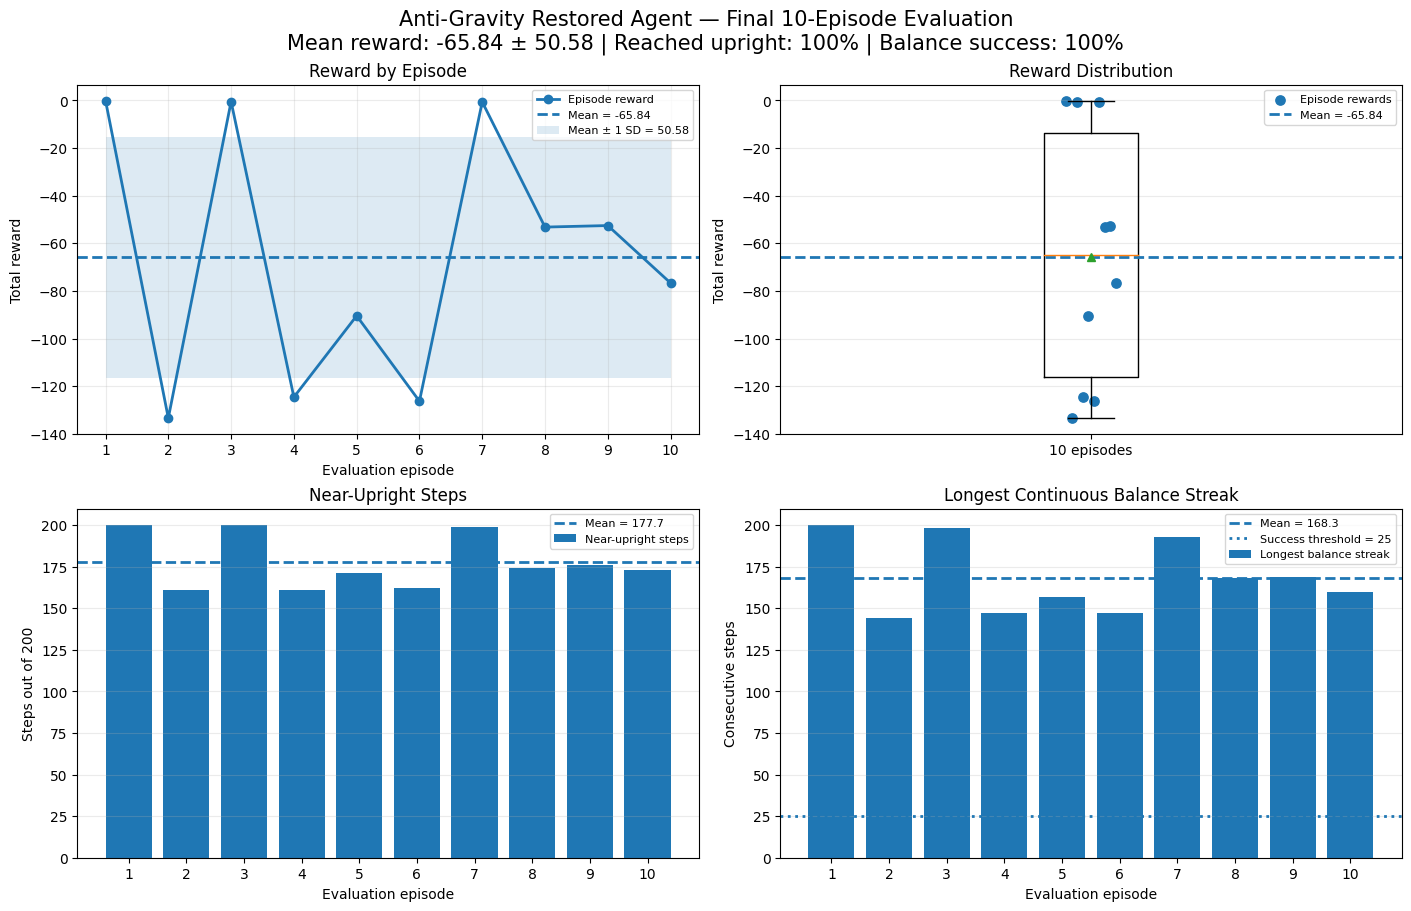

In [28]:
# ============================================================
# COMPACT ANTI-GRAVITY FINAL EVALUATION VISUALISATION
# ONE 2x2 FIGURE — NOTHING IS SAVED
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


if "anti_final_episode_results" not in globals():
    raise NameError(
        "Run the 10-episode anti-gravity evaluation first."
    )


anti_plot_results = (
    anti_final_episode_results
    .copy()
    .reset_index(drop=True)
)


episodes = anti_plot_results[
    "evaluation_episode"
].to_numpy()

rewards = anti_plot_results[
    "reward"
].to_numpy(dtype=np.float64)

upright_steps = anti_plot_results[
    "upright_steps"
].to_numpy(dtype=np.float64)

balance_streaks = anti_plot_results[
    "longest_balance_streak"
].to_numpy(dtype=np.float64)


mean_reward = float(
    rewards.mean()
)

reward_std = float(
    rewards.std(ddof=0)
)

mean_upright_steps = float(
    upright_steps.mean()
)

mean_balance_streak = float(
    balance_streaks.mean()
)

reached_upright_rate = float(
    anti_plot_results[
        "reached_upright"
    ].mean()
)

balance_success_rate = float(
    anti_plot_results[
        "balance_success"
    ].mean()
)


fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 9),
    constrained_layout=True,
)


# ------------------------------------------------------------
# Plot 1: Reward by episode
# ------------------------------------------------------------

reward_axis = axes[0, 0]

reward_axis.plot(
    episodes,
    rewards,
    marker="o",
    linewidth=2,
    label="Episode reward",
)

reward_axis.axhline(
    mean_reward,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_reward:.2f}",
)

reward_axis.fill_between(
    episodes,
    mean_reward - reward_std,
    mean_reward + reward_std,
    alpha=0.15,
    label=f"Mean ± 1 SD = {reward_std:.2f}",
)

reward_axis.set_title(
    "Reward by Episode"
)

reward_axis.set_xlabel(
    "Evaluation episode"
)

reward_axis.set_ylabel(
    "Total reward"
)

reward_axis.set_xticks(
    episodes
)

reward_axis.grid(
    alpha=0.25
)

reward_axis.legend(
    fontsize=8
)


# ------------------------------------------------------------
# Plot 2: Reward distribution
# ------------------------------------------------------------

distribution_axis = axes[0, 1]

distribution_axis.boxplot(
    rewards,
    showmeans=True,
)

jitter = np.linspace(
    -0.04,
    0.04,
    len(rewards),
)

distribution_axis.scatter(
    np.ones(len(rewards)) + jitter,
    rewards,
    s=45,
    label="Episode rewards",
)

distribution_axis.axhline(
    mean_reward,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_reward:.2f}",
)

distribution_axis.set_title(
    "Reward Distribution"
)

distribution_axis.set_ylabel(
    "Total reward"
)

distribution_axis.set_xticks(
    [1]
)

distribution_axis.set_xticklabels(
    ["10 episodes"]
)

distribution_axis.grid(
    axis="y",
    alpha=0.25,
)

distribution_axis.legend(
    fontsize=8
)


# ------------------------------------------------------------
# Plot 3: Near-upright steps
# ------------------------------------------------------------

upright_axis = axes[1, 0]

upright_axis.bar(
    episodes,
    upright_steps,
    label="Near-upright steps",
)

upright_axis.axhline(
    mean_upright_steps,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_upright_steps:.1f}",
)

upright_axis.set_title(
    "Near-Upright Steps"
)

upright_axis.set_xlabel(
    "Evaluation episode"
)

upright_axis.set_ylabel(
    "Steps out of 200"
)

upright_axis.set_xticks(
    episodes
)

upright_axis.set_ylim(
    0,
    210,
)

upright_axis.grid(
    axis="y",
    alpha=0.25,
)

upright_axis.legend(
    fontsize=8
)


# ------------------------------------------------------------
# Plot 4: Longest balance streak
# ------------------------------------------------------------

streak_axis = axes[1, 1]

streak_axis.bar(
    episodes,
    balance_streaks,
    label="Longest balance streak",
)

streak_axis.axhline(
    mean_balance_streak,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_balance_streak:.1f}",
)

streak_axis.axhline(
    BALANCE_REQUIRED_STREAK,
    linestyle=":",
    linewidth=2,
    label=(
        "Success threshold = "
        f"{BALANCE_REQUIRED_STREAK}"
    ),
)

streak_axis.set_title(
    "Longest Continuous Balance Streak"
)

streak_axis.set_xlabel(
    "Evaluation episode"
)

streak_axis.set_ylabel(
    "Consecutive steps"
)

streak_axis.set_xticks(
    episodes
)

streak_axis.set_ylim(
    0,
    210,
)

streak_axis.grid(
    axis="y",
    alpha=0.25,
)

streak_axis.legend(
    fontsize=8
)


fig.suptitle(
    "Anti-Gravity Restored Agent — Final 10-Episode Evaluation\n"
    f"Mean reward: {mean_reward:.2f} ± {reward_std:.2f} | "
    f"Reached upright: {reached_upright_rate:.0%} | "
    f"Balance success: {balance_success_rate:.0%}",
    fontsize=15,
)

plt.show()

In [55]:
import time


ANTI_VIDEO_EPISODES = 10
ANTI_VIDEO_MAX_STEPS = 200
ANTI_VIDEO_FRAME_DELAY = 1 / 30

ANTI_VIDEO_SEEDS = [
    5_500_001,
    5_500_002,
    5_500_003,
    5_500_004,
    5_500_005,
    5_500_006,
    5_500_007,
    5_500_008,
    5_500_009,
    5_500_010,
]


best_anti_agent.epsilon = 0.0

anti_video_env = create_pendulum_env(
    gravity=ANTI_GRAVITY_VALUE,
    seed=ANTI_VIDEO_SEEDS[0],
)


try:
    time.sleep(3)

    for episode_seed in ANTI_VIDEO_SEEDS:
        anti_video_env.seed(episode_seed)
        anti_video_env.action_space.seed(episode_seed)

        state = anti_video_env.reset()
        anti_video_env.render()

        for _ in range(ANTI_VIDEO_MAX_STEPS):
            action_index = best_anti_agent.select_action(
                state,
                training=False,
            )

            torque = best_anti_agent.action_index_to_torque(
                action_index
            )

            state, _, done, _ = anti_video_env.step(
                torque
            )

            anti_video_env.render()
            time.sleep(ANTI_VIDEO_FRAME_DELAY)

            if done:
                break

        time.sleep(1)

    time.sleep(2)

finally:
    anti_video_env.close()

## Final Evaluation of the Restored Anti-Gravity Agent

The final anti-gravity evaluation used the previously saved fresh_control_64x64_seed_123.weights.h5 checkpoint from the neural-network architecture experiment. This checkpoint represented the validation-selected Standard DQN agent with two hidden layers of 64 neurons.

The restored model used five discretised torque actions, [-2,-1,0,1,2], and was evaluated in the anti-gravity environment with g=-10. The original controlled training seed was 123.

The model weights were restored after training had finished, and exploration was disabled by setting epsilon to zero. No retraining, replay-buffer sampling, gradient updates, weight updates or additional model selection occurred during the final evaluation.

Quantitative Evaluation Results

The fixed restored agent was evaluated over ten new greedy episodes. Each episode contained 200 environment steps and used a different evaluation seed.

* Evaluation episodes: 10
* Mean reward: -65.842
* Reward standard deviation: 50.582
* Minimum reward: -133.389
* Maximum reward: -0.064
* Reached-upright rate: 100%
* Balance-success rate: 100%
* Mean upright steps: 177.7 out of 200
* Mean first upright step: 10.3
* Mean longest balance streak: 168.3 steps

In the Pendulum environment, rewards are negative, and values closer to zero indicate better control. The restored agent achieved a mean reward of -65.842, with a standard deviation of 50.582. This variation indicates that the accumulated reward depended noticeably on the initial pendulum state.

Episodes 1, 3 and 7 achieved the strongest rewards of -0.064, -0.494 and -0.632, respectively. These episodes reached the upright region within one or two steps and remained upright for almost the entire episode. Their longest continuous balance streaks were between 193 and 200 steps.

Episodes 2, 4 and 6 achieved the lowest rewards of -133.389, -124.616 and -126.333. They required between 16 and 18 steps to first reach upright. The additional movement needed during the initial control phase produced larger accumulated penalties. Nevertheless, these episodes still maintained continuous balance streaks of between 144 and 147 steps.

Episodes 5, 8, 9 and 10 produced intermediate rewards between approximately -52.552 and -90.447. These episodes first reached upright between steps 11 and 14 and maintained longest balance streaks of between 157 and 169 steps.

Upright and Balance Performance

The agent reached the upright region in all ten evaluation episodes, producing a 100% reached-upright rate. It remained near upright for an average of 177.7 out of 200 steps, equivalent to approximately 88.9% of each episode.

The mean longest continuous balance streak was 168.3 steps. All ten episodes exceeded the balance-success threshold of 25 consecutive steps, resulting in a 100% balance-success rate.

These behavioural measurements provide important context for interpreting the reward variation. Even the episodes with the lowest rewards successfully reached upright and maintained balance for more than 140 consecutive steps. Their weaker rewards therefore represented slower initial control rather than failure to complete the task.

The compact evaluation visualisation supports this interpretation. The reward plot shows clear variation between initial states, while the upright-step and balance-streak plots demonstrate consistently successful behaviour across all ten episodes.

Ten-Episode Visual Playback

The restored agent was also demonstrated over ten separately seeded rendered episodes using new playback episode-reset seeds. Exploration remained disabled, and no learning or weight updates occurred during playback.

The visual playback showed that the agent could repeatedly move the pendulum towards the target position and maintain stable control under anti-gravity.

These rendered episodes provided visual support for the separate quantitative evaluation. The agent generally maintained long periods of balance once the upright region had been reached, although the initial control behaviour varied between starting states.

Final Anti-Gravity Assessment

The restored [64, 64] Standard DQN agent demonstrated reliable anti-gravity control. It reached upright and passed the balance-success criterion in every quantitative and rendered episode.

Its main strength was its consistent task-completion behaviour. Once the pendulum entered the upright region, the agent generally maintained control for a long continuous period. Its main limitation was variation in the time and movement required to establish control from different initial states, which produced a relatively large reward standard deviation.

Overall, the model can be considered a successful anti-gravity controller. The 100% reached-upright rate, 100% balance-success rate and long average balance streak demonstrate reliable control, while the reward variation shows that initial control efficiency could still be improved.

Because the selected configuration was trained using one controlled training seed, the results identify the best observed anti-gravity configuration under the current experimental conditions. Sensitivity to different training initialisations remains a limitation of this evaluation.


# Supergravity Experiments (`g = 15`)

Supergravity increases the downward gravitational force acting on the pendulum. With the maximum torque still limited to `[-2, 2]`, the agent must learn a more precise energy-building strategy to swing the pendulum upward and maintain balance.

The supergravity experiments repeat the same controlled optimisation procedure used for anti-gravity. Only one experimental factor is changed at a time, while all other settings are held constant. Model selection is based exclusively on fixed greedy validation episodes, followed by confirmation using a separate unseen comparison set.

All agents are trained from scratch under `g = 15.0`; no anti-gravity weights are reused.

In [106]:
# ---------------------------------------------------------
# Supergravity Experiment 1:
# Action-space discretisation setup
# ---------------------------------------------------------

SUPER_GRAVITY_VALUE = 15.0


# ---------------------------------------------------------
# Supergravity output directories
# ---------------------------------------------------------

SUPER_RESULTS_DIR = (
    RESULTS_DIR
    / "supergravity"
)

SUPER_WEIGHTS_DIR = (
    WEIGHTS_DIR
    / "supergravity"
)

SUPER_FIGURES_DIR = (
    FIGURES_DIR
    / "supergravity"
)


SUPER_ACTION_RESULTS_DIR = (
    SUPER_RESULTS_DIR
    / "experiment_1_action_count"
)

SUPER_ACTION_WEIGHTS_DIR = (
    SUPER_WEIGHTS_DIR
    / "experiment_1_action_count"
)


for directory in [
    SUPER_RESULTS_DIR,
    SUPER_WEIGHTS_DIR,
    SUPER_FIGURES_DIR,
    SUPER_ACTION_RESULTS_DIR,
    SUPER_ACTION_WEIGHTS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ---------------------------------------------------------
# Action-space candidates
# ---------------------------------------------------------

SUPER_ACTION_COUNTS = [
    5,
    9,
    11,
    21,
    41,
]


SUPER_ACTION_VALUES = {
    action_count: np.linspace(
        -2.0,
        2.0,
        action_count,
        dtype=np.float32,
    )
    for action_count in SUPER_ACTION_COUNTS
}


# ---------------------------------------------------------
# Controlled experiment settings
# ---------------------------------------------------------

SUPER_ACTION_TRAINING_SEED = 123
SUPER_ACTION_VALIDATION_SEED = 1_600_001
SUPER_ACTION_COMPARISON_SEED = 2_600_001

SUPER_ACTION_MAX_EPISODES = 300
SUPER_ACTION_MAX_STEPS = 200

SUPER_ACTION_EVALUATION_EVERY = 50
SUPER_ACTION_VALIDATION_EPISODES = 20
SUPER_ACTION_COMPARISON_EPISODES = 30

SUPER_ACTION_MINIMUM_EPISODES = 150

# A large patience value effectively disables early stopping.
SUPER_ACTION_EARLY_STOPPING_PATIENCE = 999
SUPER_ACTION_EARLY_STOPPING_MIN_DELTA = 0.0


# ---------------------------------------------------------
# Common configuration for Experiment 1
# ---------------------------------------------------------

def make_super_action_config():
    """
    Create the Standard DQN configuration used in the
    supergravity action-count experiment.
    """

    return DQNConfig(
        hidden_layers=(64, 64),
        activation="relu",

        learning_rate=0.001,
        gamma=0.99,

        batch_size=64,
        replay_capacity=50_000,
        minimum_replay_size=1_000,

        epsilon_start=1.0,
        epsilon_minimum=0.05,
        epsilon_decay=0.995,

        target_update_frequency=250,
        gradient_clip_norm=10.0,
    )


# ---------------------------------------------------------
# Output paths for each action-count candidate
# ---------------------------------------------------------

def get_super_action_paths(action_count):
    """
    Return the output paths for one action-count candidate.
    """

    run_name = (
        f"standard_dqn_{action_count}_actions"
    )

    return {
        "weights": (
            SUPER_ACTION_WEIGHTS_DIR
            / f"{run_name}.weights.h5"
        ),

        "training": (
            SUPER_ACTION_RESULTS_DIR
            / f"{run_name}_training.csv"
        ),

        "validation": (
            SUPER_ACTION_RESULTS_DIR
            / f"{run_name}_validation.csv"
        ),

        "checkpoint": (
            SUPER_ACTION_RESULTS_DIR
            / f"{run_name}_checkpoint.csv"
        ),

        "comparison": (
            SUPER_ACTION_RESULTS_DIR
            / f"{run_name}_comparison.csv"
        ),
    }


SUPER_ACTION_PATHS = {
    action_count: get_super_action_paths(
        action_count
    )
    for action_count in SUPER_ACTION_COUNTS
}


# ---------------------------------------------------------
# Verify environment and action mappings
# ---------------------------------------------------------

super_probe_env = create_pendulum_env(
    gravity=SUPER_GRAVITY_VALUE,
    seed=SUPER_ACTION_TRAINING_SEED,
)


SUPER_STATE_SIZE = int(
    super_probe_env
    .observation_space
    .shape[0]
)


actual_super_gravity = float(
    super_probe_env.unwrapped.g
)


if not np.isclose(
    actual_super_gravity,
    SUPER_GRAVITY_VALUE,
):
    super_probe_env.close()

    raise ValueError(
        "The supergravity environment was not created "
        f"correctly. Found g = {actual_super_gravity}."
    )


print(
    "Environment gravity:",
    actual_super_gravity,
)

print(
    "State size:",
    SUPER_STATE_SIZE,
)


for action_count in SUPER_ACTION_COUNTS:
    print(
        f"{action_count:>2} actions:",
        SUPER_ACTION_VALUES[
            action_count
        ],
    )


super_probe_env.close()

Environment gravity: 15.0
State size: 3
 5 actions: [-2. -1.  0.  1.  2.]
 9 actions: [-2.  -1.5 -1.  -0.5  0.   0.5  1.   1.5  2. ]
11 actions: [-2.  -1.6 -1.2 -0.8 -0.4  0.   0.4  0.8  1.2  1.6  2. ]
21 actions: [-2.  -1.8 -1.6 -1.4 -1.2 -1.  -0.8 -0.6 -0.4 -0.2  0.   0.2  0.4  0.6
  0.8  1.   1.2  1.4  1.6  1.8  2. ]
41 actions: [-2.  -1.9 -1.8 -1.7 -1.6 -1.5 -1.4 -1.3 -1.2 -1.1 -1.  -0.9 -0.8 -0.7
 -0.6 -0.5 -0.4 -0.3 -0.2 -0.1  0.   0.1  0.2  0.3  0.4  0.5  0.6  0.7
  0.8  0.9  1.   1.1  1.2  1.3  1.4  1.5  1.6  1.7  1.8  1.9  2. ]


In [107]:
# ---------------------------------------------------------
# Train each action-count candidate from scratch
# ---------------------------------------------------------

for run_number, action_count in enumerate(
    SUPER_ACTION_COUNTS,
    start=1,
):
    run_paths = SUPER_ACTION_PATHS[action_count]

    required_paths = [
        run_paths["weights"],
        run_paths["training"],
        run_paths["validation"],
        run_paths["checkpoint"],
    ]

    if all(path.exists() for path in required_paths):
        print(
            f"{action_count} actions: "
            "complete training results already exist."
        )
        continue

    print("\n" + "=" * 72)
    print(
        f"SUPERGRAVITY ACTION EXPERIMENT "
        f"{run_number}/{len(SUPER_ACTION_COUNTS)} | "
        f"{action_count} ACTIONS"
    )
    print("=" * 72)

    tf.keras.backend.clear_session()
    set_global_seed(SUPER_ACTION_TRAINING_SEED)

    training_env = None
    validation_env = None
    action_agent = None

    try:
        current_config = make_super_action_config()

        training_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_ACTION_TRAINING_SEED,
        )

        validation_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_ACTION_VALIDATION_SEED,
        )

        action_agent = DQNAgent(
            state_size=SUPER_STATE_SIZE,
            action_values=(
                SUPER_ACTION_VALUES[action_count]
            ),
            config=current_config,
            use_double_dqn=False,
        )

        (
            action_history,
            action_training_dataframe,
        ) = train_agent(
            env=training_env,
            agent=action_agent,
            episodes=SUPER_ACTION_MAX_EPISODES,
            max_steps=SUPER_ACTION_MAX_STEPS,
            moving_average_window=20,
            seed=SUPER_ACTION_TRAINING_SEED,

            evaluation_env=validation_env,
            evaluation_every=(
                SUPER_ACTION_EVALUATION_EVERY
            ),
            evaluation_episodes=(
                SUPER_ACTION_VALIDATION_EPISODES
            ),
            evaluation_seed=(
                SUPER_ACTION_VALIDATION_SEED
            ),
            best_weights_path=run_paths["weights"],

            print_every=25,
            render_every=None,

            early_stopping_minimum_episodes=(
                SUPER_ACTION_MINIMUM_EPISODES
            ),
            early_stopping_patience=(
                SUPER_ACTION_EARLY_STOPPING_PATIENCE
            ),
            early_stopping_min_delta=(
                SUPER_ACTION_EARLY_STOPPING_MIN_DELTA
            ),
        )

        # Save training history.
        action_training_dataframe.insert(
            0,
            "action_count",
            action_count,
        )

        action_training_dataframe.to_csv(
            run_paths["training"],
            index=False,
        )

        # Save validation history.
        action_validation_dataframe = pd.DataFrame({
            "action_count": action_count,
            "training_episode": action_history[
                "evaluation_episode"
            ],
            "validation_mean_reward": action_history[
                "evaluation_mean_reward"
            ],
            "validation_reward_std": action_history[
                "evaluation_reward_std"
            ],
            "validation_improved": action_history[
                "evaluation_improved"
            ],
            "validations_without_improvement": (
                action_history[
                    "validations_without_improvement"
                ]
            ),
        })

        action_validation_dataframe.to_csv(
            run_paths["validation"],
            index=False,
        )

        validation_means = np.asarray(
            action_history["evaluation_mean_reward"],
            dtype=float,
        )

        if len(validation_means) == 0:
            raise RuntimeError(
                f"{action_count} actions produced "
                "no validation results."
            )

        best_position = int(
            np.argmax(validation_means)
        )

        action_checkpoint_dataframe = pd.DataFrame([
            {
                "action_count": action_count,
                "training_seed": (
                    SUPER_ACTION_TRAINING_SEED
                ),
                "validation_seed": (
                    SUPER_ACTION_VALIDATION_SEED
                ),
                "trained_episodes": int(
                    action_history["stop_episode"]
                ),
                "stopped_early": bool(
                    action_history["stopped_early"]
                ),
                "best_checkpoint_episode": int(
                    action_history[
                        "evaluation_episode"
                    ][best_position]
                ),
                "best_validation_mean_reward": float(
                    validation_means[best_position]
                ),
                "best_validation_reward_std": float(
                    action_history[
                        "evaluation_reward_std"
                    ][best_position]
                ),
                "parameter_count": int(
                    action_agent
                    .online_network
                    .count_params()
                ),
            }
        ])

        action_checkpoint_dataframe.to_csv(
            run_paths["checkpoint"],
            index=False,
        )

        print(
            f"{action_count} actions completed | "
            f"best checkpoint: episode "
            f"{action_history['evaluation_episode'][best_position]} | "
            f"validation reward: "
            f"{validation_means[best_position]:.3f}"
        )

    finally:
        if training_env is not None:
            training_env.close()

        if validation_env is not None:
            validation_env.close()

        action_agent = None
        tf.keras.backend.clear_session()
        gc.collect()


SUPERGRAVITY ACTION EXPERIMENT 1/5 | 5 ACTIONS
Episode    1/300 | Reward: -1301.66 | Moving average: -1301.66 | Epsilon: 0.9950 | Loss: not training yet | Replay size: 200
Episode   25/300 | Reward: -1307.62 | Moving average: -1358.81 | Epsilon: 0.8822 | Loss: 0.9419 | Replay size: 5000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_1_action_count\standard_dqn_5_actions.weights.h5
Evaluation at episode 50: mean reward = -1158.76, std = 28.12, wait = 0/999
New best weights saved.
Episode   50/300 | Reward: -1306.26 | Moving average: -1332.02 | Epsilon: 0.7783 | Loss: 2.1732 | Replay size: 10000
Episode   75/300 | Reward: -1141.61 | Moving average: -1244.66 | Epsilon: 0.6866 | Loss: 2.9969 | Replay size: 15000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_1_action_count\standard_dqn_5_actions.weights.h5
Evaluation at episode 100: mean reward = -1138.64, std = 39.52, wait = 0/999
New best weights saved.
Episode  100/3

In [108]:
# ---------------------------------------------------------
# Evaluate each saved checkpoint on the same unseen
# comparison episodes
# ---------------------------------------------------------

super_action_result_records = []
super_action_comparison_frames = []


for action_count in SUPER_ACTION_COUNTS:
    run_paths = SUPER_ACTION_PATHS[action_count]

    for required_name in [
        "weights",
        "training",
        "validation",
        "checkpoint",
    ]:
        required_path = run_paths[required_name]

        if not required_path.exists():
            raise FileNotFoundError(
                f"Missing {required_name} result for "
                f"{action_count} actions: {required_path}"
            )

    checkpoint_row = pd.read_csv(
        run_paths["checkpoint"]
    ).iloc[0]

    tf.keras.backend.clear_session()
    set_global_seed(SUPER_ACTION_TRAINING_SEED)

    comparison_env = None
    evaluation_agent = None

    try:
        current_config = make_super_action_config()

        comparison_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_ACTION_COMPARISON_SEED,
        )

        evaluation_agent = DQNAgent(
            state_size=SUPER_STATE_SIZE,
            action_values=(
                SUPER_ACTION_VALUES[action_count]
            ),
            config=current_config,
            use_double_dqn=False,
        )

        evaluation_agent.load_weights(
            run_paths["weights"]
        )

        evaluation_agent.epsilon = 0.0

        comparison_result = evaluate_agent(
            env=comparison_env,
            agent=evaluation_agent,
            episodes=SUPER_ACTION_COMPARISON_EPISODES,
            max_steps=SUPER_ACTION_MAX_STEPS,
            seed=SUPER_ACTION_COMPARISON_SEED,
            best_score=None,
            save_path=None,
            verbose=False,
        )

        super_action_result_records.append({
            "action_count": action_count,
            "parameter_count": int(
                checkpoint_row["parameter_count"]
            ),
            "trained_episodes": int(
                checkpoint_row["trained_episodes"]
            ),
            "stopped_early": (
                str(checkpoint_row["stopped_early"])
                .strip()
                .lower()
                == "true"
            ),
            "best_checkpoint_episode": int(
                checkpoint_row[
                    "best_checkpoint_episode"
                ]
            ),
            "best_validation_mean_reward": float(
                checkpoint_row[
                    "best_validation_mean_reward"
                ]
            ),
            "best_validation_reward_std": float(
                checkpoint_row[
                    "best_validation_reward_std"
                ]
            ),
            "comparison_mean_reward": float(
                comparison_result["mean_reward"]
            ),
            "comparison_reward_std": float(
                comparison_result["reward_std"]
            ),
            "comparison_minimum_reward": float(
                comparison_result["minimum_reward"]
            ),
            "comparison_maximum_reward": float(
                comparison_result["maximum_reward"]
            ),
            "reached_upright_rate": float(
                comparison_result[
                    "reached_upright_rate"
                ]
            ),
            "balance_success_rate": float(
                comparison_result[
                    "balance_success_rate"
                ]
            ),
            "mean_upright_steps": float(
                comparison_result[
                    "mean_upright_steps"
                ]
            ),
            "mean_longest_balance_streak": float(
                comparison_result[
                    "mean_longest_balance_streak"
                ]
            ),
        })

        episode_dataframe = pd.DataFrame(
            comparison_result["episode_metrics"]
        )

        episode_dataframe.insert(
            0,
            "action_count",
            action_count,
        )

        episode_dataframe.to_csv(
            run_paths["comparison"],
            index=False,
        )

        super_action_comparison_frames.append(
            episode_dataframe
        )

        print(
            f"{action_count:>2} actions | "
            f"comparison reward: "
            f"{comparison_result['mean_reward']:.3f} "
            f"± {comparison_result['reward_std']:.3f} | "
            f"upright: "
            f"{comparison_result['reached_upright_rate']:.1%} | "
            f"balance: "
            f"{comparison_result['balance_success_rate']:.1%}"
        )

    finally:
        if comparison_env is not None:
            comparison_env.close()

        evaluation_agent = None
        tf.keras.backend.clear_session()
        gc.collect()


super_action_results_dataframe = (
    pd.DataFrame(super_action_result_records)
    .sort_values("action_count")
    .reset_index(drop=True)
)

super_action_training_dataframe = pd.concat(
    [
        pd.read_csv(
            SUPER_ACTION_PATHS[count]["training"]
        )
        for count in SUPER_ACTION_COUNTS
    ],
    ignore_index=True,
)

super_action_validation_dataframe = pd.concat(
    [
        pd.read_csv(
            SUPER_ACTION_PATHS[count]["validation"]
        )
        for count in SUPER_ACTION_COUNTS
    ],
    ignore_index=True,
)

super_action_comparison_dataframe = pd.concat(
    super_action_comparison_frames,
    ignore_index=True,
)


super_action_results_dataframe.to_csv(
    SUPER_ACTION_RESULTS_DIR
    / "super_action_count_summary.csv",
    index=False,
)

super_action_comparison_dataframe.to_csv(
    SUPER_ACTION_RESULTS_DIR
    / "super_action_comparison_episodes.csv",
    index=False,
)


display(
    super_action_results_dataframe.round(3)
)

Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_1_action_count\standard_dqn_5_actions.weights.h5
 5 actions | comparison reward: -1157.612 ± 173.668 | upright: 90.0% | balance: 0.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_1_action_count\standard_dqn_9_actions.weights.h5
 9 actions | comparison reward: -1086.931 ± 86.526 | upright: 100.0% | balance: 0.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_1_action_count\standard_dqn_11_actions.weights.h5
11 actions | comparison reward: -973.035 ± 61.657 | upright: 3.3% | balance: 0.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_1_action_count\standard_dqn_21_actions.weights.h5
21 actions | comparison reward: -1158.173 ± 180.530 | upright: 90.0% | balance: 0.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_1_action_count\standard_dqn_41_actions.w

,action_count,parameter_count,trained_episodes,stopped_early,best_checkpoint_episode,best_validation_mean_reward,best_validation_reward_std,comparison_mean_reward,comparison_reward_std,comparison_minimum_reward,comparison_maximum_reward,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,5,4741,300,False,300,-1116.378,56.684,-1157.612,173.668,-1666.898,-1007.741,0.900,0.0,13.667,0.033
1,9,5001,300,False,100,-1083.450,89.990,-1086.931,86.526,-1210.079,-900.633,1.000,0.0,21.033,0.000
2,11,5131,300,False,300,-950.347,69.946,-973.035,61.657,-1079.642,-720.998,0.033,0.0,1.400,0.033
3,21,5781,300,False,300,-1081.756,284.079,-1158.173,180.530,-1660.621,-933.580,0.900,0.0,15.333,0.100
4,41,7081,300,False,100,-1110.305,54.933,-1157.723,108.715,-1664.756,-1035.304,0.967,0.0,17.767,0.100


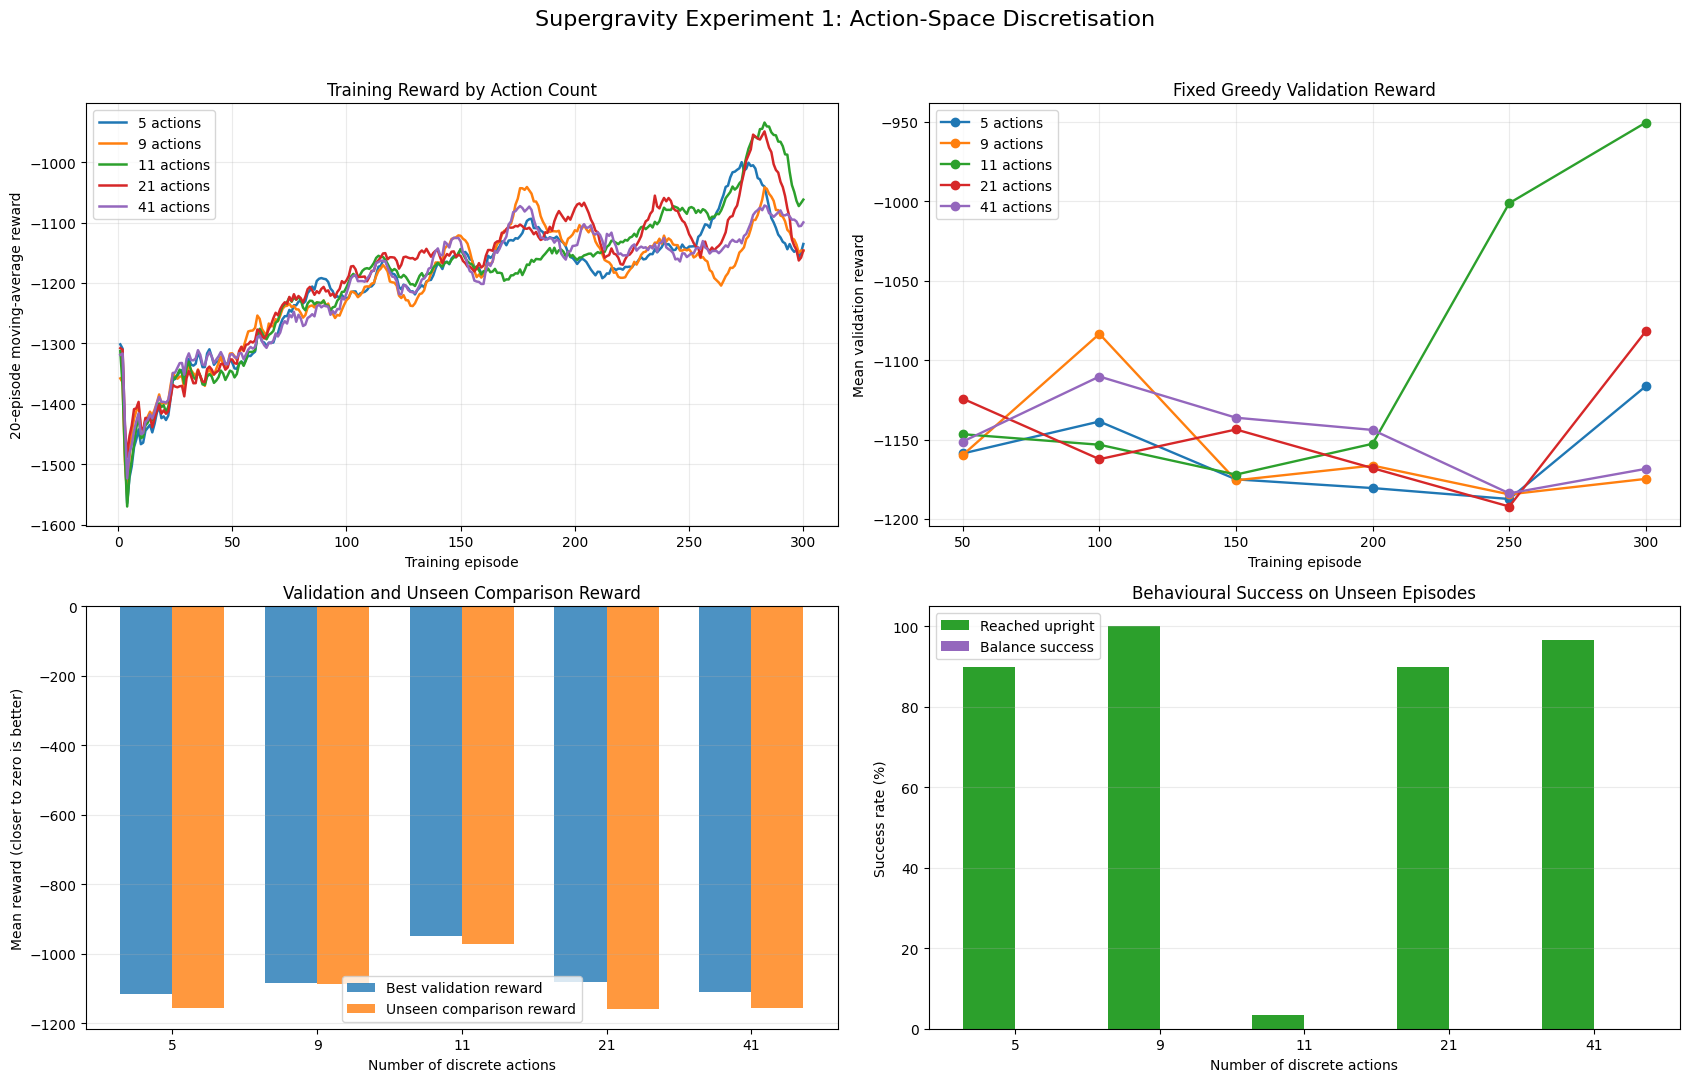

Figure saved to: figures\supergravity\super_experiment_1_action_count.png


In [109]:
# ---------------------------------------------------------
# Supergravity action-count visualisation
# ---------------------------------------------------------

best_validation_position = (
    super_action_results_dataframe[
        "best_validation_mean_reward"
    ].idxmax()
)

best_validation_action_count = int(
    super_action_results_dataframe.loc[
        best_validation_position,
        "action_count",
    ]
)

action_colours = {
    action_count: (
        "tab:green"
        if action_count == best_validation_action_count
        else "tab:blue"
    )
    for action_count in SUPER_ACTION_COUNTS
}


fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 11),
)


# Plot 1: Training curves
for action_count in SUPER_ACTION_COUNTS:
    candidate_training = (
        super_action_training_dataframe.loc[
            super_action_training_dataframe[
                "action_count"
            ] == action_count
        ]
        .sort_values("episode")
    )

    axes[0, 0].plot(
        candidate_training["episode"],
        candidate_training[
            "moving_average_reward"
        ],
        linewidth=1.8,
        label=f"{action_count} actions",
    )

axes[0, 0].set_title(
    "Training Reward by Action Count"
)
axes[0, 0].set_xlabel("Training episode")
axes[0, 0].set_ylabel(
    "20-episode moving-average reward"
)
axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend()


# Plot 2: Validation curves
for action_count in SUPER_ACTION_COUNTS:
    candidate_validation = (
        super_action_validation_dataframe.loc[
            super_action_validation_dataframe[
                "action_count"
            ] == action_count
        ]
        .sort_values("training_episode")
    )

    axes[0, 1].plot(
        candidate_validation["training_episode"],
        candidate_validation[
            "validation_mean_reward"
        ],
        marker="o",
        linewidth=1.7,
        label=f"{action_count} actions",
    )

axes[0, 1].set_title(
    "Fixed Greedy Validation Reward"
)
axes[0, 1].set_xlabel("Training episode")
axes[0, 1].set_ylabel("Mean validation reward")
axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend()


# Plot 3: Validation and comparison results
positions = np.arange(
    len(SUPER_ACTION_COUNTS)
)
bar_width = 0.36

axes[1, 0].bar(
    positions - bar_width / 2,
    super_action_results_dataframe[
        "best_validation_mean_reward"
    ],
    width=bar_width,
    label="Best validation reward",
    color="tab:blue",
    alpha=0.8,
)

axes[1, 0].bar(
    positions + bar_width / 2,
    super_action_results_dataframe[
        "comparison_mean_reward"
    ],
    width=bar_width,
    label="Unseen comparison reward",
    color="tab:orange",
    alpha=0.8,
)

axes[1, 0].set_title(
    "Validation and Unseen Comparison Reward"
)
axes[1, 0].set_xlabel("Number of discrete actions")
axes[1, 0].set_ylabel(
    "Mean reward (closer to zero is better)"
)
axes[1, 0].set_xticks(positions)
axes[1, 0].set_xticklabels(
    SUPER_ACTION_COUNTS
)
axes[1, 0].grid(
    axis="y",
    alpha=0.25,
)
axes[1, 0].legend()


# Plot 4: Behavioural success rates
upright_rates = (
    super_action_results_dataframe[
        "reached_upright_rate"
    ].to_numpy()
    * 100
)

balance_rates = (
    super_action_results_dataframe[
        "balance_success_rate"
    ].to_numpy()
    * 100
)

axes[1, 1].bar(
    positions - bar_width / 2,
    upright_rates,
    width=bar_width,
    label="Reached upright",
    color="tab:green",
)

axes[1, 1].bar(
    positions + bar_width / 2,
    balance_rates,
    width=bar_width,
    label="Balance success",
    color="tab:purple",
)

axes[1, 1].set_title(
    "Behavioural Success on Unseen Episodes"
)
axes[1, 1].set_xlabel("Number of discrete actions")
axes[1, 1].set_ylabel("Success rate (%)")
axes[1, 1].set_xticks(positions)
axes[1, 1].set_xticklabels(
    SUPER_ACTION_COUNTS
)
axes[1, 1].set_ylim(0, 105)
axes[1, 1].grid(
    axis="y",
    alpha=0.25,
)
axes[1, 1].legend()


plt.suptitle(
    "Supergravity Experiment 1: "
    "Action-Space Discretisation",
    fontsize=16,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

super_action_figure_path = (
    SUPER_FIGURES_DIR
    / "super_experiment_1_action_count.png"
)

plt.savefig(
    super_action_figure_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure saved to:",
    super_action_figure_path,
)

## Supergravity Experiment 1 Evaluation: Action-Space Discretisation

This experiment compared Standard DQN agents using **5, 9, 11, 21 and 41 discrete torque actions** under supergravity (`g = 15`). The learning rate, epsilon schedule, network architecture, training duration, training seed and evaluation episodes were kept constant. All candidates completed the full **300 training episodes without early stopping**.

Because Pendulum rewards are negative, values closer to zero represent better performance.

| Actions | Best validation reward | Unseen comparison reward | Reached upright | Balance success |
| ------: | ---------------------: | -----------------------: | --------------: | --------------: |
|       5 |              −1116.378 |      −1157.612 ± 173.668 |           90.0% |            0.0% |
|       9 |              −1083.450 |       −1086.931 ± 86.526 |          100.0% |            0.0% |
|  **11** |           **−950.347** |    **−973.035 ± 61.657** |            3.3% |            0.0% |
|      21 |              −1081.756 |      −1158.173 ± 180.530 |           90.0% |            0.0% |
|      41 |              −1110.305 |      −1157.723 ± 108.715 |           96.7% |            0.0% |

The strongest validation result was produced by **11 actions**, which achieved **−950.347 ± 69.946** at episode 300. This exceeded the second-best validation result from 21 actions by **131.409 reward points**.

The unseen comparison episodes confirmed the same winner. The 11-action model achieved **−973.035 ± 61.657**, outperforming the next-best 9-action configuration by **113.896 points** and the original 5-action control by **184.577 points**. It also produced the lowest comparison reward variability, suggesting more consistent episode-level performance.

However, the behavioural results reveal an important limitation. The 11-action model reached the defined upright condition in only **3.3% of episodes**, remained upright for an average of **1.4 steps**, and achieved no successful balancing episodes. Although several other configurations reached upright more frequently, their extremely short balance streaks and 0% balance-success rates indicate that they only passed through the upright region briefly.

This is not necessarily inconsistent with the reward ranking. Pendulum reward measures accumulated angle error, angular velocity and torque usage throughout the entire episode. The 11-action policy could therefore obtain a better total reward by maintaining generally lower control costs without frequently crossing the strict upright threshold.

The training curves improved for every action count, but the validation curves remained irregular. This demonstrates that reinforcement-learning performance does not improve monotonically. Finer discretisation also did not guarantee better results: 21 and 41 actions increased the number of Q-values that had to be learned without producing better reward.

Only one training seed was used, so this experiment is suitable for controlled hyperparameter selection but not yet sufficient to establish reproducibility.

Therefore, **11 discrete actions are selected for the remaining supergravity experiments** because they achieved the highest validation reward and this result was independently supported by the unseen comparison episodes. Nevertheless, the policy should not yet be described as successfully balancing the pendulum. The next experiments must attempt to improve sustained upright control.


In [114]:
# ---------------------------------------------------------
# Supergravity Experiment 2:
# Epsilon-decay setup
# ---------------------------------------------------------

SUPER_SELECTED_ACTION_COUNT = 11

SUPER_SELECTED_ACTION_VALUES = np.linspace(
    -2.0,
    2.0,
    SUPER_SELECTED_ACTION_COUNT,
    dtype=np.float32,
)

SUPER_EPSILON_DECAYS = [
    0.990,
    0.995,  # Original control
    0.997,
    0.999,
]

SUPER_EPSILON_TRAINING_SEED = 124
SUPER_EPSILON_VALIDATION_SEED = 1_600_002
SUPER_EPSILON_COMPARISON_SEED = 2_600_002

SUPER_EPSILON_MAX_EPISODES = 300
SUPER_EPSILON_MAX_STEPS = 200

SUPER_EPSILON_EVALUATION_EVERY = 50
SUPER_EPSILON_VALIDATION_EPISODES = 20
SUPER_EPSILON_COMPARISON_EPISODES = 30

SUPER_EPSILON_MINIMUM_EPISODES = 150

# Effectively disables early stopping.
SUPER_EPSILON_EARLY_STOPPING_PATIENCE = 999
SUPER_EPSILON_EARLY_STOPPING_MIN_DELTA = 0.0


SUPER_EPSILON_RESULTS_DIR = (
    SUPER_RESULTS_DIR
    / "experiment_2_epsilon_decay"
)

SUPER_EPSILON_WEIGHTS_DIR = (
    SUPER_WEIGHTS_DIR
    / "experiment_2_epsilon_decay"
)

for directory in [
    SUPER_EPSILON_RESULTS_DIR,
    SUPER_EPSILON_WEIGHTS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


def make_super_epsilon_config(epsilon_decay):
    """Create one epsilon-decay configuration."""

    config = make_super_action_config()

    config.epsilon_start = 1.0
    config.epsilon_decay = float(epsilon_decay)
    config.hidden_layers = [64, 64]

    return config


def get_epsilon_label(epsilon_decay):
    """Create a filename-safe epsilon label."""

    return (
        f"{epsilon_decay:.3f}"
        .replace(".", "p")
    )


def get_super_epsilon_paths(epsilon_decay):
    """Return output paths for one candidate."""

    label = get_epsilon_label(
        epsilon_decay
    )

    run_name = (
        f"standard_dqn_epsilon_{label}"
    )

    return {
        "weights": (
            SUPER_EPSILON_WEIGHTS_DIR
            / f"{run_name}.weights.h5"
        ),
        "training": (
            SUPER_EPSILON_RESULTS_DIR
            / f"{run_name}_training.csv"
        ),
        "validation": (
            SUPER_EPSILON_RESULTS_DIR
            / f"{run_name}_validation.csv"
        ),
        "checkpoint": (
            SUPER_EPSILON_RESULTS_DIR
            / f"{run_name}_checkpoint.csv"
        ),
        "comparison": (
            SUPER_EPSILON_RESULTS_DIR
            / f"{run_name}_comparison.csv"
        ),
    }


SUPER_EPSILON_PATHS = {
    epsilon_decay: get_super_epsilon_paths(
        epsilon_decay
    )
    for epsilon_decay in SUPER_EPSILON_DECAYS
}


probe_env = create_pendulum_env(
    gravity=SUPER_GRAVITY_VALUE,
    seed=SUPER_EPSILON_TRAINING_SEED,
)

SUPER_STATE_SIZE = int(
    probe_env.observation_space.shape[0]
)

print("Gravity:", probe_env.unwrapped.g)
print(
    "Selected action count:",
    SUPER_SELECTED_ACTION_COUNT,
)
print(
    "Action values:",
    SUPER_SELECTED_ACTION_VALUES,
)
print(
    "Epsilon-decay candidates:",
    SUPER_EPSILON_DECAYS,
)
print(
    "Early stopping:",
    "disabled",
)

probe_env.close()

Gravity: 15.0
Selected action count: 11
Action values: [-2.  -1.6 -1.2 -0.8 -0.4  0.   0.4  0.8  1.2  1.6  2. ]
Epsilon-decay candidates: [0.99, 0.995, 0.997, 0.999]
Early stopping: disabled


In [115]:
# ---------------------------------------------------------
# Train every epsilon-decay candidate
# ---------------------------------------------------------

for run_number, epsilon_decay in enumerate(
    SUPER_EPSILON_DECAYS,
    start=1,
):
    run_paths = SUPER_EPSILON_PATHS[
        epsilon_decay
    ]

    required_paths = [
        run_paths["weights"],
        run_paths["training"],
        run_paths["validation"],
        run_paths["checkpoint"],
    ]

    if all(
        path.exists()
        for path in required_paths
    ):
        print(
            f"Epsilon decay {epsilon_decay:.3f}: "
            "complete results already exist."
        )
        continue

    print("\n" + "=" * 72)
    print(
        f"SUPERGRAVITY EPSILON EXPERIMENT "
        f"{run_number}/"
        f"{len(SUPER_EPSILON_DECAYS)} | "
        f"DECAY = {epsilon_decay:.3f}"
    )
    print("=" * 72)

    tf.keras.backend.clear_session()
    set_global_seed(
        SUPER_EPSILON_TRAINING_SEED
    )

    training_env = None
    validation_env = None
    epsilon_agent = None

    try:
        current_config = (
            make_super_epsilon_config(
                epsilon_decay
            )
        )

        training_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_EPSILON_TRAINING_SEED,
        )

        validation_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_EPSILON_VALIDATION_SEED,
        )

        epsilon_agent = DQNAgent(
            state_size=SUPER_STATE_SIZE,
            action_values=(
                SUPER_SELECTED_ACTION_VALUES
            ),
            config=current_config,
            use_double_dqn=False,
        )

        (
            epsilon_history,
            epsilon_training_dataframe,
        ) = train_agent(
            env=training_env,
            agent=epsilon_agent,
            episodes=SUPER_EPSILON_MAX_EPISODES,
            max_steps=SUPER_EPSILON_MAX_STEPS,
            moving_average_window=20,
            seed=SUPER_EPSILON_TRAINING_SEED,

            evaluation_env=validation_env,
            evaluation_every=(
                SUPER_EPSILON_EVALUATION_EVERY
            ),
            evaluation_episodes=(
                SUPER_EPSILON_VALIDATION_EPISODES
            ),
            evaluation_seed=(
                SUPER_EPSILON_VALIDATION_SEED
            ),
            best_weights_path=(
                run_paths["weights"]
            ),

            print_every=25,
            render_every=None,

            early_stopping_minimum_episodes=(
                SUPER_EPSILON_MINIMUM_EPISODES
            ),
            early_stopping_patience=(
                SUPER_EPSILON_EARLY_STOPPING_PATIENCE
            ),
            early_stopping_min_delta=(
                SUPER_EPSILON_EARLY_STOPPING_MIN_DELTA
            ),
        )

        epsilon_training_dataframe.insert(
            0,
            "epsilon_decay",
            epsilon_decay,
        )

        epsilon_training_dataframe.to_csv(
            run_paths["training"],
            index=False,
        )

        epsilon_validation_dataframe = (
            pd.DataFrame({
                "epsilon_decay": (
                    epsilon_decay
                ),
                "training_episode": (
                    epsilon_history[
                        "evaluation_episode"
                    ]
                ),
                "validation_mean_reward": (
                    epsilon_history[
                        "evaluation_mean_reward"
                    ]
                ),
                "validation_reward_std": (
                    epsilon_history[
                        "evaluation_reward_std"
                    ]
                ),
                "validation_improved": (
                    epsilon_history[
                        "evaluation_improved"
                    ]
                ),
                "validations_without_improvement": (
                    epsilon_history[
                        "validations_without_improvement"
                    ]
                ),
            })
        )

        epsilon_validation_dataframe.to_csv(
            run_paths["validation"],
            index=False,
        )

        validation_means = np.asarray(
            epsilon_history[
                "evaluation_mean_reward"
            ],
            dtype=float,
        )

        if len(validation_means) == 0:
            raise RuntimeError(
                "No validation results were "
                f"produced for {epsilon_decay}."
            )

        best_position = int(
            np.argmax(validation_means)
        )

        epsilon_checkpoint_dataframe = (
            pd.DataFrame([
                {
                    "epsilon_decay": (
                        epsilon_decay
                    ),
                    "action_count": (
                        SUPER_SELECTED_ACTION_COUNT
                    ),
                    "training_seed": (
                        SUPER_EPSILON_TRAINING_SEED
                    ),
                    "validation_seed": (
                        SUPER_EPSILON_VALIDATION_SEED
                    ),
                    "trained_episodes": int(
                        epsilon_history[
                            "stop_episode"
                        ]
                    ),
                    "stopped_early": bool(
                        epsilon_history[
                            "stopped_early"
                        ]
                    ),
                    "best_checkpoint_episode": int(
                        epsilon_history[
                            "evaluation_episode"
                        ][best_position]
                    ),
                    "best_validation_mean_reward": float(
                        validation_means[
                            best_position
                        ]
                    ),
                    "best_validation_reward_std": float(
                        epsilon_history[
                            "evaluation_reward_std"
                        ][best_position]
                    ),
                    "parameter_count": int(
                        epsilon_agent
                        .online_network
                        .count_params()
                    ),
                }
            ])
        )

        epsilon_checkpoint_dataframe.to_csv(
            run_paths["checkpoint"],
            index=False,
        )

        print(
            f"Decay {epsilon_decay:.3f} completed | "
            f"trained episodes: "
            f"{epsilon_history['stop_episode']} | "
            f"best checkpoint: "
            f"{epsilon_history['evaluation_episode'][best_position]} | "
            f"validation reward: "
            f"{validation_means[best_position]:.3f}"
        )

    finally:
        if training_env is not None:
            training_env.close()

        if validation_env is not None:
            validation_env.close()

        epsilon_agent = None
        tf.keras.backend.clear_session()
        gc.collect()


SUPERGRAVITY EPSILON EXPERIMENT 1/4 | DECAY = 0.990
Episode    1/300 | Reward: -1545.63 | Moving average: -1545.63 | Epsilon: 0.9900 | Loss: not training yet | Replay size: 200
Episode   25/300 | Reward: -1144.72 | Moving average: -1354.25 | Epsilon: 0.7778 | Loss: 0.9967 | Replay size: 5000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_2_epsilon_decay\standard_dqn_epsilon_0p990.weights.h5
Evaluation at episode 50: mean reward = -1155.37, std = 33.52, wait = 0/999
New best weights saved.
Episode   50/300 | Reward: -1153.90 | Moving average: -1220.10 | Epsilon: 0.6050 | Loss: 1.9362 | Replay size: 10000
Episode   75/300 | Reward: -1044.41 | Moving average: -1123.24 | Epsilon: 0.4706 | Loss: 2.3279 | Replay size: 15000
Evaluation at episode 100: mean reward = -1166.19, std = 33.11, wait = 1/999
Episode  100/300 | Reward: -1147.14 | Moving average: -1086.03 | Epsilon: 0.3660 | Loss: 3.6591 | Replay size: 20000
Episode  125/300 | Reward: -1067.99 | Movi

In [116]:
# ---------------------------------------------------------
# Evaluate checkpoints on unseen comparison episodes
# ---------------------------------------------------------

super_epsilon_result_records = []
super_epsilon_comparison_frames = []


for epsilon_decay in SUPER_EPSILON_DECAYS:
    run_paths = SUPER_EPSILON_PATHS[
        epsilon_decay
    ]

    for required_name in [
        "weights",
        "training",
        "validation",
        "checkpoint",
    ]:
        required_path = run_paths[
            required_name
        ]

        if not required_path.exists():
            raise FileNotFoundError(
                f"Missing {required_name} for "
                f"epsilon decay {epsilon_decay}: "
                f"{required_path}"
            )

    checkpoint_row = pd.read_csv(
        run_paths["checkpoint"]
    ).iloc[0]

    tf.keras.backend.clear_session()
    set_global_seed(
        SUPER_EPSILON_TRAINING_SEED
    )

    comparison_env = None
    evaluation_agent = None

    try:
        current_config = (
            make_super_epsilon_config(
                epsilon_decay
            )
        )

        comparison_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_EPSILON_COMPARISON_SEED,
        )

        evaluation_agent = DQNAgent(
            state_size=SUPER_STATE_SIZE,
            action_values=(
                SUPER_SELECTED_ACTION_VALUES
            ),
            config=current_config,
            use_double_dqn=False,
        )

        evaluation_agent.load_weights(
            run_paths["weights"]
        )

        evaluation_agent.epsilon = 0.0

        comparison_result = evaluate_agent(
            env=comparison_env,
            agent=evaluation_agent,
            episodes=(
                SUPER_EPSILON_COMPARISON_EPISODES
            ),
            max_steps=SUPER_EPSILON_MAX_STEPS,
            seed=SUPER_EPSILON_COMPARISON_SEED,
            best_score=None,
            save_path=None,
            verbose=False,
        )

        super_epsilon_result_records.append({
            "epsilon_decay": epsilon_decay,
            "action_count": (
                SUPER_SELECTED_ACTION_COUNT
            ),
            "parameter_count": int(
                checkpoint_row[
                    "parameter_count"
                ]
            ),
            "trained_episodes": int(
                checkpoint_row[
                    "trained_episodes"
                ]
            ),
            "stopped_early": (
                str(
                    checkpoint_row[
                        "stopped_early"
                    ]
                )
                .strip()
                .lower()
                == "true"
            ),
            "best_checkpoint_episode": int(
                checkpoint_row[
                    "best_checkpoint_episode"
                ]
            ),
            "best_validation_mean_reward": float(
                checkpoint_row[
                    "best_validation_mean_reward"
                ]
            ),
            "best_validation_reward_std": float(
                checkpoint_row[
                    "best_validation_reward_std"
                ]
            ),
            "comparison_mean_reward": float(
                comparison_result[
                    "mean_reward"
                ]
            ),
            "comparison_reward_std": float(
                comparison_result[
                    "reward_std"
                ]
            ),
            "comparison_minimum_reward": float(
                comparison_result[
                    "minimum_reward"
                ]
            ),
            "comparison_maximum_reward": float(
                comparison_result[
                    "maximum_reward"
                ]
            ),
            "reached_upright_rate": float(
                comparison_result[
                    "reached_upright_rate"
                ]
            ),
            "balance_success_rate": float(
                comparison_result[
                    "balance_success_rate"
                ]
            ),
            "mean_upright_steps": float(
                comparison_result[
                    "mean_upright_steps"
                ]
            ),
            "mean_longest_balance_streak": float(
                comparison_result[
                    "mean_longest_balance_streak"
                ]
            ),
        })

        episode_dataframe = pd.DataFrame(
            comparison_result[
                "episode_metrics"
            ]
        )

        episode_dataframe.insert(
            0,
            "epsilon_decay",
            epsilon_decay,
        )

        episode_dataframe.to_csv(
            run_paths["comparison"],
            index=False,
        )

        super_epsilon_comparison_frames.append(
            episode_dataframe
        )

        print(
            f"Decay {epsilon_decay:.3f} | "
            f"comparison reward: "
            f"{comparison_result['mean_reward']:.3f} "
            f"± {comparison_result['reward_std']:.3f} | "
            f"upright: "
            f"{comparison_result['reached_upright_rate']:.1%} | "
            f"balance: "
            f"{comparison_result['balance_success_rate']:.1%}"
        )

    finally:
        if comparison_env is not None:
            comparison_env.close()

        evaluation_agent = None
        tf.keras.backend.clear_session()
        gc.collect()


super_epsilon_results_dataframe = (
    pd.DataFrame(
        super_epsilon_result_records
    )
    .sort_values("epsilon_decay")
    .reset_index(drop=True)
)

super_epsilon_training_dataframe = (
    pd.concat(
        [
            pd.read_csv(
                SUPER_EPSILON_PATHS[
                    decay
                ]["training"]
            )
            for decay
            in SUPER_EPSILON_DECAYS
        ],
        ignore_index=True,
    )
)

super_epsilon_validation_dataframe = (
    pd.concat(
        [
            pd.read_csv(
                SUPER_EPSILON_PATHS[
                    decay
                ]["validation"]
            )
            for decay
            in SUPER_EPSILON_DECAYS
        ],
        ignore_index=True,
    )
)

super_epsilon_comparison_dataframe = (
    pd.concat(
        super_epsilon_comparison_frames,
        ignore_index=True,
    )
)

super_epsilon_results_dataframe.to_csv(
    SUPER_EPSILON_RESULTS_DIR
    / "super_epsilon_decay_summary.csv",
    index=False,
)

super_epsilon_comparison_dataframe.to_csv(
    SUPER_EPSILON_RESULTS_DIR
    / "super_epsilon_comparison_episodes.csv",
    index=False,
)

display(
    super_epsilon_results_dataframe.round(3)
)

Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_2_epsilon_decay\standard_dqn_epsilon_0p990.weights.h5
Decay 0.990 | comparison reward: -218.516 ± 111.521 | upright: 100.0% | balance: 100.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_2_epsilon_decay\standard_dqn_epsilon_0p995.weights.h5
Decay 0.995 | comparison reward: -982.921 ± 51.919 | upright: 100.0% | balance: 0.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_2_epsilon_decay\standard_dqn_epsilon_0p997.weights.h5
Decay 0.997 | comparison reward: -1163.586 ± 30.189 | upright: 100.0% | balance: 0.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_2_epsilon_decay\standard_dqn_epsilon_0p999.weights.h5
Decay 0.999 | comparison reward: -1028.574 ± 131.345 | upright: 3.3% | balance: 0.0%


,epsilon_decay,action_count,parameter_count,trained_episodes,stopped_early,best_checkpoint_episode,best_validation_mean_reward,best_validation_reward_std,comparison_mean_reward,comparison_reward_std,comparison_minimum_reward,comparison_maximum_reward,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,0.990,11,5131,300,False,250,-175.364,108.351,-218.516,111.521,-440.047,-0.681,1.000,1.0,163.767,159.8
1,0.995,11,5131,300,False,300,-965.312,44.886,-982.921,51.919,-1081.969,-886.788,1.000,0.0,27.600,0.0
2,0.997,11,5131,300,False,150,-1155.983,22.863,-1163.586,30.189,-1227.376,-1108.973,1.000,0.0,15.267,0.1
3,0.999,11,5131,300,False,200,-1010.378,155.134,-1028.574,131.345,-1649.634,-910.470,0.033,0.0,0.100,0.0


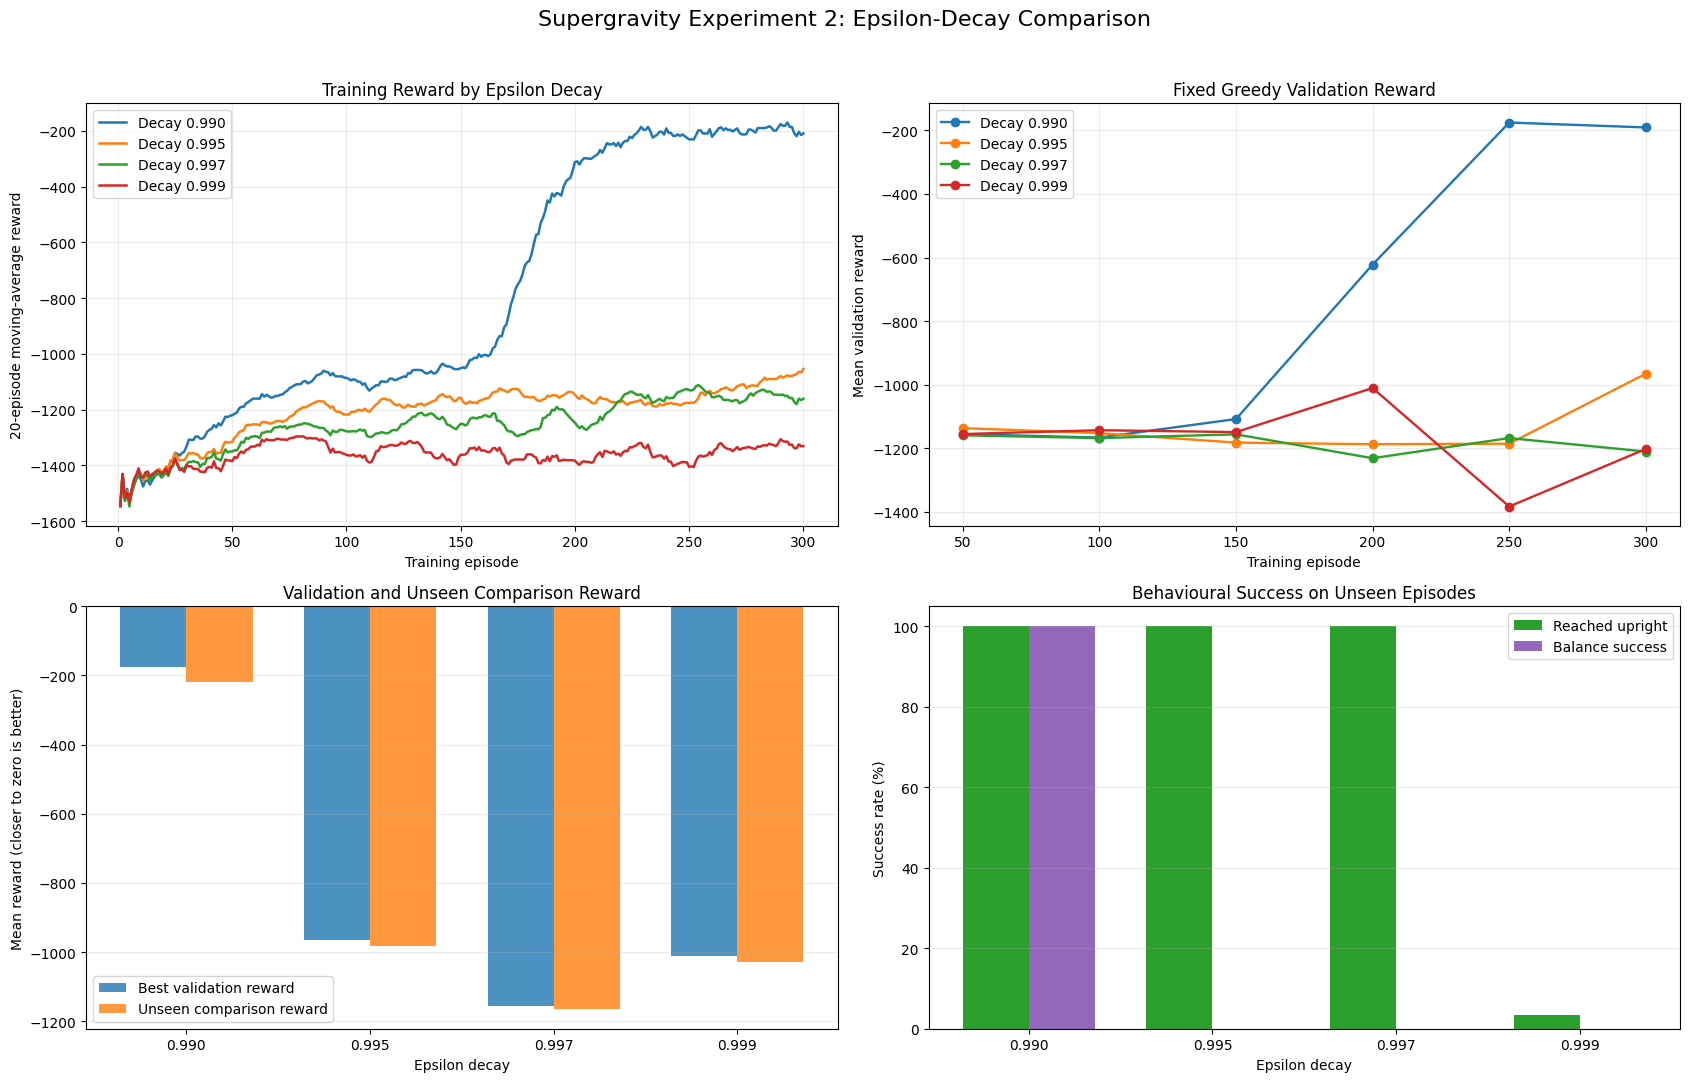

Figure saved to: figures\supergravity\super_experiment_2_epsilon_decay.png


In [117]:
# ---------------------------------------------------------
# Supergravity epsilon-decay visualisation
# ---------------------------------------------------------

best_position = (
    super_epsilon_results_dataframe[
        "best_validation_mean_reward"
    ].idxmax()
)

best_validation_decay = float(
    super_epsilon_results_dataframe.loc[
        best_position,
        "epsilon_decay",
    ]
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 11),
)


# Plot 1: Training curves
for epsilon_decay in SUPER_EPSILON_DECAYS:
    candidate_training = (
        super_epsilon_training_dataframe.loc[
            np.isclose(
                super_epsilon_training_dataframe[
                    "epsilon_decay"
                ],
                epsilon_decay,
            )
        ]
        .sort_values("episode")
    )

    axes[0, 0].plot(
        candidate_training["episode"],
        candidate_training[
            "moving_average_reward"
        ],
        linewidth=1.8,
        label=f"Decay {epsilon_decay:.3f}",
    )

axes[0, 0].set_title(
    "Training Reward by Epsilon Decay"
)
axes[0, 0].set_xlabel("Training episode")
axes[0, 0].set_ylabel(
    "20-episode moving-average reward"
)
axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend()


# Plot 2: Validation curves
for epsilon_decay in SUPER_EPSILON_DECAYS:
    candidate_validation = (
        super_epsilon_validation_dataframe.loc[
            np.isclose(
                super_epsilon_validation_dataframe[
                    "epsilon_decay"
                ],
                epsilon_decay,
            )
        ]
        .sort_values("training_episode")
    )

    axes[0, 1].plot(
        candidate_validation[
            "training_episode"
        ],
        candidate_validation[
            "validation_mean_reward"
        ],
        marker="o",
        linewidth=1.7,
        label=f"Decay {epsilon_decay:.3f}",
    )

axes[0, 1].set_title(
    "Fixed Greedy Validation Reward"
)
axes[0, 1].set_xlabel("Training episode")
axes[0, 1].set_ylabel("Mean validation reward")
axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend()


# Plot 3: Validation versus comparison
positions = np.arange(
    len(SUPER_EPSILON_DECAYS)
)

bar_width = 0.36

axes[1, 0].bar(
    positions - bar_width / 2,
    super_epsilon_results_dataframe[
        "best_validation_mean_reward"
    ],
    width=bar_width,
    label="Best validation reward",
    color="tab:blue",
    alpha=0.8,
)

axes[1, 0].bar(
    positions + bar_width / 2,
    super_epsilon_results_dataframe[
        "comparison_mean_reward"
    ],
    width=bar_width,
    label="Unseen comparison reward",
    color="tab:orange",
    alpha=0.8,
)

axes[1, 0].set_title(
    "Validation and Unseen Comparison Reward"
)
axes[1, 0].set_xlabel("Epsilon decay")
axes[1, 0].set_ylabel(
    "Mean reward (closer to zero is better)"
)
axes[1, 0].set_xticks(positions)
axes[1, 0].set_xticklabels(
    [
        f"{decay:.3f}"
        for decay in SUPER_EPSILON_DECAYS
    ]
)
axes[1, 0].grid(
    axis="y",
    alpha=0.25,
)
axes[1, 0].legend()


# Plot 4: Behavioural results
upright_rates = (
    super_epsilon_results_dataframe[
        "reached_upright_rate"
    ].to_numpy()
    * 100
)

balance_rates = (
    super_epsilon_results_dataframe[
        "balance_success_rate"
    ].to_numpy()
    * 100
)

axes[1, 1].bar(
    positions - bar_width / 2,
    upright_rates,
    width=bar_width,
    label="Reached upright",
    color="tab:green",
)

axes[1, 1].bar(
    positions + bar_width / 2,
    balance_rates,
    width=bar_width,
    label="Balance success",
    color="tab:purple",
)

axes[1, 1].set_title(
    "Behavioural Success on Unseen Episodes"
)
axes[1, 1].set_xlabel("Epsilon decay")
axes[1, 1].set_ylabel("Success rate (%)")
axes[1, 1].set_xticks(positions)
axes[1, 1].set_xticklabels(
    [
        f"{decay:.3f}"
        for decay in SUPER_EPSILON_DECAYS
    ]
)
axes[1, 1].set_ylim(0, 105)
axes[1, 1].grid(
    axis="y",
    alpha=0.25,
)
axes[1, 1].legend()


plt.suptitle(
    "Supergravity Experiment 2: "
    "Epsilon-Decay Comparison",
    fontsize=16,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

super_epsilon_figure_path = (
    SUPER_FIGURES_DIR
    / "super_experiment_2_epsilon_decay.png"
)

plt.savefig(
    super_epsilon_figure_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure saved to:",
    super_epsilon_figure_path,
)

## Supergravity Experiment 2 Evaluation: Epsilon Decay

This experiment compared epsilon-decay values of **0.990, 0.995, 0.997 and 0.999** under supergravity (`g = 15`). The selected **11-action space**, Standard DQN architecture, learning rate, training length, seeds and evaluation conditions were held constant. Every candidate completed all **300 training episodes**, with early stopping disabled.

| Epsilon decay | Best validation reward |          Unseen reward | Reached upright | Balance success |
| ------------: | ---------------------: | ---------------------: | --------------: | --------------: |
|     **0.990** | **−175.364 ± 108.351** | **−218.516 ± 111.521** |      **100.0%** |      **100.0%** |
|         0.995 |      −965.312 ± 44.886 |      −982.921 ± 51.919 |          100.0% |            0.0% |
|         0.997 |     −1155.983 ± 22.863 |     −1163.586 ± 30.189 |          100.0% |            0.0% |
|         0.999 |    −1010.378 ± 155.134 |    −1028.574 ± 131.345 |            3.3% |            0.0% |

Because Pendulum rewards are negative, values closer to zero indicate better performance. An epsilon decay of **0.990** achieved the best validation reward of **−175.364 ± 108.351** at episode **250**. It exceeded the second-ranked decay of 0.995 by **789.948 reward points**.

The independent unseen comparison confirmed the same winner. Decay 0.990 achieved **−218.516 ± 111.521**, outperforming decay 0.995 by **764.405 points**. Its episode rewards ranged from **−440.047 to −0.681**, showing that several episodes approached near-optimal performance, although some variability remained.

The behavioural measurements provide especially strong support for this selection. Decay 0.990 reached the upright condition in **100%** of unseen episodes and achieved a **100% balance-success rate**. It remained upright for an average of **163.767 out of 200 steps**, with a mean longest balance streak of **159.8 steps**.

Although decays 0.995 and 0.997 also reached upright in every episode, they achieved 0% balance success and remained upright for only 27.600 and 15.267 steps on average. They learned to swing upward briefly but did not learn sustained stabilisation. Decay 0.999 performed worst behaviourally, reaching upright in only 3.3% of episodes.

The training curve for decay 0.990 improved sharply after approximately episode 170 and stabilised near a moving-average reward of −200. The slower-decay candidates remained between approximately −1000 and −1350. Within this implementation, decay 0.990 reduced random exploration quickly enough for the agent to exploit and refine its successful swing-up and balancing strategy. The slower schedules preserved exploration for too long during the available 300 episodes.

Therefore, an epsilon decay of **0.990 is selected for the remaining supergravity experiments**. Unlike Experiment 1, this configuration should be described as a successful balancing controller under the current evaluation criteria. However, the comparison used one controlled training seed. Therefore, the result identifies the best observed epsilon-decay setting under the current experiment conditions, but variation across different training initialisations was not measured.


In [118]:
# ---------------------------------------------------------
# Supergravity Experiment 3:
# Learning-rate setup
# ---------------------------------------------------------

SUPER_SELECTED_ACTION_COUNT = 11
SUPER_SELECTED_EPSILON_DECAY = 0.990

SUPER_SELECTED_ACTION_VALUES = np.linspace(
    -2.0,
    2.0,
    SUPER_SELECTED_ACTION_COUNT,
    dtype=np.float32,
)

SUPER_LEARNING_RATES = [
    0.0001,
    0.0005,
    0.0010,  # Original control
    0.0020,
]

SUPER_LR_TRAINING_SEED = 125
SUPER_LR_VALIDATION_SEED = 1_600_003
SUPER_LR_COMPARISON_SEED = 2_600_003

SUPER_LR_MAX_EPISODES = 300
SUPER_LR_MAX_STEPS = 200

SUPER_LR_EVALUATION_EVERY = 50
SUPER_LR_VALIDATION_EPISODES = 20
SUPER_LR_COMPARISON_EPISODES = 30

SUPER_LR_MINIMUM_EPISODES = 150

# Effectively disables early stopping.
SUPER_LR_EARLY_STOPPING_PATIENCE = 999
SUPER_LR_EARLY_STOPPING_MIN_DELTA = 0.0


SUPER_LR_RESULTS_DIR = (
    SUPER_RESULTS_DIR
    / "experiment_3_learning_rate"
)

SUPER_LR_WEIGHTS_DIR = (
    SUPER_WEIGHTS_DIR
    / "experiment_3_learning_rate"
)

for directory in [
    SUPER_LR_RESULTS_DIR,
    SUPER_LR_WEIGHTS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


def make_super_lr_config(learning_rate):
    """Create one learning-rate configuration."""

    config = make_super_epsilon_config(
        SUPER_SELECTED_EPSILON_DECAY
    )

    config.learning_rate = float(
        learning_rate
    )

    return config


def get_learning_rate_label(learning_rate):
    """Create a filename-safe learning-rate label."""

    return (
        f"{learning_rate:.4f}"
        .replace(".", "p")
    )


def get_super_lr_paths(learning_rate):
    """Return output paths for one candidate."""

    label = get_learning_rate_label(
        learning_rate
    )

    run_name = (
        f"standard_dqn_learning_rate_{label}"
    )

    return {
        "weights": (
            SUPER_LR_WEIGHTS_DIR
            / f"{run_name}.weights.h5"
        ),
        "training": (
            SUPER_LR_RESULTS_DIR
            / f"{run_name}_training.csv"
        ),
        "validation": (
            SUPER_LR_RESULTS_DIR
            / f"{run_name}_validation.csv"
        ),
        "checkpoint": (
            SUPER_LR_RESULTS_DIR
            / f"{run_name}_checkpoint.csv"
        ),
        "comparison": (
            SUPER_LR_RESULTS_DIR
            / f"{run_name}_comparison.csv"
        ),
    }


SUPER_LR_PATHS = {
    learning_rate: get_super_lr_paths(
        learning_rate
    )
    for learning_rate in SUPER_LEARNING_RATES
}


probe_env = create_pendulum_env(
    gravity=SUPER_GRAVITY_VALUE,
    seed=SUPER_LR_TRAINING_SEED,
)

SUPER_STATE_SIZE = int(
    probe_env.observation_space.shape[0]
)

print("Gravity:", probe_env.unwrapped.g)
print(
    "Selected action count:",
    SUPER_SELECTED_ACTION_COUNT,
)
print(
    "Selected epsilon decay:",
    SUPER_SELECTED_EPSILON_DECAY,
)
print(
    "Learning-rate candidates:",
    SUPER_LEARNING_RATES,
)
print("Early stopping: disabled")

probe_env.close()

Gravity: 15.0
Selected action count: 11
Selected epsilon decay: 0.99
Learning-rate candidates: [0.0001, 0.0005, 0.001, 0.002]
Early stopping: disabled


In [119]:
# ---------------------------------------------------------
# Train every learning-rate candidate
# ---------------------------------------------------------

for run_number, learning_rate in enumerate(
    SUPER_LEARNING_RATES,
    start=1,
):
    run_paths = SUPER_LR_PATHS[
        learning_rate
    ]

    required_paths = [
        run_paths["weights"],
        run_paths["training"],
        run_paths["validation"],
        run_paths["checkpoint"],
    ]

    if all(
        path.exists()
        for path in required_paths
    ):
        print(
            f"Learning rate {learning_rate:g}: "
            "complete results already exist."
        )
        continue

    print("\n" + "=" * 72)
    print(
        f"SUPERGRAVITY LEARNING-RATE EXPERIMENT "
        f"{run_number}/"
        f"{len(SUPER_LEARNING_RATES)} | "
        f"LR = {learning_rate:g}"
    )
    print("=" * 72)

    tf.keras.backend.clear_session()
    set_global_seed(
        SUPER_LR_TRAINING_SEED
    )

    training_env = None
    validation_env = None
    lr_agent = None

    try:
        current_config = make_super_lr_config(
            learning_rate
        )

        training_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_LR_TRAINING_SEED,
        )

        validation_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_LR_VALIDATION_SEED,
        )

        lr_agent = DQNAgent(
            state_size=SUPER_STATE_SIZE,
            action_values=(
                SUPER_SELECTED_ACTION_VALUES
            ),
            config=current_config,
            use_double_dqn=False,
        )

        (
            lr_history,
            lr_training_dataframe,
        ) = train_agent(
            env=training_env,
            agent=lr_agent,
            episodes=SUPER_LR_MAX_EPISODES,
            max_steps=SUPER_LR_MAX_STEPS,
            moving_average_window=20,
            seed=SUPER_LR_TRAINING_SEED,

            evaluation_env=validation_env,
            evaluation_every=(
                SUPER_LR_EVALUATION_EVERY
            ),
            evaluation_episodes=(
                SUPER_LR_VALIDATION_EPISODES
            ),
            evaluation_seed=(
                SUPER_LR_VALIDATION_SEED
            ),
            best_weights_path=(
                run_paths["weights"]
            ),

            print_every=25,
            render_every=None,

            early_stopping_minimum_episodes=(
                SUPER_LR_MINIMUM_EPISODES
            ),
            early_stopping_patience=(
                SUPER_LR_EARLY_STOPPING_PATIENCE
            ),
            early_stopping_min_delta=(
                SUPER_LR_EARLY_STOPPING_MIN_DELTA
            ),
        )

        lr_training_dataframe.insert(
            0,
            "learning_rate",
            learning_rate,
        )

        lr_training_dataframe.to_csv(
            run_paths["training"],
            index=False,
        )

        lr_validation_dataframe = pd.DataFrame({
            "learning_rate": learning_rate,
            "training_episode": (
                lr_history[
                    "evaluation_episode"
                ]
            ),
            "validation_mean_reward": (
                lr_history[
                    "evaluation_mean_reward"
                ]
            ),
            "validation_reward_std": (
                lr_history[
                    "evaluation_reward_std"
                ]
            ),
            "validation_improved": (
                lr_history[
                    "evaluation_improved"
                ]
            ),
            "validations_without_improvement": (
                lr_history[
                    "validations_without_improvement"
                ]
            ),
        })

        lr_validation_dataframe.to_csv(
            run_paths["validation"],
            index=False,
        )

        validation_means = np.asarray(
            lr_history[
                "evaluation_mean_reward"
            ],
            dtype=float,
        )

        if len(validation_means) == 0:
            raise RuntimeError(
                "No validation results were produced "
                f"for learning rate {learning_rate}."
            )

        best_position = int(
            np.argmax(validation_means)
        )

        lr_checkpoint_dataframe = pd.DataFrame([
            {
                "learning_rate": learning_rate,
                "action_count": (
                    SUPER_SELECTED_ACTION_COUNT
                ),
                "epsilon_decay": (
                    SUPER_SELECTED_EPSILON_DECAY
                ),
                "training_seed": (
                    SUPER_LR_TRAINING_SEED
                ),
                "validation_seed": (
                    SUPER_LR_VALIDATION_SEED
                ),
                "trained_episodes": int(
                    lr_history["stop_episode"]
                ),
                "stopped_early": bool(
                    lr_history["stopped_early"]
                ),
                "best_checkpoint_episode": int(
                    lr_history[
                        "evaluation_episode"
                    ][best_position]
                ),
                "best_validation_mean_reward": float(
                    validation_means[
                        best_position
                    ]
                ),
                "best_validation_reward_std": float(
                    lr_history[
                        "evaluation_reward_std"
                    ][best_position]
                ),
                "parameter_count": int(
                    lr_agent
                    .online_network
                    .count_params()
                ),
            }
        ])

        lr_checkpoint_dataframe.to_csv(
            run_paths["checkpoint"],
            index=False,
        )

        print(
            f"Learning rate {learning_rate:g} "
            f"completed | trained episodes: "
            f"{lr_history['stop_episode']} | "
            f"best checkpoint: "
            f"{lr_history['evaluation_episode'][best_position]} | "
            f"validation reward: "
            f"{validation_means[best_position]:.3f}"
        )

    finally:
        if training_env is not None:
            training_env.close()

        if validation_env is not None:
            validation_env.close()

        lr_agent = None
        tf.keras.backend.clear_session()
        gc.collect()


SUPERGRAVITY LEARNING-RATE EXPERIMENT 1/4 | LR = 0.0001
Episode    1/300 | Reward: -1715.93 | Moving average: -1715.93 | Epsilon: 0.9900 | Loss: not training yet | Replay size: 200
Episode   25/300 | Reward: -1410.52 | Moving average: -1498.21 | Epsilon: 0.7778 | Loss: 4.0511 | Replay size: 5000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_3_learning_rate\standard_dqn_learning_rate_0p0001.weights.h5
Evaluation at episode 50: mean reward = -985.66, std = 45.90, wait = 0/999
New best weights saved.
Episode   50/300 | Reward: -1246.03 | Moving average: -1225.47 | Epsilon: 0.6050 | Loss: 4.4893 | Replay size: 10000
Episode   75/300 | Reward: -1046.90 | Moving average: -1101.71 | Epsilon: 0.4706 | Loss: 3.9653 | Replay size: 15000
Evaluation at episode 100: mean reward = -1054.78, std = 43.43, wait = 1/999
Episode  100/300 | Reward: -1056.68 | Moving average: -1058.71 | Epsilon: 0.3660 | Loss: 3.5550 | Replay size: 20000
Episode  125/300 | Reward: -1070

In [120]:
# ---------------------------------------------------------
# Evaluate checkpoints on unseen comparison episodes
# ---------------------------------------------------------

super_lr_result_records = []
super_lr_comparison_frames = []


for learning_rate in SUPER_LEARNING_RATES:
    run_paths = SUPER_LR_PATHS[
        learning_rate
    ]

    for required_name in [
        "weights",
        "training",
        "validation",
        "checkpoint",
    ]:
        required_path = run_paths[
            required_name
        ]

        if not required_path.exists():
            raise FileNotFoundError(
                f"Missing {required_name} for "
                f"learning rate {learning_rate}: "
                f"{required_path}"
            )

    checkpoint_row = pd.read_csv(
        run_paths["checkpoint"]
    ).iloc[0]

    tf.keras.backend.clear_session()
    set_global_seed(
        SUPER_LR_TRAINING_SEED
    )

    comparison_env = None
    evaluation_agent = None

    try:
        current_config = make_super_lr_config(
            learning_rate
        )

        comparison_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_LR_COMPARISON_SEED,
        )

        evaluation_agent = DQNAgent(
            state_size=SUPER_STATE_SIZE,
            action_values=(
                SUPER_SELECTED_ACTION_VALUES
            ),
            config=current_config,
            use_double_dqn=False,
        )

        evaluation_agent.load_weights(
            run_paths["weights"]
        )

        evaluation_agent.epsilon = 0.0

        comparison_result = evaluate_agent(
            env=comparison_env,
            agent=evaluation_agent,
            episodes=(
                SUPER_LR_COMPARISON_EPISODES
            ),
            max_steps=SUPER_LR_MAX_STEPS,
            seed=SUPER_LR_COMPARISON_SEED,
            best_score=None,
            save_path=None,
            verbose=False,
        )

        super_lr_result_records.append({
            "learning_rate": learning_rate,
            "action_count": (
                SUPER_SELECTED_ACTION_COUNT
            ),
            "epsilon_decay": (
                SUPER_SELECTED_EPSILON_DECAY
            ),
            "parameter_count": int(
                checkpoint_row[
                    "parameter_count"
                ]
            ),
            "trained_episodes": int(
                checkpoint_row[
                    "trained_episodes"
                ]
            ),
            "stopped_early": (
                str(
                    checkpoint_row[
                        "stopped_early"
                    ]
                )
                .strip()
                .lower()
                == "true"
            ),
            "best_checkpoint_episode": int(
                checkpoint_row[
                    "best_checkpoint_episode"
                ]
            ),
            "best_validation_mean_reward": float(
                checkpoint_row[
                    "best_validation_mean_reward"
                ]
            ),
            "best_validation_reward_std": float(
                checkpoint_row[
                    "best_validation_reward_std"
                ]
            ),
            "comparison_mean_reward": float(
                comparison_result["mean_reward"]
            ),
            "comparison_reward_std": float(
                comparison_result["reward_std"]
            ),
            "comparison_minimum_reward": float(
                comparison_result[
                    "minimum_reward"
                ]
            ),
            "comparison_maximum_reward": float(
                comparison_result[
                    "maximum_reward"
                ]
            ),
            "reached_upright_rate": float(
                comparison_result[
                    "reached_upright_rate"
                ]
            ),
            "balance_success_rate": float(
                comparison_result[
                    "balance_success_rate"
                ]
            ),
            "mean_upright_steps": float(
                comparison_result[
                    "mean_upright_steps"
                ]
            ),
            "mean_longest_balance_streak": float(
                comparison_result[
                    "mean_longest_balance_streak"
                ]
            ),
        })

        episode_dataframe = pd.DataFrame(
            comparison_result[
                "episode_metrics"
            ]
        )

        episode_dataframe.insert(
            0,
            "learning_rate",
            learning_rate,
        )

        episode_dataframe.to_csv(
            run_paths["comparison"],
            index=False,
        )

        super_lr_comparison_frames.append(
            episode_dataframe
        )

        print(
            f"Learning rate {learning_rate:g} | "
            f"comparison reward: "
            f"{comparison_result['mean_reward']:.3f} "
            f"± {comparison_result['reward_std']:.3f} | "
            f"upright: "
            f"{comparison_result['reached_upright_rate']:.1%} | "
            f"balance: "
            f"{comparison_result['balance_success_rate']:.1%}"
        )

    finally:
        if comparison_env is not None:
            comparison_env.close()

        evaluation_agent = None
        tf.keras.backend.clear_session()
        gc.collect()


super_lr_results_dataframe = (
    pd.DataFrame(
        super_lr_result_records
    )
    .sort_values("learning_rate")
    .reset_index(drop=True)
)

super_lr_training_dataframe = pd.concat(
    [
        pd.read_csv(
            SUPER_LR_PATHS[
                learning_rate
            ]["training"]
        )
        for learning_rate
        in SUPER_LEARNING_RATES
    ],
    ignore_index=True,
)

super_lr_validation_dataframe = pd.concat(
    [
        pd.read_csv(
            SUPER_LR_PATHS[
                learning_rate
            ]["validation"]
        )
        for learning_rate
        in SUPER_LEARNING_RATES
    ],
    ignore_index=True,
)

super_lr_comparison_dataframe = pd.concat(
    super_lr_comparison_frames,
    ignore_index=True,
)

super_lr_results_dataframe.to_csv(
    SUPER_LR_RESULTS_DIR
    / "super_learning_rate_summary.csv",
    index=False,
)

super_lr_comparison_dataframe.to_csv(
    SUPER_LR_RESULTS_DIR
    / "super_learning_rate_comparison_episodes.csv",
    index=False,
)

display(
    super_lr_results_dataframe.round(3)
)

Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_3_learning_rate\standard_dqn_learning_rate_0p0001.weights.h5
Learning rate 0.0001 | comparison reward: -588.341 ± 85.561 | upright: 100.0% | balance: 3.3%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_3_learning_rate\standard_dqn_learning_rate_0p0005.weights.h5
Learning rate 0.0005 | comparison reward: -218.449 ± 107.995 | upright: 100.0% | balance: 100.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_3_learning_rate\standard_dqn_learning_rate_0p0010.weights.h5
Learning rate 0.001 | comparison reward: -214.530 ± 105.189 | upright: 100.0% | balance: 100.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_3_learning_rate\standard_dqn_learning_rate_0p0020.weights.h5
Learning rate 0.002 | comparison reward: -228.700 ± 120.364 | upright: 100.0% | balance: 100.0%


,learning_rate,action_count,epsilon_decay,parameter_count,trained_episodes,stopped_early,best_checkpoint_episode,best_validation_mean_reward,best_validation_reward_std,comparison_mean_reward,comparison_reward_std,comparison_minimum_reward,comparison_maximum_reward,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,0.000,11,0.99,5131,300,False,300,-553.478,79.557,-588.341,85.561,-741.421,-487.704,1.0,0.033,73.567,16.633
1,0.000,11,0.99,5131,300,False,250,-171.922,102.726,-218.449,107.995,-422.648,-0.647,1.0,1.000,164.267,160.900
2,0.001,11,0.99,5131,300,False,300,-170.913,99.675,-214.530,105.189,-416.304,-1.084,1.0,1.000,164.933,160.867
3,0.002,11,0.99,5131,300,False,300,-182.586,111.481,-228.700,120.364,-441.979,-2.214,1.0,1.000,162.700,154.500


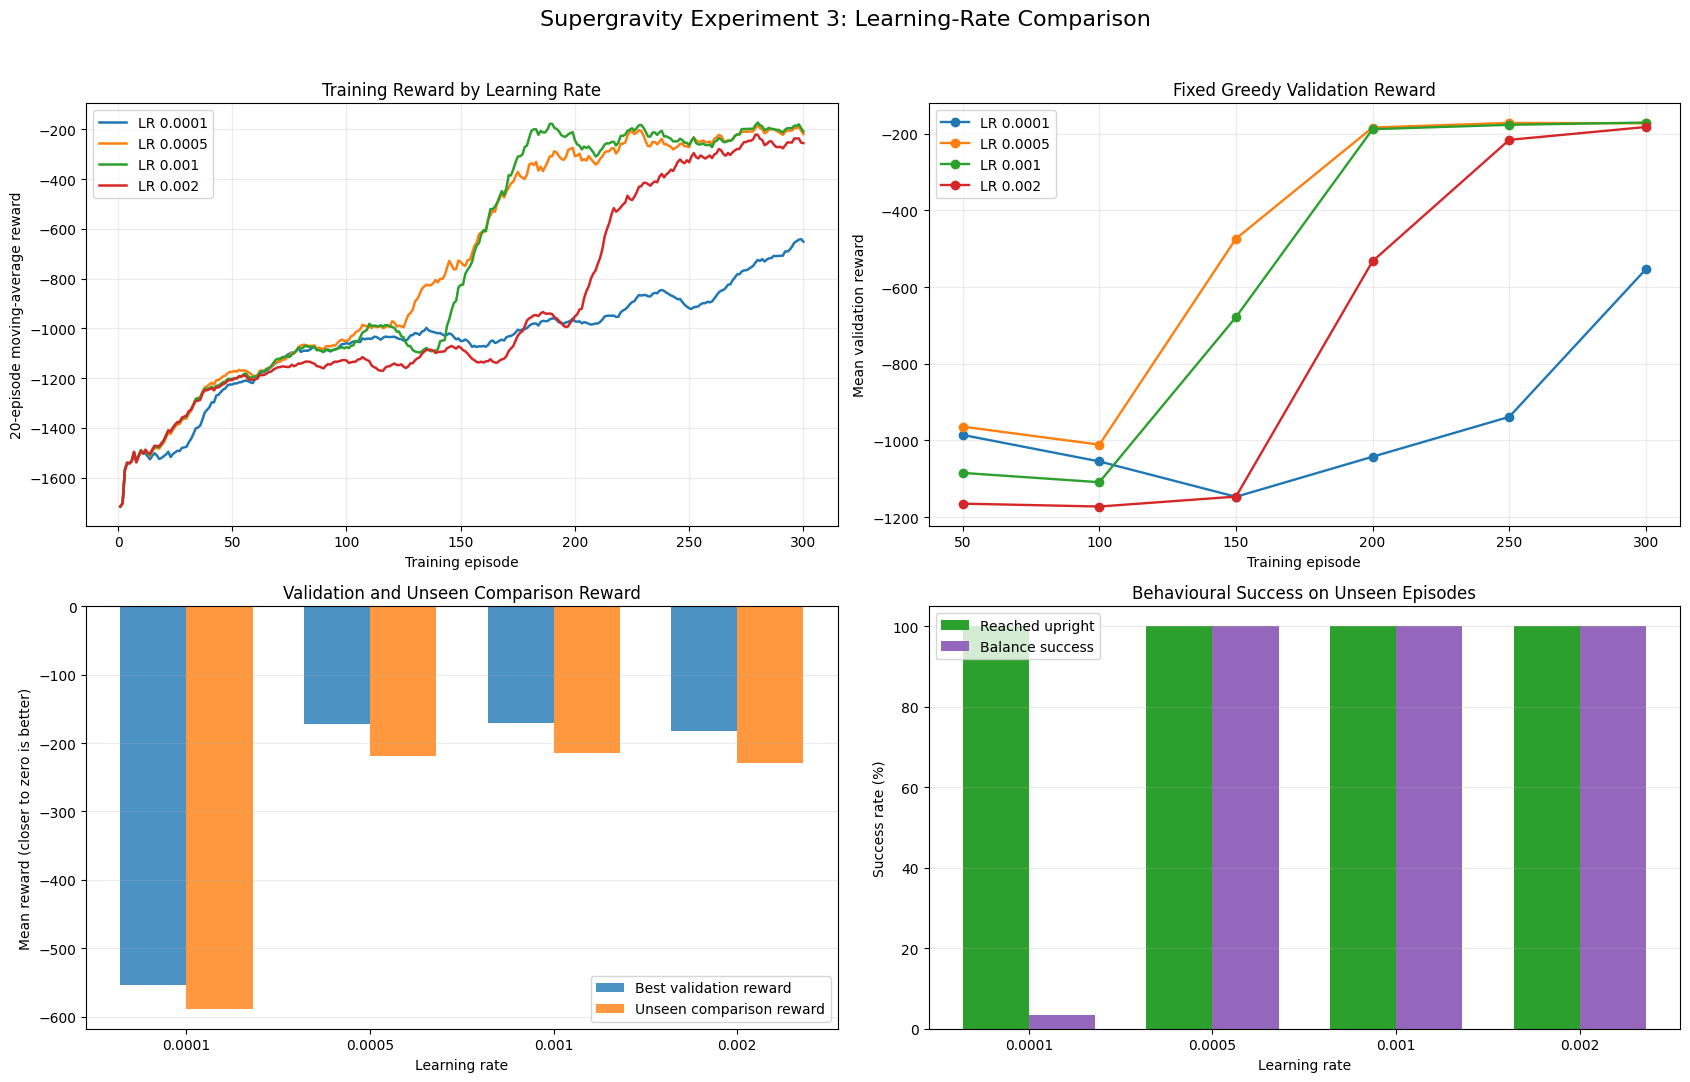

Figure saved to: figures\supergravity\super_experiment_3_learning_rate.png


In [121]:
# ---------------------------------------------------------
# Supergravity learning-rate visualisation
# ---------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 11),
)


# Plot 1: Training curves
for learning_rate in SUPER_LEARNING_RATES:
    candidate_training = (
        super_lr_training_dataframe.loc[
            np.isclose(
                super_lr_training_dataframe[
                    "learning_rate"
                ],
                learning_rate,
            )
        ]
        .sort_values("episode")
    )

    axes[0, 0].plot(
        candidate_training["episode"],
        candidate_training[
            "moving_average_reward"
        ],
        linewidth=1.8,
        label=f"LR {learning_rate:g}",
    )

axes[0, 0].set_title(
    "Training Reward by Learning Rate"
)
axes[0, 0].set_xlabel("Training episode")
axes[0, 0].set_ylabel(
    "20-episode moving-average reward"
)
axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend()


# Plot 2: Validation curves
for learning_rate in SUPER_LEARNING_RATES:
    candidate_validation = (
        super_lr_validation_dataframe.loc[
            np.isclose(
                super_lr_validation_dataframe[
                    "learning_rate"
                ],
                learning_rate,
            )
        ]
        .sort_values("training_episode")
    )

    axes[0, 1].plot(
        candidate_validation[
            "training_episode"
        ],
        candidate_validation[
            "validation_mean_reward"
        ],
        marker="o",
        linewidth=1.7,
        label=f"LR {learning_rate:g}",
    )

axes[0, 1].set_title(
    "Fixed Greedy Validation Reward"
)
axes[0, 1].set_xlabel("Training episode")
axes[0, 1].set_ylabel("Mean validation reward")
axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend()


# Plot 3: Validation versus comparison
positions = np.arange(
    len(SUPER_LEARNING_RATES)
)

bar_width = 0.36

axes[1, 0].bar(
    positions - bar_width / 2,
    super_lr_results_dataframe[
        "best_validation_mean_reward"
    ],
    width=bar_width,
    label="Best validation reward",
    color="tab:blue",
    alpha=0.8,
)

axes[1, 0].bar(
    positions + bar_width / 2,
    super_lr_results_dataframe[
        "comparison_mean_reward"
    ],
    width=bar_width,
    label="Unseen comparison reward",
    color="tab:orange",
    alpha=0.8,
)

axes[1, 0].set_title(
    "Validation and Unseen Comparison Reward"
)
axes[1, 0].set_xlabel("Learning rate")
axes[1, 0].set_ylabel(
    "Mean reward (closer to zero is better)"
)
axes[1, 0].set_xticks(positions)
axes[1, 0].set_xticklabels(
    [
        f"{learning_rate:g}"
        for learning_rate
        in SUPER_LEARNING_RATES
    ]
)
axes[1, 0].grid(
    axis="y",
    alpha=0.25,
)
axes[1, 0].legend()


# Plot 4: Behavioural results
upright_rates = (
    super_lr_results_dataframe[
        "reached_upright_rate"
    ].to_numpy()
    * 100
)

balance_rates = (
    super_lr_results_dataframe[
        "balance_success_rate"
    ].to_numpy()
    * 100
)

axes[1, 1].bar(
    positions - bar_width / 2,
    upright_rates,
    width=bar_width,
    label="Reached upright",
    color="tab:green",
)

axes[1, 1].bar(
    positions + bar_width / 2,
    balance_rates,
    width=bar_width,
    label="Balance success",
    color="tab:purple",
)

axes[1, 1].set_title(
    "Behavioural Success on Unseen Episodes"
)
axes[1, 1].set_xlabel("Learning rate")
axes[1, 1].set_ylabel("Success rate (%)")
axes[1, 1].set_xticks(positions)
axes[1, 1].set_xticklabels(
    [
        f"{learning_rate:g}"
        for learning_rate
        in SUPER_LEARNING_RATES
    ]
)
axes[1, 1].set_ylim(0, 105)
axes[1, 1].grid(
    axis="y",
    alpha=0.25,
)
axes[1, 1].legend()


plt.suptitle(
    "Supergravity Experiment 3: "
    "Learning-Rate Comparison",
    fontsize=16,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

super_lr_figure_path = (
    SUPER_FIGURES_DIR
    / "super_experiment_3_learning_rate.png"
)

plt.savefig(
    super_lr_figure_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure saved to:",
    super_lr_figure_path,
)

## Supergravity Experiment 3 Evaluation: Learning Rate

This experiment compared learning rates of **0.0001, 0.0005, 0.001 and 0.002** under supergravity (`g = 15`). The selected **11-action space**, epsilon decay of **0.990**, Standard DQN architecture, training seeds and evaluation conditions were held constant. Every configuration completed all **300 training episodes**, with no early stopping.

| Learning rate | Best validation reward |          Unseen reward | Reached upright | Balance success |
| ------------: | ---------------------: | ---------------------: | --------------: | --------------: |
|        0.0001 |               −553.478 |      −588.341 ± 85.561 |          100.0% |            3.3% |
|        0.0005 |               −171.922 |     −218.449 ± 107.995 |          100.0% |          100.0% |
|     **0.001** |           **−170.913** | **−214.530 ± 105.189** |      **100.0%** |      **100.0%** |
|         0.002 |               −182.586 |     −228.700 ± 120.364 |          100.0% |          100.0% |

Because Pendulum rewards are negative, values closer to zero indicate better performance. A learning rate of **0.001** produced the best validation reward of **−170.913** at episode **300**. However, it exceeded learning rate 0.0005 by only **1.009 reward points**, making these two configurations practically very close.

The independent unseen comparison produced the same winner. Learning rate 0.001 achieved **−214.530 ± 105.189**, compared with **−218.449 ± 107.995** for 0.0005—a difference of only **3.919 points**. This agreement supports the validation-based selection, but the small margins and strongly overlapping variability mean that the experiment does not establish a large performance difference between these two rates.

The behavioural results provide additional support. Learning rate 0.001 reached upright and achieved balance success in **100% of unseen episodes**. It remained upright for an average of **164.933 out of 200 steps**, with a mean longest balance streak of **160.867 steps**. Its unseen rewards ranged from **−416.304 to −1.084**, showing that some episodes approached near-optimal performance while noticeable episode-to-episode variability remained.

Learning rates 0.0005 and 0.002 also achieved 100% upright and balance success. Learning rate 0.0005 produced a marginally longer mean balance streak of **160.900 steps**, compared with 160.867 for 0.001, but its average reward and mean upright duration were slightly weaker. Therefore, the overall results for 0.0005 and 0.001 should be described as near-equivalent rather than claiming that 0.001 was substantially superior.

The training curves show that 0.0005 improved earlier, whereas 0.001 required longer before its reward increased sharply and eventually produced the strongest final validation result. Learning rate 0.002 learned more slowly but converged to a successful controller near the end of training. In contrast, 0.0001 produced updates that were too small for the 300-episode training budget. Although it reached upright in every unseen episode, it achieved only **3.3% balance success**, indicating that it generally failed to maintain stable balancing.

Therefore, a learning rate of **0.001 is formally selected** for the remaining supergravity experiments because it ranked first under the predefined validation-reward criterion and was also the unseen-comparison winner. Nevertheless, the comparison used one controlled training seed. The small difference between 0.001 and 0.0005 should therefore be interpreted as the best observed result under the current conditions rather than proof that 0.001 is always superior.


In [122]:
# ---------------------------------------------------------
# Supergravity Experiment 4:
# Training-duration setup
# ---------------------------------------------------------

SUPER_SELECTED_ACTION_COUNT = 11
SUPER_SELECTED_EPSILON_DECAY = 0.990
SUPER_SELECTED_LEARNING_RATE = 0.001

SUPER_SELECTED_ACTION_VALUES = np.linspace(
    -2.0,
    2.0,
    SUPER_SELECTED_ACTION_COUNT,
    dtype=np.float32,
)

SUPER_TRAINING_DURATIONS = [
    200,
    300,  # Original control
    400,
    500,
]

SUPER_DURATION_TRAINING_SEED = 126
SUPER_DURATION_VALIDATION_SEED = 1_600_004
SUPER_DURATION_COMPARISON_SEED = 2_600_004

SUPER_DURATION_MAX_STEPS = 200

SUPER_DURATION_EVALUATION_EVERY = 50
SUPER_DURATION_VALIDATION_EPISODES = 20
SUPER_DURATION_COMPARISON_EPISODES = 30

# Early stopping remains disabled.
SUPER_DURATION_MINIMUM_EPISODES = 150
SUPER_DURATION_EARLY_STOPPING_PATIENCE = 999
SUPER_DURATION_EARLY_STOPPING_MIN_DELTA = 0.0


SUPER_DURATION_RESULTS_DIR = (
    SUPER_RESULTS_DIR
    / "experiment_4_training_duration"
)

SUPER_DURATION_WEIGHTS_DIR = (
    SUPER_WEIGHTS_DIR
    / "experiment_4_training_duration"
)

for directory in [
    SUPER_DURATION_RESULTS_DIR,
    SUPER_DURATION_WEIGHTS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


def make_super_duration_config():
    """Create the fixed configuration for Experiment 4."""

    config = make_super_lr_config(
        SUPER_SELECTED_LEARNING_RATE
    )

    return config


def get_duration_label(training_duration):
    """Create a filename-safe duration label."""

    return f"{int(training_duration):04d}_episodes"


def get_super_duration_paths(training_duration):
    """Return all output paths for one duration."""

    label = get_duration_label(
        training_duration
    )

    run_name = (
        f"standard_dqn_{label}"
    )

    return {
        # Final checkpoint used for selection.
        "weights": (
            SUPER_DURATION_WEIGHTS_DIR
            / f"{run_name}_final.weights.h5"
        ),

        # Retained only as a diagnostic.
        "best_weights": (
            SUPER_DURATION_WEIGHTS_DIR
            / f"{run_name}_best_validation.weights.h5"
        ),

        "training": (
            SUPER_DURATION_RESULTS_DIR
            / f"{run_name}_training.csv"
        ),

        "validation": (
            SUPER_DURATION_RESULTS_DIR
            / f"{run_name}_validation.csv"
        ),

        "checkpoint": (
            SUPER_DURATION_RESULTS_DIR
            / f"{run_name}_checkpoint.csv"
        ),

        "comparison": (
            SUPER_DURATION_RESULTS_DIR
            / f"{run_name}_comparison.csv"
        ),
    }


SUPER_DURATION_PATHS = {
    training_duration: get_super_duration_paths(
        training_duration
    )
    for training_duration
    in SUPER_TRAINING_DURATIONS
}


probe_env = create_pendulum_env(
    gravity=SUPER_GRAVITY_VALUE,
    seed=SUPER_DURATION_TRAINING_SEED,
)

SUPER_STATE_SIZE = int(
    probe_env.observation_space.shape[0]
)

print("Gravity:", probe_env.unwrapped.g)

print(
    "Selected action count:",
    SUPER_SELECTED_ACTION_COUNT,
)

print(
    "Selected epsilon decay:",
    SUPER_SELECTED_EPSILON_DECAY,
)

print(
    "Selected learning rate:",
    SUPER_SELECTED_LEARNING_RATE,
)

print(
    "Training-duration candidates:",
    SUPER_TRAINING_DURATIONS,
)

print(
    "Selection checkpoint: final model"
)

print("Early stopping: disabled")

probe_env.close()

Gravity: 15.0
Selected action count: 11
Selected epsilon decay: 0.99
Selected learning rate: 0.001
Training-duration candidates: [200, 300, 400, 500]
Selection checkpoint: final model
Early stopping: disabled


In [123]:
# ---------------------------------------------------------
# Train every training-duration candidate
# ---------------------------------------------------------

for run_number, training_duration in enumerate(
    SUPER_TRAINING_DURATIONS,
    start=1,
):
    run_paths = SUPER_DURATION_PATHS[
        training_duration
    ]

    required_paths = [
        run_paths["weights"],
        run_paths["best_weights"],
        run_paths["training"],
        run_paths["validation"],
        run_paths["checkpoint"],
    ]

    if all(
        path.exists()
        for path in required_paths
    ):
        print(
            f"{training_duration} episodes: "
            "complete results already exist."
        )
        continue

    print("\n" + "=" * 72)

    print(
        f"SUPERGRAVITY TRAINING-DURATION "
        f"EXPERIMENT {run_number}/"
        f"{len(SUPER_TRAINING_DURATIONS)} | "
        f"EPISODES = {training_duration}"
    )

    print("=" * 72)

    tf.keras.backend.clear_session()

    set_global_seed(
        SUPER_DURATION_TRAINING_SEED
    )

    training_env = None
    validation_env = None
    duration_agent = None

    try:
        current_config = (
            make_super_duration_config()
        )

        training_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_DURATION_TRAINING_SEED,
        )

        validation_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_DURATION_VALIDATION_SEED,
        )

        duration_agent = DQNAgent(
            state_size=SUPER_STATE_SIZE,
            action_values=(
                SUPER_SELECTED_ACTION_VALUES
            ),
            config=current_config,
            use_double_dqn=False,
        )

        (
            duration_history,
            duration_training_dataframe,
        ) = train_agent(
            env=training_env,
            agent=duration_agent,
            episodes=training_duration,
            max_steps=SUPER_DURATION_MAX_STEPS,
            moving_average_window=20,
            seed=SUPER_DURATION_TRAINING_SEED,

            evaluation_env=validation_env,
            evaluation_every=(
                SUPER_DURATION_EVALUATION_EVERY
            ),
            evaluation_episodes=(
                SUPER_DURATION_VALIDATION_EPISODES
            ),
            evaluation_seed=(
                SUPER_DURATION_VALIDATION_SEED
            ),

            # This best model is kept for diagnostic
            # purposes but is not used for selection.
            best_weights_path=(
                run_paths["best_weights"]
            ),

            print_every=25,
            render_every=None,

            early_stopping_minimum_episodes=(
                SUPER_DURATION_MINIMUM_EPISODES
            ),
            early_stopping_patience=(
                SUPER_DURATION_EARLY_STOPPING_PATIENCE
            ),
            early_stopping_min_delta=(
                SUPER_DURATION_EARLY_STOPPING_MIN_DELTA
            ),
        )

        duration_training_dataframe.insert(
            0,
            "training_duration",
            training_duration,
        )

        duration_training_dataframe.to_csv(
            run_paths["training"],
            index=False,
        )

        duration_validation_dataframe = pd.DataFrame({
            "training_duration": training_duration,

            "training_episode": (
                duration_history[
                    "evaluation_episode"
                ]
            ),

            "validation_mean_reward": (
                duration_history[
                    "evaluation_mean_reward"
                ]
            ),

            "validation_reward_std": (
                duration_history[
                    "evaluation_reward_std"
                ]
            ),

            "validation_improved": (
                duration_history[
                    "evaluation_improved"
                ]
            ),

            "validations_without_improvement": (
                duration_history[
                    "validations_without_improvement"
                ]
            ),
        })

        duration_validation_dataframe.to_csv(
            run_paths["validation"],
            index=False,
        )

        # Save the actual final model.
        # This is the checkpoint used to compare durations.
        duration_agent.online_network.save_weights(
            run_paths["weights"]
        )

        # Evaluate the final model greedily on the
        # fixed validation episodes.
        previous_epsilon = duration_agent.epsilon
        duration_agent.epsilon = 0.0

        final_validation_result = evaluate_agent(
            env=validation_env,
            agent=duration_agent,
            episodes=(
                SUPER_DURATION_VALIDATION_EPISODES
            ),
            max_steps=SUPER_DURATION_MAX_STEPS,
            seed=SUPER_DURATION_VALIDATION_SEED,
            best_score=None,
            save_path=None,
            verbose=False,
        )

        duration_agent.epsilon = previous_epsilon

        validation_means = np.asarray(
            duration_history[
                "evaluation_mean_reward"
            ],
            dtype=float,
        )

        if len(validation_means) == 0:
            raise RuntimeError(
                "No validation results were produced "
                f"for {training_duration} episodes."
            )

        best_position = int(
            np.argmax(validation_means)
        )

        duration_checkpoint_dataframe = pd.DataFrame([
            {
                "training_duration": (
                    training_duration
                ),

                "action_count": (
                    SUPER_SELECTED_ACTION_COUNT
                ),

                "epsilon_decay": (
                    SUPER_SELECTED_EPSILON_DECAY
                ),

                "learning_rate": (
                    SUPER_SELECTED_LEARNING_RATE
                ),

                "training_seed": (
                    SUPER_DURATION_TRAINING_SEED
                ),

                "validation_seed": (
                    SUPER_DURATION_VALIDATION_SEED
                ),

                "trained_episodes": int(
                    duration_history[
                        "stop_episode"
                    ]
                ),

                "stopped_early": bool(
                    duration_history[
                        "stopped_early"
                    ]
                ),

                "final_checkpoint_episode": int(
                    duration_history[
                        "stop_episode"
                    ]
                ),

                "final_validation_mean_reward": float(
                    final_validation_result[
                        "mean_reward"
                    ]
                ),

                "final_validation_reward_std": float(
                    final_validation_result[
                        "reward_std"
                    ]
                ),

                # Diagnostic values only.
                "best_checkpoint_episode": int(
                    duration_history[
                        "evaluation_episode"
                    ][best_position]
                ),

                "best_validation_mean_reward": float(
                    validation_means[
                        best_position
                    ]
                ),

                "best_validation_reward_std": float(
                    duration_history[
                        "evaluation_reward_std"
                    ][best_position]
                ),

                "parameter_count": int(
                    duration_agent
                    .online_network
                    .count_params()
                ),
            }
        ])

        duration_checkpoint_dataframe.to_csv(
            run_paths["checkpoint"],
            index=False,
        )

        print(
            f"{training_duration} episodes completed | "
            f"final validation reward: "
            f"{final_validation_result['mean_reward']:.3f} "
            f"± "
            f"{final_validation_result['reward_std']:.3f} | "
            f"best validation checkpoint: "
            f"{duration_history['evaluation_episode'][best_position]}"
        )

    finally:
        if training_env is not None:
            training_env.close()

        if validation_env is not None:
            validation_env.close()

        duration_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


SUPERGRAVITY TRAINING-DURATION EXPERIMENT 1/4 | EPISODES = 200
Episode    1/200 | Reward: -1315.40 | Moving average: -1315.40 | Epsilon: 0.9900 | Loss: not training yet | Replay size: 200
Episode   25/200 | Reward: -1229.73 | Moving average: -1394.70 | Epsilon: 0.7778 | Loss: 0.9816 | Replay size: 5000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_4_training_duration\standard_dqn_0200_episodes_best_validation.weights.h5
Evaluation at episode 50: mean reward = -1164.85, std = 26.31, wait = 0/999
New best weights saved.
Episode   50/200 | Reward: -1063.34 | Moving average: -1205.87 | Epsilon: 0.6050 | Loss: 2.0101 | Replay size: 10000
Episode   75/200 | Reward: -1048.17 | Moving average: -1157.63 | Epsilon: 0.4706 | Loss: 3.2239 | Replay size: 15000
Evaluation at episode 100: mean reward = -1172.12, std = 33.69, wait = 1/999
Episode  100/200 | Reward: -1138.59 | Moving average: -1119.93 | Epsilon: 0.3660 | Loss: 5.5130 | Replay size: 20000
Episode  12

In [124]:
# ---------------------------------------------------------
# Evaluate final checkpoints on unseen episodes
# ---------------------------------------------------------

super_duration_result_records = []
super_duration_comparison_frames = []


for training_duration in SUPER_TRAINING_DURATIONS:
    run_paths = SUPER_DURATION_PATHS[
        training_duration
    ]

    for required_name in [
        "weights",
        "training",
        "validation",
        "checkpoint",
    ]:
        required_path = run_paths[
            required_name
        ]

        if not required_path.exists():
            raise FileNotFoundError(
                f"Missing {required_name} for "
                f"{training_duration} episodes: "
                f"{required_path}"
            )

    checkpoint_row = pd.read_csv(
        run_paths["checkpoint"]
    ).iloc[0]

    tf.keras.backend.clear_session()

    set_global_seed(
        SUPER_DURATION_TRAINING_SEED
    )

    comparison_env = None
    evaluation_agent = None

    try:
        current_config = (
            make_super_duration_config()
        )

        comparison_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_DURATION_COMPARISON_SEED,
        )

        evaluation_agent = DQNAgent(
            state_size=SUPER_STATE_SIZE,
            action_values=(
                SUPER_SELECTED_ACTION_VALUES
            ),
            config=current_config,
            use_double_dqn=False,
        )

        evaluation_agent.load_weights(
            run_paths["weights"]
        )

        evaluation_agent.epsilon = 0.0

        comparison_result = evaluate_agent(
            env=comparison_env,
            agent=evaluation_agent,
            episodes=(
                SUPER_DURATION_COMPARISON_EPISODES
            ),
            max_steps=SUPER_DURATION_MAX_STEPS,
            seed=SUPER_DURATION_COMPARISON_SEED,
            best_score=None,
            save_path=None,
            verbose=False,
        )

        super_duration_result_records.append({
            "training_duration": (
                training_duration
            ),

            "action_count": (
                SUPER_SELECTED_ACTION_COUNT
            ),

            "epsilon_decay": (
                SUPER_SELECTED_EPSILON_DECAY
            ),

            "learning_rate": (
                SUPER_SELECTED_LEARNING_RATE
            ),

            "parameter_count": int(
                checkpoint_row[
                    "parameter_count"
                ]
            ),

            "trained_episodes": int(
                checkpoint_row[
                    "trained_episodes"
                ]
            ),

            "stopped_early": (
                str(
                    checkpoint_row[
                        "stopped_early"
                    ]
                )
                .strip()
                .lower()
                == "true"
            ),

            "final_checkpoint_episode": int(
                checkpoint_row[
                    "final_checkpoint_episode"
                ]
            ),

            "final_validation_mean_reward": float(
                checkpoint_row[
                    "final_validation_mean_reward"
                ]
            ),

            "final_validation_reward_std": float(
                checkpoint_row[
                    "final_validation_reward_std"
                ]
            ),

            "best_checkpoint_episode": int(
                checkpoint_row[
                    "best_checkpoint_episode"
                ]
            ),

            "best_validation_mean_reward": float(
                checkpoint_row[
                    "best_validation_mean_reward"
                ]
            ),

            "comparison_mean_reward": float(
                comparison_result[
                    "mean_reward"
                ]
            ),

            "comparison_reward_std": float(
                comparison_result[
                    "reward_std"
                ]
            ),

            "comparison_minimum_reward": float(
                comparison_result[
                    "minimum_reward"
                ]
            ),

            "comparison_maximum_reward": float(
                comparison_result[
                    "maximum_reward"
                ]
            ),

            "reached_upright_rate": float(
                comparison_result[
                    "reached_upright_rate"
                ]
            ),

            "balance_success_rate": float(
                comparison_result[
                    "balance_success_rate"
                ]
            ),

            "mean_upright_steps": float(
                comparison_result[
                    "mean_upright_steps"
                ]
            ),

            "mean_longest_balance_streak": float(
                comparison_result[
                    "mean_longest_balance_streak"
                ]
            ),
        })

        episode_dataframe = pd.DataFrame(
            comparison_result[
                "episode_metrics"
            ]
        )

        episode_dataframe.insert(
            0,
            "training_duration",
            training_duration,
        )

        episode_dataframe.to_csv(
            run_paths["comparison"],
            index=False,
        )

        super_duration_comparison_frames.append(
            episode_dataframe
        )

        print(
            f"{training_duration} episodes | "
            f"comparison reward: "
            f"{comparison_result['mean_reward']:.3f} "
            f"± "
            f"{comparison_result['reward_std']:.3f} | "
            f"upright: "
            f"{comparison_result['reached_upright_rate']:.1%} | "
            f"balance: "
            f"{comparison_result['balance_success_rate']:.1%}"
        )

    finally:
        if comparison_env is not None:
            comparison_env.close()

        evaluation_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


super_duration_results_dataframe = (
    pd.DataFrame(
        super_duration_result_records
    )
    .sort_values("training_duration")
    .reset_index(drop=True)
)

super_duration_training_dataframe = pd.concat(
    [
        pd.read_csv(
            SUPER_DURATION_PATHS[
                training_duration
            ]["training"]
        )
        for training_duration
        in SUPER_TRAINING_DURATIONS
    ],
    ignore_index=True,
)

super_duration_validation_dataframe = pd.concat(
    [
        pd.read_csv(
            SUPER_DURATION_PATHS[
                training_duration
            ]["validation"]
        )
        for training_duration
        in SUPER_TRAINING_DURATIONS
    ],
    ignore_index=True,
)

super_duration_comparison_dataframe = pd.concat(
    super_duration_comparison_frames,
    ignore_index=True,
)

super_duration_results_dataframe.to_csv(
    SUPER_DURATION_RESULTS_DIR
    / "super_training_duration_summary.csv",
    index=False,
)

super_duration_comparison_dataframe.to_csv(
    SUPER_DURATION_RESULTS_DIR
    / "super_training_duration_comparison_episodes.csv",
    index=False,
)

display(
    super_duration_results_dataframe.round(3)
)

Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_4_training_duration\standard_dqn_0200_episodes_final.weights.h5
200 episodes | comparison reward: -614.947 ± 434.433 | upright: 100.0% | balance: 50.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_4_training_duration\standard_dqn_0300_episodes_final.weights.h5
300 episodes | comparison reward: -242.910 ± 147.511 | upright: 100.0% | balance: 100.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_4_training_duration\standard_dqn_0400_episodes_final.weights.h5
400 episodes | comparison reward: -250.551 ± 136.593 | upright: 100.0% | balance: 40.0%
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_4_training_duration\standard_dqn_0500_episodes_final.weights.h5
500 episodes | comparison reward: -221.609 ± 113.415 | upright: 100.0% | balance: 100.0%


,training_duration,action_count,epsilon_decay,learning_rate,parameter_count,trained_episodes,stopped_early,final_checkpoint_episode,final_validation_mean_reward,final_validation_reward_std,best_checkpoint_episode,best_validation_mean_reward,comparison_mean_reward,comparison_reward_std,comparison_minimum_reward,comparison_maximum_reward,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,200,11,0.99,0.001,5131,200,False,200,-614.438,467.047,200,-614.438,-614.947,434.433,-1143.519,-0.312,1.0,0.5,94.700,82.167
1,300,11,0.99,0.001,5131,300,False,300,-152.948,98.248,300,-152.948,-242.910,147.511,-560.885,-0.139,1.0,1.0,159.600,154.133
2,400,11,0.99,0.001,5131,400,False,400,-173.393,118.216,300,-152.948,-250.551,136.593,-513.434,-1.247,1.0,0.4,158.767,65.833
3,500,11,0.99,0.001,5131,500,False,500,-161.967,101.067,300,-152.948,-221.609,113.415,-441.326,-2.166,1.0,1.0,162.800,69.300


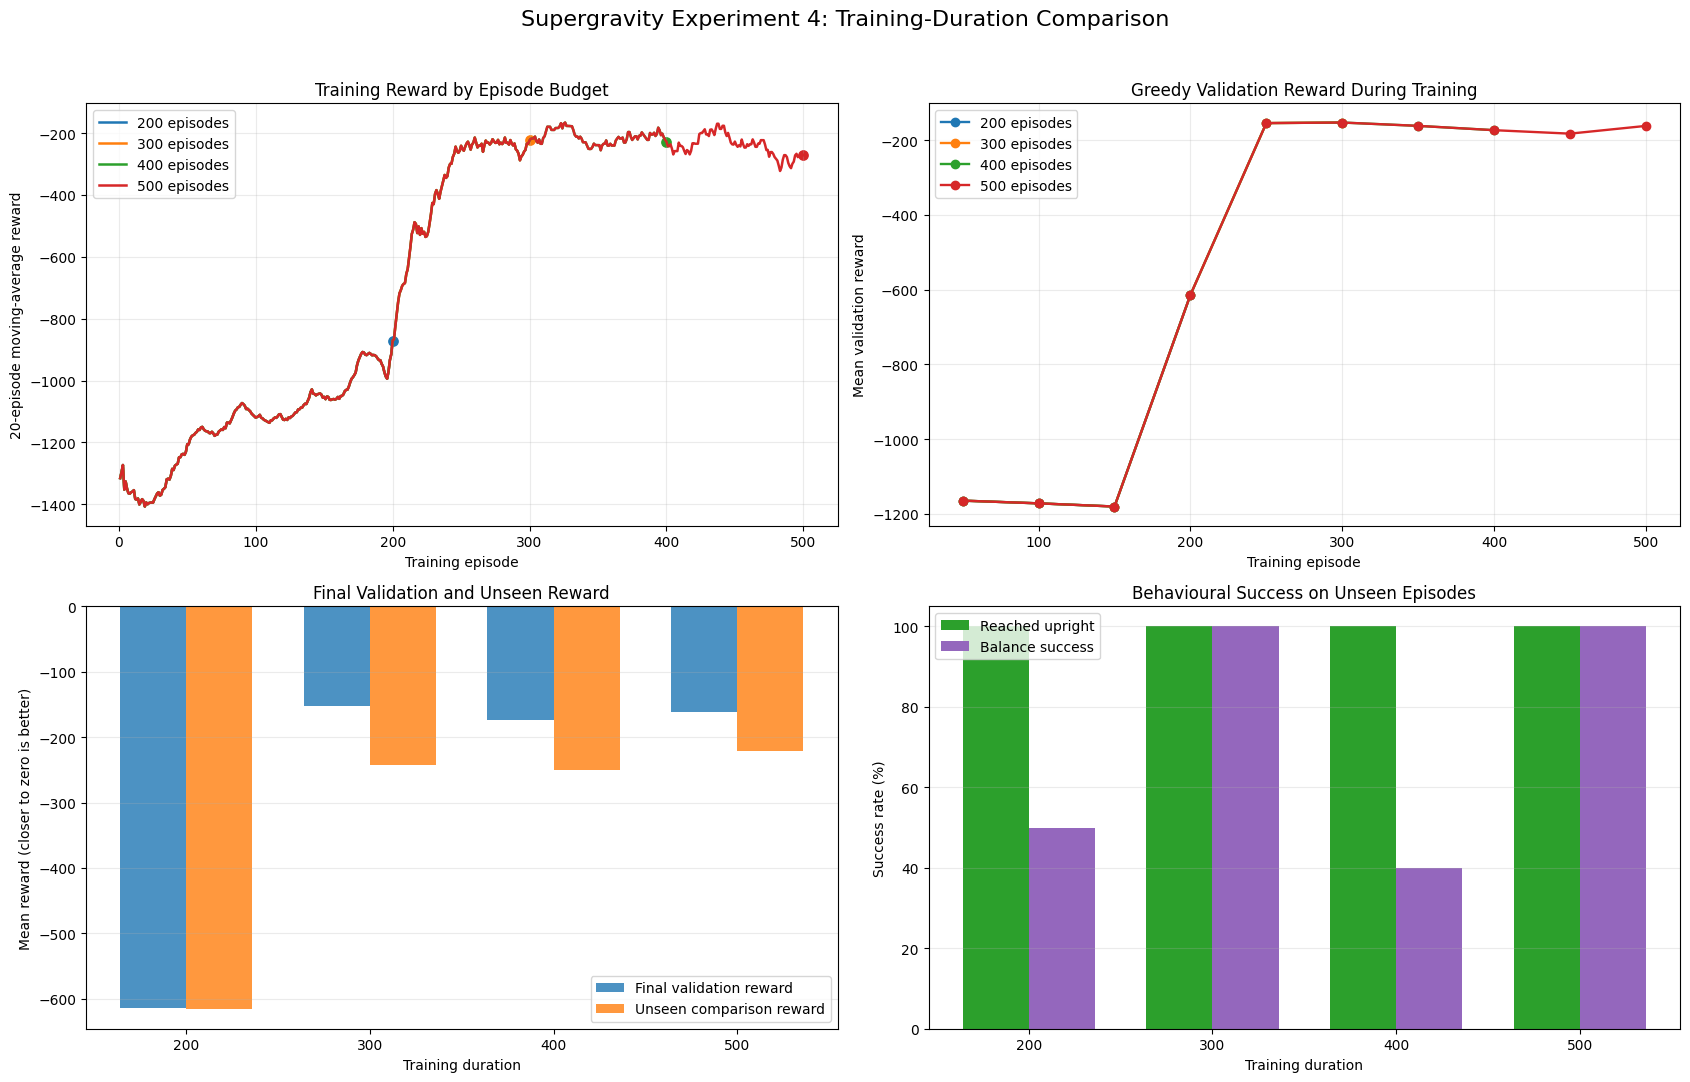

Figure saved to: figures\supergravity\super_experiment_4_training_duration.png


In [125]:
# ---------------------------------------------------------
# Supergravity training-duration visualisation
# ---------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 11),
)


# Plot 1: Training curves
for training_duration in SUPER_TRAINING_DURATIONS:
    candidate_training = (
        super_duration_training_dataframe.loc[
            super_duration_training_dataframe[
                "training_duration"
            ]
            == training_duration
        ]
        .sort_values("episode")
    )

    axes[0, 0].plot(
        candidate_training["episode"],
        candidate_training[
            "moving_average_reward"
        ],
        linewidth=1.8,
        label=f"{training_duration} episodes",
    )

    axes[0, 0].scatter(
        candidate_training[
            "episode"
        ].iloc[-1],
        candidate_training[
            "moving_average_reward"
        ].iloc[-1],
        s=45,
    )

axes[0, 0].set_title(
    "Training Reward by Episode Budget"
)

axes[0, 0].set_xlabel(
    "Training episode"
)

axes[0, 0].set_ylabel(
    "20-episode moving-average reward"
)

axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend()


# Plot 2: Validation curves during training
for training_duration in SUPER_TRAINING_DURATIONS:
    candidate_validation = (
        super_duration_validation_dataframe.loc[
            super_duration_validation_dataframe[
                "training_duration"
            ]
            == training_duration
        ]
        .sort_values("training_episode")
    )

    axes[0, 1].plot(
        candidate_validation[
            "training_episode"
        ],
        candidate_validation[
            "validation_mean_reward"
        ],
        marker="o",
        linewidth=1.7,
        label=f"{training_duration} episodes",
    )

axes[0, 1].set_title(
    "Greedy Validation Reward During Training"
)

axes[0, 1].set_xlabel(
    "Training episode"
)

axes[0, 1].set_ylabel(
    "Mean validation reward"
)

axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend()


# Plot 3: Final validation versus unseen comparison
positions = np.arange(
    len(SUPER_TRAINING_DURATIONS)
)

bar_width = 0.36

axes[1, 0].bar(
    positions - bar_width / 2,
    super_duration_results_dataframe[
        "final_validation_mean_reward"
    ],
    width=bar_width,
    label="Final validation reward",
    color="tab:blue",
    alpha=0.8,
)

axes[1, 0].bar(
    positions + bar_width / 2,
    super_duration_results_dataframe[
        "comparison_mean_reward"
    ],
    width=bar_width,
    label="Unseen comparison reward",
    color="tab:orange",
    alpha=0.8,
)

axes[1, 0].set_title(
    "Final Validation and Unseen Reward"
)

axes[1, 0].set_xlabel(
    "Training duration"
)

axes[1, 0].set_ylabel(
    "Mean reward (closer to zero is better)"
)

axes[1, 0].set_xticks(positions)

axes[1, 0].set_xticklabels(
    [
        str(training_duration)
        for training_duration
        in SUPER_TRAINING_DURATIONS
    ]
)

axes[1, 0].grid(
    axis="y",
    alpha=0.25,
)

axes[1, 0].legend()


# Plot 4: Behavioural results
upright_rates = (
    super_duration_results_dataframe[
        "reached_upright_rate"
    ].to_numpy()
    * 100
)

balance_rates = (
    super_duration_results_dataframe[
        "balance_success_rate"
    ].to_numpy()
    * 100
)

axes[1, 1].bar(
    positions - bar_width / 2,
    upright_rates,
    width=bar_width,
    label="Reached upright",
    color="tab:green",
)

axes[1, 1].bar(
    positions + bar_width / 2,
    balance_rates,
    width=bar_width,
    label="Balance success",
    color="tab:purple",
)

axes[1, 1].set_title(
    "Behavioural Success on Unseen Episodes"
)

axes[1, 1].set_xlabel(
    "Training duration"
)

axes[1, 1].set_ylabel(
    "Success rate (%)"
)

axes[1, 1].set_xticks(positions)

axes[1, 1].set_xticklabels(
    [
        str(training_duration)
        for training_duration
        in SUPER_TRAINING_DURATIONS
    ]
)

axes[1, 1].set_ylim(0, 105)

axes[1, 1].grid(
    axis="y",
    alpha=0.25,
)

axes[1, 1].legend()


plt.suptitle(
    "Supergravity Experiment 4: "
    "Training-Duration Comparison",
    fontsize=16,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

super_duration_figure_path = (
    SUPER_FIGURES_DIR
    / "super_experiment_4_training_duration.png"
)

plt.savefig(
    super_duration_figure_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure saved to:",
    super_duration_figure_path,
)

## Supergravity Experiment 4 Evaluation: Training Duration

This experiment compared training durations of **200, 300, 400 and 500 episodes** while keeping the selected **11-action space**, epsilon decay of **0.990**, learning rate of **0.001**, Standard DQN architecture, training seed and evaluation conditions constant. Early stopping was disabled, and every model completed its assigned training duration.

Each candidate was ranked using the validation performance of its **final checkpoint**. This provides a fairer duration comparison than selecting the best intermediate checkpoint, as longer runs otherwise receive more opportunities to produce a favourable validation result.

The **300-episode model** achieved the strongest final validation reward of **−152.948**. It outperformed the second-ranked 500-episode model, which obtained −161.967, by **9.019 reward points**. The 400-episode model scored −173.393, while the 200-episode model performed substantially worse at −614.438.

The poor result at 200 episodes indicates that the agent had not received enough training to learn a consistently effective policy. The learning curves show a major improvement between approximately episodes 180 and 230, explaining why terminating training at episode 200 produced weak performance. Although the 200-episode model reached upright in every unseen episode, it achieved only **50% balance success** and had extremely high reward variability of **±434.433**. Reaching upright therefore does not necessarily mean that the agent can maintain stable control.

The 300-episode model achieved **−242.910 ± 147.511** on the unseen comparison episodes. It reached upright and satisfied the balance-success criterion in **100% of episodes**, remained upright for an average of **159.60 out of 200 steps**, and produced a mean longest balance streak of **154.13 steps**. These behavioural results show that 300 episodes were sufficient to learn a successful supergravity controller.

The unseen comparison did not produce the same winner as final validation. The 500-episode model achieved the strongest unseen reward of **−221.609 ± 113.415**, exceeding the 300-episode model by **21.301 reward points**. It also had lower reward variability and remained upright for slightly longer on average. However, these unseen episodes were reserved for independent comparison and were not used for model selection. Therefore, they should not replace the predefined validation-based decision.

Performance did not improve consistently after 300 episodes. Validation reward declined at 400 episodes and recovered at 500 episodes without exceeding the 300-episode result. This suggests that further training caused fluctuations in the learned Q-values rather than a steady improvement in policy quality. The training and validation curves similarly show that the policy reached strong performance by approximately 250–300 episodes and subsequently oscillated.

Therefore, **300 training episodes are formally selected** because they produced the strongest final validation performance while also achieving complete upright and balance success on the unseen episodes. This duration is also more computationally efficient than training for 400 or 500 episodes.

Nevertheless, the disagreement between the validation winner and the comparison-set winner means that the difference between 300 and 500 episodes should not be treated as conclusive. A duration of 300 episodes is carried forward because it achieved the strongest final-validation result and required less computation than the 500-episode model.

In [126]:
# ---------------------------------------------------------
# Supergravity Experiment 5:
# Standard DQN versus Double DQN
# ---------------------------------------------------------

SUPER_SELECTED_ACTION_COUNT = 11
SUPER_SELECTED_EPSILON_DECAY = 0.990
SUPER_SELECTED_LEARNING_RATE = 0.001
SUPER_SELECTED_TRAINING_DURATION = 300

SUPER_ALGORITHM_ACTION_VALUES = np.linspace(
    -2.0,
    2.0,
    SUPER_SELECTED_ACTION_COUNT,
    dtype=np.float32,
)

# Same training seed as Experiment 4.
SUPER_ALGORITHM_TRAINING_SEED = 126

# Used only to monitor training curves.
SUPER_ALGORITHM_MONITORING_SEED = 1_600_004

# New validation episodes used for algorithm selection.
SUPER_ALGORITHM_SELECTION_SEED = 1_600_005

# New unseen episodes used only for final comparison.
SUPER_ALGORITHM_COMPARISON_SEED = 2_600_005

SUPER_ALGORITHM_MAX_STEPS = 200
SUPER_ALGORITHM_EVALUATION_EVERY = 50

SUPER_ALGORITHM_MONITORING_EPISODES = 20
SUPER_ALGORITHM_SELECTION_EPISODES = 30
SUPER_ALGORITHM_COMPARISON_EPISODES = 30

# Early stopping remains disabled.
SUPER_ALGORITHM_MINIMUM_EPISODES = 150
SUPER_ALGORITHM_EARLY_STOPPING_PATIENCE = 999
SUPER_ALGORITHM_EARLY_STOPPING_MIN_DELTA = 0.0


SUPER_ALGORITHM_RESULTS_DIR = (
    SUPER_RESULTS_DIR
    / "experiment_5_dqn_algorithm"
)

SUPER_ALGORITHM_WEIGHTS_DIR = (
    SUPER_WEIGHTS_DIR
    / "experiment_5_dqn_algorithm"
)

for directory in [
    SUPER_ALGORITHM_RESULTS_DIR,
    SUPER_ALGORITHM_WEIGHTS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ---------------------------------------------------------
# Reuse Standard DQN from Experiment 4
# ---------------------------------------------------------

SUPER_STANDARD_SOURCE_PATHS = (
    SUPER_DURATION_PATHS[
        SUPER_SELECTED_TRAINING_DURATION
    ]
)

SUPER_STANDARD_WEIGHTS_PATH = (
    SUPER_STANDARD_SOURCE_PATHS["weights"]
)

SUPER_STANDARD_TRAINING_PATH = (
    SUPER_STANDARD_SOURCE_PATHS["training"]
)

SUPER_STANDARD_VALIDATION_PATH = (
    SUPER_STANDARD_SOURCE_PATHS["validation"]
)

for required_path in [
    SUPER_STANDARD_WEIGHTS_PATH,
    SUPER_STANDARD_TRAINING_PATH,
    SUPER_STANDARD_VALIDATION_PATH,
]:
    if not required_path.exists():
        raise FileNotFoundError(
            "The reusable Standard DQN result is "
            f"missing: {required_path}"
        )


# ---------------------------------------------------------
# New Double DQN output paths
# ---------------------------------------------------------

SUPER_DOUBLE_PATHS = {
    "weights": (
        SUPER_ALGORITHM_WEIGHTS_DIR
        / "double_dqn_final.weights.h5"
    ),

    "best_weights": (
        SUPER_ALGORITHM_WEIGHTS_DIR
        / "double_dqn_best_monitoring.weights.h5"
    ),

    "training": (
        SUPER_ALGORITHM_RESULTS_DIR
        / "double_dqn_training.csv"
    ),

    "validation": (
        SUPER_ALGORITHM_RESULTS_DIR
        / "double_dqn_monitoring_validation.csv"
    ),

    "checkpoint": (
        SUPER_ALGORITHM_RESULTS_DIR
        / "double_dqn_checkpoint.csv"
    ),
}


def make_super_algorithm_config():
    """Return the fixed Experiment 5 configuration."""

    return make_super_duration_config()


probe_env = create_pendulum_env(
    gravity=SUPER_GRAVITY_VALUE,
    seed=SUPER_ALGORITHM_TRAINING_SEED,
)

SUPER_ALGORITHM_STATE_SIZE = int(
    probe_env.observation_space.shape[0]
)

print("Gravity:", probe_env.unwrapped.g)
print("Action count:", SUPER_SELECTED_ACTION_COUNT)
print("Epsilon decay:", SUPER_SELECTED_EPSILON_DECAY)
print("Learning rate:", SUPER_SELECTED_LEARNING_RATE)
print(
    "Training duration:",
    SUPER_SELECTED_TRAINING_DURATION,
)
print(
    "Standard DQN checkpoint reused:",
    SUPER_STANDARD_WEIGHTS_PATH,
)
print("Only Double DQN will be newly trained.")

probe_env.close()

Gravity: 15.0
Action count: 11
Epsilon decay: 0.99
Learning rate: 0.001
Training duration: 300
Standard DQN checkpoint reused: weights\supergravity\experiment_4_training_duration\standard_dqn_0300_episodes_final.weights.h5
Only Double DQN will be newly trained.


In [127]:
# ---------------------------------------------------------
# Train Double DQN
# Standard DQN is NOT retrained
# ---------------------------------------------------------

required_double_paths = [
    SUPER_DOUBLE_PATHS["weights"],
    SUPER_DOUBLE_PATHS["best_weights"],
    SUPER_DOUBLE_PATHS["training"],
    SUPER_DOUBLE_PATHS["validation"],
    SUPER_DOUBLE_PATHS["checkpoint"],
]

if all(
    path.exists()
    for path in required_double_paths
):
    print(
        "Complete Double DQN results already exist. "
        "Training skipped."
    )

else:
    print("=" * 72)
    print(
        "SUPERGRAVITY EXPERIMENT 5 | "
        "TRAINING DOUBLE DQN"
    )
    print("=" * 72)

    tf.keras.backend.clear_session()

    set_global_seed(
        SUPER_ALGORITHM_TRAINING_SEED
    )

    training_env = None
    monitoring_env = None
    double_agent = None

    try:
        current_config = (
            make_super_algorithm_config()
        )

        training_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_ALGORITHM_TRAINING_SEED,
        )

        monitoring_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_ALGORITHM_MONITORING_SEED,
        )

        double_agent = DQNAgent(
            state_size=SUPER_ALGORITHM_STATE_SIZE,
            action_values=(
                SUPER_ALGORITHM_ACTION_VALUES
            ),
            config=current_config,

            # Only algorithmic difference.
            use_double_dqn=True,
        )

        (
            double_history,
            double_training_dataframe,
        ) = train_agent(
            env=training_env,
            agent=double_agent,
            episodes=(
                SUPER_SELECTED_TRAINING_DURATION
            ),
            max_steps=SUPER_ALGORITHM_MAX_STEPS,
            moving_average_window=20,
            seed=SUPER_ALGORITHM_TRAINING_SEED,

            evaluation_env=monitoring_env,
            evaluation_every=(
                SUPER_ALGORITHM_EVALUATION_EVERY
            ),
            evaluation_episodes=(
                SUPER_ALGORITHM_MONITORING_EPISODES
            ),
            evaluation_seed=(
                SUPER_ALGORITHM_MONITORING_SEED
            ),

            # Diagnostic checkpoint only.
            best_weights_path=(
                SUPER_DOUBLE_PATHS["best_weights"]
            ),

            print_every=25,
            render_every=None,

            early_stopping_minimum_episodes=(
                SUPER_ALGORITHM_MINIMUM_EPISODES
            ),
            early_stopping_patience=(
                SUPER_ALGORITHM_EARLY_STOPPING_PATIENCE
            ),
            early_stopping_min_delta=(
                SUPER_ALGORITHM_EARLY_STOPPING_MIN_DELTA
            ),
        )

        double_training_dataframe.insert(
            0,
            "algorithm",
            "Double DQN",
        )

        double_training_dataframe.to_csv(
            SUPER_DOUBLE_PATHS["training"],
            index=False,
        )

        double_validation_dataframe = pd.DataFrame({
            "algorithm": "Double DQN",

            "training_episode": (
                double_history[
                    "evaluation_episode"
                ]
            ),

            "validation_mean_reward": (
                double_history[
                    "evaluation_mean_reward"
                ]
            ),

            "validation_reward_std": (
                double_history[
                    "evaluation_reward_std"
                ]
            ),

            "validation_improved": (
                double_history[
                    "evaluation_improved"
                ]
            ),

            "validations_without_improvement": (
                double_history[
                    "validations_without_improvement"
                ]
            ),
        })

        double_validation_dataframe.to_csv(
            SUPER_DOUBLE_PATHS["validation"],
            index=False,
        )

        # Save the actual final Double DQN model.
        double_agent.online_network.save_weights(
            SUPER_DOUBLE_PATHS["weights"]
        )

        previous_epsilon = double_agent.epsilon
        double_agent.epsilon = 0.0

        final_monitoring_result = evaluate_agent(
            env=monitoring_env,
            agent=double_agent,
            episodes=(
                SUPER_ALGORITHM_MONITORING_EPISODES
            ),
            max_steps=SUPER_ALGORITHM_MAX_STEPS,
            seed=SUPER_ALGORITHM_MONITORING_SEED,
            best_score=None,
            save_path=None,
            verbose=False,
        )

        double_agent.epsilon = previous_epsilon

        validation_means = np.asarray(
            double_history[
                "evaluation_mean_reward"
            ],
            dtype=float,
        )

        best_position = int(
            np.argmax(validation_means)
        )

        double_checkpoint_dataframe = pd.DataFrame([
            {
                "algorithm": "Double DQN",

                "action_count": (
                    SUPER_SELECTED_ACTION_COUNT
                ),

                "epsilon_decay": (
                    SUPER_SELECTED_EPSILON_DECAY
                ),

                "learning_rate": (
                    SUPER_SELECTED_LEARNING_RATE
                ),

                "training_duration": (
                    SUPER_SELECTED_TRAINING_DURATION
                ),

                "training_seed": (
                    SUPER_ALGORITHM_TRAINING_SEED
                ),

                "trained_episodes": int(
                    double_history["stop_episode"]
                ),

                "stopped_early": bool(
                    double_history["stopped_early"]
                ),

                "final_monitoring_mean_reward": float(
                    final_monitoring_result[
                        "mean_reward"
                    ]
                ),

                "final_monitoring_reward_std": float(
                    final_monitoring_result[
                        "reward_std"
                    ]
                ),

                "best_monitoring_episode": int(
                    double_history[
                        "evaluation_episode"
                    ][best_position]
                ),

                "best_monitoring_mean_reward": float(
                    validation_means[
                        best_position
                    ]
                ),

                "parameter_count": int(
                    double_agent
                    .online_network
                    .count_params()
                ),
            }
        ])

        double_checkpoint_dataframe.to_csv(
            SUPER_DOUBLE_PATHS["checkpoint"],
            index=False,
        )

        print(
            "Double DQN completed | "
            f"final monitoring reward: "
            f"{final_monitoring_result['mean_reward']:.3f} "
            f"± "
            f"{final_monitoring_result['reward_std']:.3f}"
        )

    finally:
        if training_env is not None:
            training_env.close()

        if monitoring_env is not None:
            monitoring_env.close()

        double_agent = None

        tf.keras.backend.clear_session()
        gc.collect()

SUPERGRAVITY EXPERIMENT 5 | TRAINING DOUBLE DQN
Episode    1/300 | Reward: -1315.40 | Moving average: -1315.40 | Epsilon: 0.9900 | Loss: not training yet | Replay size: 200
Episode   25/300 | Reward: -1228.68 | Moving average: -1399.88 | Epsilon: 0.7778 | Loss: 1.0478 | Replay size: 5000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_5_dqn_algorithm\double_dqn_best_monitoring.weights.h5
Evaluation at episode 50: mean reward = -1158.81, std = 26.54, wait = 0/999
New best weights saved.
Episode   50/300 | Reward: -1064.51 | Moving average: -1191.87 | Epsilon: 0.6050 | Loss: 1.9421 | Replay size: 10000
Episode   75/300 | Reward: -1047.64 | Moving average: -1132.55 | Epsilon: 0.4706 | Loss: 3.6116 | Replay size: 15000
Evaluation at episode 100: mean reward = -1178.05, std = 32.98, wait = 1/999
Episode  100/300 | Reward: -1222.46 | Moving average: -1092.38 | Epsilon: 0.3660 | Loss: 5.4478 | Replay size: 20000
Episode  125/300 | Reward: -1068.51 | Moving av

In [130]:
# ---------------------------------------------------------
# Load training histories
# ---------------------------------------------------------

standard_training_dataframe = pd.read_csv(
    SUPER_STANDARD_TRAINING_PATH
)

standard_training_dataframe[
    "algorithm"
] = "Standard DQN"

double_training_dataframe = pd.read_csv(
    SUPER_DOUBLE_PATHS["training"]
)

double_training_dataframe[
    "algorithm"
] = "Double DQN"


standard_validation_dataframe = pd.read_csv(
    SUPER_STANDARD_VALIDATION_PATH
)

standard_validation_dataframe[
    "algorithm"
] = "Standard DQN"

double_validation_dataframe = pd.read_csv(
    SUPER_DOUBLE_PATHS["validation"]
)

double_validation_dataframe[
    "algorithm"
] = "Double DQN"


super_algorithm_training_dataframe = pd.concat(
    [
        standard_training_dataframe,
        double_training_dataframe,
    ],
    ignore_index=True,
)

super_algorithm_validation_dataframe = pd.concat(
    [
        standard_validation_dataframe,
        double_validation_dataframe,
    ],
    ignore_index=True,
)


# ---------------------------------------------------------
# Model definitions
# ---------------------------------------------------------

SUPER_ALGORITHM_MODELS = {
    "Standard DQN": {
        "use_double_dqn": False,
        "weights": SUPER_STANDARD_WEIGHTS_PATH,
    },

    "Double DQN": {
        "use_double_dqn": True,
        "weights": SUPER_DOUBLE_PATHS["weights"],
    },
}


# ---------------------------------------------------------
# Evaluate both algorithms
# ---------------------------------------------------------

super_algorithm_result_records = []
super_algorithm_episode_frames = []

for algorithm_name, model_details in (
    SUPER_ALGORITHM_MODELS.items()
):
    print("\n" + "=" * 72)
    print("EVALUATING:", algorithm_name)
    print("=" * 72)

    tf.keras.backend.clear_session()

    set_global_seed(
        SUPER_ALGORITHM_TRAINING_SEED
    )

    validation_env = None
    comparison_env = None
    evaluation_agent = None

    try:
        current_config = (
            make_super_algorithm_config()
        )

        validation_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_ALGORITHM_SELECTION_SEED,
        )

        comparison_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=SUPER_ALGORITHM_COMPARISON_SEED,
        )

        evaluation_agent = DQNAgent(
            state_size=SUPER_ALGORITHM_STATE_SIZE,
            action_values=(
                SUPER_ALGORITHM_ACTION_VALUES
            ),
            config=current_config,
            use_double_dqn=(
                model_details[
                    "use_double_dqn"
                ]
            ),
        )

        evaluation_agent.load_weights(
            model_details["weights"]
        )

        # Greedy evaluation: no exploration.
        evaluation_agent.epsilon = 0.0

        selection_validation_result = evaluate_agent(
            env=validation_env,
            agent=evaluation_agent,
            episodes=(
                SUPER_ALGORITHM_SELECTION_EPISODES
            ),
            max_steps=SUPER_ALGORITHM_MAX_STEPS,
            seed=SUPER_ALGORITHM_SELECTION_SEED,
            best_score=None,
            save_path=None,
            verbose=False,
        )

        comparison_result = evaluate_agent(
            env=comparison_env,
            agent=evaluation_agent,
            episodes=(
                SUPER_ALGORITHM_COMPARISON_EPISODES
            ),
            max_steps=SUPER_ALGORITHM_MAX_STEPS,
            seed=SUPER_ALGORITHM_COMPARISON_SEED,
            best_score=None,
            save_path=None,
            verbose=False,
        )

        candidate_training = (
            super_algorithm_training_dataframe.loc[
                super_algorithm_training_dataframe[
                    "algorithm"
                ]
                == algorithm_name
            ]
            .sort_values("episode")
        )

        last_50_rewards = (
            candidate_training[
                "episode_reward"
            ]
            .tail(50)
            .astype(float)
        )

        candidate_monitoring = (
            super_algorithm_validation_dataframe.loc[
                super_algorithm_validation_dataframe[
                    "algorithm"
                ]
                == algorithm_name
            ]
            .sort_values("training_episode")
        )

        best_monitoring_position = (
            candidate_monitoring[
                "validation_mean_reward"
            ].idxmax()
        )

        best_monitoring_episode = int(
            candidate_monitoring.loc[
                best_monitoring_position,
                "training_episode",
            ]
        )

        best_monitoring_reward = float(
            candidate_monitoring.loc[
                best_monitoring_position,
                "validation_mean_reward",
            ]
        )

        super_algorithm_result_records.append({
            "algorithm": algorithm_name,

            "use_double_dqn": (
                model_details[
                    "use_double_dqn"
                ]
            ),

            "action_count": (
                SUPER_SELECTED_ACTION_COUNT
            ),

            "epsilon_decay": (
                SUPER_SELECTED_EPSILON_DECAY
            ),

            "learning_rate": (
                SUPER_SELECTED_LEARNING_RATE
            ),

            "training_duration": (
                SUPER_SELECTED_TRAINING_DURATION
            ),

            "parameter_count": int(
                evaluation_agent
                .online_network
                .count_params()
            ),

            "best_monitoring_episode": (
                best_monitoring_episode
            ),

            "best_monitoring_mean_reward": (
                best_monitoring_reward
            ),

            "last_50_training_mean_reward": float(
                last_50_rewards.mean()
            ),

            "last_50_training_reward_std": float(
                last_50_rewards.std(ddof=0)
            ),

            "selection_validation_mean_reward": float(
                selection_validation_result[
                    "mean_reward"
                ]
            ),

            "selection_validation_reward_std": float(
                selection_validation_result[
                    "reward_std"
                ]
            ),

            "comparison_mean_reward": float(
                comparison_result[
                    "mean_reward"
                ]
            ),

            "comparison_reward_std": float(
                comparison_result[
                    "reward_std"
                ]
            ),

            "comparison_minimum_reward": float(
                comparison_result[
                    "minimum_reward"
                ]
            ),

            "comparison_maximum_reward": float(
                comparison_result[
                    "maximum_reward"
                ]
            ),

            "reached_upright_rate": float(
                comparison_result[
                    "reached_upright_rate"
                ]
            ),

            "balance_success_rate": float(
                comparison_result[
                    "balance_success_rate"
                ]
            ),

            "mean_upright_steps": float(
                comparison_result[
                    "mean_upright_steps"
                ]
            ),

            "mean_longest_balance_streak": float(
                comparison_result[
                    "mean_longest_balance_streak"
                ]
            ),
        })

        for evaluation_split, result in [
            (
                "selection_validation",
                selection_validation_result,
            ),
            (
                "unseen_comparison",
                comparison_result,
            ),
        ]:
            episode_dataframe = pd.DataFrame(
                result["episode_metrics"]
            )

            episode_dataframe.insert(
                0,
                "evaluation_split",
                evaluation_split,
            )

            episode_dataframe.insert(
                0,
                "algorithm",
                algorithm_name,
            )

            super_algorithm_episode_frames.append(
                episode_dataframe
            )

        print(
            f"{algorithm_name} | "
            f"selection validation: "
            f"{selection_validation_result['mean_reward']:.3f} "
            f"± "
            f"{selection_validation_result['reward_std']:.3f} | "
            f"unseen comparison: "
            f"{comparison_result['mean_reward']:.3f} "
            f"± "
            f"{comparison_result['reward_std']:.3f}"
        )

    finally:
        if validation_env is not None:
            validation_env.close()

        if comparison_env is not None:
            comparison_env.close()

        evaluation_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


super_algorithm_results_dataframe = (
    pd.DataFrame(
        super_algorithm_result_records
    )
)

super_algorithm_episode_dataframe = pd.concat(
    super_algorithm_episode_frames,
    ignore_index=True,
)

super_algorithm_results_dataframe.to_csv(
    SUPER_ALGORITHM_RESULTS_DIR
    / "super_dqn_algorithm_summary.csv",
    index=False,
)

super_algorithm_episode_dataframe.to_csv(
    SUPER_ALGORITHM_RESULTS_DIR
    / "super_dqn_algorithm_evaluation_episodes.csv",
    index=False,
)

display(
    super_algorithm_results_dataframe.round(3)
)


EVALUATING: Standard DQN
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_4_training_duration\standard_dqn_0300_episodes_final.weights.h5
Standard DQN | selection validation: -179.583 ± 135.651 | unseen comparison: -233.958 ± 146.399

EVALUATING: Double DQN
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_5_dqn_algorithm\double_dqn_final.weights.h5
Double DQN | selection validation: -166.838 ± 112.086 | unseen comparison: -200.789 ± 97.170


,algorithm,use_double_dqn,action_count,epsilon_decay,learning_rate,training_duration,parameter_count,best_monitoring_episode,best_monitoring_mean_reward,last_50_training_mean_reward,...,selection_validation_mean_reward,selection_validation_reward_std,comparison_mean_reward,comparison_reward_std,comparison_minimum_reward,comparison_maximum_reward,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,Standard DQN,False,11,0.99,0.001,300,5131,300,-152.948,-233.532,...,-179.583,135.651,-233.958,146.399,-560.885,-0.139,1.0,1.0,160.800,155.400
1,Double DQN,True,11,0.99,0.001,300,5131,300,-154.498,-218.169,...,-166.838,112.086,-200.789,97.170,-418.122,-1.349,1.0,1.0,166.233,162.567


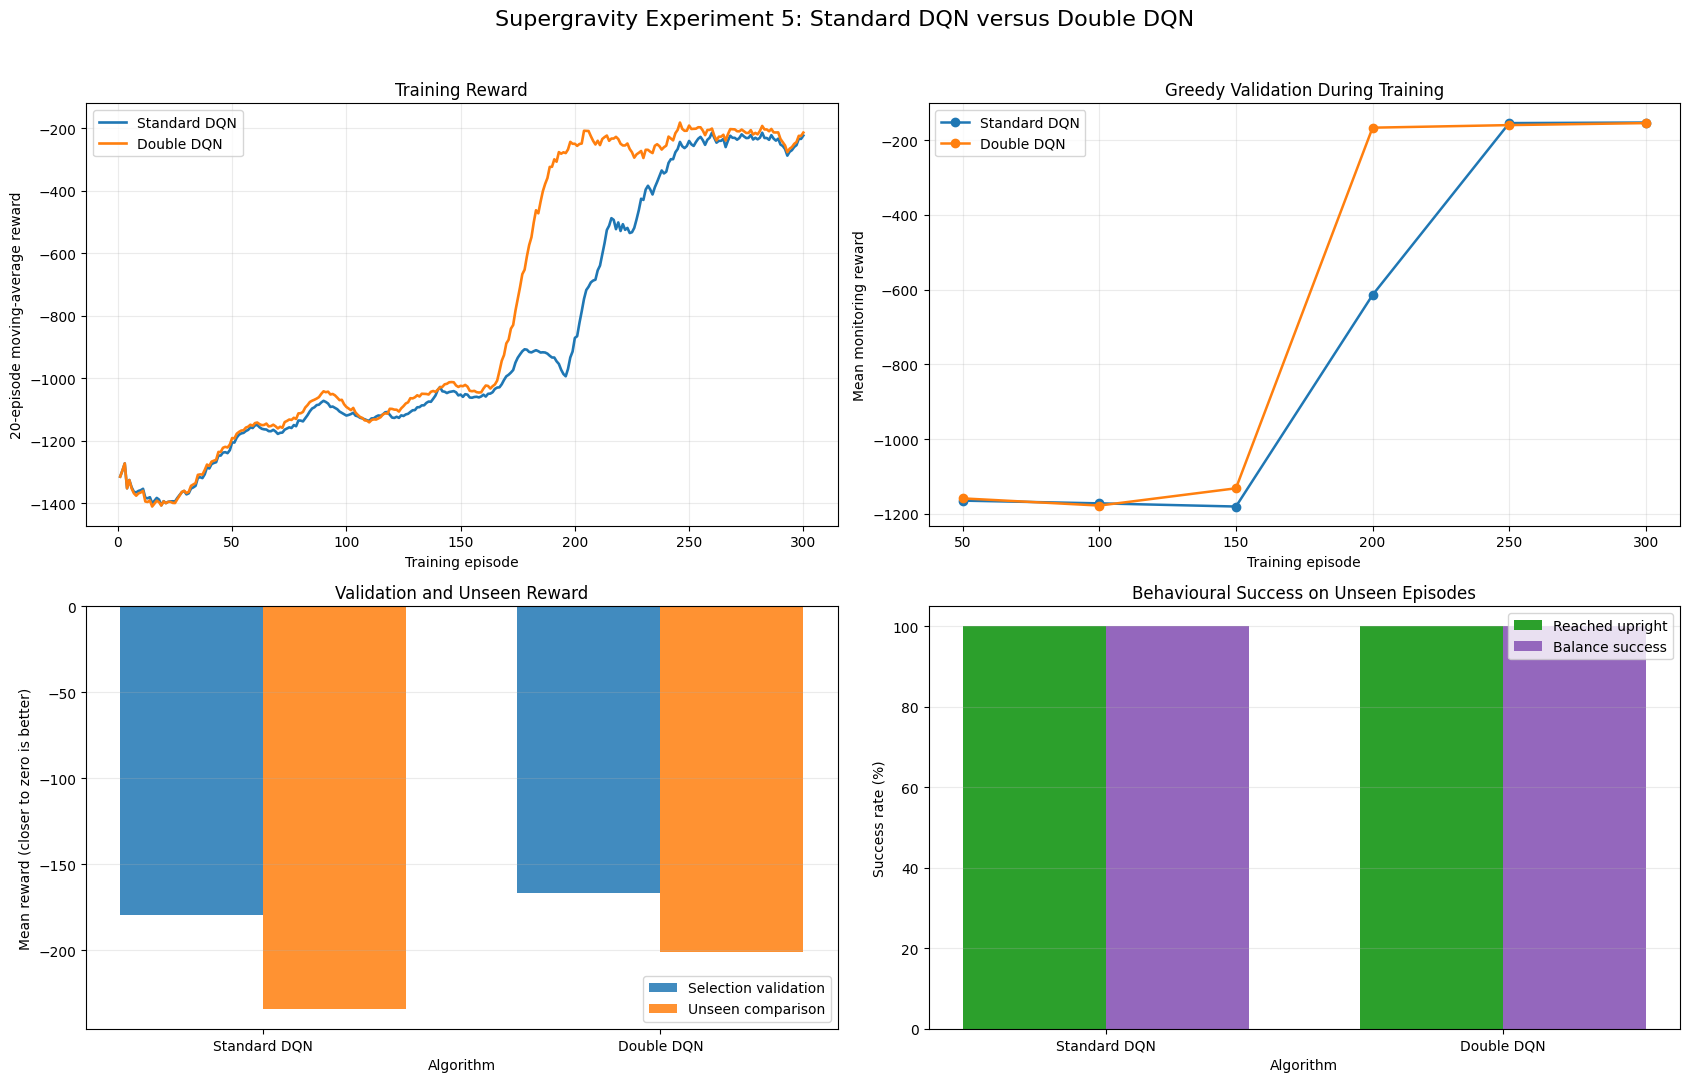

Figure saved to: figures\supergravity\super_experiment_5_dqn_algorithm.png


In [131]:
# ---------------------------------------------------------
# Standard DQN versus Double DQN visualisation
# ---------------------------------------------------------

algorithm_order = [
    "Standard DQN",
    "Double DQN",
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(17, 11),
)


# Plot 1: Training curves
for algorithm_name in algorithm_order:
    candidate_training = (
        super_algorithm_training_dataframe.loc[
            super_algorithm_training_dataframe[
                "algorithm"
            ]
            == algorithm_name
        ]
        .sort_values("episode")
    )

    axes[0, 0].plot(
        candidate_training["episode"],
        candidate_training[
            "moving_average_reward"
        ],
        linewidth=1.9,
        label=algorithm_name,
    )

axes[0, 0].set_title(
    "Training Reward"
)
axes[0, 0].set_xlabel(
    "Training episode"
)
axes[0, 0].set_ylabel(
    "20-episode moving-average reward"
)
axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend()


# Plot 2: Monitoring validation curves
for algorithm_name in algorithm_order:
    candidate_validation = (
        super_algorithm_validation_dataframe.loc[
            super_algorithm_validation_dataframe[
                "algorithm"
            ]
            == algorithm_name
        ]
        .sort_values("training_episode")
    )

    axes[0, 1].plot(
        candidate_validation[
            "training_episode"
        ],
        candidate_validation[
            "validation_mean_reward"
        ],
        marker="o",
        linewidth=1.8,
        label=algorithm_name,
    )

axes[0, 1].set_title(
    "Greedy Validation During Training"
)
axes[0, 1].set_xlabel(
    "Training episode"
)
axes[0, 1].set_ylabel(
    "Mean monitoring reward"
)
axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend()


# Ensure consistent row order
plot_results = (
    super_algorithm_results_dataframe
    .set_index("algorithm")
    .loc[algorithm_order]
    .reset_index()
)

positions = np.arange(
    len(algorithm_order)
)

bar_width = 0.36


# Plot 3: Selection validation and unseen comparison
axes[1, 0].bar(
    positions - bar_width / 2,
    plot_results[
        "selection_validation_mean_reward"
    ],
    width=bar_width,
    label="Selection validation",
    color="tab:blue",
    alpha=0.85,
)

axes[1, 0].bar(
    positions + bar_width / 2,
    plot_results[
        "comparison_mean_reward"
    ],
    width=bar_width,
    label="Unseen comparison",
    color="tab:orange",
    alpha=0.85,
)

axes[1, 0].set_title(
    "Validation and Unseen Reward"
)
axes[1, 0].set_xlabel(
    "Algorithm"
)
axes[1, 0].set_ylabel(
    "Mean reward (closer to zero is better)"
)
axes[1, 0].set_xticks(positions)
axes[1, 0].set_xticklabels(
    algorithm_order
)
axes[1, 0].grid(
    axis="y",
    alpha=0.25,
)
axes[1, 0].legend()


# Plot 4: Behavioural comparison
upright_rates = (
    plot_results[
        "reached_upright_rate"
    ].to_numpy()
    * 100
)

balance_rates = (
    plot_results[
        "balance_success_rate"
    ].to_numpy()
    * 100
)

axes[1, 1].bar(
    positions - bar_width / 2,
    upright_rates,
    width=bar_width,
    label="Reached upright",
    color="tab:green",
)

axes[1, 1].bar(
    positions + bar_width / 2,
    balance_rates,
    width=bar_width,
    label="Balance success",
    color="tab:purple",
)

axes[1, 1].set_title(
    "Behavioural Success on Unseen Episodes"
)
axes[1, 1].set_xlabel(
    "Algorithm"
)
axes[1, 1].set_ylabel(
    "Success rate (%)"
)
axes[1, 1].set_xticks(positions)
axes[1, 1].set_xticklabels(
    algorithm_order
)
axes[1, 1].set_ylim(0, 105)
axes[1, 1].grid(
    axis="y",
    alpha=0.25,
)
axes[1, 1].legend()


plt.suptitle(
    "Supergravity Experiment 5: "
    "Standard DQN versus Double DQN",
    fontsize=16,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

super_algorithm_figure_path = (
    SUPER_FIGURES_DIR
    / "super_experiment_5_dqn_algorithm.png"
)

plt.savefig(
    super_algorithm_figure_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure saved to:",
    super_algorithm_figure_path,
)

## Experiment 5 result

Select **Double DQN**. It achieved the better selection-validation reward and also performed better on unseen episodes.

| Metric                 |       Standard DQN |             Double DQN |
| ---------------------- | -----------------: | ---------------------: |
| Selection validation   | −179.583 ± 135.651 | **−166.838 ± 112.086** |
| Unseen comparison      | −233.958 ± 146.399 |  **−200.789 ± 97.170** |
| Minimum unseen reward  |           −560.885 |           **−418.122** |
| Reached upright        |               100% |                   100% |
| Balance success        |               100% |                   100% |
| Mean upright steps     |            160.800 |            **166.233** |
| Longest balance streak |            155.400 |            **162.567** |

## Supergravity Experiment 5 Evaluation: Standard DQN versus Double DQN

This experiment compared Standard DQN and Double DQN while keeping the 11-action space, epsilon decay of 0.990, learning rate of 0.001, network architecture, 300-episode training duration, training seed and evaluation conditions constant. The existing Standard DQN checkpoint was reused, while only Double DQN was newly trained.

**Double DQN was selected** because it achieved the stronger independent selection-validation reward of **−166.838 ± 112.086**, compared with **−179.583 ± 135.651** for Standard DQN. This represents an improvement of **12.745 reward points**. Because rewards closer to zero are better, Double DQN ranks first under the predefined selection criterion.

The unseen comparison supported the same decision. Double DQN achieved **−200.789 ± 97.170**, outperforming Standard DQN’s **−233.958 ± 146.399** by **33.169 reward points**. Double DQN also produced lower reward variability and a less severe minimum reward of −418.122 compared with −560.885. This suggests that its policy was more consistent and less vulnerable to particularly poor episodes.

Both algorithms reached upright and satisfied the balance-success criterion in **100% of unseen episodes**. However, Double DQN demonstrated slightly stronger control quality. It remained upright for an average of **166.233 out of 200 steps**, compared with 160.800 for Standard DQN, and achieved a longer mean continuous balance streak of **162.567 steps**, compared with 155.400.

The training curves also show that Double DQN improved earlier. Its major increase in reward began at approximately episode 170, whereas Standard DQN’s strongest improvement occurred later. Both models eventually converged to similar training rewards near −200. Standard DQN obtained a slightly stronger best monitoring reward during training, at −152.948 compared with −154.498, but this monitoring result was not the formal selection criterion.

Double DQN separates next-action selection, performed by the online network, from action evaluation, performed by the target network. The observed improvement is consistent with this modification reducing harmful Q-value overestimation, although this cannot be established conclusively from one training seed.

Therefore, Double DQN is carried forward into the network-architecture experiment. Since the comparison used one controlled training seed, the observed advantage should be treated as the best result under the current experiment conditions rather than proof that Double DQN will outperform Standard DQN under every training initialisation.

In [133]:
# ---------------------------------------------------------
# Supergravity Experiment 6:
# Double DQN network architecture comparison
# ---------------------------------------------------------


SUPER_ARCHITECTURE_TRAINING_SEED = (
    SUPER_ALGORITHM_TRAINING_SEED
)

# Use the same monitoring episodes as the reused
# (64, 64) Double DQN control.
SUPER_ARCHITECTURE_MONITORING_SEED = (
    SUPER_ALGORITHM_MONITORING_SEED
)

# New episodes used for architecture selection.
SUPER_ARCHITECTURE_SELECTION_SEED = 1_600_006

# New unseen episodes used only for reporting.
SUPER_ARCHITECTURE_COMPARISON_SEED = 2_600_006

SUPER_ARCHITECTURE_MAX_STEPS = 200
SUPER_ARCHITECTURE_EVALUATION_EVERY = 50

SUPER_ARCHITECTURE_MONITORING_EPISODES = 20
SUPER_ARCHITECTURE_SELECTION_EPISODES = 30
SUPER_ARCHITECTURE_COMPARISON_EPISODES = 30

# Early stopping remains disabled.
SUPER_ARCHITECTURE_MINIMUM_EPISODES = 150
SUPER_ARCHITECTURE_EARLY_STOPPING_PATIENCE = 999
SUPER_ARCHITECTURE_EARLY_STOPPING_MIN_DELTA = 0.0


SUPER_ARCHITECTURE_RESULTS_DIR = (
    SUPER_RESULTS_DIR
    / "experiment_6_network_architecture"
)

SUPER_ARCHITECTURE_WEIGHTS_DIR = (
    SUPER_WEIGHTS_DIR
    / "experiment_6_network_architecture"
)

for directory in [
    SUPER_ARCHITECTURE_RESULTS_DIR,
    SUPER_ARCHITECTURE_WEIGHTS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ---------------------------------------------------------
# Architecture candidates
# ---------------------------------------------------------

SUPER_ARCHITECTURES = {
    "64_64": {
        "label": "(64, 64)",
        "hidden_layers": (64, 64),
        "reuse_existing": True,
    },

    "128_64": {
        "label": "(128, 64)",
        "hidden_layers": (128, 64),
        "reuse_existing": False,
    },

    "128_128": {
        "label": "(128, 128)",
        "hidden_layers": (128, 128),
        "reuse_existing": False,
    },

    "128_128_64": {
        "label": "(128, 128, 64)",
        "hidden_layers": (128, 128, 64),
        "reuse_existing": False,
    },
}


# ---------------------------------------------------------
# Assign saved-result paths
# ---------------------------------------------------------

for architecture_key, details in (
    SUPER_ARCHITECTURES.items()
):
    if details["reuse_existing"]:
        details["paths"] = {
            "weights": (
                SUPER_DOUBLE_PATHS["weights"]
            ),

            "best_weights": (
                SUPER_DOUBLE_PATHS["best_weights"]
            ),

            "training": (
                SUPER_DOUBLE_PATHS["training"]
            ),

            "validation": (
                SUPER_DOUBLE_PATHS["validation"]
            ),

            "checkpoint": (
                SUPER_DOUBLE_PATHS["checkpoint"]
            ),
        }

    else:
        details["paths"] = {
            "weights": (
                SUPER_ARCHITECTURE_WEIGHTS_DIR
                / (
                    f"double_dqn_{architecture_key}"
                    "_final.weights.h5"
                )
            ),

            "best_weights": (
                SUPER_ARCHITECTURE_WEIGHTS_DIR
                / (
                    f"double_dqn_{architecture_key}"
                    "_best_monitoring.weights.h5"
                )
            ),

            "training": (
                SUPER_ARCHITECTURE_RESULTS_DIR
                / (
                    f"double_dqn_{architecture_key}"
                    "_training.csv"
                )
            ),

            "validation": (
                SUPER_ARCHITECTURE_RESULTS_DIR
                / (
                    f"double_dqn_{architecture_key}"
                    "_monitoring_validation.csv"
                )
            ),

            "checkpoint": (
                SUPER_ARCHITECTURE_RESULTS_DIR
                / (
                    f"double_dqn_{architecture_key}"
                    "_checkpoint.csv"
                )
            ),
        }


# ---------------------------------------------------------
# Confirm reusable control files exist
# ---------------------------------------------------------

control_paths = (
    SUPER_ARCHITECTURES["64_64"]["paths"]
)

for required_path in [
    control_paths["weights"],
    control_paths["training"],
    control_paths["validation"],
]:
    if not required_path.exists():
        raise FileNotFoundError(
            "The reusable (64, 64) Double DQN "
            f"result is missing: {required_path}"
        )


# ---------------------------------------------------------
# Configuration factory
# ---------------------------------------------------------

def make_super_architecture_config(
    hidden_layers,
):
    """
    Change only the network architecture.

    All other DQN hyperparameters are copied from
    the selected supergravity configuration.
    """

    base_config = make_super_duration_config()

    return DQNConfig(
        hidden_layers=tuple(hidden_layers),
        activation=base_config.activation,
        learning_rate=base_config.learning_rate,
        gamma=base_config.gamma,
        batch_size=base_config.batch_size,
        replay_capacity=base_config.replay_capacity,
        minimum_replay_size=(
            base_config.minimum_replay_size
        ),
        epsilon_start=base_config.epsilon_start,
        epsilon_minimum=base_config.epsilon_minimum,
        epsilon_decay=base_config.epsilon_decay,
        target_update_frequency=(
            base_config.target_update_frequency
        ),
        gradient_clip_norm=(
            base_config.gradient_clip_norm
        ),
    )


SUPER_ARCHITECTURE_STATE_SIZE = (
    SUPER_ALGORITHM_STATE_SIZE
)

print("Selected algorithm: Double DQN")
print("Action count:", SUPER_SELECTED_ACTION_COUNT)
print("Epsilon decay:", SUPER_SELECTED_EPSILON_DECAY)
print("Learning rate:", SUPER_SELECTED_LEARNING_RATE)
print(
    "Training duration:",
    SUPER_SELECTED_TRAINING_DURATION,
)
print(
    "Training seed:",
    SUPER_ARCHITECTURE_TRAINING_SEED,
)

print("\nArchitectures:")

for details in SUPER_ARCHITECTURES.values():
    status = (
        "reused control"
        if details["reuse_existing"]
        else "new training run"
    )

    print(
        f"  {details['label']}: {status}"
    )

Selected algorithm: Double DQN
Action count: 11
Epsilon decay: 0.99
Learning rate: 0.001
Training duration: 300
Training seed: 126

Architectures:
  (64, 64): reused control
  (128, 64): new training run
  (128, 128): new training run
  (128, 128, 64): new training run


In [134]:
# ---------------------------------------------------------
# Train new architectures
# (64, 64) is reused and not retrained
# ---------------------------------------------------------

for architecture_key, details in (
    SUPER_ARCHITECTURES.items()
):
    architecture_label = details["label"]
    hidden_layers = details["hidden_layers"]
    paths = details["paths"]

    if details["reuse_existing"]:
        print(
            f"{architecture_label}: "
            "existing Double DQN control reused."
        )
        continue

    required_paths = [
        paths["weights"],
        paths["best_weights"],
        paths["training"],
        paths["validation"],
        paths["checkpoint"],
    ]

    if all(
        path.exists()
        for path in required_paths
    ):
        print(
            f"{architecture_label}: complete results "
            "already exist. Training skipped."
        )
        continue

    print("\n" + "=" * 72)
    print(
        "SUPERGRAVITY EXPERIMENT 6 | "
        f"ARCHITECTURE {architecture_label}"
    )
    print("=" * 72)

    tf.keras.backend.clear_session()

    set_global_seed(
        SUPER_ARCHITECTURE_TRAINING_SEED
    )

    training_env = None
    monitoring_env = None
    architecture_agent = None

    try:
        current_config = (
            make_super_architecture_config(
                hidden_layers
            )
        )

        training_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=(
                SUPER_ARCHITECTURE_TRAINING_SEED
            ),
        )

        monitoring_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=(
                SUPER_ARCHITECTURE_MONITORING_SEED
            ),
        )

        architecture_agent = DQNAgent(
            state_size=(
                SUPER_ARCHITECTURE_STATE_SIZE
            ),
            action_values=(
                SUPER_ALGORITHM_ACTION_VALUES
            ),
            config=current_config,
            use_double_dqn=True,
        )

        (
            architecture_history,
            architecture_training_dataframe,
        ) = train_agent(
            env=training_env,
            agent=architecture_agent,
            episodes=(
                SUPER_SELECTED_TRAINING_DURATION
            ),
            max_steps=(
                SUPER_ARCHITECTURE_MAX_STEPS
            ),
            moving_average_window=20,
            seed=(
                SUPER_ARCHITECTURE_TRAINING_SEED
            ),

            evaluation_env=monitoring_env,
            evaluation_every=(
                SUPER_ARCHITECTURE_EVALUATION_EVERY
            ),
            evaluation_episodes=(
                SUPER_ARCHITECTURE_MONITORING_EPISODES
            ),
            evaluation_seed=(
                SUPER_ARCHITECTURE_MONITORING_SEED
            ),

            # Monitoring checkpoint only.
            best_weights_path=(
                paths["best_weights"]
            ),

            print_every=25,
            render_every=None,

            early_stopping_minimum_episodes=(
                SUPER_ARCHITECTURE_MINIMUM_EPISODES
            ),
            early_stopping_patience=(
                SUPER_ARCHITECTURE_EARLY_STOPPING_PATIENCE
            ),
            early_stopping_min_delta=(
                SUPER_ARCHITECTURE_EARLY_STOPPING_MIN_DELTA
            ),
        )

        architecture_training_dataframe.insert(
            0,
            "architecture",
            architecture_label,
        )

        architecture_training_dataframe.insert(
            0,
            "architecture_key",
            architecture_key,
        )

        architecture_training_dataframe.to_csv(
            paths["training"],
            index=False,
        )

        architecture_validation_dataframe = (
            pd.DataFrame({
                "architecture_key": architecture_key,
                "architecture": architecture_label,

                "training_episode": (
                    architecture_history[
                        "evaluation_episode"
                    ]
                ),

                "validation_mean_reward": (
                    architecture_history[
                        "evaluation_mean_reward"
                    ]
                ),

                "validation_reward_std": (
                    architecture_history[
                        "evaluation_reward_std"
                    ]
                ),

                "validation_improved": (
                    architecture_history[
                        "evaluation_improved"
                    ]
                ),

                "validations_without_improvement": (
                    architecture_history[
                        "validations_without_improvement"
                    ]
                ),
            })
        )

        architecture_validation_dataframe.to_csv(
            paths["validation"],
            index=False,
        )

        # Save the actual final model after 300 episodes.
        architecture_agent.online_network.save_weights(
            paths["weights"]
        )

        previous_epsilon = (
            architecture_agent.epsilon
        )

        architecture_agent.epsilon = 0.0

        final_monitoring_result = evaluate_agent(
            env=monitoring_env,
            agent=architecture_agent,
            episodes=(
                SUPER_ARCHITECTURE_MONITORING_EPISODES
            ),
            max_steps=(
                SUPER_ARCHITECTURE_MAX_STEPS
            ),
            seed=(
                SUPER_ARCHITECTURE_MONITORING_SEED
            ),
            best_score=None,
            save_path=None,
            verbose=False,
        )

        architecture_agent.epsilon = (
            previous_epsilon
        )

        monitoring_means = np.asarray(
            architecture_history[
                "evaluation_mean_reward"
            ],
            dtype=float,
        )

        best_position = int(
            np.argmax(monitoring_means)
        )

        checkpoint_dataframe = pd.DataFrame([
            {
                "architecture_key": (
                    architecture_key
                ),

                "architecture": (
                    architecture_label
                ),

                "hidden_layers": str(
                    tuple(hidden_layers)
                ),

                "algorithm": "Double DQN",

                "action_count": (
                    SUPER_SELECTED_ACTION_COUNT
                ),

                "epsilon_decay": (
                    SUPER_SELECTED_EPSILON_DECAY
                ),

                "learning_rate": (
                    SUPER_SELECTED_LEARNING_RATE
                ),

                "training_duration": (
                    SUPER_SELECTED_TRAINING_DURATION
                ),

                "training_seed": (
                    SUPER_ARCHITECTURE_TRAINING_SEED
                ),

                "trained_episodes": int(
                    architecture_history[
                        "stop_episode"
                    ]
                ),

                "stopped_early": bool(
                    architecture_history[
                        "stopped_early"
                    ]
                ),

                "parameter_count": int(
                    architecture_agent
                    .online_network
                    .count_params()
                ),

                "final_monitoring_mean_reward": float(
                    final_monitoring_result[
                        "mean_reward"
                    ]
                ),

                "final_monitoring_reward_std": float(
                    final_monitoring_result[
                        "reward_std"
                    ]
                ),

                "best_monitoring_episode": int(
                    architecture_history[
                        "evaluation_episode"
                    ][best_position]
                ),

                "best_monitoring_mean_reward": float(
                    monitoring_means[
                        best_position
                    ]
                ),
            }
        ])

        checkpoint_dataframe.to_csv(
            paths["checkpoint"],
            index=False,
        )

        print(
            f"{architecture_label} completed | "
            f"parameters: "
            f"{architecture_agent.online_network.count_params():,} | "
            f"final monitoring reward: "
            f"{final_monitoring_result['mean_reward']:.3f} "
            f"± "
            f"{final_monitoring_result['reward_std']:.3f}"
        )

    finally:
        if training_env is not None:
            training_env.close()

        if monitoring_env is not None:
            monitoring_env.close()

        architecture_agent = None

        tf.keras.backend.clear_session()
        gc.collect()

(64, 64): existing Double DQN control reused.

SUPERGRAVITY EXPERIMENT 6 | ARCHITECTURE (128, 64)
Episode    1/300 | Reward: -1315.40 | Moving average: -1315.40 | Epsilon: 0.9900 | Loss: not training yet | Replay size: 200
Episode   25/300 | Reward: -1239.29 | Moving average: -1399.75 | Epsilon: 0.7778 | Loss: 1.0032 | Replay size: 5000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_6_network_architecture\double_dqn_128_64_best_monitoring.weights.h5
Evaluation at episode 50: mean reward = -1161.91, std = 26.51, wait = 0/999
New best weights saved.
Episode   50/300 | Reward: -1064.71 | Moving average: -1209.23 | Epsilon: 0.6050 | Loss: 2.0471 | Replay size: 10000
Episode   75/300 | Reward: -1046.44 | Moving average: -1141.99 | Epsilon: 0.4706 | Loss: 2.8892 | Replay size: 15000
Weights saved to: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_6_network_architecture\double_dqn_128_64_best_monitoring.weights.h5
Evaluation at episode 100: 

In [135]:
# ---------------------------------------------------------
# Validate saved dataframe columns
# ---------------------------------------------------------

def require_dataframe_columns(
    dataframe,
    required_columns,
    dataframe_name,
):
    missing_columns = [
        column
        for column in required_columns
        if column not in dataframe.columns
    ]

    if missing_columns:
        raise KeyError(
            f"{dataframe_name} is missing columns: "
            f"{missing_columns}\n"
            f"Available columns: "
            f"{dataframe.columns.tolist()}"
        )


training_frames = []
monitoring_frames = []

for architecture_key, details in (
    SUPER_ARCHITECTURES.items()
):
    training_dataframe = pd.read_csv(
        details["paths"]["training"]
    )

    require_dataframe_columns(
        training_dataframe,
        [
            "episode",
            "episode_reward",
            "moving_average_reward",
        ],
        (
            f"{details['label']} training history"
        ),
    )

    training_dataframe[
        "architecture_key"
    ] = architecture_key

    training_dataframe[
        "architecture"
    ] = details["label"]

    training_frames.append(
        training_dataframe
    )


    monitoring_dataframe = pd.read_csv(
        details["paths"]["validation"]
    )

    require_dataframe_columns(
        monitoring_dataframe,
        [
            "training_episode",
            "validation_mean_reward",
            "validation_reward_std",
        ],
        (
            f"{details['label']} monitoring history"
        ),
    )

    monitoring_dataframe[
        "architecture_key"
    ] = architecture_key

    monitoring_dataframe[
        "architecture"
    ] = details["label"]

    monitoring_frames.append(
        monitoring_dataframe
    )


super_architecture_training_dataframe = (
    pd.concat(
        training_frames,
        ignore_index=True,
    )
)

super_architecture_monitoring_dataframe = (
    pd.concat(
        monitoring_frames,
        ignore_index=True,
    )
)


# ---------------------------------------------------------
# Evaluate all final 300-episode checkpoints
# ---------------------------------------------------------

super_architecture_result_records = []
super_architecture_episode_frames = []

for architecture_key, details in (
    SUPER_ARCHITECTURES.items()
):
    architecture_label = details["label"]
    hidden_layers = details["hidden_layers"]

    print("\n" + "=" * 72)
    print("EVALUATING:", architecture_label)
    print("=" * 72)

    tf.keras.backend.clear_session()

    set_global_seed(
        SUPER_ARCHITECTURE_TRAINING_SEED
    )

    validation_env = None
    comparison_env = None
    evaluation_agent = None

    try:
        current_config = (
            make_super_architecture_config(
                hidden_layers
            )
        )

        validation_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=(
                SUPER_ARCHITECTURE_SELECTION_SEED
            ),
        )

        comparison_env = create_pendulum_env(
            gravity=SUPER_GRAVITY_VALUE,
            seed=(
                SUPER_ARCHITECTURE_COMPARISON_SEED
            ),
        )

        evaluation_agent = DQNAgent(
            state_size=(
                SUPER_ARCHITECTURE_STATE_SIZE
            ),
            action_values=(
                SUPER_ALGORITHM_ACTION_VALUES
            ),
            config=current_config,
            use_double_dqn=True,
        )

        evaluation_agent.load_weights(
            details["paths"]["weights"]
        )

        # Greedy evaluation.
        evaluation_agent.epsilon = 0.0

        selection_result = evaluate_agent(
            env=validation_env,
            agent=evaluation_agent,
            episodes=(
                SUPER_ARCHITECTURE_SELECTION_EPISODES
            ),
            max_steps=(
                SUPER_ARCHITECTURE_MAX_STEPS
            ),
            seed=(
                SUPER_ARCHITECTURE_SELECTION_SEED
            ),
            best_score=None,
            save_path=None,
            verbose=False,
        )

        comparison_result = evaluate_agent(
            env=comparison_env,
            agent=evaluation_agent,
            episodes=(
                SUPER_ARCHITECTURE_COMPARISON_EPISODES
            ),
            max_steps=(
                SUPER_ARCHITECTURE_MAX_STEPS
            ),
            seed=(
                SUPER_ARCHITECTURE_COMPARISON_SEED
            ),
            best_score=None,
            save_path=None,
            verbose=False,
        )

        candidate_training = (
            super_architecture_training_dataframe.loc[
                super_architecture_training_dataframe[
                    "architecture_key"
                ]
                == architecture_key
            ]
            .sort_values("episode")
            .reset_index(drop=True)
        )

        # Correct saved training column:
        # episode_reward
        last_50_rewards = (
            pd.to_numeric(
                candidate_training[
                    "episode_reward"
                ],
                errors="coerce",
            )
            .dropna()
            .tail(50)
        )

        if last_50_rewards.empty:
            raise ValueError(
                "No valid episode rewards found for "
                f"{architecture_label}."
            )

        candidate_monitoring = (
            super_architecture_monitoring_dataframe.loc[
                super_architecture_monitoring_dataframe[
                    "architecture_key"
                ]
                == architecture_key
            ]
            .sort_values("training_episode")
            .reset_index(drop=True)
        )

        monitoring_rewards = pd.to_numeric(
            candidate_monitoring[
                "validation_mean_reward"
            ],
            errors="coerce",
        )

        best_monitoring_position = int(
            monitoring_rewards.idxmax()
        )

        best_monitoring_episode = int(
            candidate_monitoring.loc[
                best_monitoring_position,
                "training_episode",
            ]
        )

        best_monitoring_reward = float(
            monitoring_rewards.loc[
                best_monitoring_position
            ]
        )

        super_architecture_result_records.append({
            "architecture_key": architecture_key,
            "architecture": architecture_label,
            "hidden_layers": str(
                tuple(hidden_layers)
            ),
            "layer_count": len(hidden_layers),
            "algorithm": "Double DQN",

            "parameter_count": int(
                evaluation_agent
                .online_network
                .count_params()
            ),

            "best_monitoring_episode": (
                best_monitoring_episode
            ),

            "best_monitoring_mean_reward": (
                best_monitoring_reward
            ),

            "last_50_training_mean_reward": float(
                last_50_rewards.mean()
            ),

            "last_50_training_reward_std": float(
                last_50_rewards.std(ddof=0)
            ),

            "selection_validation_mean_reward": float(
                selection_result["mean_reward"]
            ),

            "selection_validation_reward_std": float(
                selection_result["reward_std"]
            ),

            "selection_validation_minimum_reward": float(
                selection_result["minimum_reward"]
            ),

            "selection_validation_maximum_reward": float(
                selection_result["maximum_reward"]
            ),

            "comparison_mean_reward": float(
                comparison_result["mean_reward"]
            ),

            "comparison_reward_std": float(
                comparison_result["reward_std"]
            ),

            "comparison_minimum_reward": float(
                comparison_result[
                    "minimum_reward"
                ]
            ),

            "comparison_maximum_reward": float(
                comparison_result[
                    "maximum_reward"
                ]
            ),

            "reached_upright_rate": float(
                comparison_result[
                    "reached_upright_rate"
                ]
            ),

            "balance_success_rate": float(
                comparison_result[
                    "balance_success_rate"
                ]
            ),

            "mean_upright_steps": float(
                comparison_result[
                    "mean_upright_steps"
                ]
            ),

            "mean_longest_balance_streak": float(
                comparison_result[
                    "mean_longest_balance_streak"
                ]
            ),
        })

        for evaluation_split, result in [
            (
                "selection_validation",
                selection_result,
            ),
            (
                "unseen_comparison",
                comparison_result,
            ),
        ]:
            episode_dataframe = pd.DataFrame(
                result["episode_metrics"]
            )

            episode_dataframe.insert(
                0,
                "evaluation_split",
                evaluation_split,
            )

            episode_dataframe.insert(
                0,
                "architecture",
                architecture_label,
            )

            episode_dataframe.insert(
                0,
                "architecture_key",
                architecture_key,
            )

            super_architecture_episode_frames.append(
                episode_dataframe
            )

        print(
            f"{architecture_label} | "
            f"parameters: "
            f"{evaluation_agent.online_network.count_params():,} | "
            f"selection validation: "
            f"{selection_result['mean_reward']:.3f} "
            f"± {selection_result['reward_std']:.3f} | "
            f"unseen comparison: "
            f"{comparison_result['mean_reward']:.3f} "
            f"± {comparison_result['reward_std']:.3f}"
        )

    finally:
        if validation_env is not None:
            validation_env.close()

        if comparison_env is not None:
            comparison_env.close()

        evaluation_agent = None

        tf.keras.backend.clear_session()
        gc.collect()


super_architecture_results_dataframe = (
    pd.DataFrame(
        super_architecture_result_records
    )
)

super_architecture_episode_dataframe = (
    pd.concat(
        super_architecture_episode_frames,
        ignore_index=True,
    )
)

super_architecture_results_dataframe.to_csv(
    SUPER_ARCHITECTURE_RESULTS_DIR
    / "super_network_architecture_summary.csv",
    index=False,
)

super_architecture_episode_dataframe.to_csv(
    SUPER_ARCHITECTURE_RESULTS_DIR
    / "super_network_architecture_evaluation_episodes.csv",
    index=False,
)

display(
    super_architecture_results_dataframe.round(3)
)


EVALUATING: (64, 64)
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_5_dqn_algorithm\double_dqn_final.weights.h5
(64, 64) | parameters: 5,131 | selection validation: -174.187 ± 115.907 | unseen comparison: -204.200 ± 99.832

EVALUATING: (128, 64)
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_6_network_architecture\double_dqn_128_64_final.weights.h5
(128, 64) | parameters: 9,483 | selection validation: -175.571 ± 118.352 | unseen comparison: -196.320 ± 93.482

EVALUATING: (128, 128)
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_6_network_architecture\double_dqn_128_128_final.weights.h5
(128, 128) | parameters: 18,443 | selection validation: -214.708 ± 158.964 | unseen comparison: -274.763 ± 152.964

EVALUATING: (128, 128, 64)
Weights loaded from: C:\Users\ASUS\Deep Learning CA2\weights\supergravity\experiment_6_network_architecture\double_dqn_128_128_64_final.weights.h5
(1

,architecture_key,architecture,hidden_layers,layer_count,algorithm,parameter_count,best_monitoring_episode,best_monitoring_mean_reward,last_50_training_mean_reward,last_50_training_reward_std,...,selection_validation_minimum_reward,selection_validation_maximum_reward,comparison_mean_reward,comparison_reward_std,comparison_minimum_reward,comparison_maximum_reward,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,64_64,"(64, 64)","(64, 64)",2,Double DQN,5131,300,-154.498,-218.169,140.573,...,-348.168,-1.316,-204.200,99.832,-418.122,-1.349,1.0,1.0,165.767,162.133
1,128_64,"(128, 64)","(128, 64)",2,Double DQN,9483,200,-155.417,-226.324,137.043,...,-373.229,-0.930,-196.320,93.482,-404.907,-1.010,1.0,1.0,167.400,162.767
2,128_128,"(128, 128)","(128, 128)",2,Double DQN,18443,250,-153.710,-247.193,150.082,...,-556.424,-5.364,-274.763,152.964,-551.137,-5.203,1.0,0.0,154.800,0.567
3,128_128_64,"(128, 128, 64)","(128, 128, 64)",3,Double DQN,25995,200,-153.341,-388.981,152.496,...,-438.212,-6.236,-209.919,105.405,-428.553,-8.185,1.0,0.0,144.067,0.167


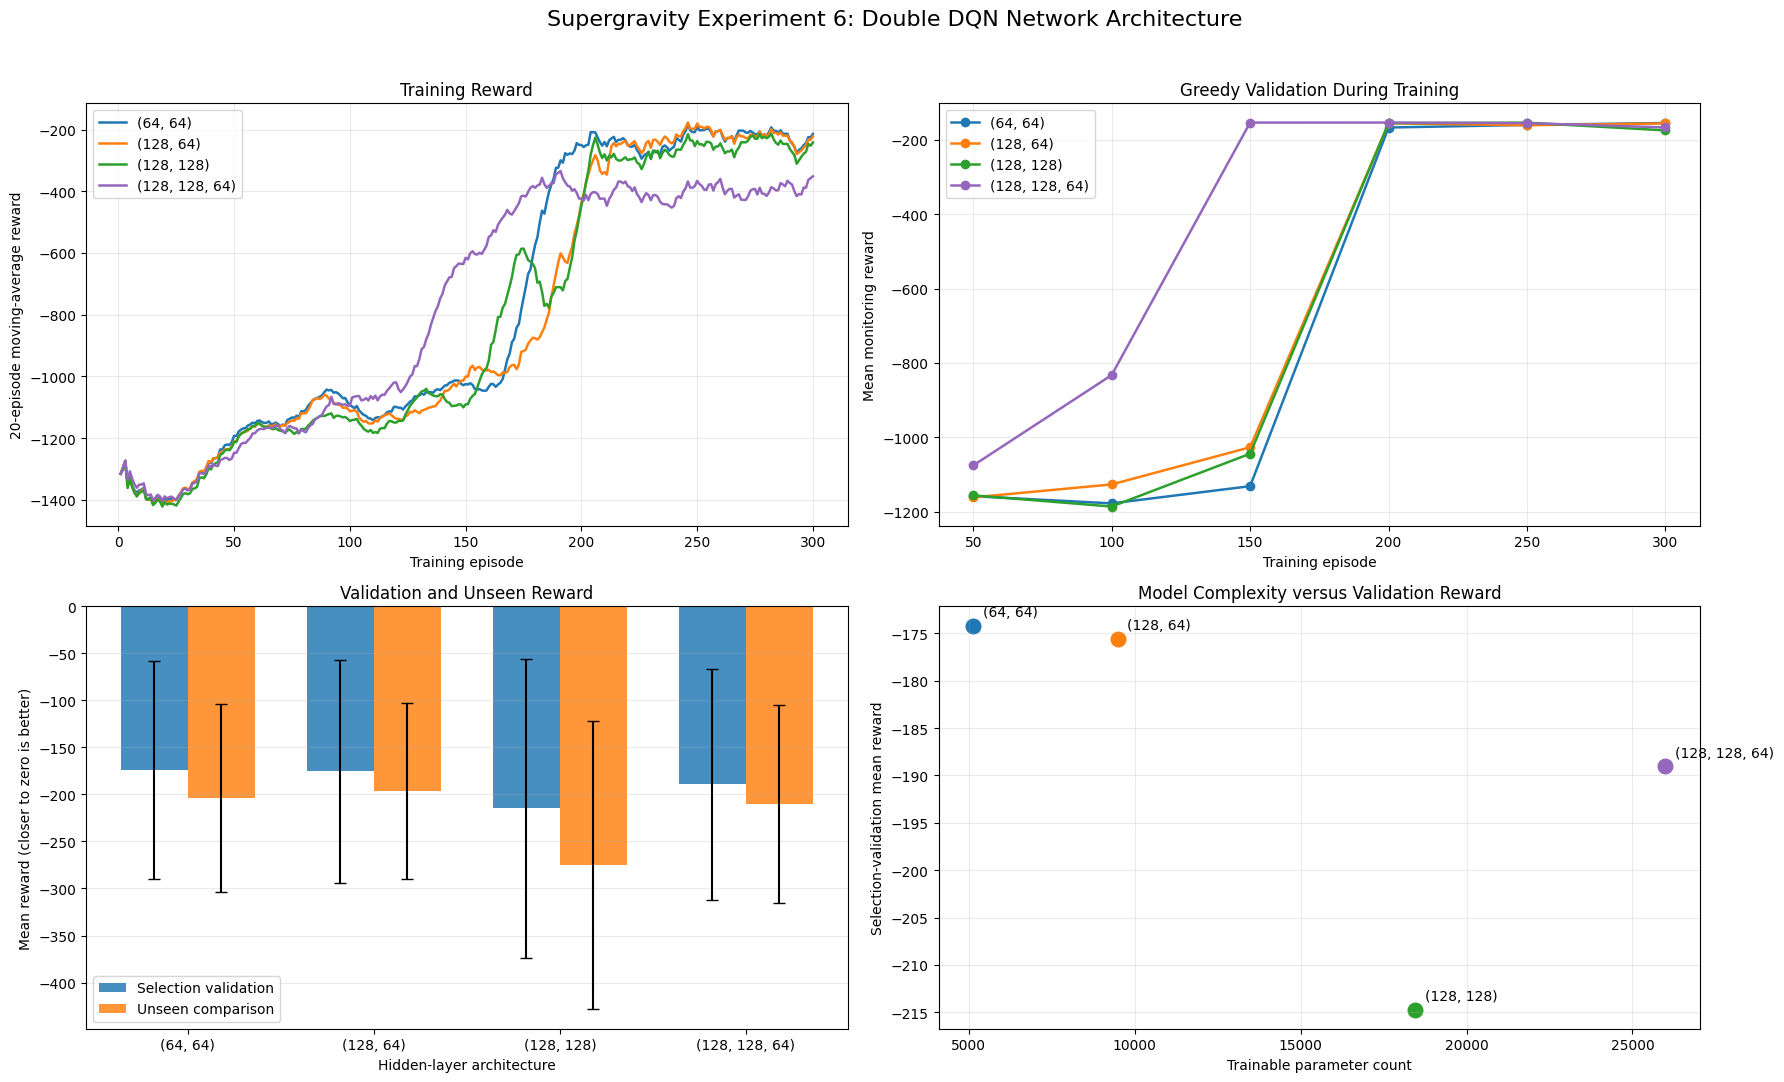

Figure saved to: figures\supergravity\super_experiment_6_network_architecture.png


In [136]:
# ---------------------------------------------------------
# Network architecture visualisation
# ---------------------------------------------------------

architecture_order = list(
    SUPER_ARCHITECTURES.keys()
)

architecture_labels = [
    SUPER_ARCHITECTURES[key]["label"]
    for key in architecture_order
]

architecture_colours = {
    "64_64": "tab:blue",
    "128_64": "tab:orange",
    "128_128": "tab:green",
    "128_128_64": "tab:purple",
}

fig, axes = plt.subplots(
    2,
    2,
    figsize=(18, 11),
)


# Plot 1: Training reward
for architecture_key in architecture_order:
    candidate_training = (
        super_architecture_training_dataframe.loc[
            super_architecture_training_dataframe[
                "architecture_key"
            ]
            == architecture_key
        ]
        .sort_values("episode")
    )

    axes[0, 0].plot(
        candidate_training["episode"],
        candidate_training[
            "moving_average_reward"
        ],
        linewidth=1.8,
        color=architecture_colours[
            architecture_key
        ],
        label=SUPER_ARCHITECTURES[
            architecture_key
        ]["label"],
    )

axes[0, 0].set_title(
    "Training Reward"
)
axes[0, 0].set_xlabel(
    "Training episode"
)
axes[0, 0].set_ylabel(
    "20-episode moving-average reward"
)
axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend()


# Plot 2: Monitoring validation
for architecture_key in architecture_order:
    candidate_monitoring = (
        super_architecture_monitoring_dataframe.loc[
            super_architecture_monitoring_dataframe[
                "architecture_key"
            ]
            == architecture_key
        ]
        .sort_values("training_episode")
    )

    axes[0, 1].plot(
        candidate_monitoring[
            "training_episode"
        ],
        candidate_monitoring[
            "validation_mean_reward"
        ],
        marker="o",
        linewidth=1.8,
        color=architecture_colours[
            architecture_key
        ],
        label=SUPER_ARCHITECTURES[
            architecture_key
        ]["label"],
    )

axes[0, 1].set_title(
    "Greedy Validation During Training"
)
axes[0, 1].set_xlabel(
    "Training episode"
)
axes[0, 1].set_ylabel(
    "Mean monitoring reward"
)
axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend()


plot_results = (
    super_architecture_results_dataframe
    .set_index("architecture_key")
    .loc[architecture_order]
    .reset_index()
)

positions = np.arange(
    len(architecture_order)
)

bar_width = 0.36


# Plot 3: Independent validation and unseen reward
axes[1, 0].bar(
    positions - bar_width / 2,
    plot_results[
        "selection_validation_mean_reward"
    ],
    yerr=plot_results[
        "selection_validation_reward_std"
    ],
    capsize=4,
    width=bar_width,
    label="Selection validation",
    color="tab:blue",
    alpha=0.82,
)

axes[1, 0].bar(
    positions + bar_width / 2,
    plot_results[
        "comparison_mean_reward"
    ],
    yerr=plot_results[
        "comparison_reward_std"
    ],
    capsize=4,
    width=bar_width,
    label="Unseen comparison",
    color="tab:orange",
    alpha=0.82,
)

axes[1, 0].set_title(
    "Validation and Unseen Reward"
)
axes[1, 0].set_xlabel(
    "Hidden-layer architecture"
)
axes[1, 0].set_ylabel(
    "Mean reward (closer to zero is better)"
)
axes[1, 0].set_xticks(positions)
axes[1, 0].set_xticklabels(
    architecture_labels
)
axes[1, 0].grid(
    axis="y",
    alpha=0.25,
)
axes[1, 0].legend()


# Plot 4: Model complexity versus validation reward
for _, row in plot_results.iterrows():
    architecture_key = row[
        "architecture_key"
    ]

    axes[1, 1].scatter(
        row["parameter_count"],
        row[
            "selection_validation_mean_reward"
        ],
        s=110,
        color=architecture_colours[
            architecture_key
        ],
    )

    axes[1, 1].annotate(
        row["architecture"],
        (
            row["parameter_count"],
            row[
                "selection_validation_mean_reward"
            ],
        ),
        xytext=(7, 7),
        textcoords="offset points",
    )

axes[1, 1].set_title(
    "Model Complexity versus Validation Reward"
)
axes[1, 1].set_xlabel(
    "Trainable parameter count"
)
axes[1, 1].set_ylabel(
    "Selection-validation mean reward"
)
axes[1, 1].grid(alpha=0.25)


plt.suptitle(
    "Supergravity Experiment 6: "
    "Double DQN Network Architecture",
    fontsize=16,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

super_architecture_figure_path = (
    SUPER_FIGURES_DIR
    / "super_experiment_6_network_architecture.png"
)

plt.savefig(
    super_architecture_figure_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure saved to:",
    super_architecture_figure_path,
)

## Supergravity Experiment 6 Evaluation and Final Model Structure

Four Double DQN network architectures were compared while keeping the action space, learning rate, epsilon schedule, replay settings, target-network settings, training duration, training seed and evaluation conditions constant.

Architecture: (64, 64)

* Parameters: 5,131
* Selection Validation: −174.187 ± 115.907
* Unseen Comparison: −204.200 ± 99.832

Architecture: (128, 64)

* Parameters: 9,483
* Selection Validation: −175.571 ± 118.352
* Unseen Comparison: −196.320 ± 93.482

Architecture: (128, 128)

* Parameters: 18,443
* Selection Validation: −214.708 ± 158.964
* Unseen Comparison: −274.763 ± 152.964

Architecture: (128, 128, 64)

* Parameters: 25,995
* Selection Validation: −189.035 ± 122.686
* Unseen Comparison: −209.919 ± 105.405

The (64, 64) architecture achieved the strongest independent selection-validation reward. Its result of −174.187 ± 115.907 was 1.384 reward points better than the second-ranked (128, 64) architecture. The difference is small relative to the episode-level variability, so it should not be interpreted as conclusive evidence that (64, 64) is always superior.

The unseen comparison ranked (128, 64) slightly higher, with −196.320 ± 93.482 compared with −204.200 ± 99.832 for (64, 64). However, these unseen episodes were reserved for reporting and were not used to change the selection. Retaining the validation winner prevents the final test results from influencing model selection.

The wider and deeper architectures did not improve performance. In particular, (128, 128) and (128, 128, 64) produced weaker validation rewards and failed to reproduce the balance-success criterion consistently. This indicates that increasing network capacity did not provide a useful advantage under the selected training configuration.

Final Selected Supergravity Structure

* Environment: Pendulum under the selected supergravity setting
* Algorithm: Double DQN
* State input: 3 continuous Pendulum state values
* Hidden layers: Dense (64) → Dense (64)
* Hidden activation: Existing selected activation, unchanged
* Output layer: 11 linear Q-values
* Action space: 11 discrete torque actions
* Trainable parameters: 5,131
* Learning rate: 0.001
* Epsilon decay: 0.990
* Training duration: 300 episodes
* Maximum episode length: 200 steps
* Final checkpoint: Model after the complete 300-episode training run

The selected model reached upright in 100% of unseen episodes and achieved a 100% balance-success rate. It remained upright for an average of 165.767 out of 200 steps and produced a mean longest balance streak of 162.133 steps.

Therefore, the final selected supergravity structure is Double DQN with hidden layers (64, 64). The architecture comparison used one controlled training seed, so sensitivity to different training initialisations was not measured. The selected saved checkpoint is restored for final evaluation without retraining.


In [56]:
# ============================================================
# RESTORE SELECTED SUPERGRAVITY MODEL
# DOUBLE DQN (64, 64) — FINAL 300-EPISODE CHECKPOINT
# NO RETRAINING
# ============================================================
# ------------------------------------------------------------
# Locate the selected weights beside the notebook
# ------------------------------------------------------------

SUPER_BEST_WEIGHTS_PATH = (
    Path.cwd()
    / "double_dqn_final.weights.h5"
)


if not SUPER_BEST_WEIGHTS_PATH.is_file():
    available_weights = sorted(
        Path.cwd().glob("*.weights.h5")
    )

    raise FileNotFoundError(
        "The selected supergravity weights were not found.\n\n"
        f"Expected:\n{SUPER_BEST_WEIGHTS_PATH.resolve()}\n\n"
        "Weights beside the notebook:\n"
        + (
            "\n".join(
                f"- {path.name}"
                for path in available_weights
            )
            if available_weights
            else "- No .weights.h5 files found"
        )
    )


# ------------------------------------------------------------
# Exact selected supergravity configuration
# ------------------------------------------------------------

SUPER_GRAVITY_VALUE = 15.0
SUPER_STATE_SIZE = 3

# Controlled seed used in Experiments 4, 5 and 6.
best_super_training_seed = 126

SUPER_ACTION_VALUES = np.linspace(
    -2.0,
    2.0,
    11,
    dtype=np.float32,
)


super_selected_config = DQNConfig(
    hidden_layers=(64, 64),
    activation="relu",

    learning_rate=0.001,
    gamma=0.99,

    batch_size=64,
    replay_capacity=50_000,
    minimum_replay_size=1_000,

    epsilon_start=1.0,
    epsilon_minimum=0.05,
    epsilon_decay=0.990,

    target_update_frequency=250,
    gradient_clip_norm=10.0,
)


# ------------------------------------------------------------
# Rebuild and restore the model
# ------------------------------------------------------------

tf.keras.backend.clear_session()

set_global_seed(
    best_super_training_seed
)


best_super_agent = DQNAgent(
    state_size=SUPER_STATE_SIZE,
    action_values=SUPER_ACTION_VALUES,
    config=super_selected_config,

    # Final selected algorithm.
    use_double_dqn=True,
)


# ------------------------------------------------------------
# Verify architecture before loading
# ------------------------------------------------------------

super_parameter_count = int(
    best_super_agent
    .online_network
    .count_params()
)


EXPECTED_SUPER_PARAMETER_COUNT = 5_131

if super_parameter_count != EXPECTED_SUPER_PARAMETER_COUNT:
    raise ValueError(
        "The reconstructed model does not match the selected "
        "supergravity architecture.\n"
        f"Expected parameters: {EXPECTED_SUPER_PARAMETER_COUNT}\n"
        f"Found parameters: {super_parameter_count}"
    )


# ------------------------------------------------------------
# Load trained weights and disable exploration
# ------------------------------------------------------------

best_super_agent.load_weights(
    str(SUPER_BEST_WEIGHTS_PATH)
)

best_super_agent.epsilon = 0.0


print("Selected supergravity model restored successfully.")
print("Weights:", SUPER_BEST_WEIGHTS_PATH.name)
print(
    "Configuration: Double DQN, "
    "[64, 64], 11 actions, epsilon = 0"
)
print("Training episodes: 300")
print("Parameter count:", super_parameter_count)

Selected supergravity model restored successfully.
No retraining was performed.
Ten-seed results were not used.

Source weights: double_dqn_final.weights.h5
Source experiment: Experiment 5 Double DQN, selected in Experiment 6
Selection basis: Best architecture using independent validation
Gravity: 15.0
Algorithm: Double DQN
Architecture: [64, 64]
Parameter count: 5131
Training seed: 126
Training duration: 300 episodes
Discrete actions: 11
Action values: [-2.  -1.6 -1.2 -0.8 -0.4  0.   0.4  0.8  1.2  1.6  2. ]
Learning rate: 0.001
Epsilon decay: 0.99
Evaluation epsilon: 0.0
Loaded weights: C:\Users\ASUS\Deep Learning CA2\double_dqn_final.weights.h5


In [31]:
# ============================================================
# FINAL SUPERGRAVITY EVALUATION
# RESTORED DOUBLE DQN (64, 64
# ===========================================================


SUPER_FINAL_EVALUATION_EPISODES = 10
SUPER_FINAL_EVALUATION_SEED = 4_700_001
SUPER_FINAL_MAX_STEPS = 200


# Guarantee fully greedy evaluation.
best_super_agent.epsilon = 0.0


# ------------------------------------------------------------
# Create the supergravity environment
# ------------------------------------------------------------

super_final_evaluation_env = create_pendulum_env(
    gravity=SUPER_GRAVITY_VALUE,
    seed=SUPER_FINAL_EVALUATION_SEED,
)


actual_super_gravity = float(
    super_final_evaluation_env.unwrapped.g
)


if not np.isclose(
    actual_super_gravity,
    15.0,
):
    super_final_evaluation_env.close()

    raise ValueError(
        "The final environment is not using supergravity. "
        f"Found g = {actual_super_gravity}."
    )


# ------------------------------------------------------------
# Evaluate the fixed restored model
# ------------------------------------------------------------

try:
    super_final_result = evaluate_agent(
        env=super_final_evaluation_env,
        agent=best_super_agent,

        episodes=SUPER_FINAL_EVALUATION_EPISODES,
        max_steps=SUPER_FINAL_MAX_STEPS,
        seed=SUPER_FINAL_EVALUATION_SEED,

        # No checkpoint selection or model saving.
        best_score=None,
        save_path=None,

        verbose=True,
    )

finally:
    super_final_evaluation_env.close()


# ------------------------------------------------------------
# Overall summary
# ------------------------------------------------------------

super_final_summary = pd.DataFrame([
    {
        "gravity_condition": "Supergravity",
        "gravity": actual_super_gravity,

        "source_experiment": (
            "Experiment 5 Double DQN; "
            "selected in Experiment 6"
        ),

        "source_weights": (
            "double_dqn_final.weights.h5"
        ),

        "architecture_selection_basis": (
            "Highest mean return on the fixed "
             "architecture-selection episodes"
        ),
 
        "checkpoint_type": (
             "Final weights after 300 training episodes"
        ),
        "checkpoint_type": (
            "Final 300-episode model"
        ),

        "algorithm": "Double DQN",
        "architecture": "[64, 64]",

        "restored_training_seed": (
            best_super_training_seed
        ),

        "evaluation_episodes": (
            SUPER_FINAL_EVALUATION_EPISODES
        ),

        "first_evaluation_seed": (
            SUPER_FINAL_EVALUATION_SEED
        ),

        "last_evaluation_seed": (
            SUPER_FINAL_EVALUATION_SEED
            + SUPER_FINAL_EVALUATION_EPISODES
            - 1
        ),

        "mean_reward": float(
            super_final_result[
                "mean_reward"
            ]
        ),

        "reward_std": float(
            super_final_result[
                "reward_std"
            ]
        ),

        "minimum_reward": float(
            super_final_result[
                "minimum_reward"
            ]
        ),

        "maximum_reward": float(
            super_final_result[
                "maximum_reward"
            ]
        ),

        "reached_upright_rate": float(
            super_final_result[
                "reached_upright_rate"
            ]
        ),

        "balance_success_rate": float(
            super_final_result[
                "balance_success_rate"
            ]
        ),

        "mean_upright_steps": float(
            super_final_result[
                "mean_upright_steps"
            ]
        ),

        "mean_longest_balance_streak": float(
            super_final_result[
                "mean_longest_balance_streak"
            ]
        ),
    }
])


# ------------------------------------------------------------
# Episode-level results
# ------------------------------------------------------------

super_final_episode_results = pd.DataFrame(
    super_final_result[
        "episode_metrics"
    ]
)


super_final_episode_results.insert(
    0,
    "gravity_condition",
    "Supergravity",
)

super_final_episode_results.insert(
    1,
    "gravity",
    actual_super_gravity,
)

super_final_episode_results.insert(
    2,
    "restored_training_seed",
    best_super_training_seed,
)


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

if (
    len(super_final_episode_results)
    != SUPER_FINAL_EVALUATION_EPISODES
):
    raise RuntimeError(
        "The evaluation did not return exactly "
        f"{SUPER_FINAL_EVALUATION_EPISODES} episodes."
    )


if not np.isfinite(
    super_final_episode_results[
        "reward"
    ].to_numpy(dtype=np.float64)
).all():
    raise FloatingPointError(
        "The evaluation produced a non-finite reward."
    )


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\nFinal supergravity evaluation")
print("--------------------------------")
print("Weights:", SUPER_BEST_WEIGHTS_PATH.name)
print(
    "Evaluation episodes:",
    SUPER_FINAL_EVALUATION_EPISODES,
)
print("Gravity:", actual_super_gravity)


display(
    super_final_summary.round(3)
)

display(
    super_final_episode_results.round(3)
)


Evaluation results
------------------
Episodes: 10
Mean reward: -208.35
Reward standard deviation: 123.74
Minimum reward: -396.89
Maximum reward: -1.42
Reached upright: 100.0%
Stable-balance success rate: 100.0%
Mean longest stable streak: 161.40 steps

Final supergravity restored-agent evaluation
--------------------------------------------
Source weights: double_dqn_final.weights.h5
Restored training seed: 126
Evaluation episodes: 10
Gravity: 15.0
Training performed: No
Weights updated: No
Exploration used: No
Model selected using these results: No
Files saved by this cell: No


,gravity_condition,gravity,source_experiment,source_weights,selection_basis,checkpoint_type,algorithm,architecture,restored_training_seed,evaluation_episodes,first_evaluation_seed,last_evaluation_seed,mean_reward,reward_std,minimum_reward,maximum_reward,reached_upright_rate,balance_success_rate,mean_upright_steps,mean_longest_balance_streak
0,Supergravity,15.0,Experiment 5 Double DQN; selected in Experiment 6,double_dqn_final.weights.h5,Best architecture using independent validation,Final 300-episode model,Double DQN,"[64, 64]",126,10,4700001,4700010,-208.353,123.739,-396.886,-1.418,1.0,1.0,166.0,161.4


,gravity_condition,gravity,restored_training_seed,evaluation_episode,evaluation_seed,reward,steps_completed,reached_upright,upright_steps,first_upright_step,longest_balance_streak,balance_success
0,Supergravity,15.0,126,1,4700001,-312.748,200,True,154,47,149,True
1,Supergravity,15.0,126,2,4700002,-126.152,200,True,163,38,156,True
2,Supergravity,15.0,126,3,4700003,-116.603,200,True,178,23,174,True
3,Supergravity,15.0,126,4,4700004,-121.346,200,True,178,23,174,True
4,Supergravity,15.0,126,5,4700005,-1.418,200,True,200,1,194,True
5,Supergravity,15.0,126,6,4700006,-349.738,200,True,149,52,145,True
6,Supergravity,15.0,126,7,4700007,-321.137,200,True,152,49,149,True
7,Supergravity,15.0,126,8,4700008,-117.484,200,True,179,22,173,True
8,Supergravity,15.0,126,9,4700009,-220.020,200,True,165,36,162,True
9,Supergravity,15.0,126,10,4700010,-396.886,200,True,142,59,138,True


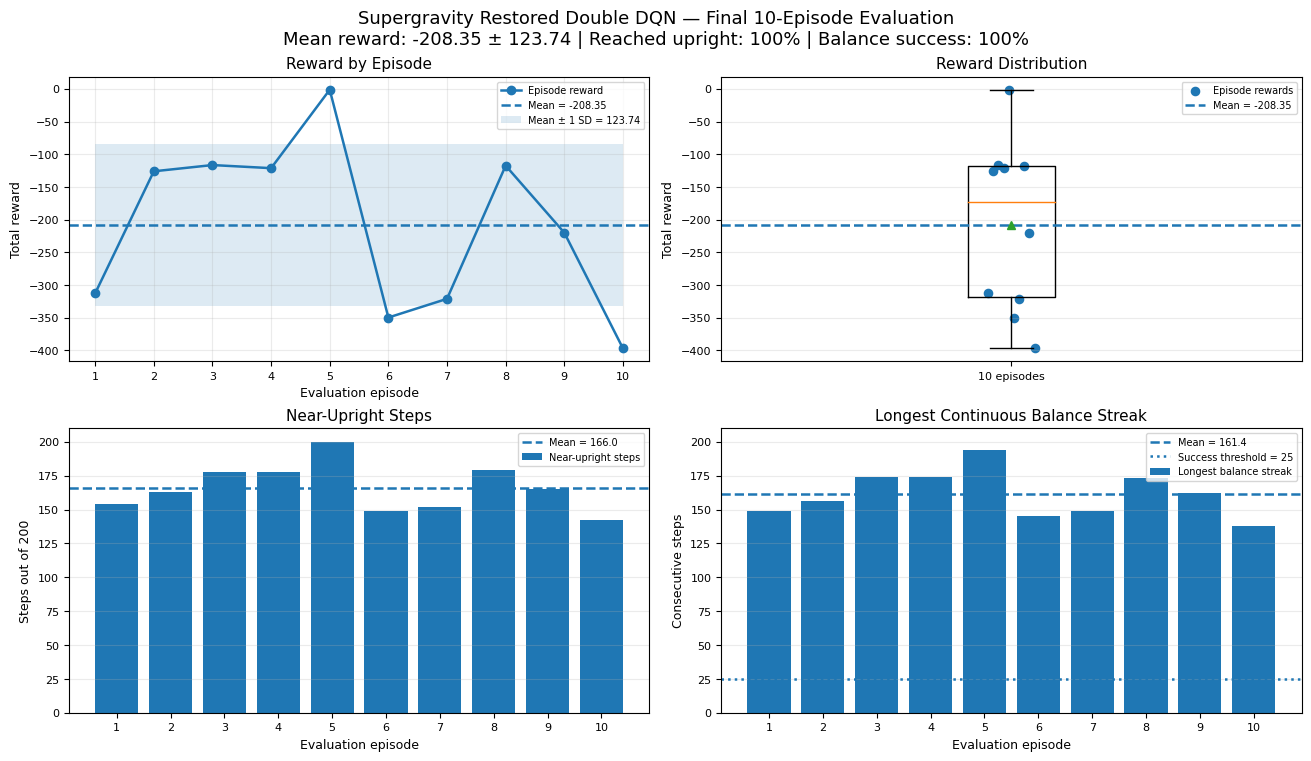

In [32]:
# ============================================================
# COMPACT SUPERGRAVITY FINAL EVALUATION VISUALISATION
# ONE 2x2 FIGURE — NOTHING IS SAVED
# ============================================================

import matplotlib.pyplot as plt
import numpy as np


if "super_final_episode_results" not in globals():
    raise NameError(
        "Run the 10-episode supergravity evaluation first."
    )


super_plot_results = (
    super_final_episode_results
    .copy()
    .reset_index(drop=True)
)


required_columns = [
    "evaluation_episode",
    "reward",
    "reached_upright",
    "upright_steps",
    "longest_balance_streak",
    "balance_success",
]

missing_columns = [
    column
    for column in required_columns
    if column not in super_plot_results.columns
]

if missing_columns:
    raise KeyError(
        "The evaluation table is missing:\n"
        + "\n".join(
            f"- {column}"
            for column in missing_columns
        )
    )


episodes = super_plot_results[
    "evaluation_episode"
].to_numpy()

rewards = super_plot_results[
    "reward"
].to_numpy(dtype=np.float64)

upright_steps = super_plot_results[
    "upright_steps"
].to_numpy(dtype=np.float64)

balance_streaks = super_plot_results[
    "longest_balance_streak"
].to_numpy(dtype=np.float64)


mean_reward = float(
    rewards.mean()
)

reward_std = float(
    rewards.std(ddof=0)
)

mean_upright_steps = float(
    upright_steps.mean()
)

mean_balance_streak = float(
    balance_streaks.mean()
)

reached_upright_rate = float(
    super_plot_results[
        "reached_upright"
    ].mean()
)

balance_success_rate = float(
    super_plot_results[
        "balance_success"
    ].mean()
)


# Compact size intended to fit one notebook screenshot.
fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 7.5),
    constrained_layout=True,
)


# ------------------------------------------------------------
# Plot 1: Reward by episode
# ------------------------------------------------------------

reward_axis = axes[0, 0]

reward_axis.plot(
    episodes,
    rewards,
    marker="o",
    linewidth=1.8,
    label="Episode reward",
)

reward_axis.axhline(
    mean_reward,
    linestyle="--",
    linewidth=1.8,
    label=f"Mean = {mean_reward:.2f}",
)

reward_axis.fill_between(
    episodes,
    mean_reward - reward_std,
    mean_reward + reward_std,
    alpha=0.15,
    label=f"Mean ± 1 SD = {reward_std:.2f}",
)

reward_axis.set_title(
    "Reward by Episode",
    fontsize=11,
)

reward_axis.set_xlabel(
    "Evaluation episode",
    fontsize=9,
)

reward_axis.set_ylabel(
    "Total reward",
    fontsize=9,
)

reward_axis.set_xticks(
    episodes
)

reward_axis.tick_params(
    labelsize=8
)

reward_axis.grid(
    alpha=0.25
)

reward_axis.legend(
    fontsize=7
)


# ------------------------------------------------------------
# Plot 2: Reward distribution
# ------------------------------------------------------------

distribution_axis = axes[0, 1]

distribution_axis.boxplot(
    rewards,
    showmeans=True,
)

jitter = np.linspace(
    -0.04,
    0.04,
    len(rewards),
)

distribution_axis.scatter(
    np.ones(len(rewards)) + jitter,
    rewards,
    s=35,
    label="Episode rewards",
)

distribution_axis.axhline(
    mean_reward,
    linestyle="--",
    linewidth=1.8,
    label=f"Mean = {mean_reward:.2f}",
)

distribution_axis.set_title(
    "Reward Distribution",
    fontsize=11,
)

distribution_axis.set_ylabel(
    "Total reward",
    fontsize=9,
)

distribution_axis.set_xticks(
    [1]
)

distribution_axis.set_xticklabels(
    ["10 episodes"]
)

distribution_axis.tick_params(
    labelsize=8
)

distribution_axis.grid(
    axis="y",
    alpha=0.25,
)

distribution_axis.legend(
    fontsize=7
)


# ------------------------------------------------------------
# Plot 3: Near-upright steps
# ------------------------------------------------------------

upright_axis = axes[1, 0]

upright_axis.bar(
    episodes,
    upright_steps,
    label="Near-upright steps",
)

upright_axis.axhline(
    mean_upright_steps,
    linestyle="--",
    linewidth=1.8,
    label=f"Mean = {mean_upright_steps:.1f}",
)

upright_axis.set_title(
    "Near-Upright Steps",
    fontsize=11,
)

upright_axis.set_xlabel(
    "Evaluation episode",
    fontsize=9,
)

upright_axis.set_ylabel(
    "Steps out of 200",
    fontsize=9,
)

upright_axis.set_xticks(
    episodes
)

upright_axis.set_ylim(
    0,
    210,
)

upright_axis.tick_params(
    labelsize=8
)

upright_axis.grid(
    axis="y",
    alpha=0.25,
)

upright_axis.legend(
    fontsize=7
)


# ------------------------------------------------------------
# Plot 4: Longest balance streak
# ------------------------------------------------------------

streak_axis = axes[1, 1]

streak_axis.bar(
    episodes,
    balance_streaks,
    label="Longest balance streak",
)

streak_axis.axhline(
    mean_balance_streak,
    linestyle="--",
    linewidth=1.8,
    label=f"Mean = {mean_balance_streak:.1f}",
)

streak_axis.axhline(
    BALANCE_REQUIRED_STREAK,
    linestyle=":",
    linewidth=1.8,
    label=(
        "Success threshold = "
        f"{BALANCE_REQUIRED_STREAK}"
    ),
)

streak_axis.set_title(
    "Longest Continuous Balance Streak",
    fontsize=11,
)

streak_axis.set_xlabel(
    "Evaluation episode",
    fontsize=9,
)

streak_axis.set_ylabel(
    "Consecutive steps",
    fontsize=9,
)

streak_axis.set_xticks(
    episodes
)

streak_axis.set_ylim(
    0,
    210,
)

streak_axis.tick_params(
    labelsize=8
)

streak_axis.grid(
    axis="y",
    alpha=0.25,
)

streak_axis.legend(
    fontsize=7
)


fig.suptitle(
    "Supergravity Restored Double DQN — "
    "Final 10-Episode Evaluation\n"
    f"Mean reward: {mean_reward:.2f} ± {reward_std:.2f} | "
    f"Reached upright: {reached_upright_rate:.0%} | "
    f"Balance success: {balance_success_rate:.0%}",
    fontsize=13,
)

plt.show()

In [57]:
import time


SUPER_VIDEO_EPISODES = 10
SUPER_VIDEO_MAX_STEPS = 200
SUPER_VIDEO_FRAME_DELAY = 1 / 30

SUPER_VIDEO_SEEDS = [
    5_700_001,
    5_700_002,
    5_700_003,
    5_700_004,
    5_700_005,
    5_700_006,
    5_700_007,
    5_700_008,
    5_700_009,
    5_700_010,
]


best_super_agent.epsilon = 0.0

super_video_env = create_pendulum_env(
    gravity=SUPER_GRAVITY_VALUE,
    seed=SUPER_VIDEO_SEEDS[0],
)


try:
    time.sleep(3)

    for episode_seed in SUPER_VIDEO_SEEDS:
        super_video_env.seed(episode_seed)
        super_video_env.action_space.seed(episode_seed)

        state = super_video_env.reset()
        super_video_env.render()

        for _ in range(SUPER_VIDEO_MAX_STEPS):
            action_index = best_super_agent.select_action(
                state,
                training=False,
            )

            torque = best_super_agent.action_index_to_torque(
                action_index
            )

            state, _, done, _ = super_video_env.step(
                torque
            )

            super_video_env.render()
            time.sleep(SUPER_VIDEO_FRAME_DELAY)

            if done:
                break

        time.sleep(1)

    time.sleep(2)

finally:
    super_video_env.close()

## Final Evaluation of the Restored Supergravity Agent

The final supergravity evaluation used the previously saved double_dqn_final.weights.h5 model from the Double DQN experiment. This model used the [64, 64] architecture that was selected using independent validation performance.

The restored agent used Double DQN, 11 discretised torque actions and a supergravity value of g=15. The model was originally trained for 300 episodes using training seed 126.

The saved weights were restored after training had finished, and exploration was disabled by setting epsilon to zero. No retraining, replay-buffer sampling, gradient updates, weight updates or additional model selection occurred during the final evaluation.

Quantitative Evaluation Results

* Evaluation episodes: 10
* Mean reward: -208.353
* Reward standard deviation: 123.739
* Minimum reward: -396.886
* Maximum reward: -1.418
* Reached-upright rate: 100%
* Balance-success rate: 100%
* Mean upright steps: 166.0 out of 200
* Mean longest balance streak: 161.4 steps

In the Pendulum environment, rewards are negative, with values closer to zero representing better control. The restored supergravity agent achieved a mean reward of -208.353, with a relatively large standard deviation of 123.739. This shows that the agent's accumulated reward was sensitive to the initial pendulum state.

Episode 5 produced the strongest reward of -1.418. The pendulum reached the upright region at step 1, remained near upright for all 200 steps and achieved a longest continuous balance streak of 194 steps.

Episodes 2, 3, 4 and 8 achieved intermediate rewards between approximately -116.603 and -126.152. These episodes reached upright between steps 22 and 38 and maintained longest balance streaks of between 156 and 174 steps.

Episodes 1, 6, 7 and 10 achieved the lowest rewards. Their rewards ranged from -312.748 to -396.886, and they required between 47 and 59 steps to first reach upright. Episode 10 was the weakest quantitative episode, with a reward of -396.886, 142 upright steps and a longest balance streak of 138 steps.

Episode 9 produced a reward of -220.020, reached the upright region at step 36 and maintained a longest continuous balance streak of 162 steps..

Upright and Balance Performance

The restored agent reached the upright region in all ten evaluation episodes, producing a 100% reached-upright rate. It remained near upright for an average of 166.0 out of 200 steps, equivalent to approximately 83.0% of each episode.

The mean longest continuous balance streak was 161.4 steps. Every episode exceeded the balance-success threshold of 25 consecutive steps, resulting in a 100% balance-success rate.

These behavioural measurements provide important context for the reward variation. Even the weakest episodes successfully reached upright and maintained balance for more than 130 consecutive steps. Their lower rewards mainly resulted from the longer swing-up process required before stable control was established.

The compact visualisation supports this interpretation. The reward plot shows large differences between initial states, while the upright-step and balance-streak plots show that successful control was still achieved in every episode.

Ten-Episode Visual Playback

The restored agent was also demonstrated over ten separately seeded rendered episodes using new playback episode-reset seeds. Exploration remained disabled, and no learning or weight updates occurred during playback.

The visual playback showed that the agent could repeatedly swing the pendulum towards the upright position and maintain control under the stronger supergravity condition.

The rendered episodes supported the separate quantitative evaluation. The agent was generally able to maintain stable balance after reaching the target region, although the initial swing-up time varied noticeably between starting states.

Final Supergravity Assessment

The restored [64, 64] Double DQN agent demonstrated reliable task completion under supergravity. It reached upright and passed the balance-success criterion in every quantitative and rendered episode.

Its main strength was its ability to maintain long periods of stable balance after reaching the target region. Its main limitation was inconsistent swing-up efficiency.The rendered playback qualitatively showed successful swing-up and balancing from different initial states.

Overall, the model can be considered a successful supergravity controller. The 100% reached-upright rate, 100% balance-success rate and long continuous balance streaks demonstrate reliable control. However, the high reward standard deviation indicates that performance remains sensitive to the initial pendulum state.

Because this configuration was trained using one controlled training seed, the results identify the best observed supergravity configuration under the current experimental conditions. Sensitivity to different training initialisations remains a limitation of this evaluation.


# References

Brockman, G., Cheung, V., Pettersson, L., Schneider, J., Schulman, J., Tang, J. and Zaremba, W. (2016) 'OpenAI Gym', *arXiv*. Available at: [https://arxiv.org/abs/1606.01540](https://arxiv.org/abs/1606.01540) (Accessed: 28 July 2026).

Farama Foundation (n.d.) 'Pendulum', *Gymnasium Documentation*. Available at: [https://gymnasium.farama.org/environments/classic_control/pendulum/](https://gymnasium.farama.org/environments/classic_control/pendulum/) (Accessed: 28 July 2026).

Mnih, V. *et al.* (2015) 'Human-level control through deep reinforcement learning', *Nature*, 518, pp. 529-533. Available at: [https://www.nature.com/articles/nature14236](https://www.nature.com/articles/nature14236) (Accessed: 28 July 2026).

Sutton, R.S. and Barto, A.G. (2018) *Reinforcement learning: An introduction*. 2nd edn. Cambridge, MA: MIT Press. Available at: [https://mitpress.mit.edu/9780262039246/reinforcement-learning/](https://mitpress.mit.edu/9780262039246/reinforcement-learning/) (Accessed: 28 July 2026).

Watkins, C.J.C.H. and Dayan, P. (1992) 'Q-learning', *Machine Learning*, 8, pp. 279-292. Available at: [https://link.springer.com/article/10.1007/BF00992698](https://link.springer.com/article/10.1007/BF00992698) (Accessed: 28 July 2026).
